In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
print("Drive mounted.")

Mounted at /content/drive
Drive mounted.


In [2]:
import os, zipfile, shutil
from google.colab import files

print("Upload your stage3_local.zip file:")
uploaded = files.upload()

ZIP_NAME = list(uploaded.keys())[0]
EXTRACT_TO = "/content"

print(f"\nExtracting {ZIP_NAME} to {EXTRACT_TO}...")
with zipfile.ZipFile(ZIP_NAME, "r") as z:
    z.extractall(EXTRACT_TO)


STAGE3_LOCAL = "/content/stage3_local"
if os.path.exists(STAGE3_LOCAL):
    print(f"stage3_local found at: {STAGE3_LOCAL}")
    for root, dirs, files_list in os.walk(STAGE3_LOCAL):
        level = root.replace(STAGE3_LOCAL, "").count(os.sep)
        if level < 2:
            indent = "  " * level
            print(f"{indent}{os.path.basename(root)}/")
            if level < 1:
                subindent = "  " * (level + 1)
                for f in files_list[:5]:
                    print(f"{subindent}{f}")
else:
    raise RuntimeError("stage3_local not found after extraction. Check zip structure.")

Upload your stage3_local.zip file:


Saving stage3_local.zip to stage3_local.zip

Extracting stage3_local.zip to /content...
stage3_local found at: /content/stage3_local
stage3_local/
  dr2015_structured/
  weights/
  results/


In [3]:
import os, glob
import pandas as pd


STAGE3_LOCAL = "/content/stage3_local"
DR_OUT_DIR   = STAGE3_LOCAL

REQUIRED_STAGE3_COLUMNS = {"img_path", "label", "stage3_mask_path"}

csv_candidates = [
    c for c in glob.glob(os.path.join(STAGE3_LOCAL, "**", "*.csv"), recursive=True)
    if "results" not in c.lower()
]

print("CSV files found:")
for c in csv_candidates:
    print(f"  {c}")

stage3_csv = None

for c in csv_candidates:
    try:
        columns = set(pd.read_csv(c, nrows=0).columns)
    except Exception:
        continue

    if REQUIRED_STAGE3_COLUMNS.issubset(columns):
        stage3_csv = c
        break

if stage3_csv is None:
    raise RuntimeError(
        "No CSV with img_path, label, and stage3_mask_path was found in stage3_local."
    )

df = pd.read_csv(stage3_csv)

print(f"\nLoaded Stage 3 CSV: {stage3_csv}")
print(f"Rows: {len(df)}")
print(f"Columns: {list(df.columns)}")

print(
    df[
        ["img_path", "label", "stage3_mask_path"]
    ].head(3)
)

CSV files found:
  /content/stage3_local/dr2015_structured/dr2015_linked_stage1_stage2_stage3.csv
  /content/stage3_local/dr2015_structured/stage2_masks/stage2_mask_paths.csv
  /content/stage3_local/dr2015_structured/stage3_masks/stage3_mask_paths.csv

Loaded Stage 3 CSV: /content/stage3_local/dr2015_structured/dr2015_linked_stage1_stage2_stage3.csv
Rows: 35126
Columns: ['img_path', 'label', 'stage2_mask_path', 'stage3_mask_path']
                                            img_path  label  \
0  /content/drive/MyDrive/Dataset_extracted/color...      1   
1  /content/drive/MyDrive/Dataset_extracted/color...      1   
2  /content/drive/MyDrive/Dataset_extracted/color...      1   

                                    stage3_mask_path  
0  /content/stage3_local/dr2015_structured/stage3...  
1  /content/stage3_local/dr2015_structured/stage3...  
2  /content/stage3_local/dr2015_structured/stage3...  


In [4]:
import os
import gc
import copy
import shutil
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import timm
import matplotlib.pyplot as plt

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

AMP_DEVICE = (
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Seed fixed: {SEED}")


STAGE3_SIZE = 384
STAGE3_BATCH = 64
STAGE3_NUM_WORKERS = 8

PIN_MEMORY = torch.cuda.is_available()

STAGE3_LOCAL = "/content/stage3_local"

RESULTS_DIR = os.path.join(
    STAGE3_LOCAL,
    "results"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

CLASS_NAMES = [
    "no_dr",
    "mild",
    "moderate",
    "severe",
    "proliferative_dr"
]

num_classes = len(CLASS_NAMES)

print(f"Results dir       : {RESULTS_DIR}")
print(f"Classes           : {CLASS_NAMES}")
print(f"Image size        : {STAGE3_SIZE}")

Device: cuda
Seed fixed: 42
Results dir       : /content/stage3_local/results
Classes           : ['no_dr', 'mild', 'moderate', 'severe', 'proliferative_dr']
Image size        : 384


In [5]:
pth_files = []
for root, dirs, files in os.walk("/content"):
    for f in files:
        if f.endswith(".pth"):
            pth_files.append(os.path.join(root, f))

print("Found .pth files:")
for i, p in enumerate(pth_files):
    print(f"  {i}: {p}")

if len(pth_files) == 0:
    print("No .pth files found.")

Found .pth files:
  0: /content/stage3_local/weights/stage3_discriminator_best.pth
  1: /content/stage3_local/weights/stage3_generator_best.pth
  2: /content/drive/MyDrive/DR_Project/RVS_normal_split_separate/attention_unet_best.pth
  3: /content/drive/MyDrive/DR_Project/RVS_normal_split_separate/recursive_refinement_results/recursive_refinement_best.pth
  4: /content/drive/MyDrive/DR_Project/stage1/weights/stage1_original_fixed_best_dr_b0.pth
  5: /content/drive/MyDrive/DR_Project/stage2/weights/stage2_attunet_best.pth
  6: /content/drive/MyDrive/DR_Project/stage2/augmented_validation_experiment/stage2_paired_aug_finetuned_best.pth
  7: /content/drive/MyDrive/DR_Project/stage2/resfpn_gan_weights/resfpn_discriminator_best.pth
  8: /content/drive/MyDrive/DR_Project/stage2/resfpn_gan_weights/resfpn_generator_best.pth
  9: /content/drive/MyDrive/DR_Project/stage2/hrmsa_gan_weights/hrmsa_generator_best.pth
  10: /content/drive/MyDrive/DR_Project/stage2/hrmsa_gan_weights/hrmsa_discriminator

In [6]:
STAGE1_W = "/content/drive/MyDrive/DR_Project/stage1/weights/stage1_original_fixed_best_dr_b0.pth"



stage1 = timm.create_model(
    "tf_efficientnet_b0.ns_jft_in1k",
    pretrained=False,
    num_classes=num_classes
)

stage1.load_state_dict(torch.load(STAGE1_W, map_location=device))
stage1 = stage1.to(device)
stage1.eval()

for p in stage1.parameters():
    p.requires_grad = False

print("Stage1 loaded")

Stage1 loaded


In [9]:
import os
import shutil
import time

from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm


DRIVE_IMAGE_ROOT = (
    "/content/drive/MyDrive/"
    "Dataset/colored_images/colored_images"
)

LOCAL_IMAGE_ROOT = "/content/dr_images"

COPY_COMPLETE_FILE = "/content/.dr_images_copy_complete"

MAX_WORKERS = 8
MAX_RETRIES = 5


os.makedirs(
    LOCAL_IMAGE_ROOT,
    exist_ok=True
)


if not os.path.exists(DRIVE_IMAGE_ROOT):
    raise RuntimeError(
        f"Google Drive folder not found:\n{DRIVE_IMAGE_ROOT}"
    )


print("Scanning files...")


all_files = []

for root, dirs, filenames in os.walk(
    DRIVE_IMAGE_ROOT
):

    for filename in filenames:

        src = os.path.join(
            root,
            filename
        )

        relative_path = os.path.relpath(
            src,
            DRIVE_IMAGE_ROOT
        )

        dst = os.path.join(
            LOCAL_IMAGE_ROOT,
            relative_path
        )

        all_files.append(
            (src, dst)
        )


print(
    f"Total files: {len(all_files):,}"
)


remaining_files = []


for src, dst in tqdm(
    all_files,
    desc="Checking existing files",
    unit="file"
):

    try:

        if os.path.exists(dst):

            src_size = os.path.getsize(src)
            dst_size = os.path.getsize(dst)

            if src_size == dst_size:
                continue

            os.remove(dst)

        remaining_files.append(
            (src, dst)
        )

    except Exception:

        remaining_files.append(
            (src, dst)
        )


already_complete = (
    len(all_files)
    -
    len(remaining_files)
)


print(
    f"\nAlready copied correctly: {already_complete:,}"
)

print(
    f"Remaining to copy: {len(remaining_files):,}"
)


def copy_with_retry(item):

    src, dst = item

    os.makedirs(
        os.path.dirname(dst),
        exist_ok=True
    )

    last_error = None


    for attempt in range(
        1,
        MAX_RETRIES + 1
    ):

        try:

            if os.path.exists(dst):

                try:

                    if (
                        os.path.getsize(src)
                        ==
                        os.path.getsize(dst)
                    ):
                        return True, src, None

                except Exception:
                    pass


                try:
                    os.remove(dst)
                except Exception:
                    pass


            shutil.copyfile(
                src,
                dst
            )


            if (
                os.path.getsize(src)
                !=
                os.path.getsize(dst)
            ):

                raise IOError(
                    "Copied file size does not match source."
                )


            return True, src, None


        except Exception as e:

            last_error = e


            try:
                if os.path.exists(dst):
                    os.remove(dst)
            except Exception:
                pass


            time.sleep(
                min(
                    attempt * 2,
                    10
                )
            )


    return (
        False,
        src,
        str(last_error)
    )


errors = []


with ThreadPoolExecutor(
    max_workers=MAX_WORKERS
) as executor:

    futures = [
        executor.submit(
            copy_with_retry,
            item
        )
        for item in remaining_files
    ]


    for future in tqdm(
        as_completed(futures),
        total=len(futures),
        desc="Copying DR images",
        unit="file"
    ):

        success, src, error = (
            future.result()
        )


        if not success:

            errors.append(
                {
                    "file": src,
                    "error": error
                }
            )


print("\n" + "=" * 70)
print("COPY CHECK")
print("=" * 70)


if errors:

    print(
        f"Files still failed after retries: "
        f"{len(errors):,}"
    )

    print("\nFirst few failed files:")

    for item in errors[:10]:

        print(
            item["file"]
        )

        print(
            item["error"]
        )

    print(
        "\nRun this same cell again. "
        "It will skip all successfully copied files "
        "and retry only the remaining files."
    )

else:

    with open(
        COPY_COMPLETE_FILE,
        "w"
    ) as f:

        f.write("complete")


    print(
        "All DR images copied successfully."
    )

    print(
        "Local folder:",
        LOCAL_IMAGE_ROOT
    )

Scanning files...
Total files: 35,126


Checking existing files:   0%|          | 0/35126 [00:00<?, ?file/s]


Already copied correctly: 0
Remaining to copy: 35,126


Copying DR images:   0%|          | 0/35126 [00:00<?, ?file/s]


COPY CHECK
All DR images copied successfully.
Local folder: /content/dr_images


In [10]:
gc.collect()
torch.cuda.empty_cache()

In [11]:
import os
import glob
import pandas as pd

STAGE3_LOCAL = "/content/stage3_local"

REQUIRED_STAGE3_COLUMNS = {
    "img_path",
    "label",
    "stage3_mask_path"
}

csv_candidates = glob.glob(
    os.path.join(
        STAGE3_LOCAL,
        "**",
        "*.csv"
    ),
    recursive=True
)

stage3_csv = None

for c in csv_candidates:

    try:
        columns = set(
            pd.read_csv(
                c,
                nrows=0
            ).columns
        )
    except Exception:
        continue

    if REQUIRED_STAGE3_COLUMNS.issubset(columns):
        stage3_csv = c
        break


if stage3_csv is None:
    raise RuntimeError(
        "Stage3 CSV not found inside /content/stage3_local"
    )


df_stage3 = pd.read_csv(
    stage3_csv
)


DRIVE_IMAGE_ROOT = (
    "/content/drive/MyDrive/"
    "Dataset_extracted/colored_images/colored_images"
)

LOCAL_IMAGE_ROOT = "/content/dr_images"


def convert_image_path_to_local(path):

    path = str(path).strip()

    if path.startswith(DRIVE_IMAGE_ROOT):

        relative_path = os.path.relpath(
            path,
            DRIVE_IMAGE_ROOT
        )

        return os.path.join(
            LOCAL_IMAGE_ROOT,
            relative_path
        )

    return path


df_stage3["img_path"] = (
    df_stage3["img_path"]
    .apply(convert_image_path_to_local)
)


df_stage3["stage3_mask_path"] = (
    df_stage3["stage3_mask_path"]
    .fillna("")
    .astype(str)
    .str.strip()
)


df_stage3 = df_stage3[
    df_stage3["img_path"].apply(os.path.exists)
    &
    df_stage3["stage3_mask_path"].apply(os.path.exists)
].copy()


df_stage3["label"] = (
    df_stage3["label"]
    .astype(int)
)


df_stage3["basename"] = (
    df_stage3["img_path"]
    .apply(
        lambda p: os.path.basename(str(p))
    )
)


df_stage3 = df_stage3.reset_index(
    drop=True
)


print("Rows:", len(df_stage3))
print(df_stage3.head())

Rows: 35126
                                  img_path  label  \
0  /content/dr_images/Mild/34350_right.png      1   
1  /content/dr_images/Mild/34364_right.png      1   
2   /content/dr_images/Mild/34368_left.png      1   
3   /content/dr_images/Mild/34382_left.png      1   
4   /content/dr_images/Mild/34405_left.png      1   

                                    stage2_mask_path  \
0  /content/stage3_local/dr2015_structured/stage2...   
1  /content/stage3_local/dr2015_structured/stage2...   
2  /content/stage3_local/dr2015_structured/stage2...   
3  /content/stage3_local/dr2015_structured/stage2...   
4  /content/stage3_local/dr2015_structured/stage2...   

                                    stage3_mask_path         basename  
0  /content/stage3_local/dr2015_structured/stage3...  34350_right.png  
1  /content/stage3_local/dr2015_structured/stage3...  34364_right.png  
2  /content/stage3_local/dr2015_structured/stage3...   34368_left.png  
3  /content/stage3_local/dr2015_structured/s

In [12]:
SPLIT_DIR = "/content/drive/MyDrive/DR_Project/splits"

def load_names(filename):
    path = os.path.join(
        SPLIT_DIR,
        filename
    )

    if not os.path.exists(path):
        raise FileNotFoundError(path)

    with open(path, "r") as f:
        return set(
            line.strip()
            for line in f
            if line.strip()
        )

stage1_train_names = load_names(
    "stage1_train_names.txt"
)

stage1_val_names = load_names(
    "stage1_val_names.txt"
)

stage1_test_names = load_names(
    "stage1_test_names.txt"
)

df_stage3["basename"] = (
    df_stage3["img_path"]
    .apply(
        lambda p: os.path.basename(str(p))
    )
)

available_names = set(
    df_stage3["basename"].astype(str)
)

missing_train = (
    stage1_train_names
    -
    available_names
)

missing_val = (
    stage1_val_names
    -
    available_names
)

missing_test = (
    stage1_test_names
    -
    available_names
)

if missing_train:
    raise RuntimeError(
        f"{len(missing_train)} Stage1 train images "
        "are missing from Stage3 data."
    )

if missing_val:
    raise RuntimeError(
        f"{len(missing_val)} Stage1 validation images "
        "are missing from Stage3 data."
    )

if missing_test:
    raise RuntimeError(
        f"{len(missing_test)} Stage1 test images "
        "are missing from Stage3 data."
    )

if stage1_train_names & stage1_val_names:
    raise RuntimeError(
        "Stage1 train and validation overlap."
    )

if stage1_train_names & stage1_test_names:
    raise RuntimeError(
        "Stage1 train and test overlap."
    )

if stage1_val_names & stage1_test_names:
    raise RuntimeError(
        "Stage1 validation and test overlap."
    )

train_df = (
    df_stage3[
        df_stage3["basename"].isin(
            stage1_train_names
        )
    ]
    .copy()
    .reset_index(drop=True)
)

val_df = (
    df_stage3[
        df_stage3["basename"].isin(
            stage1_val_names
        )
    ]
    .copy()
    .reset_index(drop=True)
)

test_df = (
    df_stage3[
        df_stage3["basename"].isin(
            stage1_test_names
        )
    ]
    .copy()
    .reset_index(drop=True)
)

train_names = set(
    train_df["basename"].astype(str)
)

val_names = set(
    val_df["basename"].astype(str)
)

test_names = set(
    test_df["basename"].astype(str)
)

if train_names != stage1_train_names:
    raise RuntimeError(
        "Stage3 train images do not exactly "
        "match Stage1 train images."
    )

if val_names != stage1_val_names:
    raise RuntimeError(
        "Stage3 validation images do not exactly "
        "match Stage1 validation images."
    )

if test_names != stage1_test_names:
    raise RuntimeError(
        "Stage3 test images do not exactly "
        "match Stage1 test images."
    )

assigned_names = (
    train_names
    |
    val_names
    |
    test_names
)

if assigned_names != available_names:
    raise RuntimeError(
        "Stage1 split files do not exactly cover "
        "the available Stage3 dataset."
    )

print("=" * 70)
print("STAGE1 / STAGE3 IDENTICAL SPLIT")
print("=" * 70)

print(
    "Total dataset :",
    len(df_stage3)
)

print(
    "Train         :",
    len(train_df)
)

print(
    "Validation    :",
    len(val_df)
)

print(
    "Test          :",
    len(test_df)
)

print()
print(
    "Train-Val overlap :",
    len(train_names & val_names)
)

print(
    "Train-Test overlap:",
    len(train_names & test_names)
)

print(
    "Val-Test overlap  :",
    len(val_names & test_names)
)

print()
print(
    "Same Stage1/Stage3 train:",
    train_names == stage1_train_names
)

print(
    "Same Stage1/Stage3 val  :",
    val_names == stage1_val_names
)

print(
    "Same Stage1/Stage3 test :",
    test_names == stage1_test_names
)

print()
print("Train class counts:")

train_counts = (
    train_df["label"]
    .value_counts()
    .sort_index()
)

for i, class_name in enumerate(
    CLASS_NAMES
):
    print(
        f"{class_name:<22}: "
        f"{int(train_counts.get(i, 0)):>5}"
    )

print()
print("Validation class counts:")

val_counts = (
    val_df["label"]
    .value_counts()
    .sort_index()
)

for i, class_name in enumerate(
    CLASS_NAMES
):
    print(
        f"{class_name:<22}: "
        f"{int(val_counts.get(i, 0)):>5}"
    )

print()
print("Test class counts:")

test_counts = (
    test_df["label"]
    .value_counts()
    .sort_index()
)

for i, class_name in enumerate(
    CLASS_NAMES
):
    print(
        f"{class_name:<22}: "
        f"{int(test_counts.get(i, 0)):>5}"
    )

STAGE1 / STAGE3 IDENTICAL SPLIT
Total dataset : 35126
Train         : 24588
Validation    : 5269
Test          : 5269

Train-Val overlap : 0
Train-Test overlap: 0
Val-Test overlap  : 0

Same Stage1/Stage3 train: True
Same Stage1/Stage3 val  : True
Same Stage1/Stage3 test : True

Train class counts:
no_dr                 : 18067
mild                  :  1710
moderate              :  3704
severe                :   611
proliferative_dr      :   496

Validation class counts:
no_dr                 :  3871
mild                  :   367
moderate              :   794
severe                :   131
proliferative_dr      :   106

Test class counts:
no_dr                 :  3872
mild                  :   366
moderate              :   794
severe                :   131
proliferative_dr      :   106


In [16]:
# DATASET + DATALOADERS

import random as _random
import torchvision.transforms.functional as TF


_MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

_STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)


class DRStage3Dataset(Dataset):

    def __init__(
        self,
        df,
        size=384,
        augment=False
    ):
        self.df = df.reset_index(drop=True)
        self.size = size
        self.augment = augment


    def __len__(self):
        return len(self.df)


    def _load_rgb(self, path):

        img = Image.open(path).convert("RGB")

        img = img.resize(
            (self.size, self.size),
            Image.BILINEAR
        )

        return img


    def _load_mask(self, path):

        mask = Image.open(path).convert("L")

        mask = mask.resize(
            (self.size, self.size),
            Image.NEAREST
        )

        return mask


    def _augment(
        self,
        img_pil,
        mask_pil
    ):

        # Horizontal flip
        if _random.random() > 0.5:

            img_pil = TF.hflip(img_pil)

            mask_pil = TF.hflip(mask_pil)


        # Vertical flip
        if _random.random() > 0.5:

            img_pil = TF.vflip(img_pil)

            mask_pil = TF.vflip(mask_pil)


        # Rotation
        k = _random.randint(0, 3)

        if k > 0:

            img_pil = TF.rotate(
                img_pil,
                k * 90
            )

            mask_pil = TF.rotate(
                mask_pil,
                k * 90
            )


        # Brightness
        if _random.random() > 0.4:

            img_pil = TF.adjust_brightness(
                img_pil,
                1.0 + _random.uniform(-0.3, 0.3)
            )


        # Contrast
        if _random.random() > 0.4:

            img_pil = TF.adjust_contrast(
                img_pil,
                1.0 + _random.uniform(-0.3, 0.3)
            )


        # Saturation
        if _random.random() > 0.4:

            img_pil = TF.adjust_saturation(
                img_pil,
                1.0 + _random.uniform(-0.3, 0.3)
            )


        return img_pil, mask_pil


    def _to_tensor(
        self,
        img_pil,
        mask_pil
    ):

        # RGB image
        arr = (
            np.array(img_pil)
            .astype(np.float32)
            / 255.0
        )

        arr = (
            arr - _MEAN
        ) / _STD


        rgb = torch.tensor(
            np.transpose(
                arr,
                (2, 0, 1)
            ),
            dtype=torch.float32
        )


        # Stage 3 mask
        m = (
            np.array(mask_pil)
            .astype(np.float32)
            / 255.0
            > 0.5
        ).astype(np.float32)


        mask = torch.tensor(
            m[None, :, :],
            dtype=torch.float32
        )


        return rgb, mask


    def __getitem__(self, idx):

        row = self.df.iloc[idx]


        # Original RGB image
        img_pil = self._load_rgb(
            str(row["img_path"])
        )


        # STRICTLY STAGE 3 MASK
        mask_pil = self._load_mask(
            str(row["stage3_mask_path"])
        )


        label = int(
            row["label"]
        )


        if self.augment:

            img_pil, mask_pil = self._augment(
                img_pil,
                mask_pil
            )


        rgb, mask = self._to_tensor(
            img_pil,
            mask_pil
        )


        return rgb, mask, label


# --------------------------------------------------
# OVERSAMPLING
# --------------------------------------------------

# Mild 2x, severe 2x, PDR 2x
mild_df = train_df[
    train_df["label"] == 1
]

severe_df = train_df[
    train_df["label"] == 3
]

pdr_df = train_df[
    train_df["label"] == 4
]


train_df_balanced = pd.concat(
    [
        train_df,
        mild_df,
        severe_df,
        pdr_df,
    ],
    ignore_index=True
)


print(
    "Balanced train class counts:"
)

vc = (
    train_df_balanced["label"]
    .value_counts()
    .sort_index()
)


for i, cn in enumerate(CLASS_NAMES):

    n = vc.get(i, 0)

    print(
        f"  {cn:<22}: {n:>5}"
    )


print(
    f"\nTrain original : "
    f"{len(train_df)}"
)

print(
    f"Train balanced : "
    f"{len(train_df_balanced)}"
)

print(
    f"Val            : "
    f"{len(val_df)}"
)

print(
    f"Test           : "
    f"{len(test_df)}"
)


# --------------------------------------------------
# DATASETS
# --------------------------------------------------

stage3_train_ds = DRStage3Dataset(
    train_df_balanced,
    size=STAGE3_SIZE,
    augment=True
)

stage3_val_ds = DRStage3Dataset(
    val_df,
    size=STAGE3_SIZE,
    augment=False
)

stage3_test_ds = DRStage3Dataset(
    test_df,
    size=STAGE3_SIZE,
    augment=False
)


# --------------------------------------------------
# DATALOADERS
# --------------------------------------------------

dr_train_loader = DataLoader(
    stage3_train_ds,
    batch_size=STAGE3_BATCH,
    shuffle=True,
    num_workers=STAGE3_NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=True,
    prefetch_factor=2
)


dr_val_loader = DataLoader(
    stage3_val_ds,
    batch_size=STAGE3_BATCH,
    shuffle=False,
    num_workers=STAGE3_NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=True,
    prefetch_factor=2
)


dr_test_loader = DataLoader(
    stage3_test_ds,
    batch_size=STAGE3_BATCH,
    shuffle=False,
    num_workers=STAGE3_NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=True,
    prefetch_factor=2
)


print(
    f"\nTrain batches  : "
    f"{len(dr_train_loader)}"
)

print(
    f"Val batches    : "
    f"{len(dr_val_loader)}"
)

print(
    f"Test batches   : "
    f"{len(dr_test_loader)}"
)

Balanced train class counts:
  no_dr                 : 18067
  mild                  :  3420
  moderate              :  3704
  severe                :  1222
  proliferative_dr      :   992

Train original : 24588
Train balanced : 27405
Val            : 5269
Test           : 5269

Train batches  : 429
Val batches    : 83
Test batches   : 83


In [14]:
from huggingface_hub import logging as hf_logging

hf_logging.set_verbosity_error()

In [17]:
import numpy as np

import torch
import torch.nn as nn

import timm

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    roc_auc_score
)

from sklearn.preprocessing import label_binarize


RGB_SCALE = 0.75
MASK_SCALE = 1.25
DROP = 0.45


if "AMP_DEVICE" not in globals():

    AMP_DEVICE = (
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )


def macro_auc(
    y_true,
    probabilities
):

    try:

        y_binary = label_binarize(
            y_true,
            classes=list(
                range(
                    num_classes
                )
            )
        )

        return roc_auc_score(
            y_binary,
            probabilities,
            average="macro",
            multi_class="ovr"
        )

    except Exception:

        return np.nan


class SEBlock(nn.Module):

    def __init__(
        self,
        in_dim,
        reduction=16
    ):

        super().__init__()

        hidden_dim = max(
            1,
            in_dim // reduction
        )

        self.fc = nn.Sequential(

            nn.Linear(
                in_dim,
                hidden_dim,
                bias=False
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Linear(
                hidden_dim,
                in_dim,
                bias=False
            ),

            nn.Sigmoid()
        )


    def forward(
        self,
        x
    ):

        weights = self.fc(
            x
        )

        return (
            x
            *
            weights
        )


class _MaskEncoderProxy:

    def __init__(
        self,
        model
    ):

        self.enc3 = (
            model.blocks[-2]
        )

        self.enc4 = (
            model.blocks[-1]
        )


class Stage3EfficientNetB0BxSE(nn.Module):

    def __init__(
        self,
        num_classes,
        stage1_weight_path,
        mask_model_name,
        mask_pretrained=True
    ):

        super().__init__()


        self.rgb_scale = (
            RGB_SCALE
        )

        self.mask_scale = (
            MASK_SCALE
        )

        self.mask_model_name = (
            mask_model_name
        )


        rgb_model = timm.create_model(
            "tf_efficientnet_b0.ns_jft_in1k",
            pretrained=False,
            num_classes=0,
            global_pool="avg"
        )


        stage1_state = torch.load(
            stage1_weight_path,
            map_location="cpu"
        )


        if (
            isinstance(
                stage1_state,
                dict
            )
            and
            "state_dict"
            in stage1_state
        ):

            stage1_state = (
                stage1_state[
                    "state_dict"
                ]
            )


        if (
            isinstance(
                stage1_state,
                dict
            )
            and
            "model_state_dict"
            in stage1_state
        ):

            stage1_state = (
                stage1_state[
                    "model_state_dict"
                ]
            )


        stage1_state = {

            key:
                value

            for (
                key,
                value
            )
            in stage1_state.items()

            if not key.startswith(
                "classifier"
            )
        }


        rgb_model.load_state_dict(
            stage1_state,
            strict=False
        )


        for parameter in (
            rgb_model.parameters()
        ):

            parameter.requires_grad = False


        self.rgb_branch = (
            rgb_model
        )


        mask_model = timm.create_model(
            mask_model_name,
            pretrained=mask_pretrained,
            num_classes=0,
            global_pool="avg"
        )


        old_conv = (
            mask_model.conv_stem
        )


        new_conv = nn.Conv2d(
            1,
            old_conv.out_channels,
            kernel_size=
                old_conv.kernel_size,
            stride=
                old_conv.stride,
            padding=
                old_conv.padding,
            dilation=
                old_conv.dilation,
            groups=
                old_conv.groups,
            bias=False
        )


        with torch.no_grad():

            new_conv.weight.copy_(
                old_conv.weight.mean(
                    dim=1,
                    keepdim=True
                )
            )


        mask_model.conv_stem = (
            new_conv
        )


        if hasattr(
            mask_model,
            "set_grad_checkpointing"
        ):

            try:

                mask_model.set_grad_checkpointing(
                    True
                )

            except Exception:

                pass


        self.mask_branch = (
            mask_model
        )


        self._mask_encoder_proxy = (
            _MaskEncoderProxy(
                mask_model
            )
        )


        self.RGB_DIM = int(
            rgb_model.num_features
        )


        self.MASK_DIM = int(
            mask_model.num_features
        )


        self.FUSE_DIM = (
            self.RGB_DIM
            +
            self.MASK_DIM
        )


        self.se = SEBlock(
            self.FUSE_DIM,
            reduction=16
        )


        self.head = nn.Sequential(

            nn.Dropout(
                DROP
            ),

            nn.Linear(
                self.FUSE_DIM,
                num_classes
            )
        )


    @property
    def mask_encoder(
        self
    ):

        return (
            self._mask_encoder_proxy
        )


    def _features(
        self,
        rgb,
        mask
    ):

        with torch.no_grad():

            rgb_features = (
                self.rgb_branch(
                    rgb
                )
            )

        mask_features = (
            self.mask_branch(
                mask
            )
        )


        rgb_features = (
            self.rgb_scale
            *
            rgb_features
        )


        mask_features = (
            self.mask_scale
            *
            mask_features
        )


        fused_features = torch.cat(
            [
                rgb_features,
                mask_features
            ],
            dim=1
        )


        attended_features = (
            self.se(
                fused_features
            )
        )


        return (
            attended_features,
            rgb_features,
            mask_features
        )


    def forward(
        self,
        rgb,
        mask
    ):

        (
            attended_features,
            _,
            _
        ) = self._features(
            rgb,
            mask
        )


        logits = self.head(
            attended_features
        )


        return logits


    def forward_with_parts(
        self,
        rgb,
        mask
    ):

        (
            attended_features,
            rgb_features,
            mask_features
        ) = self._features(
            rgb,
            mask
        )


        logits = self.head(
            attended_features
        )


        return (
            logits,
            mask_features
        )


    def forward_rgb_only(
        self,
        rgb,
        mask=None
    ):

        with torch.no_grad():

            rgb_features = (
                self.rgb_scale
                *
                self.rgb_branch(
                    rgb
                )
            )


        zero_mask_features = (
            torch.zeros(
                rgb_features.size(0),
                self.MASK_DIM,
                device=
                    rgb_features.device,
                dtype=
                    rgb_features.dtype
            )
        )


        fused = torch.cat(
            [
                rgb_features,
                zero_mask_features
            ],
            dim=1
        )


        attended = self.se(
            fused
        )


        return self.head(
            attended
        )


    def forward_mask_only(
        self,
        rgb,
        mask
    ):

        mask_features = (
            self.mask_scale
            *
            self.mask_branch(
                mask
            )
        )


        zero_rgb_features = (
            torch.zeros(
                mask_features.size(0),
                self.RGB_DIM,
                device=
                    mask_features.device,
                dtype=
                    mask_features.dtype
            )
        )


        fused = torch.cat(
            [
                zero_rgb_features,
                mask_features
            ],
            dim=1
        )


        attended = self.se(
            fused
        )


        return self.head(
            attended
        )




class_weights = torch.tensor(
    [0.65, 2.20, 1.15, 2.20, 1.80],
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)


@torch.no_grad()
def evaluate(
    model,
    loader
):

    model.eval()


    labels_all = []

    predictions_all = []

    probabilities_all = []

    validation_losses = []


    for (
        rgb,
        mask,
        labels
    ) in loader:


        rgb = rgb.to(
            device,
            non_blocking=True
        )


        mask = mask.to(
            device,
            non_blocking=True
        )


        labels = labels.to(
            device,
            non_blocking=True
        )


        if torch.cuda.is_available():

            rgb = rgb.contiguous(
                memory_format=
                    torch.channels_last
            )


            mask = mask.contiguous(
                memory_format=
                    torch.channels_last
            )


        with torch.amp.autocast(
            device_type=
                AMP_DEVICE,
            enabled=
                torch.cuda.is_available()
        ):

            logits = model(
                rgb,
                mask
            )


            loss = criterion(
                logits,
                labels
            )


            probabilities = (
                torch.softmax(
                    logits,
                    dim=1
                )
            )


        validation_losses.append(
            float(
                loss
                .detach()
                .cpu()
                .item()
            )
        )


        labels_all.extend(
            labels
            .detach()
            .cpu()
            .numpy()
        )


        predictions_all.extend(
            logits
            .argmax(
                dim=1
            )
            .detach()
            .cpu()
            .numpy()
        )


        probabilities_all.extend(
            probabilities
            .detach()
            .cpu()
            .numpy()
        )


    labels_all = np.asarray(
        labels_all
    )


    predictions_all = np.asarray(
        predictions_all
    )


    probabilities_all = np.asarray(
        probabilities_all
    )


    accuracy = accuracy_score(
        labels_all,
        predictions_all
    )


    macro_f1 = f1_score(
        labels_all,
        predictions_all,
        average="macro",
        zero_division=0
    )


    weighted_f1 = f1_score(
        labels_all,
        predictions_all,
        average="weighted",
        zero_division=0
    )


    auc_value = macro_auc(
        labels_all,
        probabilities_all
    )


    recalls = recall_score(
        labels_all,
        predictions_all,
        average=None,
        labels=list(
            range(
                num_classes
            )
        ),
        zero_division=0
    )


    precisions = precision_score(
        labels_all,
        predictions_all,
        average=None,
        labels=list(
            range(
                num_classes
            )
        ),
        zero_division=0
    )


    return {

        "labels":
            labels_all,

        "preds":
            predictions_all,

        "probs":
            probabilities_all,

        "loss":
            float(
                np.mean(
                    validation_losses
                )
            ),

        "accuracy":
            accuracy,

        "macro_f1":
            macro_f1,

        "weighted_f1":
            weighted_f1,

        "macro_auc":
            auc_value,

        "recall":
            recalls,

        "precision":
            precisions
    }


print(
    "Stage3EfficientNetB0BxSE defined:",
    "Stage3EfficientNetB0BxSE"
    in globals()
)


print(
    "evaluate defined:",
    "evaluate"
    in globals()
)

Stage3EfficientNetB0BxSE defined: True
evaluate defined: True


In [18]:
import os
import gc
import math
import shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize

DRIVE_COMPARE_DIR = (
    "/content/drive/MyDrive/DR_Project/"
    "stage3_b1_b5_comparison_with_val_loss"
)

MODELS = {
    "B1": "tf_efficientnet_b1.ns_jft_in1k",
    "B2": "tf_efficientnet_b2.ns_jft_in1k",
    "B3": "tf_efficientnet_b3.ns_jft_in1k",
    "B4": "tf_efficientnet_b4.ns_jft_in1k",
    "B5": "tf_efficientnet_b5.ns_jft_in1k"
}

BATCH_BY_MODEL = {
    "B1": 32,
    "B2": 32,
    "B3": 16,
    "B4": 8,
    "B5": 8
}

EFFECTIVE_BATCH = 64

FAST_NUM_WORKERS = globals().get(
    "FAST_NUM_WORKERS",
    min(4, max(2, (os.cpu_count() or 2) - 1))
)

FAST_PIN_MEMORY = globals().get(
    "FAST_PIN_MEMORY",
    torch.cuda.is_available()
)

USE_AMP = globals().get(
    "USE_AMP",
    torch.cuda.is_available()
)

AMP_DEVICE = globals().get(
    "AMP_DEVICE",
    "cuda" if torch.cuda.is_available() else "cpu"
)



required = [
    "stage3_val_ds",
    "Stage3EfficientNetB0BxSE",
    "device",
    "num_classes",
    "CLASS_NAMES",
    "STAGE1_W"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run the existing setup cells first. Missing: "
        + ", ".join(missing)
    )

comparison_csv = os.path.join(
    DRIVE_COMPARE_DIR,
    "B1_to_B5_validation_comparison.csv"
)

progress_csv = os.path.join(
    DRIVE_COMPARE_DIR,
    "B1_to_B5_progress.csv"
)

selected_csv = os.path.join(
    DRIVE_COMPARE_DIR,
    "SELECTED_MODEL_VALIDATION.csv"
)

print("Drive comparison directory:")
print(DRIVE_COMPARE_DIR)

# ------------------------------------------------------------
# LOAD PREVIOUSLY SAVED VALIDATION RESULTS
# ------------------------------------------------------------

saved_tables = []

for path in (comparison_csv, progress_csv):

    if os.path.isfile(path):

        try:
            saved_tables.append((
                path,
                os.path.getmtime(path),
                pd.read_csv(path)
            ))

        except Exception as exc:
            print("Could not read:", path, exc)

required_columns = {
    "model",
    "timm_model",
    "mask_dim",
    "fuse_dim",
    "batch_size",
    "accum_steps",
    "best_epoch",
    "val_loss",
    "val_accuracy",
    "val_macro_f1",
    "val_weighted_f1",
    "val_macro_auc",
    "checkpoint"
} | {
    f"val_{measure}_{name}"
    for measure in ("recall", "precision")
    for name in CLASS_NAMES
}

numeric_columns = required_columns - {
    "model",
    "timm_model",
    "checkpoint"
}

def read_cached_result(
    short_name,
    model_name,
    checkpoint
):

    for csv_path, csv_mtime, df in saved_tables:

        # Do not reuse results older than the checkpoint.
        if csv_mtime < os.path.getmtime(checkpoint):
            continue

        if not required_columns.issubset(df.columns):
            continue

        matching = df[
            (df["model"].astype(str) == short_name)
            &
            (df["timm_model"].astype(str) == model_name)
            &
            (
                df["checkpoint"]
                .astype(str)
                .map(os.path.abspath)
                == os.path.abspath(checkpoint)
            )
        ]

        if matching.empty:
            continue

        row = matching.iloc[-1]

        try:

            if not all(
                np.isfinite(float(row[c]))
                for c in numeric_columns
            ):
                continue

            if int(row["batch_size"]) != BATCH_BY_MODEL[short_name]:
                continue

            if int(row["best_epoch"]) < 1:
                continue

            return {
                c: row[c]
                for c in required_columns
            }

        except (
            TypeError,
            ValueError,
            KeyError,
            OverflowError
        ):
            continue

    return None

# ------------------------------------------------------------
# EVALUATE SAVED WEIGHTS ONLY IF RESULTS ARE MISSING
# ------------------------------------------------------------

@torch.no_grad()
def evaluate_saved_checkpoint(
    short_name,
    model_name,
    checkpoint
):

    print(
        f"{short_name}: saved metrics unavailable; "
        "evaluating checkpoint once."
    )

    batch_size = BATCH_BY_MODEL[short_name]

    loader_kwargs = {
        "num_workers": FAST_NUM_WORKERS,
        "pin_memory": FAST_PIN_MEMORY
    }

    if FAST_NUM_WORKERS > 0:
        loader_kwargs.update(
            persistent_workers=True,
            prefetch_factor=4
        )

    val_loader = DataLoader(
        stage3_val_ds,
        batch_size=batch_size,
        shuffle=False,
        **loader_kwargs
    )

    local_stage1 = os.path.join(
        "/content",
        os.path.basename(STAGE1_W)
    )

    if not os.path.isfile(local_stage1):
        shutil.copy2(
            STAGE1_W,
            local_stage1
        )

    model = Stage3EfficientNetB0BxSE(
        num_classes,
        local_stage1,
        model_name,
        mask_pretrained=False
    ).to(device)

    if torch.cuda.is_available():
        model = model.to(
            memory_format=torch.channels_last
        )

    model.load_state_dict(
        torch.load(
            checkpoint,
            map_location=device
        )
    )

    model.eval()

    class_weights = torch.tensor(
        [0.65, 2.20, 1.15, 2.20, 1.80],
        dtype=torch.float32,
        device=device
    )

    criterion = nn.CrossEntropyLoss(
        weight=class_weights,
        label_smoothing=0.05
    )

    labels_all = []
    probabilities_all = []
    validation_losses = []

    for rgb, mask, labels in val_loader:

        rgb = rgb.to(
            device,
            non_blocking=True
        )

        mask = mask.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        if torch.cuda.is_available():

            rgb = rgb.contiguous(
                memory_format=torch.channels_last
            )

            mask = mask.contiguous(
                memory_format=torch.channels_last
            )

        with torch.amp.autocast(
            device_type=AMP_DEVICE,
            enabled=USE_AMP
        ):

            logits = model(rgb, mask)

            loss = criterion(
                logits,
                labels
            )

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        validation_losses.append(
            float(loss.item())
        )

        labels_all.extend(
            labels.cpu().numpy()
        )

        probabilities_all.extend(
            probabilities.cpu().numpy()
        )

    y_true = np.asarray(labels_all)
    probs = np.asarray(probabilities_all)
    y_pred = np.argmax(probs, axis=1)

    try:

        y_binary = label_binarize(
            y_true,
            classes=list(range(num_classes))
        )

        macro_auc = float(
            roc_auc_score(
                y_binary,
                probs,
                average="macro",
                multi_class="ovr"
            )
        )

    except Exception:
        macro_auc = float("nan")

    history_path = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_history.csv"
    )

    best_epoch = -1

    if os.path.isfile(history_path):

        history_df = pd.read_csv(history_path)

        if not history_df.empty:

            best_index = history_df[
                "val_macro_f1"
            ].idxmax()

            best_epoch = int(
                history_df.loc[
                    best_index,
                    "epoch"
                ]
            )

    result = {
        "model": short_name,
        "timm_model": model_name,
        "mask_dim": model.MASK_DIM,
        "fuse_dim": model.FUSE_DIM,
        "batch_size": batch_size,
        "accum_steps": max(
            1,
            math.ceil(EFFECTIVE_BATCH / batch_size)
        ),
        "best_epoch": best_epoch,
        "val_loss": float(
            np.mean(validation_losses)
        ),
        "val_accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "val_macro_f1": float(
            f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            )
        ),
        "val_weighted_f1": float(
            f1_score(
                y_true,
                y_pred,
                average="weighted",
                zero_division=0
            )
        ),
        "val_macro_auc": macro_auc,
        "checkpoint": checkpoint
    }

    recalls = recall_score(
        y_true,
        y_pred,
        average=None,
        labels=list(range(num_classes)),
        zero_division=0
    )

    precisions = precision_score(
        y_true,
        y_pred,
        average=None,
        labels=list(range(num_classes)),
        zero_division=0
    )

    for i, class_name in enumerate(CLASS_NAMES):

        result[
            f"val_recall_{class_name}"
        ] = float(recalls[i])

        result[
            f"val_precision_{class_name}"
        ] = float(precisions[i])

    del model
    del val_loader

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

# ------------------------------------------------------------
# B1-B5  COMPARISON
# ------------------------------------------------------------

results = []

for short_name, model_name in MODELS.items():

    print()
    print("=" * 75)
    print(f"CHECKING {short_name}")
    print("=" * 75)

    checkpoint = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_best.pth"
    )

    if not os.path.isfile(checkpoint):

        raise FileNotFoundError(
            f"Missing saved {short_name} weights: "
            f"{checkpoint}. "
            "Training is disabled."
        )

    result = read_cached_result(
        short_name,
        model_name,
        checkpoint
    )

    if result is not None:

        print(f"{short_name}: saved checkpoint found.")
        print(f"{short_name}: saved validation results reused.")
        print("Training skipped.")
        print("Validation evaluation skipped.")

    else:

        print(f"{short_name}: saved checkpoint found.")
        print("Training skipped.")
        print("Evaluating saved weights using original settings.")

        result = evaluate_saved_checkpoint(
            short_name,
            model_name,
            checkpoint
        )

    results.append(result)

    pd.DataFrame(results).to_csv(
        progress_csv,
        index=False
    )

    print(
        f"{short_name} | "
        f"Val Accuracy={float(result['val_accuracy']):.4f} | "
        f"Val Macro-F1={float(result['val_macro_f1']):.4f} | "
        f"Val AUROC={float(result['val_macro_auc']):.4f}"
    )

# ------------------------------------------------------------
# FINAL COMPARISON
# ------------------------------------------------------------

comparison_df = (
    pd.DataFrame(results)
    .drop_duplicates(
        subset=["model"],
        keep="last"
    )
)

expected_models = set(MODELS.keys())
found_models = set(comparison_df["model"])

if found_models != expected_models:

    raise RuntimeError(
        "Incomplete B1-B5 results. "
        f"Missing: {sorted(expected_models - found_models)}"
    )

comparison_df.to_csv(
    comparison_csv,
    index=False
)

ranked_df = (
    comparison_df
    .sort_values(
        by=[
            "val_macro_f1",
            "val_accuracy",
            "val_macro_auc"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
    .reset_index(drop=True)
)

print()
print("=" * 100)
print("FINAL B1-B5 VALIDATION COMPARISON")
print("=" * 100)

print(
    ranked_df[
        [
            "model",
            "mask_dim",
            "best_epoch",
            "val_loss",
            "val_accuracy",
            "val_macro_f1",
            "val_weighted_f1",
            "val_macro_auc"
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)



best = ranked_df.iloc[0]

BEST_MODEL = str(best["model"])
BEST_TIMM_MODEL = str(best["timm_model"])
BEST_CHECKPOINT = str(best["checkpoint"])

selected_validation_result = {
    "selected_model": BEST_MODEL,
    "timm_model": BEST_TIMM_MODEL,
    "batch_size": int(best["batch_size"]),
    "best_epoch": int(best["best_epoch"]),
    "validation_loss": float(best["val_loss"]),
    "validation_accuracy": float(best["val_accuracy"]),
    "validation_macro_f1": float(best["val_macro_f1"]),
    "validation_weighted_f1": float(best["val_weighted_f1"]),
    "validation_macro_auc": float(best["val_macro_auc"]),
    "checkpoint": BEST_CHECKPOINT
}

pd.DataFrame(
    [selected_validation_result]
).to_csv(
    selected_csv,
    index=False
)

print()
print("=" * 100)
print("SELECTED MODEL BASED ON VALIDATION")
print("=" * 100)

print(f"Model: {BEST_MODEL}")
print(f"Best Epoch: {int(best['best_epoch'])}")
print(f"Validation Loss: {best['val_loss']:.4f}")
print(f"Validation Macro-F1: {best['val_macro_f1']:.4f}")
print(f"Validation Accuracy: {best['val_accuracy']:.4f}")
print(f"Validation AUROC: {best['val_macro_auc']:.4f}")
print(f"Checkpoint: {BEST_CHECKPOINT}")

print()
print("Comparison CSV:", comparison_csv)
print("Selected Model CSV:", selected_csv)
print()
print("B1-B5 COMPARISON COMPLETED.")


Drive comparison directory:
/content/drive/MyDrive/DR_Project/stage3_b1_b5_comparison_with_val_loss

CHECKING B1
B1: saved checkpoint found.
Training skipped.
Evaluating saved weights using original settings.
B1: saved metrics unavailable; evaluating checkpoint once.
B1 | Val Accuracy=0.7666 | Val Macro-F1=0.5127 | Val AUROC=0.8238

CHECKING B2
B2: saved checkpoint found.
Training skipped.
Evaluating saved weights using original settings.
B2: saved metrics unavailable; evaluating checkpoint once.
B2 | Val Accuracy=0.7428 | Val Macro-F1=0.5108 | Val AUROC=0.8319

CHECKING B3
B3: saved checkpoint found.
Training skipped.
Evaluating saved weights using original settings.
B3: saved metrics unavailable; evaluating checkpoint once.
B3 | Val Accuracy=0.7641 | Val Macro-F1=0.5089 | Val AUROC=0.8226

CHECKING B4
B4: saved checkpoint found.
Training skipped.
Evaluating saved weights using original settings.
B4: saved metrics unavailable; evaluating checkpoint once.
B4 | Val Accuracy=0.7616 | Val

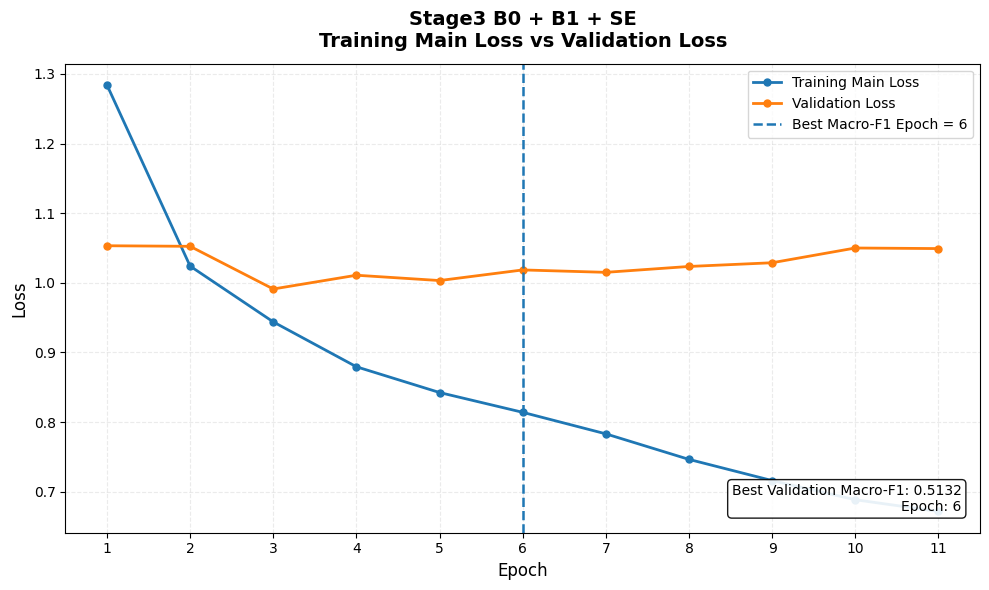

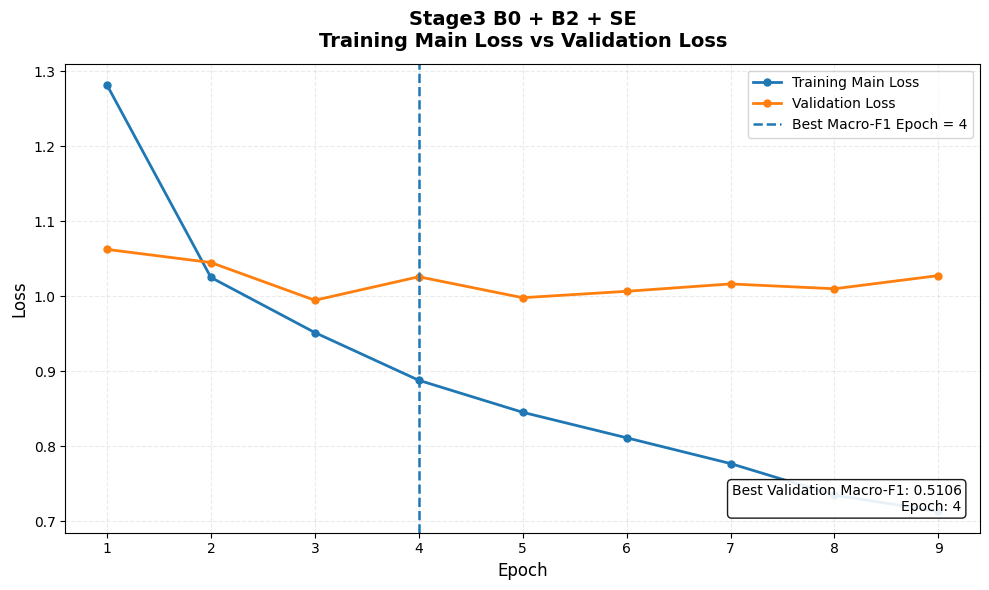

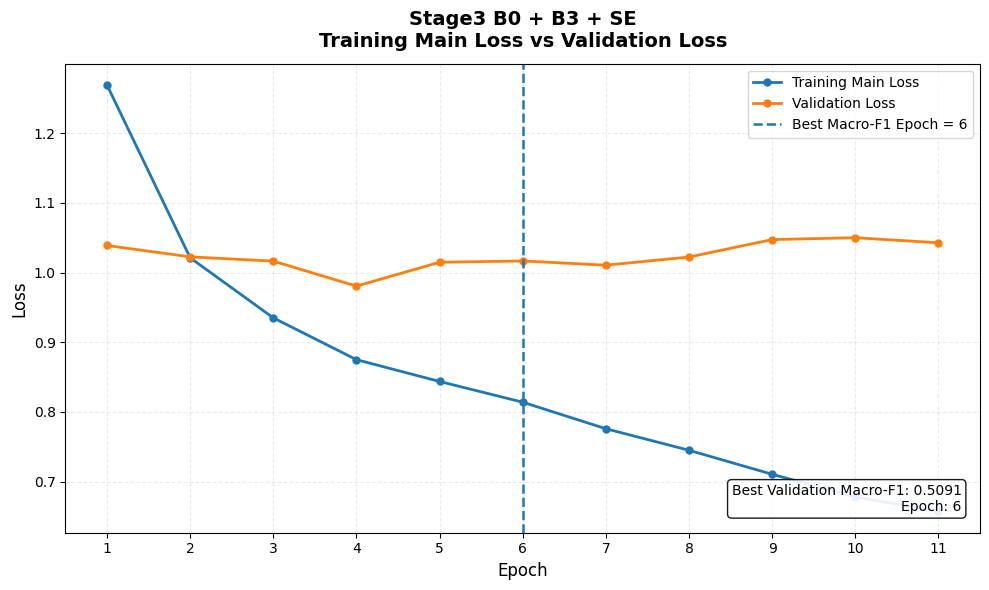

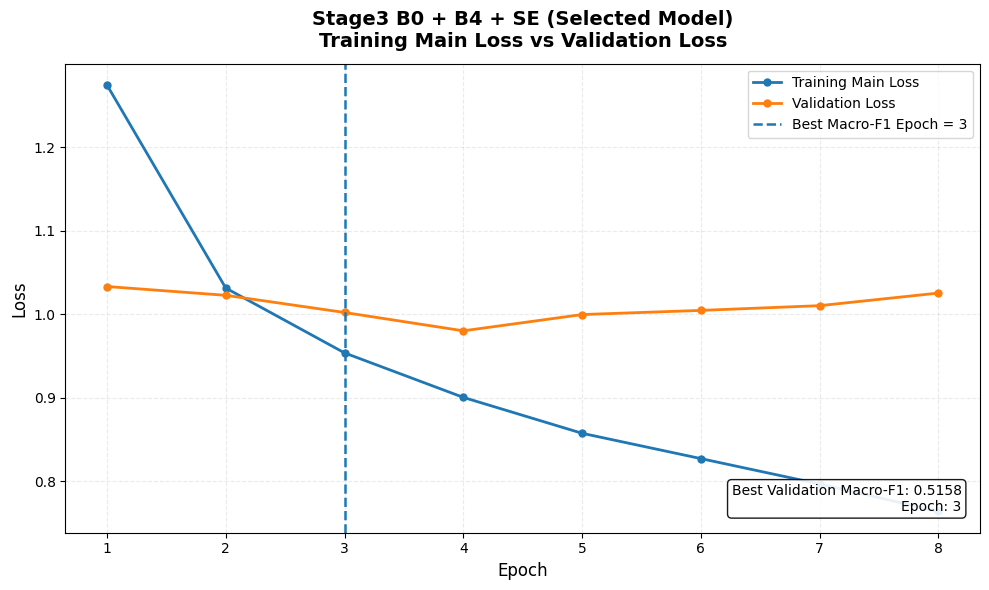

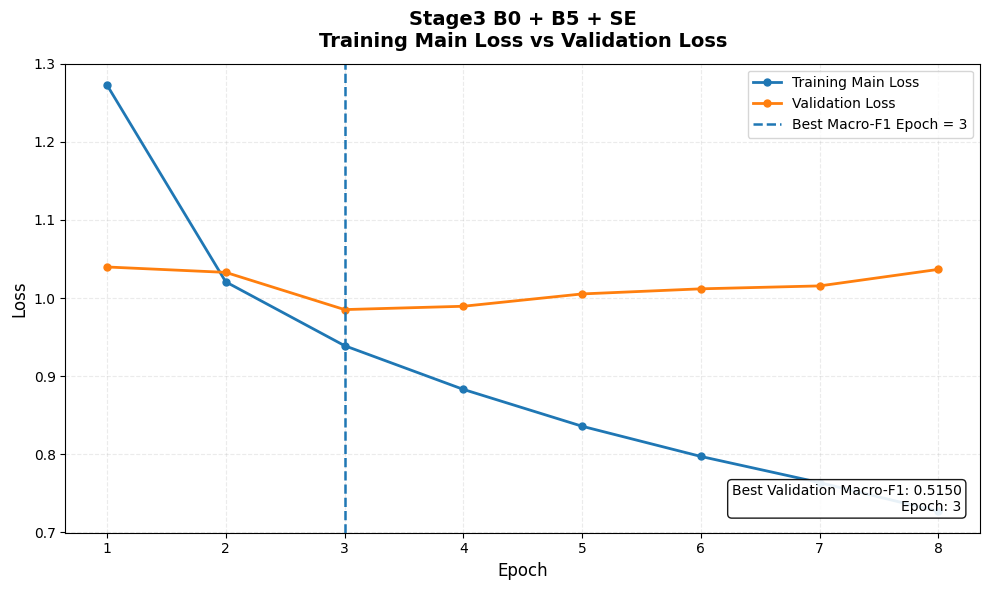

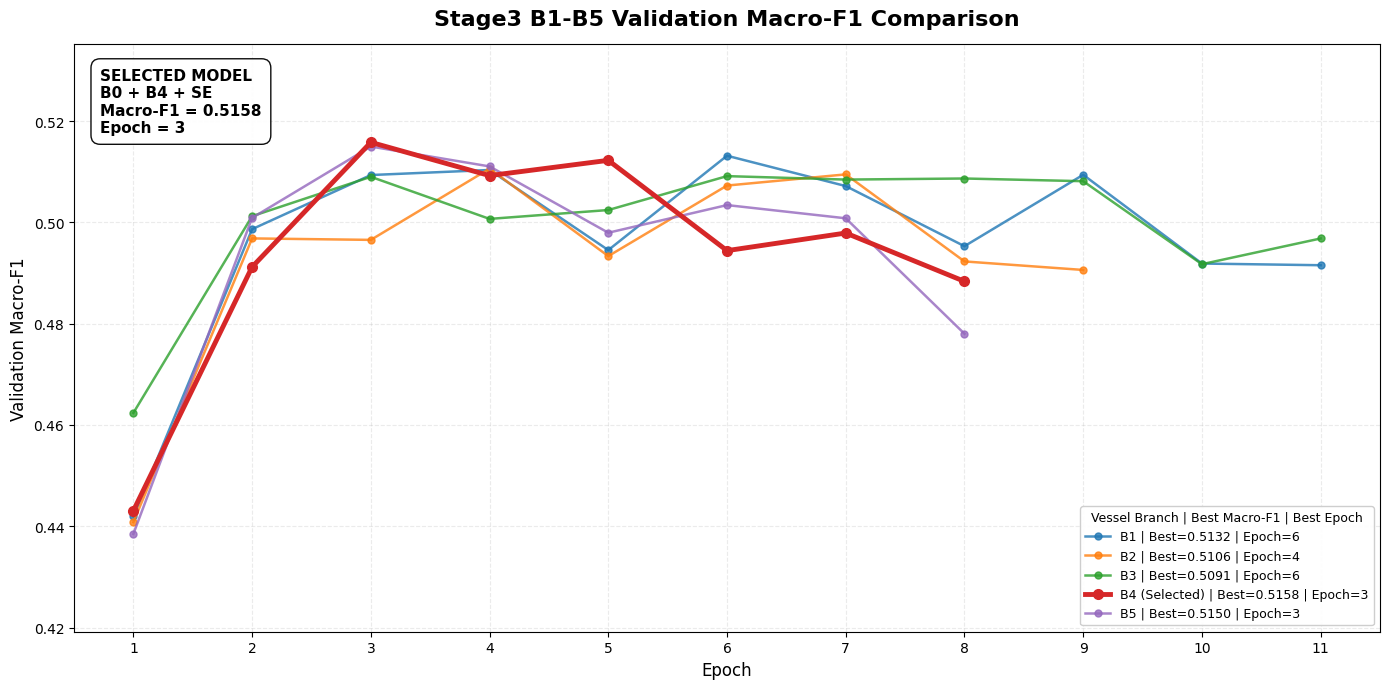


B1-B5 VALIDATION MACRO-F1 SUMMARY
Model  Best Validation Macro-F1  Best Epoch Selected
   B4                  0.515805           3      Yes
   B5                  0.514970           3       No
   B1                  0.513158           6       No
   B2                  0.510605           4       No
   B3                  0.509131           6       No

Selected model: B4

Training/validation loss plots:
/content/drive/MyDrive/DR_Project/stage3_b1_b5_comparison_with_val_loss/training_validation_curves

Validation Macro-F1 comparison plot:
/content/drive/MyDrive/DR_Project/stage3_b1_b5_comparison_with_val_loss/training_validation_curves/stage3_B1_B5_validation_macro_f1_model_selection.png

Validation Macro-F1 summary CSV:
/content/drive/MyDrive/DR_Project/stage3_b1_b5_comparison_with_val_loss/training_validation_curves/stage3_B1_B5_best_validation_macro_f1_summary.csv


In [19]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


STAGE3_DIR = (
    "/content/drive/MyDrive/DR_Project/"
    "stage3_b1_b5_comparison_with_val_loss"
)


CURVE_DIR = os.path.join(
    STAGE3_DIR,
    "training_validation_curves"
)


os.makedirs(
    CURVE_DIR,
    exist_ok=True
)


MODELS = [
    "B1",
    "B2",
    "B3",
    "B4",
    "B5"
]


SELECTED_FILE = os.path.join(
    STAGE3_DIR,
    "SELECTED_MODEL_VALIDATION.csv"
)


BEST_MODEL = None


if os.path.exists(
    SELECTED_FILE
):

    selected_df = pd.read_csv(
        SELECTED_FILE
    )

    if not selected_df.empty:

        BEST_MODEL = str(
            selected_df.iloc[0][
                "selected_model"
            ]
        )


for model_name in MODELS:

    history_file = os.path.join(
        STAGE3_DIR,
        f"stage3_{model_name}_history.csv"
    )


    if not os.path.exists(
        history_file
    ):

        print(
            f"{model_name}: history file not found."
        )

        continue


    history_df = pd.read_csv(
        history_file
    )


    required_columns = {
        "epoch",
        "train_main_loss",
        "val_loss",
        "val_macro_f1"
    }


    if (
        history_df.empty
        or
        not required_columns.issubset(
            history_df.columns
        )
    ):

        print(
            f"{model_name}: required history data missing."
        )

        continue


    epochs = history_df[
        "epoch"
    ].values


    train_main_loss = history_df[
        "train_main_loss"
    ].values


    val_loss = history_df[
        "val_loss"
    ].values


    best_idx = history_df[
        "val_macro_f1"
    ].idxmax()


    best_epoch = int(
        history_df.loc[
            best_idx,
            "epoch"
        ]
    )


    best_f1 = float(
        history_df.loc[
            best_idx,
            "val_macro_f1"
        ]
    )


    fig, ax = plt.subplots(
        figsize=(
            10,
            6
        )
    )


    ax.plot(
        epochs,
        train_main_loss,
        marker="o",
        markersize=5,
        linewidth=2,
        label="Training Main Loss"
    )


    ax.plot(
        epochs,
        val_loss,
        marker="o",
        markersize=5,
        linewidth=2,
        label="Validation Loss"
    )


    ax.axvline(
        best_epoch,
        linestyle="--",
        linewidth=1.8,
        label=(
            f"Best Macro-F1 Epoch = "
            f"{best_epoch}"
        )
    )


    if (
        BEST_MODEL is not None
        and
        model_name == BEST_MODEL
    ):

        title = (
            f"Stage3 B0 + {model_name} + SE "
            "(Selected Model)\n"
            "Training Main Loss vs Validation Loss"
        )

    else:

        title = (
            f"Stage3 B0 + {model_name} + SE\n"
            "Training Main Loss vs Validation Loss"
        )


    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold",
        pad=12
    )


    ax.set_xlabel(
        "Epoch",
        fontsize=12
    )


    ax.set_ylabel(
        "Loss",
        fontsize=12
    )


    ax.set_xticks(
        epochs
    )


    ax.tick_params(
        axis="both",
        labelsize=10
    )


    ax.grid(
        True,
        linestyle="--",
        alpha=0.25
    )


    ax.legend(
        loc="best",
        fontsize=10,
        frameon=True
    )


    ax.text(
        0.98,
        0.04,
        (
            f"Best Validation Macro-F1: "
            f"{best_f1:.4f}\n"
            f"Epoch: {best_epoch}"
        ),
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=10,
        bbox=dict(
            boxstyle="round",
            facecolor="white",
            edgecolor="black",
            alpha=0.9
        )
    )


    plt.tight_layout()


    loss_plot_path = os.path.join(
        CURVE_DIR,
        f"stage3_{model_name}_training_vs_validation_loss.png"
    )


    plt.savefig(
        loss_plot_path,
        dpi=220,
        bbox_inches="tight"
    )


    plt.show()


    plt.close(
        fig
    )


fig, ax = plt.subplots(
    figsize=(
        14,
        7
    )
)


all_f1_values = []

max_epoch = 0

selected_best_epoch = None

selected_best_f1 = None

model_summary = []


for model_name in MODELS:

    history_file = os.path.join(
        STAGE3_DIR,
        f"stage3_{model_name}_history.csv"
    )


    if not os.path.exists(
        history_file
    ):

        continue


    history_df = pd.read_csv(
        history_file
    )


    if (
        history_df.empty
        or
        "epoch" not in history_df.columns
        or
        "val_macro_f1" not in history_df.columns
    ):

        continue


    epochs = history_df[
        "epoch"
    ].values


    val_macro_f1 = history_df[
        "val_macro_f1"
    ].values


    all_f1_values.extend(
        val_macro_f1.tolist()
    )


    max_epoch = max(
        max_epoch,
        int(
            np.max(
                epochs
            )
        )
    )


    best_idx = history_df[
        "val_macro_f1"
    ].idxmax()


    best_epoch = int(
        history_df.loc[
            best_idx,
            "epoch"
        ]
    )


    best_f1 = float(
        history_df.loc[
            best_idx,
            "val_macro_f1"
        ]
    )


    is_selected = (
        BEST_MODEL is not None
        and
        model_name == BEST_MODEL
    )


    if is_selected:

        ax.plot(
            epochs,
            val_macro_f1,
            marker="o",
            markersize=7,
            linewidth=3.5,
            zorder=5,
            label=(
                f"{model_name} (Selected) | "
                f"Best={best_f1:.4f} | "
                f"Epoch={best_epoch}"
            )
        )


        selected_best_epoch = (
            best_epoch
        )


        selected_best_f1 = (
            best_f1
        )


    else:

        ax.plot(
            epochs,
            val_macro_f1,
            marker="o",
            markersize=5,
            linewidth=1.8,
            alpha=0.80,
            label=(
                f"{model_name} | "
                f"Best={best_f1:.4f} | "
                f"Epoch={best_epoch}"
            )
        )


    model_summary.append(
        {
            "Model":
                model_name,

            "Best Validation Macro-F1":
                best_f1,

            "Best Epoch":
                best_epoch,

            "Selected":
                (
                    "Yes"
                    if is_selected
                    else "No"
                )
        }
    )


if len(
    all_f1_values
) == 0:

    raise RuntimeError(
        "No validation Macro-F1 history found."
    )


y_min = min(
    all_f1_values
)


y_max = max(
    all_f1_values
)


y_range = (
    y_max
    -
    y_min
)


y_padding = max(
    0.01,
    y_range * 0.25
)


ax.set_ylim(
    max(
        0,
        y_min - y_padding
    ),
    min(
        1,
        y_max + y_padding
    )
)


if max_epoch > 0:

    ax.set_xticks(
        np.arange(
            1,
            max_epoch + 1,
            1
        )
    )


ax.set_title(
    "Stage3 B1-B5 Validation Macro-F1 Comparison",
    fontsize=16,
    fontweight="bold",
    pad=14
)


ax.set_xlabel(
    "Epoch",
    fontsize=12
)


ax.set_ylabel(
    "Validation Macro-F1",
    fontsize=12
)


ax.tick_params(
    axis="both",
    labelsize=10
)


ax.grid(
    True,
    linestyle="--",
    alpha=0.25
)


ax.legend(
    title=(
        "Vessel Branch | "
        "Best Macro-F1 | Best Epoch"
    ),
    loc="lower right",
    fontsize=9,
    title_fontsize=9,
    frameon=True,
    framealpha=0.95
)


if (
    selected_best_epoch is not None
    and
    selected_best_f1 is not None
):

    ax.text(
        0.02,
        0.96,
        (
            f"SELECTED MODEL\n"
            f"B0 + {BEST_MODEL} + SE\n"
            f"Macro-F1 = "
            f"{selected_best_f1:.4f}\n"
            f"Epoch = "
            f"{selected_best_epoch}"
        ),
        transform=ax.transAxes,
        fontsize=11,
        fontweight="bold",
        va="top",
        ha="left",
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="white",
            edgecolor="black",
            alpha=0.95
        )
    )


plt.tight_layout()


macro_f1_plot_path = os.path.join(
    CURVE_DIR,
    "stage3_B1_B5_validation_macro_f1_model_selection.png"
)


plt.savefig(
    macro_f1_plot_path,
    dpi=220,
    bbox_inches="tight"
)


plt.show()


plt.close(
    fig
)


model_summary_df = pd.DataFrame(
    model_summary
)


model_summary_df = (
    model_summary_df
    .sort_values(
        by=[
            "Best Validation Macro-F1"
        ],
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


summary_path = os.path.join(
    CURVE_DIR,
    "stage3_B1_B5_best_validation_macro_f1_summary.csv"
)


model_summary_df.to_csv(
    summary_path,
    index=False
)


print(
    "\n"
    + "=" * 80
)


print(
    "B1-B5 VALIDATION MACRO-F1 SUMMARY"
)


print(
    "=" * 80
)


print(
    model_summary_df.to_string(
        index=False
    )
)


print(
    "\nSelected model:",
    BEST_MODEL
)


print(
    "\nTraining/validation loss plots:"
)


print(
    CURVE_DIR
)


print(
    "\nValidation Macro-F1 comparison plot:"
)


print(
    macro_f1_plot_path
)


print(
    "\nValidation Macro-F1 summary CSV:"
)


print(
    summary_path
)


SELECTED MODEL FROM VALIDATION
Model: B0 + B4 + SE
Best validation epoch: 3
Validation Macro-F1: 0.5157
Checkpoint:
/content/drive/MyDrive/DR_Project/stage3_b1_b5_comparison_with_val_loss/stage3_B4_best.pth

Selected Stage3 model loaded successfully.

FINAL TEST SET VERIFICATION
Stage1 final test images: 5269
Stage3 final test images: 5269
Same exact test IDs: True
Same exact test IDs and order: True
Stage1-only IDs: 0
Stage3-only IDs: 0

STAGE1 TEST


Stage1 Test:   0%|          | 0/83 [00:00<?, ?batch/s]


STAGE3 TEST: B0 + B4 + SE


Stage3 B0+B4+SE Test:   0%|          | 0/659 [00:00<?, ?batch/s]


Stage1 and Stage3 test labels/order match: True

STAGE1 - RGB ONLY
                  precision    recall  f1-score   support

           no_dr     0.8409    0.8657    0.8531      3872
            mild     0.1250    0.1557    0.1387       366
        moderate     0.5303    0.4521    0.4881       794
          severe     0.5000    0.3053    0.3791       131
proliferative_dr     0.7714    0.5094    0.6136       106

        accuracy                         0.7330      5269
       macro avg     0.5535    0.4577    0.4945      5269
    weighted avg     0.7345    0.7330    0.7319      5269

Accuracy        = 0.7330
Macro-F1        = 0.4945
Weighted-F1     = 0.7319
Macro Precision = 0.5535
Macro Recall    = 0.4577
Macro-AUROC     = 0.8121

STAGE3 - RGB B0 + B4 VESSEL + SE
                  precision    recall  f1-score   support

           no_dr     0.8377    0.9026    0.8690      3872
            mild     0.1235    0.1093    0.1159       366
        moderate     0.5887    0.4055    0.4802 

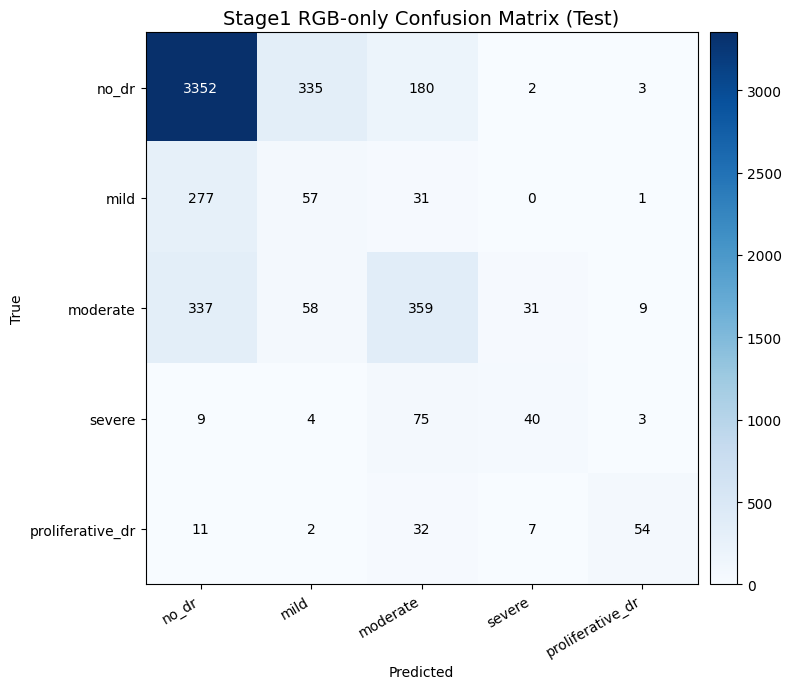

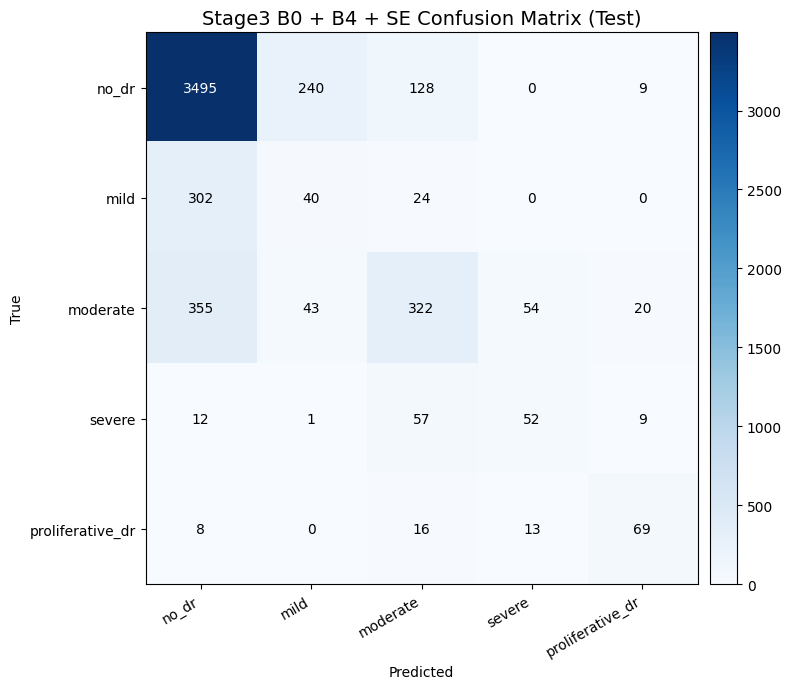

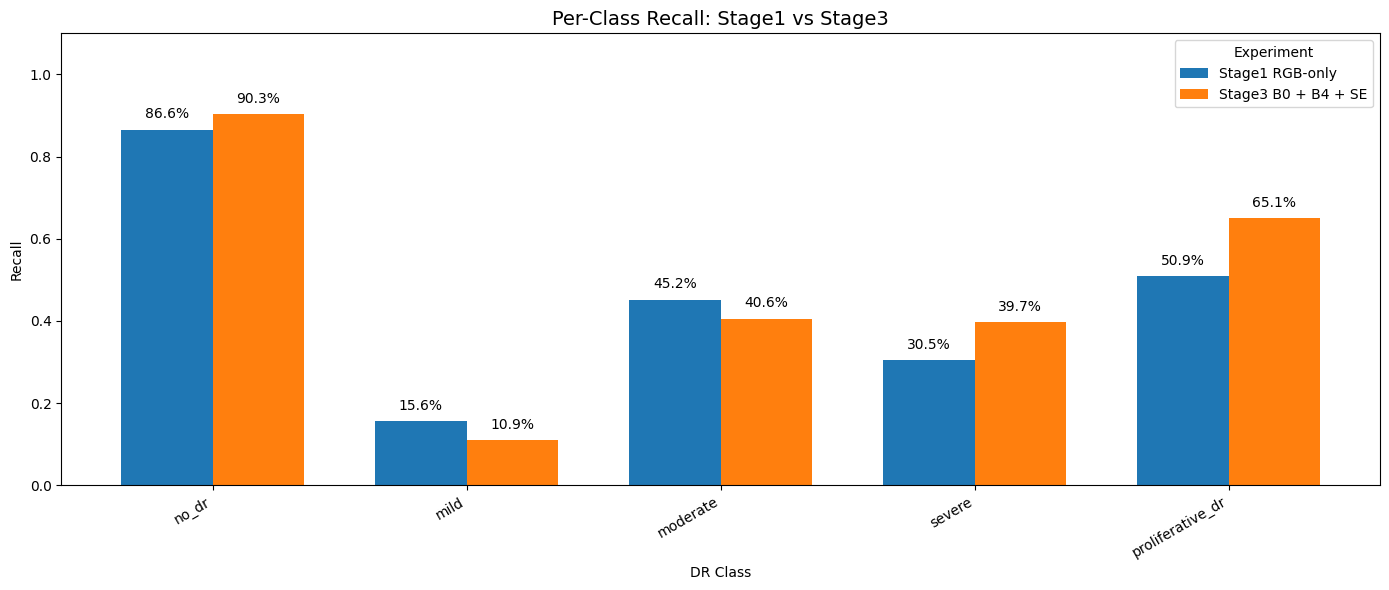


FINAL TESTING COMPLETED

Selected model: B0 + B4 + SE
Stage3 Test Accuracy: 0.7550
Stage3 Test Macro-F1: 0.5058
Stage3 Test Weighted-F1: 0.7424
Stage3 Test Macro-Precision: 0.5263
Stage3 Test Macro-Recall: 0.4931
Stage3 Test Macro-AUROC: 0.8286

Stage1 confusion matrix:
/content/drive/MyDrive/DR_Project/final_stage1_stage3_B1_B5_comparison/stage1_confusion_matrix.png

Stage3 confusion matrix:
/content/drive/MyDrive/DR_Project/final_stage1_stage3_B1_B5_comparison/stage3_B0_B4_SE_confusion_matrix.png

Per-class recall plot:
/content/drive/MyDrive/DR_Project/final_stage1_stage3_B1_B5_comparison/per_class_recall_comparison.png

Selected test CSV:
/content/drive/MyDrive/DR_Project/stage3_b1_b5_comparison_with_val_loss/SELECTED_MODEL_FINAL_TEST.csv
/content/drive/MyDrive/DR_Project/final_stage1_stage3_B1_B5_comparison


In [20]:
import os
import shutil
import warnings

import numpy as np
import pandas as pd

import torch
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

from sklearn.preprocessing import (
    label_binarize
)

from mpl_toolkits.axes_grid1 import make_axes_locatable


warnings.filterwarnings(
    "ignore",
    message="Mapping deprecated model name.*"
)


required_items = [
    "Stage3EfficientNetB0BxSE",
    "stage1",
    "df_stage3",
    "test_df",
    "stage3_test_ds",
    "DRStage3Dataset",
    "STAGE3_SIZE",
    "STAGE3_BATCH",
    "STAGE3_NUM_WORKERS",
    "PIN_MEMORY",
    "CLASS_NAMES",
    "num_classes",
    "device",
    "STAGE1_W"
]


missing = [
    name
    for name in required_items
    if name not in globals()
]


if missing:
    raise RuntimeError(
        "Missing required testing variables: "
        + ", ".join(missing)
    )


AMP_DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


def macro_auroc(
    y_true,
    y_probs,
    num_classes
):
    try:
        y_true_bin = label_binarize(
            y_true,
            classes=list(
                range(
                    num_classes
                )
            )
        )

        return float(
            roc_auc_score(
                y_true_bin,
                y_probs,
                average="macro",
                multi_class="ovr"
            )
        )

    except Exception as e:
        print(
            "AUROC calculation warning:",
            e
        )

        return np.nan


if "DRIVE_COMPARE_DIR" not in globals():
    DRIVE_COMPARE_DIR = (
        "/content/drive/MyDrive/DR_Project/"
        "stage3_b1_b5_comparison_with_val_loss"
    )


FINAL_DIR = (
    "/content/drive/MyDrive/DR_Project/"
    "final_stage1_stage3_B1_B5_comparison"
)


os.makedirs(
    FINAL_DIR,
    exist_ok=True
)


selected_validation_csv = os.path.join(
    DRIVE_COMPARE_DIR,
    "SELECTED_MODEL_VALIDATION.csv"
)


if not os.path.exists(
    selected_validation_csv
):
    raise FileNotFoundError(
        "SELECTED_MODEL_VALIDATION.csv not found."
    )


selected_info = pd.read_csv(
    selected_validation_csv
).iloc[0]


BEST_MODEL = str(
    selected_info[
        "selected_model"
    ]
)


BEST_TIMM_MODEL = str(
    selected_info[
        "timm_model"
    ]
)


BEST_CHECKPOINT = str(
    selected_info[
        "checkpoint"
    ]
)


BEST_BATCH_SIZE = int(
    selected_info[
        "batch_size"
    ]
)


print(
    "\n"
    + "=" * 80
)


print(
    "SELECTED MODEL FROM VALIDATION"
)


print(
    "=" * 80
)


print(
    f"Model: B0 + {BEST_MODEL} + SE"
)


print(
    f"Best validation epoch: "
    f"{int(selected_info['best_epoch'])}"
)


print(
    f"Validation Macro-F1: "
    f"{selected_info['validation_macro_f1']:.4f}"
)


print(
    "Checkpoint:"
)


print(
    BEST_CHECKPOINT
)


if not os.path.exists(
    BEST_CHECKPOINT
):
    raise FileNotFoundError(
        BEST_CHECKPOINT
    )


LOCAL_STAGE1_W = os.path.join(
    "/content",
    os.path.basename(
        STAGE1_W
    )
)


if not os.path.exists(
    LOCAL_STAGE1_W
):
    shutil.copy2(
        STAGE1_W,
        LOCAL_STAGE1_W
    )


LOCAL_BEST_CHECKPOINT = os.path.join(
    "/content",
    f"selected_stage3_{BEST_MODEL}.pth"
)


shutil.copy2(
    BEST_CHECKPOINT,
    LOCAL_BEST_CHECKPOINT
)


stage3_clf = Stage3EfficientNetB0BxSE(
    num_classes,
    LOCAL_STAGE1_W,
    BEST_TIMM_MODEL,
    mask_pretrained=False
).to(
    device
)


if torch.cuda.is_available():
    stage3_clf = stage3_clf.to(
        memory_format=
            torch.channels_last
    )


stage3_clf.load_state_dict(
    torch.load(
        LOCAL_BEST_CHECKPOINT,
        map_location=device
    )
)


stage1.eval()

stage3_clf.eval()


print(
    "\nSelected Stage3 model loaded successfully."
)


if "stage1_test_names" not in globals():

    if "SPLIT_DIR" not in globals():
        raise RuntimeError(
            "SPLIT_DIR is missing."
        )

    stage1_test_file = os.path.join(
        SPLIT_DIR,
        "stage1_test_names.txt"
    )

    if not os.path.exists(
        stage1_test_file
    ):
        raise FileNotFoundError(
            stage1_test_file
        )

    with open(
        stage1_test_file,
        "r"
    ) as f:
        stage1_test_names = set(
            line.strip()
            for line in f
            if line.strip()
        )


df_stage1_test = (
    df_stage3[
        df_stage3[
            "basename"
        ].isin(
            stage1_test_names
        )
    ]
    .reset_index(
        drop=True
    )
)


stage1_final_test_ids = (
    df_stage1_test[
        "basename"
    ]
    .astype(str)
    .tolist()
)


stage3_final_test_ids = (
    test_df[
        "basename"
    ]
    .astype(str)
    .tolist()
)


if len(stage1_final_test_ids) != len(
    stage1_test_names
):
    raise RuntimeError(
        "Stage1 final test image count does not "
        "match stage1_test_names.txt."
    )


if len(stage3_final_test_ids) != len(
    stage1_test_names
):
    raise RuntimeError(
        "Stage3 final test image count does not "
        "match stage1_test_names.txt."
    )


if set(
    stage1_final_test_ids
) != stage1_test_names:
    raise RuntimeError(
        "Stage1 final test IDs do not exactly "
        "match stage1_test_names.txt."
    )


if set(
    stage3_final_test_ids
) != stage1_test_names:
    raise RuntimeError(
        "Stage3 final test IDs do not exactly "
        "match stage1_test_names.txt."
    )


if (
    stage1_final_test_ids
    !=
    stage3_final_test_ids
):
    raise RuntimeError(
        "Stage1 and Stage3 final test image "
        "IDs/order do not match."
    )


print(
    "\n"
    + "=" * 80
)


print(
    "FINAL TEST SET VERIFICATION"
)


print(
    "=" * 80
)


print(
    "Stage1 final test images:",
    len(stage1_final_test_ids)
)


print(
    "Stage3 final test images:",
    len(stage3_final_test_ids)
)


print(
    "Same exact test IDs:",
    set(stage1_final_test_ids)
    ==
    set(stage3_final_test_ids)
)


print(
    "Same exact test IDs and order:",
    stage1_final_test_ids
    ==
    stage3_final_test_ids
)


print(
    "Stage1-only IDs:",
    len(
        set(stage1_final_test_ids)
        -
        set(stage3_final_test_ids)
    )
)


print(
    "Stage3-only IDs:",
    len(
        set(stage3_final_test_ids)
        -
        set(stage1_final_test_ids)
    )
)


stage1_test_ds = DRStage3Dataset(
    df_stage1_test,
    size=STAGE3_SIZE,
    augment=False
)


stage1_loader_args = {
    "batch_size":
        STAGE3_BATCH,

    "shuffle":
        False,

    "num_workers":
        STAGE3_NUM_WORKERS,

    "pin_memory":
        PIN_MEMORY
}


if STAGE3_NUM_WORKERS > 0:
    stage1_loader_args[
        "persistent_workers"
    ] = True

    stage1_loader_args[
        "prefetch_factor"
    ] = 2


stage1_test_loader = DataLoader(
    stage1_test_ds,
    **stage1_loader_args
)


print(
    "\n"
    + "=" * 80
)


print(
    "STAGE1 TEST"
)


print(
    "=" * 80
)


s1_labels = []

s1_preds = []

s1_probs = []


with torch.inference_mode():

    stage1_pbar = tqdm(
        stage1_test_loader,
        desc="Stage1 Test",
        unit="batch",
        dynamic_ncols=True
    )

    for (
        rgb,
        mask,
        labels
    ) in stage1_pbar:

        rgb = rgb.to(
            device,
            non_blocking=True
        )

        if torch.cuda.is_available():
            rgb = rgb.contiguous(
                memory_format=
                    torch.channels_last
            )

        with torch.amp.autocast(
            device_type=
                AMP_DEVICE,

            enabled=
                torch.cuda.is_available()
        ):

            logits_s1 = stage1(
                rgb
            )

            probs_s1 = torch.softmax(
                logits_s1,
                dim=1
            )

        s1_labels.extend(
            labels
            .detach()
            .cpu()
            .numpy()
        )

        s1_preds.extend(
            logits_s1
            .argmax(
                dim=1
            )
            .detach()
            .cpu()
            .numpy()
        )

        s1_probs.extend(
            probs_s1
            .detach()
            .cpu()
            .numpy()
        )


s1_labels = np.array(
    s1_labels
)


s1_preds = np.array(
    s1_preds
)


s1_probs = np.array(
    s1_probs
)


stage3_loader_args = {
    "batch_size":
        BEST_BATCH_SIZE,

    "shuffle":
        False,

    "num_workers":
        STAGE3_NUM_WORKERS,

    "pin_memory":
        PIN_MEMORY
}


if STAGE3_NUM_WORKERS > 0:
    stage3_loader_args[
        "persistent_workers"
    ] = True

    stage3_loader_args[
        "prefetch_factor"
    ] = 4


stage3_test_loader = DataLoader(
    stage3_test_ds,
    **stage3_loader_args
)


print(
    "\n"
    + "=" * 80
)


print(
    f"STAGE3 TEST: "
    f"B0 + {BEST_MODEL} + SE"
)


print(
    "=" * 80
)


s3_labels = []

s3_preds = []

s3_probs = []


with torch.inference_mode():

    stage3_pbar = tqdm(
        stage3_test_loader,
        desc=(
            f"Stage3 B0+{BEST_MODEL}+SE Test"
        ),
        unit="batch",
        dynamic_ncols=True
    )

    for (
        rgb,
        mask,
        labels
    ) in stage3_pbar:

        rgb = rgb.to(
            device,
            non_blocking=True
        )

        mask = mask.to(
            device,
            non_blocking=True
        )

        if torch.cuda.is_available():

            rgb = rgb.contiguous(
                memory_format=
                    torch.channels_last
            )

            mask = mask.contiguous(
                memory_format=
                    torch.channels_last
            )

        with torch.amp.autocast(
            device_type=
                AMP_DEVICE,

            enabled=
                torch.cuda.is_available()
        ):

            logits_s3 = stage3_clf(
                rgb,
                mask
            )

            probs_s3 = torch.softmax(
                logits_s3,
                dim=1
            )

        s3_labels.extend(
            labels
            .detach()
            .cpu()
            .numpy()
        )

        s3_preds.extend(
            logits_s3
            .argmax(
                dim=1
            )
            .detach()
            .cpu()
            .numpy()
        )

        s3_probs.extend(
            probs_s3
            .detach()
            .cpu()
            .numpy()
        )


s3_labels = np.array(
    s3_labels
)


s3_preds = np.array(
    s3_preds
)


s3_probs = np.array(
    s3_probs
)


if not np.array_equal(
    s1_labels,
    s3_labels
):
    raise RuntimeError(
        "Stage1 and Stage3 test labels/order do not match."
    )


print(
    "\nStage1 and Stage3 test labels/order match:",
    True
)


S1_ACC = accuracy_score(
    s1_labels,
    s1_preds
)


S1_F1 = f1_score(
    s1_labels,
    s1_preds,
    average="macro",
    zero_division=0
)


S1_F1W = f1_score(
    s1_labels,
    s1_preds,
    average="weighted",
    zero_division=0
)


S1_PRECISION = precision_score(
    s1_labels,
    s1_preds,
    average="macro",
    zero_division=0
)


S1_MACRO_RECALL = recall_score(
    s1_labels,
    s1_preds,
    average="macro",
    zero_division=0
)


S1_AUC = macro_auroc(
    s1_labels,
    s1_probs,
    num_classes
)


S1_RECALL = recall_score(
    s1_labels,
    s1_preds,
    average=None,
    labels=list(
        range(
            num_classes
        )
    ),
    zero_division=0
)


CM1 = confusion_matrix(
    s1_labels,
    s1_preds,
    labels=list(
        range(
            num_classes
        )
    )
)


S3_ACC = accuracy_score(
    s3_labels,
    s3_preds
)


S3_F1 = f1_score(
    s3_labels,
    s3_preds,
    average="macro",
    zero_division=0
)


S3_F1W = f1_score(
    s3_labels,
    s3_preds,
    average="weighted",
    zero_division=0
)


S3_PRECISION = precision_score(
    s3_labels,
    s3_preds,
    average="macro",
    zero_division=0
)


S3_MACRO_RECALL = recall_score(
    s3_labels,
    s3_preds,
    average="macro",
    zero_division=0
)


S3_AUC = macro_auroc(
    s3_labels,
    s3_probs,
    num_classes
)


S3_RECALL = recall_score(
    s3_labels,
    s3_preds,
    average=None,
    labels=list(
        range(
            num_classes
        )
    ),
    zero_division=0
)


CM3 = confusion_matrix(
    s3_labels,
    s3_preds,
    labels=list(
        range(
            num_classes
        )
    )
)


print(
    "\n"
    + "=" * 70
)


print(
    "STAGE1 - RGB ONLY"
)


print(
    "=" * 70
)


print(
    classification_report(
        s1_labels,
        s1_preds,
        target_names=
            CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)


print(
    f"Accuracy        = "
    f"{S1_ACC:.4f}"
)


print(
    f"Macro-F1        = "
    f"{S1_F1:.4f}"
)


print(
    f"Weighted-F1     = "
    f"{S1_F1W:.4f}"
)


print(
    f"Macro Precision = "
    f"{S1_PRECISION:.4f}"
)


print(
    f"Macro Recall    = "
    f"{S1_MACRO_RECALL:.4f}"
)


print(
    f"Macro-AUROC     = "
    f"{S1_AUC:.4f}"
)


print(
    "\n"
    + "=" * 70
)


print(
    f"STAGE3 - RGB B0 + "
    f"{BEST_MODEL} VESSEL + SE"
)


print(
    "=" * 70
)


print(
    classification_report(
        s3_labels,
        s3_preds,
        target_names=
            CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)


print(
    f"Accuracy        = "
    f"{S3_ACC:.4f}"
)


print(
    f"Macro-F1        = "
    f"{S3_F1:.4f}"
)


print(
    f"Weighted-F1     = "
    f"{S3_F1W:.4f}"
)


print(
    f"Macro Precision = "
    f"{S3_PRECISION:.4f}"
)


print(
    f"Macro Recall    = "
    f"{S3_MACRO_RECALL:.4f}"
)


print(
    f"Macro-AUROC     = "
    f"{S3_AUC:.4f}"
)


summary_df = pd.DataFrame(
    [
        {
            "Model":
                "Stage1 RGB-only",

            "Accuracy":
                S1_ACC,

            "Macro F1":
                S1_F1,

            "Weighted F1":
                S1_F1W,

            "Macro Precision":
                S1_PRECISION,

            "Macro Recall":
                S1_MACRO_RECALL,

            "Macro AUROC":
                S1_AUC
        },

        {
            "Model":
                f"Stage3 B0 + {BEST_MODEL} + SE",

            "Accuracy":
                S3_ACC,

            "Macro F1":
                S3_F1,

            "Weighted F1":
                S3_F1W,

            "Macro Precision":
                S3_PRECISION,

            "Macro Recall":
                S3_MACRO_RECALL,

            "Macro AUROC":
                S3_AUC
        }
    ]
)


print(
    "\n"
    + "=" * 70
)


print(
    "OVERALL TEST COMPARISON"
)


print(
    "=" * 70
)


print(
    summary_df.to_string(
        index=False
    )
)


recall_df = pd.DataFrame(
    {
        "Class":
            CLASS_NAMES,

        "Stage1 Recall":
            S1_RECALL,

        "Stage3 Recall":
            S3_RECALL,

        "Gain":
            S3_RECALL
            -
            S1_RECALL
    }
)


print(
    "\n"
    + "=" * 70
)


print(
    "PER-CLASS RECALL"
)


print(
    "=" * 70
)


print(
    recall_df.to_string(
        index=False
    )
)


summary_csv = os.path.join(
    FINAL_DIR,
    "overall_comparison.csv"
)


summary_df.to_csv(
    summary_csv,
    index=False
)


recall_csv = os.path.join(
    FINAL_DIR,
    "per_class_recall.csv"
)


recall_df.to_csv(
    recall_csv,
    index=False
)


selected_test_result = {
    "selected_model":
        BEST_MODEL,

    "timm_model":
        BEST_TIMM_MODEL,

    "validation_accuracy":
        selected_info[
            "validation_accuracy"
        ],

    "validation_macro_f1":
        selected_info[
            "validation_macro_f1"
        ],

    "validation_macro_auc":
        selected_info[
            "validation_macro_auc"
        ],

    "test_accuracy":
        S3_ACC,

    "test_macro_f1":
        S3_F1,

    "test_weighted_f1":
        S3_F1W,

    "test_macro_precision":
        S3_PRECISION,

    "test_macro_recall":
        S3_MACRO_RECALL,

    "test_macro_auc":
        S3_AUC,

    "checkpoint":
        BEST_CHECKPOINT
}


for (
    i,
    class_name
) in enumerate(
    CLASS_NAMES
):

    selected_test_result[
        f"test_recall_{class_name}"
    ] = S3_RECALL[
        i
    ]


selected_test_csv = os.path.join(
    DRIVE_COMPARE_DIR,
    "SELECTED_MODEL_FINAL_TEST.csv"
)


pd.DataFrame(
    [
        selected_test_result
    ]
).to_csv(
    selected_test_csv,
    index=False
)


fig, ax = plt.subplots(
    figsize=(
        8,
        7
    )
)


im1 = ax.imshow(
    CM1,
    interpolation="nearest",
    cmap="Blues"
)


divider1 = make_axes_locatable(
    ax
)


cax1 = divider1.append_axes(
    "right",
    size="5%",
    pad=0.12
)


fig.colorbar(
    im1,
    cax=cax1
)


ax.set_title(
    "Stage1 RGB-only Confusion Matrix (Test)",
    fontsize=14
)


ax.set_xlabel(
    "Predicted"
)


ax.set_ylabel(
    "True"
)


ax.set_xticks(
    np.arange(
        len(CLASS_NAMES)
    )
)


ax.set_yticks(
    np.arange(
        len(CLASS_NAMES)
    )
)


ax.set_xticklabels(
    CLASS_NAMES,
    rotation=30,
    ha="right"
)


ax.set_yticklabels(
    CLASS_NAMES
)


threshold1 = CM1.max() / 2.0


for i in range(
    CM1.shape[0]
):
    for j in range(
        CM1.shape[1]
    ):

        ax.text(
            j,
            i,
            f"{CM1[i, j]:d}",
            ha="center",
            va="center",
            color=(
                "white"
                if CM1[i, j] > threshold1
                else "black"
            )
        )


plt.tight_layout()


cm1_plot = os.path.join(
    FINAL_DIR,
    "stage1_confusion_matrix.png"
)


plt.savefig(
    cm1_plot,
    dpi=220,
    bbox_inches="tight"
)


plt.show()


fig, ax = plt.subplots(
    figsize=(
        8,
        7
    )
)


im3 = ax.imshow(
    CM3,
    interpolation="nearest",
    cmap="Blues"
)


divider3 = make_axes_locatable(
    ax
)


cax3 = divider3.append_axes(
    "right",
    size="5%",
    pad=0.12
)


fig.colorbar(
    im3,
    cax=cax3
)


ax.set_title(
    f"Stage3 B0 + {BEST_MODEL} + SE Confusion Matrix (Test)",
    fontsize=14
)


ax.set_xlabel(
    "Predicted"
)


ax.set_ylabel(
    "True"
)


ax.set_xticks(
    np.arange(
        len(CLASS_NAMES)
    )
)


ax.set_yticks(
    np.arange(
        len(CLASS_NAMES)
    )
)


ax.set_xticklabels(
    CLASS_NAMES,
    rotation=30,
    ha="right"
)


ax.set_yticklabels(
    CLASS_NAMES
)


threshold3 = CM3.max() / 2.0


for i in range(
    CM3.shape[0]
):
    for j in range(
        CM3.shape[1]
    ):

        ax.text(
            j,
            i,
            f"{CM3[i, j]:d}",
            ha="center",
            va="center",
            color=(
                "white"
                if CM3[i, j] > threshold3
                else "black"
            )
        )


plt.tight_layout()


cm3_plot = os.path.join(
    FINAL_DIR,
    f"stage3_B0_{BEST_MODEL}_SE_confusion_matrix.png"
)


plt.savefig(
    cm3_plot,
    dpi=220,
    bbox_inches="tight"
)


plt.show()


x = np.arange(
    len(
        CLASS_NAMES
    )
)


width = 0.36


fig, ax = plt.subplots(
    figsize=(
        14,
        6
    )
)


bars1 = ax.bar(
    x - width / 2,
    S1_RECALL,
    width,
    label="Stage1 RGB-only"
)


bars2 = ax.bar(
    x + width / 2,
    S3_RECALL,
    width,
    label=(
        f"Stage3 B0 + {BEST_MODEL} + SE"
    )
)


ax.set_title(
    "Per-Class Recall: Stage1 vs Stage3",
    fontsize=14
)


ax.set_xlabel(
    "DR Class"
)


ax.set_ylabel(
    "Recall"
)


ax.set_xticks(
    x
)


ax.set_xticklabels(
    CLASS_NAMES,
    rotation=30,
    ha="right"
)


ax.set_ylim(
    0,
    1.10
)


ax.legend(
    title="Experiment"
)


for bar in bars1:

    height = bar.get_height()

    ax.text(
        bar.get_x()
        +
        bar.get_width() / 2,
        height + 0.02,
        f"{height * 100:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )


for bar in bars2:

    height = bar.get_height()

    ax.text(
        bar.get_x()
        +
        bar.get_width() / 2,
        height + 0.02,
        f"{height * 100:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )


plt.tight_layout()


recall_plot = os.path.join(
    FINAL_DIR,
    "per_class_recall_comparison.png"
)


plt.savefig(
    recall_plot,
    dpi=220,
    bbox_inches="tight"
)


plt.show()


stage3_xai = stage3_clf


print(
    "\n"
    + "=" * 100
)


print(
    "FINAL TESTING COMPLETED"
)


print(
    "=" * 100
)


print(
    f"\nSelected model: "
    f"B0 + {BEST_MODEL} + SE"
)


print(
    f"Stage3 Test Accuracy: "
    f"{S3_ACC:.4f}"
)


print(
    f"Stage3 Test Macro-F1: "
    f"{S3_F1:.4f}"
)


print(
    f"Stage3 Test Weighted-F1: "
    f"{S3_F1W:.4f}"
)


print(
    f"Stage3 Test Macro-Precision: "
    f"{S3_PRECISION:.4f}"
)


print(
    f"Stage3 Test Macro-Recall: "
    f"{S3_MACRO_RECALL:.4f}"
)


print(
    f"Stage3 Test Macro-AUROC: "
    f"{S3_AUC:.4f}"
)


print(
    "\nStage1 confusion matrix:"
)


print(
    cm1_plot
)


print(
    "\nStage3 confusion matrix:"
)


print(
    cm3_plot
)


print(
    "\nPer-class recall plot:"
)


print(
    recall_plot
)


print(
    "\nSelected test CSV:"
)


print(
    selected_test_csv
)




print(
    FINAL_DIR
)


PER-CLASS ROC AUC RESULTS


,class,stage1_auc,stage3_auc,stage3_minus_stage1_auc
0,no_dr,0.778106,0.793522,0.015415
1,mild,0.616553,0.630582,0.014029
2,moderate,0.789923,0.809646,0.019723
3,severe,0.920927,0.948603,0.027676
4,proliferative_dr,0.955180,0.960645,0.005465


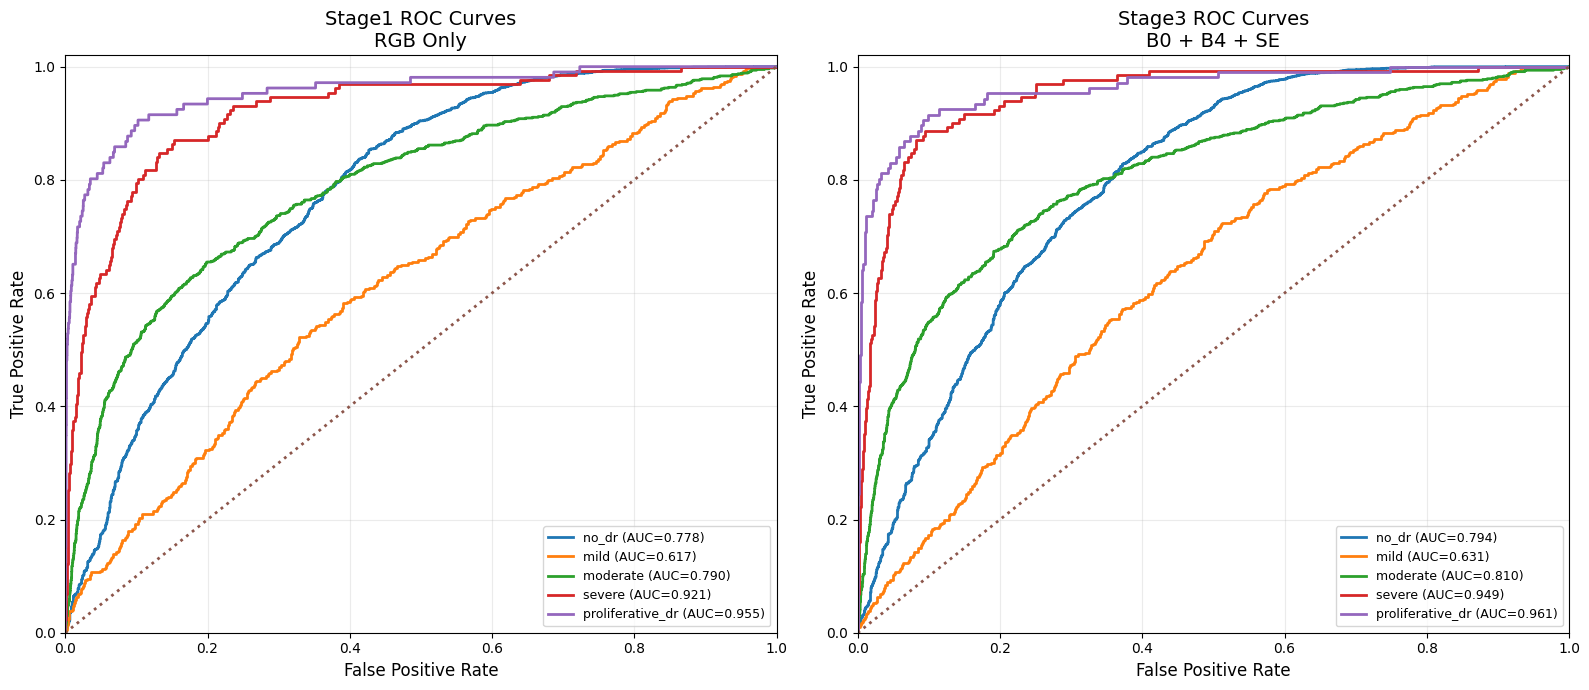


ROC ANALYSIS COMPLETED

Per-class ROC AUC CSV:
/content/drive/MyDrive/DR_Project/final_stage1_stage3_B1_B5_comparison/roc_curves/stage1_stage3_per_class_roc_auc.csv

ROC curve image:
/content/drive/MyDrive/DR_Project/final_stage1_stage3_B1_B5_comparison/roc_curves/stage1_stage3_per_class_roc_curves.png

Stage1 probability CSV:
/content/drive/MyDrive/DR_Project/final_stage1_stage3_B1_B5_comparison/roc_curves/stage1_test_probabilities.csv

Stage3 probability CSV:
/content/drive/MyDrive/DR_Project/final_stage1_stage3_B1_B5_comparison/roc_curves/stage3_test_probabilities.csv

Stage3 model analyzed: B0 + B4 + SE


In [21]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from tqdm.auto import tqdm

from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    roc_curve,
    auc
)


required_variables = [
    "stage1",
    "stage1_test_ds",
    "s3_labels",
    "s3_probs",
    "CLASS_NAMES",
    "device"
]


missing_variables = [
    name
    for name in required_variables
    if name not in globals()
]


if missing_variables:
    raise RuntimeError(
        "Run the Stage1/Stage3 final testing cell first. "
        f"Missing variables: {missing_variables}"
    )


if "FINAL_DIR" in globals():

    ROC_DIR = os.path.join(
        FINAL_DIR,
        "roc_curves"
    )

elif "RESULTS_DIR" in globals():

    ROC_DIR = os.path.join(
        RESULTS_DIR,
        "roc_curves"
    )

else:

    ROC_DIR = (
        "/content/roc_curves"
    )


os.makedirs(
    ROC_DIR,
    exist_ok=True
)


num_classes = len(
    CLASS_NAMES
)


AMP_DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


stage1_arrays_valid = (
    "s1_labels" in globals()
    and
    "s1_probs" in globals()
    and
    np.asarray(s1_labels).ndim == 1
    and
    len(np.asarray(s1_labels)) > 0
    and
    np.asarray(s1_probs).ndim == 2
    and
    np.asarray(s1_probs).shape
    ==
    (
        len(np.asarray(s1_labels)),
        num_classes
    )
)


if not stage1_arrays_valid:

    safe_stage1_loader = DataLoader(
        stage1_test_ds,
        batch_size=(
            STAGE3_BATCH
            if "STAGE3_BATCH" in globals()
            else 64
        ),
        shuffle=False,
        num_workers=0,
        pin_memory=False,
        drop_last=False
    )


    stage1.eval()


    recovered_s1_labels = []

    recovered_s1_probs = []


    with torch.inference_mode():

        for (
            rgb,
            mask,
            labels
        ) in tqdm(
            safe_stage1_loader,
            disable=True
        ):

            rgb = rgb.to(
                device,
                non_blocking=False
            )


            if torch.cuda.is_available():

                rgb = rgb.contiguous(
                    memory_format=
                        torch.channels_last
                )


            with torch.amp.autocast(
                device_type=
                    AMP_DEVICE,

                enabled=
                    torch.cuda.is_available()
            ):

                logits_s1_roc = stage1(
                    rgb
                )


                probs_s1_roc = torch.softmax(
                    logits_s1_roc,
                    dim=1
                )


            recovered_s1_labels.extend(
                labels
                .detach()
                .cpu()
                .numpy()
            )


            recovered_s1_probs.extend(
                probs_s1_roc
                .detach()
                .cpu()
                .numpy()
            )


    s1_labels = np.asarray(
        recovered_s1_labels,
        dtype=np.int64
    )


    s1_probs = np.asarray(
        recovered_s1_probs,
        dtype=np.float64
    )


s1_labels_roc = np.asarray(
    s1_labels,
    dtype=np.int64
)


s3_labels_roc = np.asarray(
    s3_labels,
    dtype=np.int64
)


s1_probs_roc = np.asarray(
    s1_probs,
    dtype=np.float64
)


s3_probs_roc = np.asarray(
    s3_probs,
    dtype=np.float64
)


if s1_probs_roc.shape != (
    len(s1_labels_roc),
    num_classes
):

    raise RuntimeError(
        "Invalid Stage1 probability shape: "
        f"{s1_probs_roc.shape}"
    )


if s3_probs_roc.shape != (
    len(s3_labels_roc),
    num_classes
):

    raise RuntimeError(
        "Invalid Stage3 probability shape: "
        f"{s3_probs_roc.shape}"
    )


if len(s1_labels_roc) != len(
    s3_labels_roc
):

    raise RuntimeError(
        "Stage1 and Stage3 test-set sizes do not match."
    )


if not np.array_equal(
    s1_labels_roc,
    s3_labels_roc
):

    raise RuntimeError(
        "Stage1 and Stage3 test labels/order do not match."
    )


s1_binary = label_binarize(
    s1_labels_roc,
    classes=np.arange(
        num_classes
    )
)


s3_binary = label_binarize(
    s3_labels_roc,
    classes=np.arange(
        num_classes
    )
)


def calculate_per_class_roc(
    binary_labels,
    probabilities
):

    roc_results = {}


    for class_index in range(
        num_classes
    ):

        class_targets = (
            binary_labels[
                :,
                class_index
            ]
        )


        if (
            np.unique(
                class_targets
            ).size
            <
            2
        ):

            continue


        fpr, tpr, thresholds = roc_curve(
            class_targets,
            probabilities[
                :,
                class_index
            ]
        )


        roc_results[
            class_index
        ] = {
            "fpr":
                fpr,

            "tpr":
                tpr,

            "thresholds":
                thresholds,

            "auc":
                auc(
                    fpr,
                    tpr
                )
        }


    return roc_results


stage1_roc = calculate_per_class_roc(
    s1_binary,
    s1_probs_roc
)


stage3_roc = calculate_per_class_roc(
    s3_binary,
    s3_probs_roc
)


auc_rows = []


for (
    class_index,
    class_name
) in enumerate(
    CLASS_NAMES
):

    stage1_auc = (
        stage1_roc[
            class_index
        ][
            "auc"
        ]

        if class_index
        in stage1_roc

        else np.nan
    )


    stage3_auc = (
        stage3_roc[
            class_index
        ][
            "auc"
        ]

        if class_index
        in stage3_roc

        else np.nan
    )


    auc_rows.append(
        {
            "class":
                class_name,

            "stage1_auc":
                stage1_auc,

            "stage3_auc":
                stage3_auc,

            "stage3_minus_stage1_auc":
                (
                    stage3_auc
                    -
                    stage1_auc
                )
        }
    )


roc_auc_table = pd.DataFrame(
    auc_rows
)


print(
    "\n"
    + "=" * 70
)


print(
    "PER-CLASS ROC AUC RESULTS"
)


print(
    "=" * 70
)


display(
    roc_auc_table
)


auc_csv_path = os.path.join(
    ROC_DIR,
    "stage1_stage3_per_class_roc_auc.csv"
)


roc_auc_table.to_csv(
    auc_csv_path,
    index=False
)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(
        16,
        7
    )
)


for (
    class_index,
    class_name
) in enumerate(
    CLASS_NAMES
):

    if class_index not in stage1_roc:

        continue


    axes[0].plot(
        stage1_roc[
            class_index
        ][
            "fpr"
        ],

        stage1_roc[
            class_index
        ][
            "tpr"
        ],

        linewidth=2,

        label=(
            f"{class_name} "
            f"(AUC="
            f"{stage1_roc[class_index]['auc']:.3f})"
        )
    )


axes[0].plot(
    [
        0,
        1
    ],

    [
        0,
        1
    ],

    linestyle=":",
    linewidth=2
)


axes[0].set_title(
    "Stage1 ROC Curves\nRGB Only",
    fontsize=14
)


axes[0].set_xlabel(
    "False Positive Rate",
    fontsize=12
)


axes[0].set_ylabel(
    "True Positive Rate",
    fontsize=12
)


axes[0].set_xlim(
    0,
    1
)


axes[0].set_ylim(
    0,
    1.02
)


axes[0].grid(
    alpha=0.25
)


axes[0].legend(
    loc="lower right",
    fontsize=9
)


for (
    class_index,
    class_name
) in enumerate(
    CLASS_NAMES
):

    if class_index not in stage3_roc:

        continue


    axes[1].plot(
        stage3_roc[
            class_index
        ][
            "fpr"
        ],

        stage3_roc[
            class_index
        ][
            "tpr"
        ],

        linewidth=2,

        label=(
            f"{class_name} "
            f"(AUC="
            f"{stage3_roc[class_index]['auc']:.3f})"
        )
    )


axes[1].plot(
    [
        0,
        1
    ],

    [
        0,
        1
    ],

    linestyle=":",
    linewidth=2
)


if "BEST_MODEL" in globals():

    stage3_title = (
        f"Stage3 ROC Curves\n"
        f"B0 + {BEST_MODEL} + SE"
    )

else:

    stage3_title = (
        "Stage3 ROC Curves\n"
        "RGB + Vessel Mask"
    )


axes[1].set_title(
    stage3_title,
    fontsize=14
)


axes[1].set_xlabel(
    "False Positive Rate",
    fontsize=12
)


axes[1].set_ylabel(
    "True Positive Rate",
    fontsize=12
)


axes[1].set_xlim(
    0,
    1
)


axes[1].set_ylim(
    0,
    1.02
)


axes[1].grid(
    alpha=0.25
)


axes[1].legend(
    loc="lower right",
    fontsize=9
)


plt.tight_layout()


roc_image_path = os.path.join(
    ROC_DIR,
    "stage1_stage3_per_class_roc_curves.png"
)


plt.savefig(
    roc_image_path,
    dpi=220,
    bbox_inches="tight"
)


plt.show()


plt.close(
    fig
)


stage1_probability_table = pd.DataFrame(
    {
        "true_label":
            s1_labels_roc
    }
)


for (
    class_index,
    class_name
) in enumerate(
    CLASS_NAMES
):

    stage1_probability_table[
        f"probability_{class_name}"
    ] = (
        s1_probs_roc[
            :,
            class_index
        ]
    )


stage1_probability_csv = os.path.join(
    ROC_DIR,
    "stage1_test_probabilities.csv"
)


stage1_probability_table.to_csv(
    stage1_probability_csv,
    index=False
)


stage3_probability_table = pd.DataFrame(
    {
        "true_label":
            s3_labels_roc
    }
)


for (
    class_index,
    class_name
) in enumerate(
    CLASS_NAMES
):

    stage3_probability_table[
        f"probability_{class_name}"
    ] = (
        s3_probs_roc[
            :,
            class_index
        ]
    )


stage3_probability_csv = os.path.join(
    ROC_DIR,
    "stage3_test_probabilities.csv"
)


stage3_probability_table.to_csv(
    stage3_probability_csv,
    index=False
)


print(
    "\n"
    + "=" * 80
)


print(
    "ROC ANALYSIS COMPLETED"
)


print(
    "=" * 80
)


print(
    "\nPer-class ROC AUC CSV:"
)


print(
    auc_csv_path
)


print(
    "\nROC curve image:"
)


print(
    roc_image_path
)


print(
    "\nStage1 probability CSV:"
)


print(
    stage1_probability_csv
)


print(
    "\nStage3 probability CSV:"
)


print(
    stage3_probability_csv
)


if "BEST_MODEL" in globals():

    print(
        f"\nStage3 model analyzed: "
        f"B0 + {BEST_MODEL} + SE"
    )

In [22]:
!pip install -q captum lime shap scikit-image

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [23]:
import os

if "RESULTS_DIR" not in globals():
    raise RuntimeError("RESULTS_DIR is not defined. Run the Stage 3 setup/evaluation cell first.")

DRIVE_SAVE_DIR = RESULTS_DIR


In [24]:
import os

if "BEST_MODEL" not in globals():
    raise RuntimeError(
        "BEST_MODEL is not defined. Run the validation-selected model loading/testing cell first."
    )

DRIVE_SAVE_DIR = (
    "/content/drive/MyDrive/DR_Project/"
    f"stage3_final_selected_{BEST_MODEL}_with_val_loss_xai"
)

RESULTS_DIR = DRIVE_SAVE_DIR

os.makedirs(
    DRIVE_SAVE_DIR,
    exist_ok=True
)

print("Selected Stage3 model:", BEST_MODEL)
print("DRIVE_SAVE_DIR =", DRIVE_SAVE_DIR)

Selected Stage3 model: B4
DRIVE_SAVE_DIR = /content/drive/MyDrive/DR_Project/stage3_final_selected_B4_with_val_loss_xai


In [26]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes  # Add a color scale beside each heatmap.

def _equal_size_colorbar(fig, ax, mappable):  # Keep the color scale the same height as the image.
    cax = inset_axes(
        ax,
        width="3.5%",
        height="100%",
        loc="lower left",
        bbox_to_anchor=(1.03, 0.0, 1.0, 1.0),
        bbox_transform=ax.transAxes,
        borderpad=0,
    )
    return fig.colorbar(mappable, cax=cax)

import os, gc, cv2, types, numpy as np, pandas as pd  # Image, table, and file tools.
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
import torch, torch.nn as nn, torch.nn.functional as F  # PyTorch model tools.
from captum.attr import LayerGradCam, LayerAttribution, IntegratedGradients, Saliency  # Methods used for these XAI tests.

import ipywidgets as widgets  # Progress bars.
from IPython.display import display

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except Exception:
    pass

if "SPLIT_DIR" not in globals():  # Use the saved test split.
    SPLIT_DIR = "/content/drive/MyDrive/DR_Project/splits"

if "RGB_MEAN" not in globals():  # Use the RGB normalization from training.
    RGB_MEAN = [0.485, 0.456, 0.406]

if "RGB_STD" not in globals():  # Use the RGB normalization from training.
    RGB_STD = [0.229, 0.224, 0.225]

if "IMG_SIZE" not in globals():  # Keep the original input size.
    IMG_SIZE = 384

if "BATCH_SIZE" not in globals():  # Keep the saved batch size.
    BATCH_SIZE = 16

if "_MEAN" not in globals():
    _MEAN = RGB_MEAN

if "_STD" not in globals():
    _STD = RGB_STD

if "STAGE3_SIZE" not in globals():
    STAGE3_SIZE = IMG_SIZE

if "STAGE3_BATCH" not in globals():
    STAGE3_BATCH = BATCH_SIZE

if "STAGE3_NUM_WORKERS" not in globals():
    STAGE3_NUM_WORKERS = 0

SEVERITY_LEVELS = list(range(len(CLASS_NAMES)))  # Five DR classes.
XAI_SIZE = 384  # Image size for XAI.
DELETE_MODE = "blur"  # Blur selected image pixels.
DELETE_ALPHA = 1.0  # Use full blur in the selected area.

IG_STEPS = 16  # Number of steps for Integrated Gradients.
IG_INTERNAL_BATCH_SIZE = 4  # Steps per forward pass.

xai_device = device

_stage1_raw = stage1._orig_mod if hasattr(stage1, "_orig_mod") else stage1
_stage3_raw = stage3_clf._orig_mod if hasattr(stage3_clf, "_orig_mod") else stage3_clf

def _features_gradon(self, rgb, mask):  # Keep gradients on while checking Stage 3 features.
    rgb_feat = self.rgb_branch(rgb)
    mask_feat = self.mask_branch(mask)
    rgb_feat = self.rgb_scale * rgb_feat
    mask_feat = self.mask_scale * mask_feat
    attended = self.se(torch.cat([rgb_feat, mask_feat], dim=1))
    return attended, rgb_feat, mask_feat

if not hasattr(_stage3_raw, "_features_orig"):  # Keep the original feature function.
    _stage3_raw._features_orig = _stage3_raw._features

_stage3_raw._features = types.MethodType(  # Use the gradient-enabled function for XAI.
    _features_gradon,
    _stage3_raw
)

stage1_xai = _stage1_raw.to(xai_device).eval()  # Use the saved Stage 1 model.
stage3_xai = _stage3_raw.to(xai_device).eval()  # Use the saved Stage 3 model.

if hasattr(stage3_xai.rgb_branch, "set_grad_checkpointing"):  # Turn off checkpointing for XAI gradients.
    try:
        stage3_xai.rgb_branch.set_grad_checkpointing(False)
    except Exception:
        pass

if hasattr(stage3_xai.mask_branch, "set_grad_checkpointing"):  # Turn off checkpointing for XAI gradients.
    try:
        stage3_xai.mask_branch.set_grad_checkpointing(False)
    except Exception:
        pass

# print(
    # "SEVERITY LEVELS:",
    # ", ".join(
        # f"{i}:{CLASS_NAMES[i]}"
        # for i in SEVERITY_LEVELS
    # ),
    # flush=True
# )

def _load_split_names(fname):  # Load saved image names.
    with open(
        os.path.join(
            SPLIT_DIR,
            fname
        )
    ) as fh:
        return set(
            line.strip()
            for line in fh
            if line.strip()
        )

def _strict_stage3_masks_only(df, context="XAI test set"):  # Check the saved vessel masks before using them.
    if "stage3_mask_path" not in df.columns:
        raise RuntimeError(
            f"{context}: missing 'stage3_mask_path'. Only Stage3 masks are allowed."
        )

    out = df.copy()

    paths = (
        out["stage3_mask_path"]
        .astype(str)
        .str.strip()
    )

    valid_text = ~paths.str.lower().isin(
        [
            "",
            "nan",
            "none"
        ]
    )

    exists = paths.map(
        lambda p:
        os.path.exists(p)
        if p and p.lower() not in {
            "nan",
            "none"
        }
        else False
    )

    valid = valid_text & exists

    missing_count = int(
        (~valid).sum()
    )

    if missing_count:
        bad_cols = [
            c
            for c in [
                "basename",
                "img_path",
                "stage3_mask_path"
            ]
            if c in out.columns
        ]

        bad = out.loc[
            ~valid,
            bad_cols
        ].head(20)

        # print(
            # bad.to_string(index=False),
            # flush=True
        # )

        raise RuntimeError(
            f"{context}: {missing_count} image(s) do not have a valid Stage3 mask. "
            "Fix stage3_mask_path before running Part A."
        )

    out["mask_path"] = paths

    # print(
        # f"STRICT MASK SOURCE   : Stage3 masks only ({len(out)}/{len(out)} valid)",
        # flush=True
    # )

    return out

_xai_test_names = _load_split_names(  # Use the original test image IDs.
    "stage1_test_names.txt"
)

_df_test_xai = df_stage3[
    df_stage3["basename"].isin(
        _xai_test_names
    )
].reset_index(drop=True)

_xai_actual_names = set(
    _df_test_xai["basename"].astype(str)
)

if _xai_actual_names != _xai_test_names:
    missing_ids = sorted(
        _xai_test_names - _xai_actual_names
    )

    extra_ids = sorted(
        _xai_actual_names - _xai_test_names
    )

    raise RuntimeError(
        f"Part A test IDs do not exactly match Stage1 test IDs. "
        f"Missing={len(missing_ids)}, Extra={len(extra_ids)}"
    )

if len(_df_test_xai) != len(_xai_test_names):
    raise RuntimeError(
        f"Part A test row count does not match unique Stage1 test IDs: "
        f"rows={len(_df_test_xai)}, unique_ids={len(_xai_test_names)}"
    )

_df_test_xai = _strict_stage3_masks_only(  # Check that the image masks are available.
    _df_test_xai,
    context="Part A XAI test set"
)

if "label" not in _df_test_xai.columns:
    raise RuntimeError(
        "The XAI test dataframe must contain a 'label' column."
    )

_df_test_xai = (
    _df_test_xai
    .assign(
        _original_test_order=np.arange(
            len(_df_test_xai),
            dtype=np.int64
        )
    )
    .sort_values(
        [
            "label",
            "_original_test_order"
        ],
        kind="stable"
    )
    .reset_index(drop=True)
)

def _canonical_image_id_from_row(row, dataset_index):  # Use the image filename as its ID.
    for column in (
        "basename",
        "image_id",
        "id",
        "img_path",
        "image_path",
    ):
        if column not in row.index or pd.isna(row[column]):
            continue

        value = os.path.basename(
            str(row[column]).strip()
        )

        value = os.path.splitext(
            value
        )[0]

        if value:
            return value

    return f"sample_{int(dataset_index)}"

class XAIStage3DatasetWithID(torch.utils.data.Dataset):  # Keep the image ID with each test sample.

    def __init__(self, dataframe, size, augment=False):
        self.df = dataframe.reset_index(drop=True).copy()

        self.base_dataset = DRStage3Dataset(
            self.df,
            size=size,
            augment=augment,
        )

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):
        rgb, mask, label = self.base_dataset[int(index)]

        row = self.df.iloc[int(index)]

        image_id = _canonical_image_id_from_row(
            row,
            index
        )

        return rgb, mask, label, image_id

_xai_test_ds = XAIStage3DatasetWithID(
    _df_test_xai,
    size=STAGE3_SIZE,
    augment=False,
)

def normalize01(a):  # Scale values from zero to one.
    a = np.asarray(
        a,
        np.float32
    )

    mn = a.min()
    mx = a.max()

    return (
        np.zeros_like(a)
        if mx - mn < 1e-8
        else (
            a - mn
        ) / (
            mx - mn + 1e-8
        )
    )

def robust_heatmap(  # Scale a heatmap for display.
    a,
    blur=0,
    p_low=2,
    p_high=99,
    gamma=1.0
):
    a = np.asarray(
        a,
        np.float32
    )

    if blur and blur > 1:
        a = cv2.GaussianBlur(
            a,
            (
                blur,
                blur
            ),
            0
        )

    lo = np.percentile(
        a,
        p_low
    )

    hi = np.percentile(
        a,
        p_high
    )

    if hi - lo < 1e-8:
        return normalize01(a)

    return np.power(
        np.clip(
            (
                a - lo
            ) / (
                hi - lo + 1e-8
            ),
            0,
            1
        ),
        gamma
    ).astype(np.float32)

def resize_rgb_mask(  # Resize the image and mask together.
    rgb,
    msk,
    size=XAI_SIZE
):
    return (
        F.interpolate(
            rgb,
            (
                size,
                size
            ),
            mode="bilinear",
            align_corners=False
        ),
        F.interpolate(
            msk,
            (
                size,
                size
            ),
            mode="nearest"
        )
    )

def score_s1(model, x, c):  # Get the Stage 1 class score.
    with torch.no_grad():
        return float(
            torch.softmax(
                model(x),
                dim=1
            )[0, c].item()
        )

def score_s3(model, x, m, c):  # Get the Stage 3 class score.
    with torch.no_grad():
        return float(
            torch.softmax(
                model(
                    x,
                    m
                ),
                dim=1
            )[0, c].item()
        )

def find_last_conv_layer(module):  # Find the last convolution layer.
    if (
        hasattr(
            module,
            "conv_head"
        )
        and isinstance(
            module.conv_head,
            nn.Conv2d
        )
    ):
        return module.conv_head

    last = None

    for m in module.modules():
        if isinstance(
            m,
            nn.Conv2d
        ):
            last = m

    if last is None:
        raise RuntimeError(
            "No Conv2d layer found."
        )

    return last

def find_last_conv_rgb(module):  # Find the last RGB convolution layer.
    base_model = (
        module.model
        if hasattr(
            module,
            "model"
        )
        else module
    )

    if hasattr(
        base_model,
        "rgb_branch"
    ):
        rgb_branch = base_model.rgb_branch

        if (
            hasattr(
                rgb_branch,
                "conv_head"
            )
            and isinstance(
                rgb_branch.conv_head,
                nn.Conv2d
            )
        ):
            return (
                "rgb_branch.conv_head",
                rgb_branch.conv_head
            )

        last = None

        for name, m in rgb_branch.named_modules():
            if isinstance(
                m,
                nn.Conv2d
            ):
                last = (
                    name,
                    m
                )

        if last is not None:
            return last

    raise RuntimeError(
        "No RGB Conv2d layer found."
    )

def _fill_value(x, mode):  # Make the blurred image used for deletion.

    if mode == "blur":
        xnp = (
            x.detach()
            .cpu()
            .numpy()[0]
            .transpose(
                1,
                2,
                0
            )
        )

        k = max(
            7,
            (
                x.shape[-1]
                // 12
            ) | 1
        )

        blurred = cv2.GaussianBlur(
            xnp,
            (
                k,
                k
            ),
            0
        )

        return (
            torch.from_numpy(
                blurred.transpose(
                    2,
                    0,
                    1
                )[None]
            )
            .float()
            .to(x.device)
        )

    if mode == "zero":
        return torch.zeros_like(x)

    mean = torch.tensor(
        _MEAN,
        device=x.device
    ).view(
        1,
        3,
        1,
        1
    )

    std = torch.tensor(
        _STD,
        device=x.device
    ).view(
        1,
        3,
        1,
        1
    )

    return (
        (
            0.0 - mean
        ) / std
    ).expand_as(x).contiguous()

def get_mask_gradcam(  # Get Grad-CAM values for the vessel mask.
    stage3_model,
    x,
    m,
    pred_class,
    dev
):
    class _W(nn.Module):

        def __init__(self, model, rgb):
            super().__init__()

            self.model = model

            self.register_buffer(
                "rgb",
                rgb
            )

        def forward(self, mask):
            rgb = (
                self.rgb
                if self.rgb.shape[0] == mask.shape[0]
                else self.rgb.repeat(
                    mask.shape[0],
                    1,
                    1,
                    1
                )
            )

            return self.model(
                rgb,
                mask
            )

    if not hasattr(
        stage3_model,
        "mask_branch"
    ):
        raise RuntimeError(
            "Stage3 mask_branch was not found."
        )

    if not hasattr(
        stage3_model.mask_branch,
        "conv_head"
    ):
        raise RuntimeError(
            "Stage3 mask_branch.conv_head was not found."
        )

    w = _W(
        stage3_model,
        x
    ).to(
        dev
    ).eval()

    target_layer = (
        stage3_model
        .mask_branch
        .conv_head
    )

    lgc = LayerGradCam(
        w,
        target_layer
    )

    attr = lgc.attribute(
        m.clone()
        .detach()
        .requires_grad_(True),
        target=int(pred_class)
    )

    up = LayerAttribution.interpolate(
        attr,
        m.shape[-2:]
    )

    heat = np.maximum(
        up[0]
        .detach()
        .cpu()
        .numpy()
        .mean(0),
        0
    )

    return (
        heat,
        up[0]
        .detach()
        .cpu()
        .numpy()
    )

class FixedMaskWrapper(nn.Module):  # Keep the mask fixed while testing RGB.

    def __init__(self, model, mask):
        super().__init__()

        self.model = model

        self.register_buffer(
            "mask",
            mask
        )

    def forward(self, x):
        m = (
            self.mask
            if self.mask.shape[0] == x.shape[0]
            else self.mask.repeat(
                x.shape[0],
                1,
                1,
                1
            )
        )

        return self.model(
            x,
            m
        )

class FixedRGBWrapper(nn.Module):  # Keep the RGB image fixed while testing the mask.

    def __init__(self, model, rgb):
        super().__init__()

        self.model = model

        self.register_buffer(
            "rgb",
            rgb
        )

    def forward(self, mask):
        rgb = (
            self.rgb
            if self.rgb.shape[0] == mask.shape[0]
            else self.rgb.repeat(
                mask.shape[0],
                1,
                1,
                1
            )
        )

        return self.model(
            rgb,
            mask
        )

class GradCamRGBWrapper(nn.Module):  # Hold the mask fixed for RGB Grad-CAM.

    def __init__(self, model, mask):
        super().__init__()

        self.model = model

        self.register_buffer(
            "mask",
            mask
        )

    def forward(self, x):
        m = (
            self.mask
            if self.mask.shape[0] == x.shape[0]
            else self.mask.repeat(
                x.shape[0],
                1,
                1,
                1
            )
        )

        return self.model(
            x,
            m
        )

from torch.utils.data import DataLoader as _XAIDataLoader

PART_A_METHODS = [  # Methods used for Part A.
    "GradCAM",
    "IntegratedGradients",
    "Saliency"
]

XAI_SIZE = 384

DELETION_FRACTIONS = (  # Test deletion from 10% through 50%.
    0.10,
    0.20,
    0.30,
    0.40,
    0.50
)

DELETION_LEVELS = (
    0.0,
) + DELETION_FRACTIONS

DELETE_MODE = "blur"
DELETE_ALPHA = 1.0

IG_STEPS = 16
IG_INTERNAL_BATCH_SIZE = 4

XAI_NUM_WORKERS = 2
EXPECTED_FULL_TEST_IMAGES = 5269

DRIVE_SAVE_DIR = (
    "/content/drive/MyDrive/DR_Project/"
    "stage3_final_selected_B4_with_val_loss_xai"
)

RESULTS_DIR = DRIVE_SAVE_DIR
_PART_A_BASE = DRIVE_SAVE_DIR

os.makedirs(
    DRIVE_SAVE_DIR,
    exist_ok=True
)

SAVE_DIR = os.path.join(
    _PART_A_BASE,
    "xai_PART_A_full5269_GradCAM_IG_Saliency_deletion_curve_0_50",
)

os.makedirs(
    SAVE_DIR,
    exist_ok=True
)

DETAIL_CSV = os.path.join(
    SAVE_DIR,
    "PART_A_full5269_raw_deletion_rows.csv"
)

SUMMARY_CSV = os.path.join(
    SAVE_DIR,
    "PART_A_full5269_prediction_summary.csv"
)

FAIL_CSV = os.path.join(
    SAVE_DIR,
    "PART_A_failures.csv"
)

COMPLETED_TXT = os.path.join(
    SAVE_DIR,
    "PART_A_completed_image_ids.txt"
)

try:
    torch.set_float32_matmul_precision(
        "high"
    )

    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

except Exception:
    pass

def get_top_mask(h, frac):  # Choose the most important image pixels.
    scores = normalize01(
        np.asarray(
            h,
            dtype=np.float32
        )
    )

    out = np.zeros(
        scores.shape,
        dtype=np.uint8
    )

    frac = float(frac)

    if frac <= 0.0 or scores.size == 0:
        return out

    if frac >= 1.0:
        out[...] = 1
        return out

    flat = scores.reshape(-1)

    k = max(
        1,
        min(
            flat.size,
            int(
                round(
                    frac * flat.size
                )
            )
        )
    )

    idx = np.argpartition(
        flat,
        flat.size - k
    )[
        flat.size - k:
    ]

    out.reshape(-1)[idx] = 1

    return out

def get_top_mask_vessel(h, vmb, frac):  # Choose the most important vessel pixels.
    scores = normalize01(
        np.asarray(
            h,
            dtype=np.float32
        )
    ).reshape(-1)

    vessel = (
        np.asarray(vmb) > 0
    ).reshape(-1)

    out = np.zeros(
        vessel.shape,
        dtype=np.uint8
    )

    vessel_idx = np.flatnonzero(
        vessel
    )

    frac = float(frac)

    if vessel_idx.size == 0 or frac <= 0.0:
        return out.reshape(
            np.asarray(vmb).shape
        )

    if frac >= 1.0:
        out[vessel_idx] = 1

        return out.reshape(
            np.asarray(vmb).shape
        )

    k = max(
        1,
        min(
            vessel_idx.size,
            int(
                round(
                    frac * vessel_idx.size
                )
            )
        )
    )

    vessel_scores = scores[
        vessel_idx
    ]

    local = np.argpartition(
        vessel_scores,
        vessel_scores.size - k
    )[
        vessel_scores.size - k:
    ]

    out[
        vessel_idx[local]
    ] = 1

    return out.reshape(
        np.asarray(vmb).shape
    )

def deletion_curve_s1(  # Measure Stage 1 scores after deletion.
    heat,
    model,
    x,
    cls,
    base_score=None
):
    b = float(
        score_s1(
            model,
            x,
            cls
        )
        if base_score is None
        else base_score
    )

    h = int(
        x.shape[-2]
    )

    w = int(
        x.shape[-1]
    )

    masks = [
        get_top_mask(
            heat,
            f
        )
        for f in DELETION_FRACTIONS
    ]

    mask_np = np.stack(
        masks,
        axis=0
    ).astype(
        np.float32,
        copy=False
    )

    mask_t = (
        torch.from_numpy(
            mask_np
        )
        .to(
            x.device,
            non_blocking=True
        )[:, None]
    )

    fill = _fill_value(
        x,
        DELETE_MODE
    )

    x0 = x.expand(
        len(DELETION_FRACTIONS),
        -1,
        -1,
        -1
    )

    fill0 = fill.expand_as(
        x0
    )

    x_deleted = (
        x0
        * (
            1.0
            - DELETE_ALPHA
            * mask_t
        )
        + fill0
        * (
            DELETE_ALPHA
            * mask_t
        )
    )

    with torch.inference_mode():
        after_scores = (
            torch.softmax(
                model(
                    x_deleted
                ),
                dim=1
            )[:, int(cls)]
            .detach()
            .cpu()
            .numpy()
        )

    rows = [
        {
            "deletion_fraction": 0.0,
            "deletion_percent": 0.0,
            "base": b,
            "after": b,
            "drop": 0.0,
            "rgb_deleted_pixels": 0,
            "rgb_total_pixels": h * w,
            "rgb_deleted_percent_actual": 0.0,
            "mask_deleted_pixels": 0,
            "mask_total_vessel_pixels": 0,
            "mask_deleted_percent_actual": 0.0,
        }
    ]

    for frac, tm, after in zip(
        DELETION_FRACTIONS,
        masks,
        after_scores
    ):
        rgb_k = int(
            tm.sum()
        )

        rows.append(
            {
                "deletion_fraction": float(frac),
                "deletion_percent": float(
                    100.0 * frac
                ),
                "base": b,
                "after": float(after),
                "drop": float(
                    b - float(after)
                ),
                "rgb_deleted_pixels": rgb_k,
                "rgb_total_pixels": h * w,
                "rgb_deleted_percent_actual": float(
                    100.0
                    * rgb_k
                    / max(
                        h * w,
                        1
                    )
                ),
                "mask_deleted_pixels": 0,
                "mask_total_vessel_pixels": 0,
                "mask_deleted_percent_actual": 0.0,
            }
        )

    return rows

def deletion_curve_s3(  # Measure Stage 3 scores after deletion.
    heat_img,
    heat_mask,
    vmb,
    model,
    x,
    m,
    cls,
    base_score=None
):
    b = float(
        score_s3(
            model,
            x,
            m,
            cls
        )
        if base_score is None
        else base_score
    )

    h = int(
        x.shape[-2]
    )

    w = int(
        x.shape[-1]
    )

    vessel_total = int(
        (
            np.asarray(vmb) > 0
        ).sum()
    )

    rgb_masks = [
        get_top_mask(
            heat_img,
            f
        )
        for f in DELETION_FRACTIONS
    ]

    vessel_masks = [
        get_top_mask_vessel(
            heat_mask,
            vmb,
            f
        )
        for f in DELETION_FRACTIONS
    ]

    rgb_np = np.stack(
        rgb_masks,
        axis=0
    ).astype(
        np.float32,
        copy=False
    )

    vessel_np = np.stack(
        vessel_masks,
        axis=0
    ).astype(
        np.float32,
        copy=False
    )

    rgb_t = (
        torch.from_numpy(
            rgb_np
        )
        .to(
            x.device,
            non_blocking=True
        )[:, None]
    )

    vessel_t = (
        torch.from_numpy(
            vessel_np
        )
        .to(
            m.device,
            non_blocking=True
        )[:, None]
    )

    fill = _fill_value(
        x,
        DELETE_MODE
    )

    x0 = x.expand(
        len(DELETION_FRACTIONS),
        -1,
        -1,
        -1
    )

    m0 = m.expand(
        len(DELETION_FRACTIONS),
        -1,
        -1,
        -1
    )

    fill0 = fill.expand_as(
        x0
    )

    x_deleted = (
        x0
        * (
            1.0
            - DELETE_ALPHA
            * rgb_t
        )
        + fill0
        * (
            DELETE_ALPHA
            * rgb_t
        )
    )

    m_deleted = (
        m0
        * (
            1.0
            - vessel_t
        )
    )

    with torch.inference_mode():
        after_scores = (
            torch.softmax(
                model(
                    x_deleted,
                    m_deleted
                ),
                dim=1
            )[:, int(cls)]
            .detach()
            .cpu()
            .numpy()
        )

    rows = [
        {
            "deletion_fraction": 0.0,
            "deletion_percent": 0.0,
            "base": b,
            "after": b,
            "drop": 0.0,
            "rgb_deleted_pixels": 0,
            "rgb_total_pixels": h * w,
            "rgb_deleted_percent_actual": 0.0,
            "mask_deleted_pixels": 0,
            "mask_total_vessel_pixels": vessel_total,
            "mask_deleted_percent_actual": 0.0,
        }
    ]

    for frac, tim, tmm, after in zip(
        DELETION_FRACTIONS,
        rgb_masks,
        vessel_masks,
        after_scores
    ):
        rgb_k = int(
            tim.sum()
        )

        mask_k = int(
            tmm.sum()
        )

        rows.append(
            {
                "deletion_fraction": float(frac),
                "deletion_percent": float(
                    100.0 * frac
                ),
                "base": b,
                "after": float(after),
                "drop": float(
                    b - float(after)
                ),
                "rgb_deleted_pixels": rgb_k,
                "rgb_total_pixels": h * w,
                "rgb_deleted_percent_actual": float(
                    100.0
                    * rgb_k
                    / max(
                        h * w,
                        1
                    )
                ),
                "mask_deleted_pixels": mask_k,
                "mask_total_vessel_pixels": vessel_total,
                "mask_deleted_percent_actual": (
                    float(
                        100.0
                        * mask_k
                        / max(
                            vessel_total,
                            1
                        )
                    )
                    if vessel_total
                    else 0.0
                ),
            }
        )

    return rows

def _append_frame(path, frame):  # Save results to the same CSV.
    if frame is None or frame.empty:
        return

    exists = (
        os.path.exists(path)
        and os.path.getsize(path) > 0
    )

    frame.to_csv(
        path,
        mode="a",
        header=not exists,
        index=False
    )

def _read_completed(path):  # Load the completed image IDs.
    if not os.path.exists(path):
        return set()

    with open(
        path,
        "r"
    ) as fh:
        return {
            line.strip()
            for line in fh
            if line.strip()
        }

def _make_curve_rows(  # Keep the Stage 1 and Stage 3 results together.
    method,
    x,
    m,
    vmb,
    target,
    sc1,
    sc3,
    pred1,
    pred3,
    dataset_index,
    batch_number,
    image_id,
    actual_label,
    h1,
    h3_rgb,
    h3_mask
):
    c1 = deletion_curve_s1(
        h1,
        stage1_xai,
        x,
        target,
        base_score=sc1
    )

    c3 = deletion_curve_s3(
        h3_rgb,
        h3_mask,
        vmb,
        stage3_xai,
        x,
        m,
        target,
        base_score=sc3
    )

    rows = []

    for r1, r3 in zip(
        c1,
        c3
    ):
        common = {
            "dataset_index": int(dataset_index),
            "batch_number": int(batch_number),
            "image_id": str(image_id),
            "actual_label": int(actual_label),
            "actual_class": CLASS_NAMES[
                int(actual_label)
            ],
            "xai_target_class": CLASS_NAMES[
                int(target)
            ],
            "method": str(method),
            "evaluation_scope": "all_5269",
            "deletion_fraction": float(
                r1["deletion_fraction"]
            ),
            "deletion_percent": float(
                r1["deletion_percent"]
            ),
        }

        rows.extend(
            [
                {
                    **common,
                    "stage": "Stage1",
                    "pred_label": CLASS_NAMES[
                        int(pred1)
                    ],
                    "base_prediction_score": float(
                        r1["base"]
                    ),
                    "prediction_score_after_removal": float(
                        r1["after"]
                    ),
                    "prediction_score_drop": float(
                        r1["drop"]
                    ),
                    "rgb_deleted_pixels": int(
                        r1["rgb_deleted_pixels"]
                    ),
                    "rgb_total_pixels": int(
                        r1["rgb_total_pixels"]
                    ),
                    "rgb_deleted_percent_actual": float(
                        r1[
                            "rgb_deleted_percent_actual"
                        ]
                    ),
                    "mask_deleted_pixels": 0,
                    "mask_total_vessel_pixels": 0,
                    "mask_deleted_percent_actual": 0.0,
                },
                {
                    **common,
                    "stage": "Stage3",
                    "pred_label": CLASS_NAMES[
                        int(pred3)
                    ],
                    "base_prediction_score": float(
                        r3["base"]
                    ),
                    "prediction_score_after_removal": float(
                        r3["after"]
                    ),
                    "prediction_score_drop": float(
                        r3["drop"]
                    ),
                    "rgb_deleted_pixels": int(
                        r3["rgb_deleted_pixels"]
                    ),
                    "rgb_total_pixels": int(
                        r3["rgb_total_pixels"]
                    ),
                    "rgb_deleted_percent_actual": float(
                        r3[
                            "rgb_deleted_percent_actual"
                        ]
                    ),
                    "mask_deleted_pixels": int(
                        r3["mask_deleted_pixels"]
                    ),
                    "mask_total_vessel_pixels": int(
                        r3[
                            "mask_total_vessel_pixels"
                        ]
                    ),
                    "mask_deleted_percent_actual": float(
                        r3[
                            "mask_deleted_percent_actual"
                        ]
                    ),
                },
            ]
        )

    return rows

def _expected_xai_ids():  # Get the expected test image IDs.
    return {
        str(
            _canonical_image_id_from_row(
                _df_test_xai.iloc[i],
                i
            )
        )
        for i in range(
            len(_df_test_xai)
        )
    }

def _saved_part_a_complete():  # Check whether all saved Part A results are present.
    if (
        not os.path.exists(DETAIL_CSV)
        or not os.path.exists(SUMMARY_CSV)
    ):
        return False

    try:
        d = pd.read_csv(
            DETAIL_CSV
        ).drop_duplicates(
            subset=[
                "image_id",
                "stage",
                "method",
                "deletion_percent"
            ],
            keep="last"
        )

        s = pd.read_csv(
            SUMMARY_CSV
        ).drop_duplicates(
            subset=[
                "image_id"
            ],
            keep="last"
        )

        required_detail = {
            "image_id",
            "stage",
            "method",
            "deletion_percent",
        }

        required_summary = {
            "image_id",
            "actual_label",
            "dataset_index",
        }

        if not required_detail.issubset(
            d.columns
        ):
            return False

        if not required_summary.issubset(
            s.columns
        ):
            return False

        expected_ids = _expected_xai_ids()

        summary_ids = set(
            s["image_id"].astype(str)
        )

        if summary_ids != expected_ids:
            return False

        expected_rows = (
            2
            * len(PART_A_METHODS)
            * len(DELETION_LEVELS)
        )

        stats = (
            d.assign(
                image_id=d["image_id"].astype(str)
            )
            .groupby(
                "image_id",
                as_index=False
            )
            .agg(
                rows=(
                    "stage",
                    "size"
                ),
                methods=(
                    "method",
                    "nunique"
                ),
                stages=(
                    "stage",
                    "nunique"
                ),
                deletions=(
                    "deletion_percent",
                    "nunique"
                ),
            )
        )

        good_ids = set(
            stats.loc[
                (
                    stats["rows"]
                    == expected_rows
                )
                & (
                    stats["methods"]
                    == len(PART_A_METHODS)
                )
                & (
                    stats["stages"]
                    == 2
                )
                & (
                    stats["deletions"]
                    == len(DELETION_LEVELS)
                ),
                "image_id"
            ].astype(str)
        )

        return (
            good_ids
            == expected_ids
        )

    except Exception as e:
        # print(
            # "Saved Part A verification error:",
            # type(e).__name__,
            # str(e)
        # )

        return False

REUSE_SAVED_PART_A = _saved_part_a_complete()  # Reuse the earlier results when they are complete.

if REUSE_SAVED_PART_A:

    # print()
    # print(
        # "Complete Part A results found in Drive."
    # )

    # print(
        # "Reusing saved full 5,269-image XAI results."
    # )

    # print(
        # "The full Part A XAI calculation will NOT run again."
    # )

    progress_bar = widgets.IntProgress(
        value=EXPECTED_FULL_TEST_IMAGES,
        min=0,
        max=EXPECTED_FULL_TEST_IMAGES,
        description="PART A:",
        bar_style="success",
        orientation="horizontal",
        style={
            "description_width":
                "initial"
        },
        layout=widgets.Layout(
            width="90%"
        )
    )

    progress_text = widgets.HTML(
        value=(
            f"<b>{EXPECTED_FULL_TEST_IMAGES:,}/"
            f"{EXPECTED_FULL_TEST_IMAGES:,} images completed</b> | "
            "loaded from Drive"
        )
    )

    display(
        widgets.VBox(
            [
                progress_bar,
                progress_text
            ]
        )
    )

else:

    # print()
    # print(
        # "Complete Part A results were not found in Drive."
    # )

    # print(
        # "Starting Part A fresh for all 5,269 test images."
    # )

    for old_file in [
        DETAIL_CSV,
        SUMMARY_CSV,
        FAIL_CSV,
        COMPLETED_TXT,
    ]:
        if os.path.exists(
            old_file
        ):
            os.remove(
                old_file
            )

    _loader_kwargs = dict(
        batch_size=STAGE3_BATCH,
        shuffle=False,
        num_workers=XAI_NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
    )

    if XAI_NUM_WORKERS > 0:
        _loader_kwargs.update(
            persistent_workers=True,
            prefetch_factor=2
        )

    xai_loader = _XAIDataLoader(
        _xai_test_ds,
        **_loader_kwargs
    )

    stage1_target_layer = find_last_conv_layer(
        stage1_xai
    )

    _completed = set()

    _detail_buffer = []
    _summary_buffer = []
    _id_buffer = []

    def _flush():
        global _detail_buffer
        global _summary_buffer
        global _id_buffer

        if not _id_buffer:
            return

        if _detail_buffer:
            _append_frame(
                DETAIL_CSV,
                pd.concat(
                    _detail_buffer,
                    ignore_index=True
                )
            )

        if _summary_buffer:
            _append_frame(
                SUMMARY_CSV,
                pd.DataFrame(
                    _summary_buffer
                )
            )

        with open(
            COMPLETED_TXT,
            "a"
        ) as fh:
            for iid in _id_buffer:
                if iid not in _completed:
                    fh.write(
                        str(iid)
                        + "\n"
                    )

                    _completed.add(
                        str(iid)
                    )

        _detail_buffer = []
        _summary_buffer = []
        _id_buffer = []

    # print(
        # f"Images            : "
        # f"{len(_xai_test_ds)}"
    # )

    # print(
        # f"Batches           : "
        # f"{len(xai_loader)}"
    # )

    _total = len(
        _xai_test_ds
    )

    if _total != EXPECTED_FULL_TEST_IMAGES:
        pass
        # print(
            # f"WARNING: expected "
            # f"{EXPECTED_FULL_TEST_IMAGES} images, "
            # f"found {_total}."
        # )

    progress_bar = widgets.IntProgress(  # Track how many batches have finished.
        value=0,
        min=0,
        max=len(xai_loader),
        description="PART A:",
        bar_style="",
        orientation="horizontal",
        style={
            "description_width":
                "initial"
        },
        layout=widgets.Layout(
            width="90%"
        )
    )

    progress_text = widgets.HTML(
        value=(
            f"<b>0/{len(xai_loader)} batches</b> | "
            f"complete=0/{_total}"
        )
    )

    display(
        widgets.VBox(
            [
                progress_bar,
                progress_text
            ]
        )
    )

    _global_index = 0

    for batch_no, (
        rgb_batch,
        mask_batch,
        labels_batch,
        image_ids_batch
    ) in enumerate(
        xai_loader,
        start=1
    ):
        bs = int(
            labels_batch.shape[0]
        )

        for i in range(bs):
            dataset_index = (
                _global_index
                + i
            )

            image_id = str(
                image_ids_batch[i]
            )

            actual_label = int(
                labels_batch[i].item()
            )

            try:
                x = rgb_batch[
                    i:i + 1
                ].to(
                    xai_device,
                    non_blocking=True
                )

                m = mask_batch[
                    i:i + 1
                ].to(
                    xai_device,
                    non_blocking=True
                )

                x, m = resize_rgb_mask(
                    x,
                    m,
                    XAI_SIZE
                )

                x = x.detach()
                m = m.detach()

                target = actual_label

                vmb = (
                    m[
                        0,
                        0
                    ]
                    .detach()
                    .cpu()
                    .numpy()
                    > 0.5
                ).astype(
                    np.uint8
                )

                with torch.inference_mode():
                    p1 = torch.softmax(
                        stage1_xai(
                            x
                        ),
                        dim=1
                    )

                    p3 = torch.softmax(
                        stage3_xai(
                            x,
                            m
                        ),
                        dim=1
                    )

                    pred1 = int(
                        p1.argmax(
                            1
                        ).item()
                    )

                    pred3 = int(
                        p3.argmax(
                            1
                        ).item()
                    )

                    sc1 = float(
                        p1[
                            0,
                            target
                        ].item()
                    )

                    sc3 = float(
                        p3[
                            0,
                            target
                        ].item()
                    )

                    sc3_rgb = score_s3(
                        stage3_xai,
                        x,
                        torch.zeros_like(
                            m
                        ),
                        target
                    )

                summary_row = {
                    "dataset_index": int(dataset_index),
                    "batch_number": int(batch_no),
                    "image_id": image_id,
                    "actual_label": actual_label,
                    "actual_class": CLASS_NAMES[
                        actual_label
                    ],
                    "stage1_pred": pred1,
                    "stage1_pred_class": CLASS_NAMES[
                        pred1
                    ],
                    "stage3_pred": pred3,
                    "stage3_pred_class": CLASS_NAMES[
                        pred3
                    ],
                    "stage1_prediction_score": sc1,
                    "stage3_prediction_score": sc3,
                    "stage3_gain_vs_s1_prediction_score": (
                        sc3 - sc1
                    ),
                    "stage1_correct": bool(
                        pred1 == actual_label
                    ),
                    "stage3_correct": bool(
                        pred3 == actual_label
                    ),
                    "both_correct": bool(
                        pred1 == actual_label
                        and pred3 == actual_label
                    ),
                    "stage3_rgb_only_prediction_score": float(
                        sc3_rgb
                    ),
                    "stage3_mask_contribution_delta": float(
                        sc3 - sc3_rgb
                    ),
                }

                rows = []

                x_gc = (
                    x.clone()
                    .detach()
                    .requires_grad_(True)
                )

                a1 = LayerGradCam(
                    stage1_xai,
                    stage1_target_layer
                ).attribute(
                    x_gc,
                    target=target
                )

                a1u = LayerAttribution.interpolate(
                    a1,
                    x_gc.shape[-2:]
                )

                h1 = robust_heatmap(
                    np.maximum(
                        a1u[
                            0
                        ]
                        .detach()
                        .cpu()
                        .numpy()
                        .mean(0),
                        0
                    ),
                    blur=11,
                    p_low=1,
                    p_high=99.5,
                    gamma=0.9
                )

                w3 = GradCamRGBWrapper(
                    stage3_xai,
                    m
                ).to(
                    xai_device
                ).eval()

                _, lyr = find_last_conv_rgb(
                    w3
                )

                a3 = LayerGradCam(
                    w3,
                    lyr
                ).attribute(
                    x_gc,
                    target=target
                )

                a3u = LayerAttribution.interpolate(
                    a3,
                    x_gc.shape[-2:]
                )

                h3r = robust_heatmap(
                    np.maximum(
                        a3u[
                            0
                        ]
                        .detach()
                        .cpu()
                        .numpy()
                        .mean(0),
                        0
                    ),
                    blur=11,
                    p_low=1,
                    p_high=99.5,
                    gamma=0.9
                )

                h3m, _ = get_mask_gradcam(
                    stage3_xai,
                    x,
                    m,
                    target,
                    xai_device
                )

                h3m = (
                    robust_heatmap(
                        h3m,
                        blur=1,
                        p_low=1,
                        p_high=99,
                        gamma=1.0
                    )
                    * vmb
                )

                rows.extend(
                    _make_curve_rows(
                        "GradCAM",
                        x,
                        m,
                        vmb,
                        target,
                        sc1,
                        sc3,
                        pred1,
                        pred3,
                        dataset_index,
                        batch_no,
                        image_id,
                        actual_label,
                        h1,
                        h3r,
                        h3m
                    )
                )

                del x_gc, a1, a1u, w3, a3, a3u

                x_ig = (
                    x.clone()
                    .detach()
                    .requires_grad_(True)
                )

                w3 = FixedMaskWrapper(
                    stage3_xai,
                    m
                ).to(
                    xai_device
                ).eval()

                a1 = IntegratedGradients(
                    stage1_xai
                ).attribute(
                    x_ig,
                    target=target,
                    baselines=torch.zeros_like(
                        x_ig
                    ),
                    n_steps=IG_STEPS,
                    internal_batch_size=IG_INTERNAL_BATCH_SIZE,
                )

                h1 = robust_heatmap(
                    np.abs(
                        a1[
                            0
                        ]
                        .detach()
                        .cpu()
                        .numpy()
                    ).mean(0),
                    blur=1,
                    p_low=2,
                    p_high=99,
                    gamma=1.05
                )

                a3r = IntegratedGradients(
                    w3
                ).attribute(
                    x_ig,
                    target=target,
                    baselines=torch.zeros_like(
                        x_ig
                    ),
                    n_steps=IG_STEPS,
                    internal_batch_size=IG_INTERNAL_BATCH_SIZE,
                )

                h3r = robust_heatmap(
                    np.abs(
                        a3r[
                            0
                        ]
                        .detach()
                        .cpu()
                        .numpy()
                    ).mean(0),
                    blur=1,
                    p_low=2,
                    p_high=99,
                    gamma=1.05
                )

                wm = FixedRGBWrapper(
                    stage3_xai,
                    x
                ).to(
                    xai_device
                ).eval()

                mi = (
                    m.clone()
                    .detach()
                    .requires_grad_(True)
                )

                a3m = IntegratedGradients(
                    wm
                ).attribute(
                    mi,
                    target=target,
                    baselines=torch.zeros_like(
                        mi
                    ),
                    n_steps=IG_STEPS,
                    internal_batch_size=IG_INTERNAL_BATCH_SIZE,
                )

                h3m = (
                    robust_heatmap(
                        np.abs(
                            a3m[
                                0,
                                0
                            ]
                            .detach()
                            .cpu()
                            .numpy()
                        ),
                        blur=1,
                        p_low=2,
                        p_high=99,
                        gamma=1.05
                    )
                    * vmb
                )

                rows.extend(
                    _make_curve_rows(
                        "IntegratedGradients",
                        x,
                        m,
                        vmb,
                        target,
                        sc1,
                        sc3,
                        pred1,
                        pred3,
                        dataset_index,
                        batch_no,
                        image_id,
                        actual_label,
                        h1,
                        h3r,
                        h3m
                    )
                )

                del x_ig, w3, a1, a3r, wm, mi, a3m

                xs = (
                    x.clone()
                    .detach()
                    .requires_grad_(True)
                )

                a1 = Saliency(
                    stage1_xai
                ).attribute(
                    xs,
                    target=target
                )

                h1 = robust_heatmap(
                    cv2.GaussianBlur(
                        np.abs(
                            a1[
                                0
                            ]
                            .detach()
                            .cpu()
                            .numpy()
                        ).mean(0),
                        (
                            9,
                            9
                        ),
                        0
                    ),
                    p_low=10,
                    p_high=99.5,
                    gamma=1.2
                )

                w3 = FixedMaskWrapper(
                    stage3_xai,
                    m
                ).to(
                    xai_device
                ).eval()

                a3r = Saliency(
                    w3
                ).attribute(
                    xs,
                    target=target
                )

                h3r = robust_heatmap(
                    cv2.GaussianBlur(
                        np.abs(
                            a3r[
                                0
                            ]
                            .detach()
                            .cpu()
                            .numpy()
                        ).mean(0),
                        (
                            9,
                            9
                        ),
                        0
                    ),
                    p_low=10,
                    p_high=99.5,
                    gamma=1.2
                )

                wm = FixedRGBWrapper(
                    stage3_xai,
                    x
                ).to(
                    xai_device
                ).eval()

                mi = (
                    m.clone()
                    .detach()
                    .requires_grad_(True)
                )

                a3m = Saliency(
                    wm
                ).attribute(
                    mi,
                    target=target
                )

                h3m = robust_heatmap(
                    np.abs(
                        a3m[
                            0,
                            0
                        ]
                        .detach()
                        .cpu()
                        .numpy()
                    ),
                    p_low=10,
                    p_high=99.5,
                    gamma=1.2
                )

                h3m = (
                    cv2.GaussianBlur(
                        h3m,
                        (
                            7,
                            7
                        ),
                        0
                    )
                    * vmb
                )

                rows.extend(
                    _make_curve_rows(
                        "Saliency",
                        x,
                        m,
                        vmb,
                        target,
                        sc1,
                        sc3,
                        pred1,
                        pred3,
                        dataset_index,
                        batch_no,
                        image_id,
                        actual_label,
                        h1,
                        h3r,
                        h3m
                    )
                )

                del xs, a1, w3, a3r, wm, mi, a3m

                local_df = pd.DataFrame(
                    rows
                )

                expected = (
                    2
                    * len(PART_A_METHODS)
                    * len(DELETION_LEVELS)
                )

                if (
                    len(local_df) != expected
                    or set(
                        local_df.method.astype(str)
                    ) != set(PART_A_METHODS)
                    or set(
                        local_df.stage.astype(str)
                    ) != {
                        "Stage1",
                        "Stage3"
                    }
                    or local_df.duplicated(
                        subset=[
                            "stage",
                            "method",
                            "deletion_percent"
                        ]
                    ).any()
                ):
                    raise RuntimeError(
                        f"Incomplete Part A rows for {image_id}"
                    )

                _detail_buffer.append(
                    local_df
                )

                _summary_buffer.append(
                    summary_row
                )

                _id_buffer.append(
                    image_id
                )

            except Exception as e:
                _append_frame(
                    FAIL_CSV,
                    pd.DataFrame(
                        [
                            {
                                "dataset_index": int(dataset_index),
                                "batch_number": int(batch_no),
                                "image_id": image_id,
                                "actual_label": int(actual_label),
                                "actual_class": CLASS_NAMES[
                                    actual_label
                                ],
                                "error_type": type(e).__name__,
                                "error_message": str(e),
                            }
                        ]
                    )
                )

                # print(
                    # f"WARNING PART A: "
                    # f"{image_id}: "
                    # f"{type(e).__name__}: "
                    # f"{e}",
                    # flush=True
                # )

        _flush()

        _global_index += bs

        progress_bar.value = batch_no  # Update progress after each batch.

        progress_text.value = (
            f"<b>{batch_no}/{len(xai_loader)} batches</b> | "
            f"complete={len(_completed)}/{_total}"
        )

    _flush()

    progress_bar.value = len(
        xai_loader
    )

    progress_text.value = (
        f"<b>{len(xai_loader)}/{len(xai_loader)} batches processed</b> | "
        f"complete={len(_completed)}/{_total}"
    )

if (
    not os.path.exists(DETAIL_CSV)
    or not os.path.exists(SUMMARY_CSV)
):
    raise RuntimeError(
        "Part A produced no results."
    )

detail = pd.read_csv(
    DETAIL_CSV
).drop_duplicates(
    subset=[
        "image_id",
        "stage",
        "method",
        "deletion_percent"
    ],
    keep="last"
)

summary = pd.read_csv(
    SUMMARY_CSV
).drop_duplicates(
    subset=[
        "image_id"
    ],
    keep="last"
)

all_ids = _expected_xai_ids()

good = set()

for iid, g in detail.groupby(
    detail.image_id.astype(str),
    sort=False
):
    if (
        len(g)
        == 2
        * len(PART_A_METHODS)
        * len(DELETION_LEVELS)
        and set(
            g.method.astype(str)
        ) == set(PART_A_METHODS)
        and set(
            g.stage.astype(str)
        ) == {
            "Stage1",
            "Stage3"
        }
        and g.deletion_percent.nunique()
        == len(DELETION_LEVELS)
        and not g.duplicated(
            subset=[
                "stage",
                "method",
                "deletion_percent"
            ]
        ).any()
    ):
        good.add(
            str(iid)
        )

if (
    good != all_ids
    or set(
        summary.image_id.astype(str)
    ) != all_ids
):
    # print(
        # f"Complete Part A XAI images: "
        # f"{len(good)}/{len(all_ids)}"
    # )

    raise RuntimeError(
        "Part A is incomplete. "
        "Rerun this SAME Part A cell to start fresh."
    )

progress_bar.bar_style = "success"

if REUSE_SAVED_PART_A:
    progress_bar.value = EXPECTED_FULL_TEST_IMAGES

    progress_text.value = (
        f"<b>{EXPECTED_FULL_TEST_IMAGES:,}/"
        f"{EXPECTED_FULL_TEST_IMAGES:,} images completed</b> | "
        "loaded from Drive"
    )
else:
    progress_bar.value = len(
        xai_loader
    )

    progress_text.value = (
        f"<b>{len(xai_loader)}/{len(xai_loader)} batches completed</b> | "
        f"complete={len(good)}/{len(all_ids)}"
    )

_MEAN_LOCAL = np.asarray(
    globals().get(
        "_MEAN",
        [
            0.485,
            0.456,
            0.406
        ]
    ),
    dtype=np.float32
)

_STD_LOCAL = np.asarray(
    globals().get(
        "_STD",
        [
            0.229,
            0.224,
            0.225
        ]
    ),
    dtype=np.float32
)

REPORT_DIR = os.path.join(
    SAVE_DIR,
    "FINAL_REPORT_OUTPUT_STAGE3_OVERLAY_LIKE_STAGE1"
)

DISPLAY_DIR = os.path.join(
    REPORT_DIR,
    "display_images"
)

PLOT_DIR = os.path.join(
    REPORT_DIR,
    "two_summary_plots"
)

os.makedirs(
    DISPLAY_DIR,
    exist_ok=True
)

os.makedirs(
    PLOT_DIR,
    exist_ok=True
)

DISPLAY_CSV = os.path.join(
    REPORT_DIR,
    "PART_A_display_exemplars_with_full_scores.csv"
)

AVG_SCORE_CSV = os.path.join(
    REPORT_DIR,
    "PART_A_average_prediction_scores_by_severity.csv"
)

AVG_DROP_DETAIL_CSV = os.path.join(
    REPORT_DIR,
    "PART_A_average_prediction_drop_by_severity_method_deletion.csv"
)

AVG_DROP_SUMMARY_CSV = os.path.join(
    REPORT_DIR,
    "PART_A_average_prediction_drop_summary_10_50.csv"
)

QUALITY_METRICS_CSV = os.path.join(
    REPORT_DIR,
    "PART_A_display_candidate_visual_quality.csv"
)

STAGE1_PLOT = os.path.join(
    PLOT_DIR,
    "PART_A_STAGE1_all_methods_all_severities.png"
)

STAGE3_PLOT = os.path.join(
    PLOT_DIR,
    "PART_A_STAGE3_all_methods_all_severities.png"
)

def _clear_mem():  # Free unused memory.
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def _normalize01(a):  # Scale values from zero to one.
    a = np.asarray(
        a,
        np.float32
    )

    if a.size == 0:
        return a

    mn = float(
        np.nanmin(a)
    )

    mx = float(
        np.nanmax(a)
    )

    if (
        not np.isfinite(mn)
        or not np.isfinite(mx)
        or (
            mx - mn
        ) < 1e-8
    ):
        return np.zeros_like(
            a,
            dtype=np.float32
        )

    return (
        (
            a - mn
        )
        / (
            mx - mn + 1e-8
        )
    ).astype(
        np.float32
    )

def _robust_heatmap(  # Adjust heatmap colors for display.
    a,
    blur=0,
    p_low=2,
    p_high=99,
    gamma=1.0
):
    a = np.asarray(
        a,
        np.float32
    )

    if blur and blur > 1:
        a = cv2.GaussianBlur(
            a,
            (
                int(blur),
                int(blur)
            ),
            0
        )

    lo = np.percentile(
        a,
        p_low
    )

    hi = np.percentile(
        a,
        p_high
    )

    if (
        hi - lo
    ) < 1e-8:
        return _normalize01(a)

    out = np.clip(
        (
            a - lo
        )
        / (
            hi - lo + 1e-8
        ),
        0,
        1
    )

    return np.power(
        out,
        gamma
    ).astype(
        np.float32
    )

def _colorize_heatmap(h):  # Turn the heatmap into colors.
    h = np.clip(
        np.asarray(
            h,
            np.float32
        ),
        0,
        1
    )

    return cv2.cvtColor(
        cv2.applyColorMap(
            (
                h * 255
            ).astype(np.uint8),
            cv2.COLORMAP_JET
        ),
        cv2.COLOR_BGR2RGB,
    )

def _overlay_heatmap(  # Draw the heatmap over the image.
    rgb,
    h,
    alpha=0.62
):
    h = np.clip(
        np.asarray(
            h,
            np.float32
        ),
        0,
        1
    )

    heat = _colorize_heatmap(
        h
    ).astype(
        np.float32
    )

    base = rgb.astype(
        np.float32
    )

    a = (
        alpha
        * h[..., None]
    )

    return np.clip(
        a
        * heat
        + (
            1.0 - a
        )
        * base,
        0,
        255
    ).astype(
        np.uint8
    )

def _combine_stage3_heatmaps(  # Combine the RGB and mask heatmaps.
    rgb_h,
    mask_h,
    vessel_bin
):
    rgb_h = _normalize01(
        rgb_h
    )

    mask_h = _normalize01(
        mask_h
    )

    vessel_bin = (
        np.asarray(
            vessel_bin
        ) > 0
    ).astype(
        np.uint8
    )

    dil = cv2.dilate(
        vessel_bin,
        np.ones(
            (
                3,
                3
            ),
            np.uint8
        ),
        iterations=1
    ).astype(
        np.float32
    )

    mask_h = _normalize01(
        mask_h * dil
    )

    mask_h = np.power(
        mask_h,
        0.6
    )

    return _robust_heatmap(
        0.50
        * rgb_h
        + 0.65
        * mask_h,
        p_low=2,
        p_high=99.5,
        gamma=0.85
    )

def _overlay_stage3(  # Overlay the Stage 3 heatmap.
    rgb,
    rgb_h,
    mask_h,
    vessel_bin,
    alpha=0.62
):
    combined = _normalize01(
        _combine_stage3_heatmaps(
            rgb_h,
            mask_h,
            vessel_bin
        )
    )

    return _overlay_heatmap(
        rgb,
        combined,
        alpha=alpha
    )

def _display_rgb_uint8(x):  # Convert RGB data for display.
    arr = (
        x[0]
        .detach()
        .cpu()
        .numpy()
        .transpose(
            1,
            2,
            0
        )
        .astype(
            np.float32
        )
    )

    arr = (
        arr
        * _STD_LOCAL.reshape(
            1,
            1,
            3
        )
        + _MEAN_LOCAL.reshape(
            1,
            1,
            3
        )
    )

    arr = np.clip(
        arr,
        0,
        1
    )

    return (
        arr * 255
    ).astype(
        np.uint8
    )

def _display_mask_uint8(m):  # Convert the vessel mask for display.
    arr = (
        m[
            0,
            0
        ]
        .detach()
        .cpu()
        .numpy()
        .astype(
            np.float32
        )
    )

    return (
        np.clip(
            arr,
            0,
            1
        )
        * 255
    ).astype(
        np.uint8
    )

def _display_quality_metrics(  # Check the quality of a sample image.
    dataset_index,
    expected_image_id
):
    rgb, mask, label, image_id = (
        _xai_test_ds[
            int(dataset_index)
        ]
    )

    image_id = str(
        image_id
    )

    if image_id != str(
        expected_image_id
    ):
        raise RuntimeError(
            f"Quality-check dataset mismatch: "
            f"expected {expected_image_id}, "
            f"got {image_id}"
        )

    rgb_np = (
        rgb.detach()
        .cpu()
        .numpy()
        .transpose(
            1,
            2,
            0
        )
        .astype(
            np.float32
        )
    )

    rgb_np = (
        rgb_np
        * _STD_LOCAL.reshape(
            1,
            1,
            3
        )
        + _MEAN_LOCAL.reshape(
            1,
            1,
            3
        )
    )

    rgb_np = np.clip(
        rgb_np,
        0.0,
        1.0
    )

    rgb_u8 = (
        rgb_np
        * 255.0
    ).astype(
        np.uint8
    )

    mask_np = (
        mask.detach()
        .cpu()
        .squeeze()
        .numpy()
        .astype(
            np.float32
        )
    )

    gray = cv2.cvtColor(
        rgb_u8,
        cv2.COLOR_RGB2GRAY
    )

    hsv = cv2.cvtColor(
        rgb_u8,
        cv2.COLOR_RGB2HSV
    )

    raw_fundus = (
        (
            gray > 12
        )
        & (
            hsv[
                ...,
                1
            ] > 8
        )
    ).astype(
        np.uint8
    )

    raw_fundus = cv2.morphologyEx(
        raw_fundus,
        cv2.MORPH_CLOSE,
        np.ones(
            (
                13,
                13
            ),
            np.uint8
        )
    )

    component_count, labels_cc, stats_cc, centers_cc = (
        cv2.connectedComponentsWithStats(
            raw_fundus,
            connectivity=8
        )
    )

    if component_count <= 1:
        fundus = (
            gray > 10
        ).astype(
            np.uint8
        )
    else:
        areas = stats_cc[
            1:,
            cv2.CC_STAT_AREA
        ]

        largest_label = (
            1
            + int(
                np.argmax(
                    areas
                )
            )
        )

        fundus = (
            labels_cc
            == largest_label
        ).astype(
            np.uint8
        )

    h, w = gray.shape

    fundus_fraction = float(
        fundus.mean()
    )

    ys, xs = np.where(
        fundus > 0
    )

    if len(xs) < 500:
        return {
            "image_id": image_id,
            "quality_brightness": 0.0,
            "quality_contrast": 0.0,
            "quality_sharpness": 0.0,
            "quality_dark_fraction": 1.0,
            "quality_bright_fraction": 1.0,
            "quality_fundus_fraction": 0.0,
            "quality_vessel_fraction": 0.0,
            "quality_center_offset": 1.0,
            "quality_edge_touch_count": 4,
            "quality_illumination_imbalance": 255.0,
            "quality_score": 0.0,
            "quality_pass": False,
        }

    x0 = int(
        xs.min()
    )

    x1 = int(
        xs.max()
    )

    y0 = int(
        ys.min()
    )

    y1 = int(
        ys.max()
    )

    cx = float(
        xs.mean()
    )

    cy = float(
        ys.mean()
    )

    image_cx = (
        w - 1
    ) / 2.0

    image_cy = (
        h - 1
    ) / 2.0

    center_offset = float(
        np.sqrt(
            (
                cx - image_cx
            ) ** 2
            + (
                cy - image_cy
            ) ** 2
        )
        / max(
            np.sqrt(
                image_cx ** 2
                + image_cy ** 2
            ),
            1e-8
        )
    )

    margin_x = max(
        3,
        int(
            0.025 * w
        )
    )

    margin_y = max(
        3,
        int(
            0.025 * h
        )
    )

    edge_touch_count = (
        int(
            x0 <= margin_x
        )
        + int(
            x1 >= (
                w - 1 - margin_x
            )
        )
        + int(
            y0 <= margin_y
        )
        + int(
            y1 >= (
                h - 1 - margin_y
            )
        )
    )

    core_kernel_size = max(
        9,
        int(
            round(
                min(
                    h,
                    w
                )
                * 0.045
            )
        )
    )

    if core_kernel_size % 2 == 0:
        core_kernel_size += 1

    fundus_core = cv2.erode(
        fundus,
        np.ones(
            (
                core_kernel_size,
                core_kernel_size
            ),
            np.uint8
        ),
        iterations=1
    ).astype(
        bool
    )

    if fundus_core.sum() < 500:
        fundus_core = fundus.astype(
            bool
        )

    fundus_pixels = gray[
        fundus_core
    ].astype(
        np.float32
    )

    brightness = float(
        fundus_pixels.mean()
    )

    contrast = float(
        fundus_pixels.std()
    )

    lap = cv2.Laplacian(
        gray,
        cv2.CV_32F
    )

    sharpness = float(
        np.var(
            lap[
                fundus_core
            ]
        )
    )

    dark_fraction = float(
        np.mean(
            fundus_pixels < 28
        )
    )

    bright_fraction = float(
        np.mean(
            fundus_pixels > 238
        )
    )

    vessel_bin = (
        mask_np > 0.5
    )

    fundus_bool = (
        fundus > 0
    )

    if fundus_bool.sum() > 0:
        vessel_fraction = float(
            vessel_bin[
                fundus_bool
            ].mean()
        )
    else:
        vessel_fraction = 0.0

    quadrant_values = []

    ymid = h // 2
    xmid = w // 2

    regions = [
        (
            slice(
                0,
                ymid
            ),
            slice(
                0,
                xmid
            )
        ),
        (
            slice(
                0,
                ymid
            ),
            slice(
                xmid,
                w
            )
        ),
        (
            slice(
                ymid,
                h
            ),
            slice(
                0,
                xmid
            )
        ),
        (
            slice(
                ymid,
                h
            ),
            slice(
                xmid,
                w
            )
        ),
    ]

    for ysli, xsli in regions:
        region_mask = fundus_core[
            ysli,
            xsli
        ]

        if region_mask.sum() < 100:
            continue

        region_gray = gray[
            ysli,
            xsli
        ]

        quadrant_values.append(
            float(
                region_gray[
                    region_mask
                ].mean()
            )
        )

    if len(quadrant_values) >= 2:
        illumination_imbalance = float(
            max(
                quadrant_values
            )
            - min(
                quadrant_values
            )
        )
    else:
        illumination_imbalance = 255.0

    brightness_score = float(
        np.exp(
            -abs(
                brightness - 115.0
            )
            / 50.0
        )
    )

    contrast_score = float(
        np.clip(
            contrast / 55.0,
            0.0,
            1.0
        )
    )

    sharpness_score = float(
        np.clip(
            np.log1p(
                sharpness
            )
            / np.log1p(
                400.0
            ),
            0.0,
            1.0
        )
    )

    exposure_score = float(
        np.clip(
            1.0
            - 2.5
            * dark_fraction
            - 3.0
            * bright_fraction,
            0.0,
            1.0
        )
    )

    fundus_score = float(
        np.exp(
            -abs(
                fundus_fraction - 0.58
            )
            / 0.16
        )
    )

    vessel_score = float(
        np.exp(
            -abs(
                vessel_fraction - 0.050
            )
            / 0.040
        )
    )

    center_score = float(
        np.clip(
            1.0
            - center_offset
            / 0.20,
            0.0,
            1.0
        )
    )

    edge_score = float(
        np.clip(
            1.0
            - edge_touch_count
            / 3.0,
            0.0,
            1.0
        )
    )

    illumination_score = float(
        np.exp(
            -illumination_imbalance
            / 38.0
        )
    )

    quality_score = float(
        0.17
        * brightness_score
        + 0.15
        * contrast_score
        + 0.16
        * sharpness_score
        + 0.15
        * exposure_score
        + 0.10
        * fundus_score
        + 0.08
        * vessel_score
        + 0.09
        * center_score
        + 0.05
        * edge_score
        + 0.05
        * illumination_score
    )

    quality_pass = bool(
        0.38
        <= fundus_fraction
        <= 0.78
        and 68.0
        <= brightness
        <= 180.0
        and contrast >= 20.0
        and sharpness >= 10.0
        and dark_fraction <= 0.20
        and bright_fraction <= 0.05
        and 0.006
        <= vessel_fraction
        <= 0.15
        and center_offset <= 0.18
        and edge_touch_count <= 2
        and illumination_imbalance <= 50.0
    )

    return {
        "image_id": image_id,
        "quality_brightness": brightness,
        "quality_contrast": contrast,
        "quality_sharpness": sharpness,
        "quality_dark_fraction": dark_fraction,
        "quality_bright_fraction": bright_fraction,
        "quality_fundus_fraction": fundus_fraction,
        "quality_vessel_fraction": vessel_fraction,
        "quality_center_offset": center_offset,
        "quality_edge_touch_count": edge_touch_count,
        "quality_illumination_imbalance": illumination_imbalance,
        "quality_score": quality_score,
        "quality_pass": quality_pass,
    }

def _dataset_side_from_image_id(image_id):  # Read the left or right label from the image ID.
    s = str(
        image_id
    ).strip()

    low = s.lower()

    if low.endswith(
        "_left"
    ):
        return "left"

    if low.endswith(
        "_right"
    ):
        return "right"

    return None

def _image_id_root(image_id):  # Remove the left or right suffix from the ID.
    s = str(
        image_id
    ).strip()

    low = s.lower()

    if low.endswith(
        "_left"
    ):
        return s[:-5]

    if low.endswith(
        "_right"
    ):
        return s[:-6]

    return s

def _infer_visual_side_from_fundus(  # Estimate which side of the image shows the disc.
    rgb_uint8,
    vessel_uint8
):
    rgb = np.asarray(
        rgb_uint8,
        dtype=np.uint8
    )

    vessel = np.asarray(
        vessel_uint8,
        dtype=np.uint8
    )

    h, w = rgb.shape[:2]

    lab_l = (
        cv2.cvtColor(
            rgb,
            cv2.COLOR_RGB2LAB
        )[
            ...,
            0
        ]
        .astype(
            np.float32
        )
        / 255.0
    )

    red = (
        rgb[
            ...,
            0
        ]
        .astype(
            np.float32
        )
        / 255.0
    )

    bright = (
        0.55
        * red
        + 0.45
        * lab_l
    )

    sigma_b = max(
        4.0,
        float(w) / 30.0
    )

    bright = cv2.GaussianBlur(
        bright,
        (
            0,
            0
        ),
        sigmaX=sigma_b,
        sigmaY=sigma_b
    )

    vb = (
        vessel > 32
    ).astype(
        np.float32
    )

    sigma_v = max(
        5.0,
        float(w) / 24.0
    )

    vessel_density = cv2.GaussianBlur(
        vb,
        (
            0,
            0
        ),
        sigmaX=sigma_v,
        sigmaY=sigma_v
    )

    def _n01(a):
        a = np.asarray(
            a,
            np.float32
        )

        lo, hi = np.percentile(
            a,
            [
                2,
                99.5
            ]
        )

        if hi - lo < 1e-8:
            return np.zeros_like(
                a
            )

        return np.clip(
            (
                a - lo
            )
            / (
                hi - lo
            ),
            0,
            1
        )

    score = (
        0.62
        * _n01(
            bright
        )
        + 0.38
        * _n01(
            vessel_density
        )
    )

    yy0 = int(
        0.12 * h
    )

    yy1 = int(
        0.88 * h
    )

    lx0 = int(
        0.05 * w
    )

    lx1 = int(
        0.46 * w
    )

    rx0 = int(
        0.54 * w
    )

    rx1 = int(
        0.95 * w
    )

    left_region = score[
        yy0:yy1,
        lx0:lx1
    ]

    right_region = score[
        yy0:yy1,
        rx0:rx1
    ]

    if (
        left_region.size == 0
        or right_region.size == 0
    ):
        return (
            None,
            0.0,
            np.nan,
            np.nan
        )

    left_score = float(
        np.percentile(
            left_region,
            99.0
        )
    )

    right_score = float(
        np.percentile(
            right_region,
            99.0
        )
    )

    denom = max(
        abs(
            left_score
        )
        + abs(
            right_score
        ),
        1e-8
    )

    confidence = float(
        abs(
            left_score
            - right_score
        )
        / denom
    )

    side = (
        "left"
        if left_score
        >= right_score
        else "right"
    )

    return (
        side,
        confidence,
        left_score,
        right_score
    )

_MANUAL_DISPLAY_SIDE_OVERRIDES = {
    "34492_right": "left",
}

def _corrected_display_image_id(  # Choose a display label for left or right.
    raw_image_id,
    rgb_uint8,
    vessel_uint8,
    confidence_threshold=0.025
):
    raw = str(
        raw_image_id
    )

    dataset_side = _dataset_side_from_image_id(
        raw
    )

    inferred_side, conf, left_score, right_score = (
        _infer_visual_side_from_fundus(
            rgb_uint8,
            vessel_uint8
        )
    )

    _manual = _MANUAL_DISPLAY_SIDE_OVERRIDES.get(
        raw.lower()
    )

    if _manual in {
        "left",
        "right"
    }:
        final_side = _manual

        side_source = (
            "user_confirmed_override"
        )

    elif (
        inferred_side is None
        or conf
        < float(
            confidence_threshold
        )
    ):
        final_side = dataset_side

        side_source = (
            "dataset_suffix_fallback"
        )

    else:
        final_side = inferred_side

        side_source = (
            "visual_optic_disc_check"
        )

    root = _image_id_root(
        raw
    )

    corrected = (
        f"{root}_{final_side}"
        if final_side in {
            "left",
            "right"
        }
        else root
    )

    was_corrected = bool(
        dataset_side
        and final_side
        and dataset_side
        != final_side
    )

    return {
        "raw_image_id": raw,
        "dataset_side": dataset_side,
        "inferred_visual_side": inferred_side,
        "display_side": final_side,
        "display_image_id": corrected,
        "laterality_confidence": float(conf),
        "left_side_score": (
            float(left_score)
            if np.isfinite(
                left_score
            )
            else np.nan
        ),
        "right_side_score": (
            float(right_score)
            if np.isfinite(
                right_score
            )
            else np.nan
        ),
        "side_source": side_source,
        "side_corrected": was_corrected,
    }

def _compute_display_heatmaps(  # Build the heatmaps for one selected image.
    dataset_index,
    expected_image_id
):
    rgb, mask, label, image_id = (
        _xai_test_ds[
            int(dataset_index)
        ]
    )

    image_id = str(
        image_id
    )

    if image_id != str(
        expected_image_id
    ):
        raise RuntimeError(
            f"Dataset/image mismatch: "
            f"expected {expected_image_id}, "
            f"got {image_id}"
        )

    x = rgb.unsqueeze(
        0
    ).to(
        xai_device
    )

    m = mask.unsqueeze(
        0
    ).to(
        xai_device
    )

    x, m = resize_rgb_mask(
        x,
        m,
        XAI_SIZE
    )

    x = x.detach()
    m = m.detach()

    target = int(
        label
    )

    vessel_bin = (
        m[
            0,
            0
        ]
        .detach()
        .cpu()
        .numpy()
        > 0.5
    ).astype(
        np.uint8
    )

    with torch.inference_mode():
        p1 = torch.softmax(
            stage1_xai(
                x
            ),
            dim=1
        )

        p3 = torch.softmax(
            stage3_xai(
                x,
                m
            ),
            dim=1
        )

        sc1 = float(
            p1[
                0,
                target
            ].item()
        )

        sc3 = float(
            p3[
                0,
                target
            ].item()
        )

        sc3_rgb = score_s3(
            stage3_xai,
            x,
            torch.zeros_like(
                m
            ),
            target
        )

    result = {}

    stage1_layer = find_last_conv_layer(
        stage1_xai
    )

    x_gc = (
        x.clone()
        .detach()
        .requires_grad_(True)
    )

    a1 = LayerGradCam(
        stage1_xai,
        stage1_layer
    ).attribute(
        x_gc,
        target=target
    )

    a1u = LayerAttribution.interpolate(
        a1,
        x_gc.shape[-2:]
    )

    h1 = _robust_heatmap(
        np.maximum(
            a1u[
                0
            ]
            .detach()
            .cpu()
            .numpy()
            .mean(0),
            0
        ),
        blur=11,
        p_low=1,
        p_high=99.5,
        gamma=0.9
    )

    w3 = FixedMaskWrapper(
        stage3_xai,
        m
    ).to(
        xai_device
    ).eval()

    _, rgb_layer = find_last_conv_rgb(
        w3
    )

    a3 = LayerGradCam(
        w3,
        rgb_layer
    ).attribute(
        x_gc,
        target=target
    )

    a3u = LayerAttribution.interpolate(
        a3,
        x_gc.shape[-2:]
    )

    h3r = _robust_heatmap(
        np.maximum(
            a3u[
                0
            ]
            .detach()
            .cpu()
            .numpy()
            .mean(0),
            0
        ),
        blur=11,
        p_low=1,
        p_high=99.5,
        gamma=0.9
    )

    h3m = (
        _robust_heatmap(
            get_mask_gradcam(
                stage3_xai,
                x,
                m,
                target,
                xai_device
            )[0],
            blur=1,
            p_low=1,
            p_high=99,
            gamma=1.0
        )
        * vessel_bin
    )

    result[
        "GradCAM"
    ] = (
        h1,
        h3r,
        h3m
    )

    del x_gc, a1, a1u, w3, a3, a3u

    _clear_mem()

    x_ig = (
        x.clone()
        .detach()
        .requires_grad_(True)
    )

    w3 = FixedMaskWrapper(
        stage3_xai,
        m
    ).to(
        xai_device
    ).eval()

    a1 = IntegratedGradients(
        stage1_xai
    ).attribute(
        x_ig,
        target=target,
        baselines=torch.zeros_like(
            x_ig
        ),
        n_steps=IG_STEPS,
        internal_batch_size=IG_INTERNAL_BATCH_SIZE,
    )

    h1 = _robust_heatmap(
        np.abs(
            a1[
                0
            ]
            .detach()
            .cpu()
            .numpy()
        ).mean(0),
        blur=1,
        p_low=2,
        p_high=99,
        gamma=1.05
    )

    a3r = IntegratedGradients(
        w3
    ).attribute(
        x_ig,
        target=target,
        baselines=torch.zeros_like(
            x_ig
        ),
        n_steps=IG_STEPS,
        internal_batch_size=IG_INTERNAL_BATCH_SIZE,
    )

    h3r = _robust_heatmap(
        np.abs(
            a3r[
                0
            ]
            .detach()
            .cpu()
            .numpy()
        ).mean(0),
        blur=1,
        p_low=2,
        p_high=99,
        gamma=1.05
    )

    wm = FixedRGBWrapper(
        stage3_xai,
        x
    ).to(
        xai_device
    ).eval()

    mi = (
        m.clone()
        .detach()
        .requires_grad_(True)
    )

    a3m = IntegratedGradients(
        wm
    ).attribute(
        mi,
        target=target,
        baselines=torch.zeros_like(
            mi
        ),
        n_steps=IG_STEPS,
        internal_batch_size=IG_INTERNAL_BATCH_SIZE,
    )

    h3m = (
        _robust_heatmap(
            np.abs(
                a3m[
                    0,
                    0
                ]
                .detach()
                .cpu()
                .numpy()
            ),
            blur=1,
            p_low=2,
            p_high=99,
            gamma=1.05
        )
        * vessel_bin
    )

    result[
        "IntegratedGradients"
    ] = (
        h1,
        h3r,
        h3m
    )

    del x_ig, w3, a1, a3r, wm, mi, a3m

    _clear_mem()

    xs = (
        x.clone()
        .detach()
        .requires_grad_(True)
    )

    a1 = Saliency(
        stage1_xai
    ).attribute(
        xs,
        target=target
    )

    h1 = _robust_heatmap(
        cv2.GaussianBlur(
            np.abs(
                a1[
                    0
                ]
                .detach()
                .cpu()
                .numpy()
            ).mean(0),
            (
                9,
                9
            ),
            0
        ),
        p_low=10,
        p_high=99.5,
        gamma=1.2
    )

    w3 = FixedMaskWrapper(
        stage3_xai,
        m
    ).to(
        xai_device
    ).eval()

    a3r = Saliency(
        w3
    ).attribute(
        xs,
        target=target
    )

    h3r = _robust_heatmap(
        cv2.GaussianBlur(
            np.abs(
                a3r[
                    0
                ]
                .detach()
                .cpu()
                .numpy()
            ).mean(0),
            (
                9,
                9
            ),
            0
        ),
        p_low=10,
        p_high=99.5,
        gamma=1.2
    )

    wm = FixedRGBWrapper(
        stage3_xai,
        x
    ).to(
        xai_device
    ).eval()

    mi = (
        m.clone()
        .detach()
        .requires_grad_(True)
    )

    a3m = Saliency(
        wm
    ).attribute(
        mi,
        target=target
    )

    h3m = _robust_heatmap(
        np.abs(
            a3m[
                0,
                0
            ]
            .detach()
            .cpu()
            .numpy()
        ),
        p_low=10,
        p_high=99.5,
        gamma=1.2
    )

    h3m = (
        cv2.GaussianBlur(
            h3m,
            (
                7,
                7
            ),
            0
        )
        * vessel_bin
    )

    result[
        "Saliency"
    ] = (
        h1,
        h3r,
        h3m
    )

    del xs, a1, w3, a3r, wm, mi, a3m

    _clear_mem()

    return {
        "x": x,
        "m": m,
        "target": target,
        "image_id": image_id,
        "rgb_uint8": _display_rgb_uint8(
            x
        ),
        "mask_uint8": _display_mask_uint8(
            m
        ),
        "vessel_bin": vessel_bin,
        "stage1_score": sc1,
        "stage3_score": sc3,
        "stage3_rgb_only_score": sc3_rgb,
        "stage3_mask_delta": (
            sc3 - sc3_rgb
        ),
        "heatmaps": result,
    }

detail = pd.read_csv(
    DETAIL_CSV
).drop_duplicates(
    subset=[
        "image_id",
        "stage",
        "method",
        "deletion_percent"
    ],
    keep="last"
)

summary = pd.read_csv(
    SUMMARY_CSV
).drop_duplicates(
    subset=[
        "image_id"
    ],
    keep="last"
)

_summary_aliases = {
    "stage1_target_score":
        "stage1_prediction_score",
    "stage3_target_score":
        "stage3_prediction_score",
    "stage3_rgb_only_target_score":
        "stage3_rgb_only_prediction_score",
    "stage3_minus_stage1_target_score":
        "stage3_gain_vs_s1_prediction_score",
}

for _old, _new in _summary_aliases.items():
    if (
        _new not in summary.columns
        and _old in summary.columns
    ):
        summary = summary.rename(
            columns={
                _old:
                    _new
            }
        )

if (
    "stage1_correct"
    not in summary.columns
    and {
        "stage1_pred",
        "actual_label"
    }.issubset(
        summary.columns
    )
):
    summary[
        "stage1_correct"
    ] = (
        summary[
            "stage1_pred"
        ].astype(int)
        == summary[
            "actual_label"
        ].astype(int)
    )

if (
    "stage3_correct"
    not in summary.columns
    and {
        "stage3_pred",
        "actual_label"
    }.issubset(
        summary.columns
    )
):
    summary[
        "stage3_correct"
    ] = (
        summary[
            "stage3_pred"
        ].astype(int)
        == summary[
            "actual_label"
        ].astype(int)
    )

if (
    "both_correct"
    not in summary.columns
    and {
        "stage1_correct",
        "stage3_correct"
    }.issubset(
        summary.columns
    )
):
    summary[
        "both_correct"
    ] = (
        summary[
            "stage1_correct"
        ].astype(bool)
        & summary[
            "stage3_correct"
        ].astype(bool)
    )

_required_summary_cols = [
    "image_id",
    "actual_label",
    "actual_class",
    "dataset_index",
    "stage1_prediction_score",
    "stage3_prediction_score",
    "stage3_rgb_only_prediction_score",
    "stage3_mask_contribution_delta",
    "stage3_gain_vs_s1_prediction_score",
    "stage1_correct",
    "stage3_correct",
    "both_correct",
]

_missing_summary_cols = [
    c
    for c in _required_summary_cols
    if c not in summary.columns
]

if _missing_summary_cols:
    raise KeyError(
        "Prediction-summary CSV is missing required columns after compatibility repair: "
        + ", ".join(
            _missing_summary_cols
        )
        + "\nAvailable columns: "
        + ", ".join(
            map(
                str,
                summary.columns
            )
        )
    )

s1 = detail[
    detail.stage.astype(str)
    == "Stage1"
].copy()

s3 = detail[
    detail.stage.astype(str)
    == "Stage3"
].copy()

keys = [
    "image_id",
    "actual_label",
    "actual_class",
    "xai_target_class",
    "method",
    "deletion_fraction",
    "deletion_percent",
]

paired = s1.merge(
    s3,
    on=keys,
    suffixes=(
        "_stage1",
        "_stage3"
    ),
    validate="one_to_one"
)

paired[
    "stage3_minus_stage1_drop"
] = (
    paired.prediction_score_drop_stage3
    - paired.prediction_score_drop_stage1
)

paired[
    "stage3_higher_drop"
] = (
    paired.stage3_minus_stage1_drop
    > 0
)

avg_scores = summary.groupby(
    [
        "actual_label",
        "actual_class"
    ],
    as_index=False
).agg(
    n_images=(
        "image_id",
        "nunique"
    ),
    stage1_avg_score=(
        "stage1_prediction_score",
        "mean"
    ),
    stage3_avg_score=(
        "stage3_prediction_score",
        "mean"
    ),
    stage3_rgb_part_avg=(
        "stage3_rgb_only_prediction_score",
        "mean"
    ),
    stage3_mask_part_avg=(
        "stage3_mask_contribution_delta",
        "mean"
    ),
    stage3_gain_vs_s1_avg=(
        "stage3_gain_vs_s1_prediction_score",
        "mean"
    ),
)

avg_scores.to_csv(
    AVG_SCORE_CSV,
    index=False
)

overall_scores = {
    "n": int(
        summary.image_id.nunique()
    ),
    "s1": float(
        summary.stage1_prediction_score.mean()
    ),
    "s3": float(
        summary.stage3_prediction_score.mean()
    ),
    "rgb": float(
        summary.stage3_rgb_only_prediction_score.mean()
    ),
    "mask": float(
        summary.stage3_mask_contribution_delta.mean()
    ),
}

for _, r in avg_scores.sort_values(
    "actual_label"
).iterrows():
    sev = str(
        r.actual_class
    )

    # print(
        # f"\nAVERAGE - "
        # f"{sev} | "
        # f"n={int(r.n_images)}"
    # )

    # print(
        # f"Stage1 (RGB only) avg : "
        # f"{float(r.stage1_avg_score):.4f}"
    # )

    # print(
        # f"Stage3 (RGB+Mask) avg : "
        # f"{float(r.stage3_avg_score):.4f}"
    # )

    # print(
        # f"Stage3 RGB-part avg   : "
        # f"{float(r.stage3_rgb_part_avg):.4f}"
    # )

    # print(
        # f"Stage3 MASK-part avg  : "
        # f"{float(r.stage3_mask_part_avg):+.4f}"
    # )

# print(
    # f"\nOVERALL AVERAGE | "
    # f"n={overall_scores['n']}"
# )

# print(
    # f"Stage1 (RGB only) avg : "
    # f"{overall_scores['s1']:.4f}"
# )

# print(
    # f"Stage3 (RGB+Mask) avg : "
    # f"{overall_scores['s3']:.4f}"
# )

# print(
    # f"Stage3 RGB-part avg   : "
    # f"{overall_scores['rgb']:.4f}"
# )

# print(
    # f"Stage3 MASK-part avg  : "
    # f"{overall_scores['mask']:+.4f}"
# )

severity_drop_avg = paired.groupby(
    [
        "actual_label",
        "actual_class",
        "method",
        "deletion_percent"
    ],
    as_index=False
).agg(
    n_images=(
        "image_id",
        "nunique"
    ),
    stage1_average_drop=(
        "prediction_score_drop_stage1",
        "mean"
    ),
    stage3_average_drop=(
        "prediction_score_drop_stage3",
        "mean"
    ),
    stage1_drop_std=(
        "prediction_score_drop_stage1",
        "std"
    ),
    stage3_drop_std=(
        "prediction_score_drop_stage3",
        "std"
    ),
)

severity_drop_avg[
    "stage3_minus_stage1_average_drop"
] = (
    severity_drop_avg.stage3_average_drop
    - severity_drop_avg.stage1_average_drop
)

severity_drop_avg.to_csv(
    AVG_DROP_DETAIL_CSV,
    index=False
)

_nonzero_drop = severity_drop_avg[
    severity_drop_avg.deletion_percent.astype(
        float
    ) > 0
].copy()

severity_method_drop_summary = _nonzero_drop.groupby(
    [
        "actual_label",
        "actual_class",
        "method"
    ],
    as_index=False
).agg(
    n_images=(
        "n_images",
        "max"
    ),
    stage1_mean_drop_10_50=(
        "stage1_average_drop",
        "mean"
    ),
    stage3_mean_drop_10_50=(
        "stage3_average_drop",
        "mean"
    ),
)

severity_method_drop_summary[
    "stage3_minus_stage1_mean_drop_10_50"
] = (
    severity_method_drop_summary.stage3_mean_drop_10_50
    - severity_method_drop_summary.stage1_mean_drop_10_50
)

severity_method_drop_summary.to_csv(
    AVG_DROP_SUMMARY_CSV,
    index=False
)

for sev in range(
    len(CLASS_NAMES)
):
    sev_name = CLASS_NAMES[
        sev
    ]

    # print(
        # "\n"
        # + "-"
        # * 106
    # )

    # print(
        # f"SEVERITY: "
        # f"{sev_name}"
    # )

    # print(
        # "-"
        # * 106
    # )

    for method in PART_A_METHODS:
        r = severity_drop_avg[
            (
                severity_drop_avg.actual_label.astype(
                    int
                )
                == int(
                    sev
                )
            )
            & (
                severity_drop_avg.method.astype(
                    str
                )
                == method
            )
        ].sort_values(
            "deletion_percent"
        )

        if r.empty:
            # print(
                # f"\n{method}: no rows"
            # )
            continue

        # print(
            # f"\n{method} | "
            # f"n={int(r.n_images.max())}"
        # )

        for _, rr in r.iterrows():
            pct = float(
                rr.deletion_percent
            )

            s1d = float(
                rr.stage1_average_drop
            )

            s3d = float(
                rr.stage3_average_drop
            )

            diff = float(
                rr.stage3_minus_stage1_average_drop
            )

            # print(
                # f"  deletion="
                # f"{pct:>2.0f}% | "
                # f"Stage1 avg drop="
                # f"{s1d:.4f} | "
                # f"Stage3 avg drop="
                # f"{s3d:.4f} | "
                # f"Stage3-S1="
                # f"{diff:+.4f}"
            # )

    sm = severity_method_drop_summary[
        severity_method_drop_summary.actual_label.astype(
            int
        ) == int(
            sev
        )
    ]

    for method in PART_A_METHODS:
        rr = sm[
            sm.method.astype(
                str
            ) == method
        ]

        if rr.empty:
            continue

        rr = rr.iloc[
            0
        ]

        # print(
            # f"  {method:20s} | "
            # f"Stage1="
            # f"{float(rr.stage1_mean_drop_10_50):.4f} | "
            # f"Stage3="
            # f"{float(rr.stage3_mean_drop_10_50):.4f} | "
            # f"Stage3-S1="
            # f"{float(rr.stage3_minus_stage1_mean_drop_10_50):+.4f}"
        # )

overall_drop_avg = paired.groupby(
    [
        "method",
        "deletion_percent"
    ],
    as_index=False
).agg(
    n_images=(
        "image_id",
        "nunique"
    ),
    stage1_average_drop=(
        "prediction_score_drop_stage1",
        "mean"
    ),
    stage3_average_drop=(
        "prediction_score_drop_stage3",
        "mean"
    ),
)

overall_drop_avg[
    "stage3_minus_stage1_average_drop"
] = (
    overall_drop_avg.stage3_average_drop
    - overall_drop_avg.stage1_average_drop
)

for method in PART_A_METHODS:
    r = overall_drop_avg[
        overall_drop_avg.method.astype(
            str
        ) == method
    ].sort_values(
        "deletion_percent"
    )

    # print(
        # f"\n{method}"
    # )

    for _, rr in r.iterrows():
        pass
        # print(
            # f"  deletion="
            # f"{float(rr.deletion_percent):>2.0f}% | "
            # f"Stage1 avg drop="
            # f"{float(rr.stage1_average_drop):.4f} | "
            # f"Stage3 avg drop="
            # f"{float(rr.stage3_average_drop):.4f} | "
            # f"Stage3-S1="
            # f"{float(rr.stage3_minus_stage1_average_drop):+.4f}"
        # )

def _load_or_build_quality_table():  # Load the saved image quality checks.
    expected_ids = set(
        summary[
            "image_id"
        ].astype(str)
    )

    required_quality_columns = {
        "image_id",
        "quality_brightness",
        "quality_contrast",
        "quality_sharpness",
        "quality_dark_fraction",
        "quality_bright_fraction",
        "quality_fundus_fraction",
        "quality_vessel_fraction",
        "quality_center_offset",
        "quality_edge_touch_count",
        "quality_illumination_imbalance",
        "quality_score",
        "quality_pass",
    }

    if os.path.exists(
        QUALITY_METRICS_CSV
    ):
        try:
            q = pd.read_csv(
                QUALITY_METRICS_CSV
            ).drop_duplicates(
                subset=[
                    "image_id"
                ],
                keep="last"
            )

            if (
                required_quality_columns.issubset(
                    q.columns
                )
                and set(
                    q[
                        "image_id"
                    ].astype(str)
                ) == expected_ids
            ):
                return q

        except Exception:
            pass

    quality_rows = []

    ordered_summary = summary.sort_values(
        "dataset_index"
    )

    for r in ordered_summary.itertuples(
        index=False
    ):
        qm = _display_quality_metrics(
            int(
                r.dataset_index
            ),
            str(
                r.image_id
            )
        )

        qm[
            "dataset_index"
        ] = int(
            r.dataset_index
        )

        qm[
            "actual_label"
        ] = int(
            r.actual_label
        )

        qm[
            "actual_class"
        ] = str(
            r.actual_class
        )

        quality_rows.append(
            qm
        )

    q = pd.DataFrame(
        quality_rows
    ).drop_duplicates(
        subset=[
            "image_id"
        ],
        keep="last"
    )

    q.to_csv(
        QUALITY_METRICS_CSV,
        index=False
    )

    return q

quality_table = _load_or_build_quality_table()

report_rows = []
selected_records = []

EPS = 1e-12

for sev in range(
    len(CLASS_NAMES)
):
    cc = paired[
        (
            paired.actual_label.astype(
                int
            )
            == int(
                sev
            )
        )
        & (
            paired.deletion_percent.astype(
                float
            ) > 0
        )
    ].copy()

    ss = summary[
        summary.actual_label.astype(
            int
        ) == int(
            sev
        )
    ].copy()

    qq = quality_table[
        quality_table.actual_label.astype(
            int
        ) == int(
            sev
        )
    ].copy()

    if (
        cc.empty
        or ss.empty
        or qq.empty
    ):
        # print(
            # f"\nNo completed rows for severity "
            # f"{CLASS_NAMES[sev]}."
        # )

        continue

    cc[
        "s1_nonnegative"
    ] = (
        cc.prediction_score_drop_stage1
        >= -EPS
    )

    cc[
        "s3_nonnegative"
    ] = (
        cc.prediction_score_drop_stage3
        >= -EPS
    )

    cc[
        "s1_positive"
    ] = (
        cc.prediction_score_drop_stage1
        > EPS
    )

    cc[
        "s3_positive"
    ] = (
        cc.prediction_score_drop_stage3
        > EPS
    )

    support = cc.groupby(
        [
            "image_id",
            "deletion_percent"
        ],
        as_index=False
    ).agg(
        stage1_display_mean_drop=(
            "prediction_score_drop_stage1",
            "mean"
        ),
        stage3_display_mean_drop=(
            "prediction_score_drop_stage3",
            "mean"
        ),
        stage1_min_drop=(
            "prediction_score_drop_stage1",
            "min"
        ),
        stage3_min_drop=(
            "prediction_score_drop_stage3",
            "min"
        ),
        stage1_positive_methods=(
            "s1_positive",
            "sum"
        ),
        stage3_positive_methods=(
            "s3_positive",
            "sum"
        ),
        stage3_higher_methods=(
            "stage3_higher_drop",
            "sum"
        ),
        methods_tested=(
            "method",
            "nunique"
        ),
        all_s1_nonnegative=(
            "s1_nonnegative",
            "all"
        ),
        all_s3_nonnegative=(
            "s3_nonnegative",
            "all"
        ),
    )

    support[
        "stage3_minus_stage1_display_mean_drop"
    ] = (
        support.stage3_display_mean_drop
        - support.stage1_display_mean_drop
    )

    merge_cols = [
        "image_id",
        "dataset_index",
        "stage1_prediction_score",
        "stage3_prediction_score",
        "stage3_rgb_only_prediction_score",
        "stage3_mask_contribution_delta",
        "stage3_gain_vs_s1_prediction_score",
        "stage1_correct",
        "stage3_correct",
        "both_correct",
    ]

    support = support.merge(
        ss[
            merge_cols
        ],
        on="image_id",
        how="left",
        validate="many_to_one"
    )

    quality_cols = [
        "image_id",
        "quality_brightness",
        "quality_contrast",
        "quality_sharpness",
        "quality_dark_fraction",
        "quality_bright_fraction",
        "quality_fundus_fraction",
        "quality_vessel_fraction",
        "quality_center_offset",
        "quality_edge_touch_count",
        "quality_illumination_imbalance",
        "quality_score",
        "quality_pass",
    ]

    support = support.merge(
        qq[
            quality_cols
        ],
        on="image_id",
        how="left",
        validate="many_to_one"
    )

    complete_positive = support[
        (
            support.methods_tested
            == len(
                PART_A_METHODS
            )
        )
        & (
            support.all_s1_nonnegative
            == True
        )
        & (
            support.all_s3_nonnegative
            == True
        )
    ].copy()

    if complete_positive.empty:
        complete_positive = support[
            support.methods_tested
            == len(
                PART_A_METHODS
            )
        ].copy()

    passed_images = set(
        complete_positive.loc[
            complete_positive[
                "quality_pass"
            ] == True,
            "image_id"
        ].astype(str)
    )

    if passed_images:
        high_quality = complete_positive[
            complete_positive[
                "image_id"
            ].astype(str).isin(
                passed_images
            )
        ].copy()

    else:
        image_quality = (
            complete_positive[
                [
                    "image_id",
                    "quality_score"
                ]
            ]
            .drop_duplicates(
                subset=[
                    "image_id"
                ]
            )
        )

        quality_cut = float(
            image_quality[
                "quality_score"
            ].quantile(
                0.80
            )
        )

        high_quality_ids = set(
            image_quality.loc[
                image_quality[
                    "quality_score"
                ] >= quality_cut,
                "image_id"
            ].astype(str)
        )

        high_quality = complete_positive[
            complete_positive[
                "image_id"
            ].astype(str).isin(
                high_quality_ids
            )
        ].copy()

    if int(sev) == 4:
        proliferative_quality = high_quality[
            (high_quality["quality_fundus_fraction"] >= 0.48)
            & (high_quality["quality_fundus_fraction"] <= 0.76)
            & (high_quality["quality_vessel_fraction"] >= 0.045)
            & (high_quality["quality_center_offset"] <= 0.12)
            & (high_quality["quality_edge_touch_count"] <= 1)
            & (high_quality["quality_brightness"] >= 75.0)
            & (high_quality["quality_brightness"] <= 170.0)
            & (high_quality["quality_contrast"] >= 22.0)
            & (high_quality["quality_sharpness"] >= 12.0)
            & (high_quality["quality_dark_fraction"] <= 0.15)
            & (high_quality["quality_bright_fraction"] <= 0.04)
            & (high_quality["quality_illumination_imbalance"] <= 42.0)
            & (~high_quality["image_id"].astype(str).isin({"16309_right"}))
        ].copy()

        if proliferative_quality.empty:
            proliferative_quality = complete_positive[
                (complete_positive["quality_fundus_fraction"] >= 0.45)
                & (complete_positive["quality_vessel_fraction"] >= 0.025)
                & (complete_positive["quality_center_offset"] <= 0.16)
                & (complete_positive["quality_edge_touch_count"] <= 1)
                & (complete_positive["quality_contrast"] >= 20.0)
                & (~complete_positive["image_id"].astype(str).isin({"16309_right"}))
            ].copy()

        if not proliferative_quality.empty:
            high_quality = proliferative_quality

    pool = high_quality[
        (
            high_quality.both_correct
            == True
        )
        & (
            high_quality.stage3_prediction_score
            > high_quality.stage1_prediction_score
        )
        & (
            high_quality.stage3_display_mean_drop
            > high_quality.stage1_display_mean_drop
        )
        & (
            high_quality.stage3_higher_methods
            == len(
                PART_A_METHODS
            )
        )
    ].copy()

    note = (
        "Quality-screened illustrative exemplar; "
        "both models correct; Stage3 score higher; "
        "Stage3 drop higher in all three methods"
    )

    if pool.empty:
        pool = high_quality[
            (
                high_quality.stage3_correct
                == True
            )
            & (
                high_quality.stage3_prediction_score
                > high_quality.stage1_prediction_score
            )
            & (
                high_quality.stage3_higher_methods
                >= 2
            )
            & (
                high_quality.stage3_positive_methods
                >= 2
            )
        ].copy()

        note = (
            "Quality-screened illustrative exemplar; "
            "Stage3 correct; Stage3 score higher; "
            "at least two XAI methods show stronger positive deletion response"
        )

    if pool.empty:
        pool = high_quality[
            (
                high_quality.stage3_correct
                == True
            )
            & (
                high_quality.stage3_positive_methods
                >= 2
            )
        ].copy()

        note = (
            "Quality-screened illustrative exemplar; "
            "Stage3 correctly classified image; "
            "at least two XAI methods show positive deletion response"
        )

    if pool.empty:
        pool = high_quality[
            high_quality.stage3_correct
            == True
        ].copy()

        note = (
            "Quality-screened illustrative exemplar; "
            "Stage3 correctly classified image"
        )

    if pool.empty:
        pool = high_quality.copy()

        note = (
            "Quality-screened illustrative exemplar"
        )

    if pool.empty:
        # print(
            # "\n"
            # + "!"
            # * 106
        # )

        # print(
            # f"NO DISPLAY EXEMPLAR FOUND FOR "
            # f"{CLASS_NAMES[sev]}"
        # )

        # print(
            # "Raw measurements were NOT changed."
        # )

        # print(
            # "!"
            # * 106
        # )

        continue

    pool[
        "quality_rank_score"
    ] = (
        pool[
            "quality_score"
        ]
    )

    if int(sev) == 4:
        top = pool.sort_values(
            [
                "quality_vessel_fraction",
                "quality_score",
                "quality_center_offset",
                "quality_fundus_fraction",
                "quality_contrast",
                "quality_sharpness",
                "stage3_correct",
                "both_correct",
                "stage3_positive_methods",
                "stage3_higher_methods",
                "stage3_prediction_score",
                "deletion_percent",
            ],
            ascending=[
                False,
                False,
                True,
                False,
                False,
                False,
                False,
                False,
                False,
                False,
                False,
                True,
            ],
        ).iloc[
            0
        ]
    else:
        top = pool.sort_values(
            [
                "quality_pass",
                "quality_rank_score",
                "both_correct",
                "stage3_correct",
                "stage3_positive_methods",
                "stage3_higher_methods",
                "stage3_minus_stage1_display_mean_drop",
                "stage3_display_mean_drop",
                "stage3_prediction_score",
                "deletion_percent",
            ],
            ascending=[
                False,
                False,
                False,
                False,
                False,
                False,
                False,
                False,
                False,
                True,
            ],
        ).iloc[
            0
        ]

    iid = str(
        top.image_id
    )

    pct = float(
        top.deletion_percent
    )

    dataset_index = int(
        top.dataset_index
    )

    cmp = cc[
        (
            cc.image_id.astype(str)
            == iid
        )
        & np.isclose(
            cc.deletion_percent.astype(
                float
            ),
            pct
        )
    ].copy()

    selected_records.append(
        (
            sev,
            iid,
            pct,
            dataset_index,
            top,
            cmp,
            note
        )
    )

for (
    sev,
    iid,
    pct,
    dataset_index,
    top,
    cmp,
    note
) in selected_records:

    disp = _compute_display_heatmaps(
        dataset_index,
        iid
    )

    sc1 = float(
        disp[
            "stage1_score"
        ]
    )

    sc3 = float(
        disp[
            "stage3_score"
        ]
    )

    sc3_rgb = float(
        disp[
            "stage3_rgb_only_score"
        ]
    )

    sc3_mask = float(
        disp[
            "stage3_mask_delta"
        ]
    )

    gain = (
        sc3 - sc1
    )

    rgb = disp[
        "rgb_uint8"
    ]

    vessel = disp[
        "mask_uint8"
    ]

    vessel_bin = disp[
        "vessel_bin"
    ]

    side_info = _corrected_display_image_id(
        iid,
        rgb,
        vessel
    )

    display_iid = side_info[
        "display_image_id"
    ]

    # print(
        # f"Stage1 (RGB only) : "
        # f"{CLASS_NAMES[sev]:16s} "
        # f"prediction score="
        # f"{sc1:.4f}"
    # )

    # print(
        # f"Stage3 (RGB+Mask) : "
        # f"{CLASS_NAMES[sev]:16s} "
        # f"prediction score="
        # f"{sc3:.4f}"
    # )

    # print(
        # f"Stage3 RGB-part   : "
        # f"{sc3_rgb:.4f}"
    # )

    # print(
        # f"Stage3 MASK-part  : "
        # f"{sc3_mask:+.4f}"
    # )

    # print(
        # f"Stage3 gain vs S1 : "
        # f"{gain:+.4f}"
    # )

    method_metrics = {}

    for method in PART_A_METHODS:
        row = cmp[
            cmp.method.astype(
                str
            ) == method
        ]

        if row.empty:
            raise RuntimeError(
                f"Missing {method} row for "
                f"{iid} at {pct}%"
            )

        row = row.iloc[
            0
        ]

        b1 = float(
            row.base_prediction_score_stage1
        )

        a1 = float(
            row.prediction_score_after_removal_stage1
        )

        d1 = float(
            row.prediction_score_drop_stage1
        )

        b3 = float(
            row.base_prediction_score_stage3
        )

        a3 = float(
            row.prediction_score_after_removal_stage3
        )

        d3 = float(
            row.prediction_score_drop_stage3
        )

        method_metrics[
            method
        ] = (
            b1,
            a1,
            d1,
            b3,
            a3,
            d3
        )

        # print(
            # f"\n{method} | "
            # f"deletion="
            # f"{pct:.0f}%"
        # )

        # print(
            # f"Stage1 | "
            # f"before={b1:.4f}  "
            # f"after={a1:.4f}  "
            # f"drop={d1:.4f}"
        # )

        # print(
            # f"Stage3 | "
            # f"before={b3:.4f}  "
            # f"after={a3:.4f}  "
            # f"drop={d3:.4f}"
        # )

    fig, axes = plt.subplots(
        len(PART_A_METHODS),
        6,
        figsize=(
            27,
            13
        ),
        squeeze=False,
    )

    for r_i, method in enumerate(
        PART_A_METHODS
    ):
        h1, h3_rgb, h3_mask = (
            disp[
                "heatmaps"
            ][
                method
            ]
        )

        h1 = _normalize01(
            h1
        )

        h3_combined = _normalize01(
            _combine_stage3_heatmaps(
                h3_rgb,
                h3_mask,
                vessel_bin
            )
        )

        ov1 = _overlay_heatmap(
            rgb,
            h1
        )

        ov3 = _overlay_stage3(
            rgb,
            h3_rgb,
            h3_mask,
            vessel_bin
        )

        b1, a1, d1, b3, a3, d3 = (
            method_metrics[
                method
            ]
        )

        axes[
            r_i,
            0
        ].imshow(
            rgb
        )

        axes[
            r_i,
            0
        ].set_title(
            "Original Image",
            fontsize=11,
            fontweight="bold"
        )

        axes[
            r_i,
            1
        ].imshow(
            vessel,
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axes[
            r_i,
            1
        ].set_title(
            "Vessel Mask",
            fontsize=11,
            fontweight="bold"
        )

        im1 = axes[
            r_i,
            2
        ].imshow(
            h1,
            cmap="jet",
            vmin=0.0,
            vmax=1.0,
            interpolation="nearest"
        )

        axes[
            r_i,
            2
        ].set_title(
            f"Stage1 {method}\n"
            f"Color Heatmap",
            fontsize=11,
            fontweight="bold"
        )

        cb1 = _equal_size_colorbar(
            fig,
            axes[
                r_i,
                2
            ],
            im1
        )

        cb1.set_ticks(
            [
                0.0,
                0.2,
                0.4,
                0.6,
                0.8,
                1.0
            ]
        )

        cb1.ax.tick_params(
            labelsize=8
        )

        axes[
            r_i,
            3
        ].imshow(
            ov1
        )

        axes[
            r_i,
            3
        ].set_title(
            "Stage1 Overlay\n"
            f"before={b1:.3f}  "
            f"after={a1:.3f}  "
            f"drop={d1:.3f}",
            fontsize=10,
            fontweight="bold",
        )

        im3 = axes[
            r_i,
            4
        ].imshow(
            h3_combined,
            cmap="jet",
            vmin=0.0,
            vmax=1.0,
            interpolation="nearest"
        )

        axes[
            r_i,
            4
        ].set_title(
            f"Stage3 {method}\n"
            f"RGB+Mask Color Heatmap",
            fontsize=11,
            fontweight="bold",
        )

        cb3 = _equal_size_colorbar(
            fig,
            axes[
                r_i,
                4
            ],
            im3
        )

        cb3.set_ticks(
            [
                0.0,
                0.2,
                0.4,
                0.6,
                0.8,
                1.0
            ]
        )

        cb3.ax.tick_params(
            labelsize=8
        )

        axes[
            r_i,
            5
        ].imshow(
            ov3
        )

        axes[
            r_i,
            5
        ].set_title(
            "Stage3 Overlay\n"
            f"before={b3:.3f}  "
            f"after={a3:.3f}  "
            f"drop={d3:.3f}",
            fontsize=10,
            fontweight="bold",
        )

        for c_i in range(
            6
        ):
            axes[
                r_i,
                c_i
            ].set_box_aspect(
                1
            )

            axes[
                r_i,
                c_i
            ].set_xticks(
                []
            )

            axes[
                r_i,
                c_i
            ].set_yticks(
                []
            )

            for spine in axes[
                r_i,
                c_i
            ].spines.values():
                spine.set_visible(
                    False
                )

        axes[
            r_i,
            0
        ].set_ylabel(
            method,
            fontsize=12,
            fontweight="bold",
            labelpad=12
        )

    fig.suptitle(
        f"PART A - "
        f"{CLASS_NAMES[sev]} | "
        f"image={display_iid} | "
        f"deletion={pct:.0f}%\n"
        f"Stage1 prediction="
        f"{sc1:.4f}   "
        f"Stage3 prediction="
        f"{sc3:.4f}   "
        f"Stage3 RGB-part="
        f"{sc3_rgb:.4f}   "
        f"MASK-part="
        f"{sc3_mask:+.4f}   "
        f"gain="
        f"{gain:+.4f}",
        fontsize=15,
        fontweight="bold",
        y=0.995,
    )

    fig.subplots_adjust(
        left=0.025,
        right=0.985,
        bottom=0.035,
        top=0.90,
        wspace=0.30,
        hspace=0.28
    )

    safe_display_iid = str(
        display_iid
    ).replace(
        os.sep,
        "_"
    )

    image_path = os.path.join(
        DISPLAY_DIR,
        f"PART_A_display_"
        f"{sev}_"
        f"{CLASS_NAMES[sev]}_"
        f"{safe_display_iid}_"
        f"del{int(round(pct))}.png",
    )

    fig.savefig(
        image_path,
        dpi=240,
        bbox_inches="tight",
        facecolor="white"
    )

    # plt.show()

    plt.close(
        fig
    )

    out = {
        "actual_label": int(sev),
        "actual_class": CLASS_NAMES[sev],
        "dataset_index": int(dataset_index),
        "raw_dataset_image_id": iid,
        "display_image_id": display_iid,
        "dataset_side": side_info[
            "dataset_side"
        ],
        "inferred_visual_side": side_info[
            "inferred_visual_side"
        ],
        "display_side": side_info[
            "display_side"
        ],
        "laterality_confidence": side_info[
            "laterality_confidence"
        ],
        "side_source": side_info[
            "side_source"
        ],
        "side_corrected": side_info[
            "side_corrected"
        ],
        "selected_deletion_percent": pct,
        "selection_note": note,
        "quality_score": float(
            top.quality_score
        ),
        "quality_pass": bool(
            top.quality_pass
        ),
        "quality_brightness": float(
            top.quality_brightness
        ),
        "quality_contrast": float(
            top.quality_contrast
        ),
        "quality_sharpness": float(
            top.quality_sharpness
        ),
        "quality_dark_fraction": float(
            top.quality_dark_fraction
        ),
        "quality_bright_fraction": float(
            top.quality_bright_fraction
        ),
        "quality_fundus_fraction": float(
            top.quality_fundus_fraction
        ),
        "quality_vessel_fraction": float(
            top.quality_vessel_fraction
        ),
        "quality_center_offset": float(
            top.quality_center_offset
        ),
        "quality_edge_touch_count": int(
            top.quality_edge_touch_count
        ),
        "quality_illumination_imbalance": float(
            top.quality_illumination_imbalance
        ),
        "stage1_prediction_score": sc1,
        "stage3_prediction_score": sc3,
        "stage3_rgb_only_prediction_score": sc3_rgb,
        "stage3_mask_contribution_delta": sc3_mask,
        "stage3_gain_vs_stage1": gain,
        "display_image_path": image_path,
    }

    for method in PART_A_METHODS:
        b1, a1, d1, b3, a3, d3 = (
            method_metrics[
                method
            ]
        )

        key = method.replace(
            "IntegratedGradients",
            "IG"
        )

        out[
            f"{key}_stage1_before"
        ] = b1

        out[
            f"{key}_stage1_after"
        ] = a1

        out[
            f"{key}_stage1_drop"
        ] = d1

        out[
            f"{key}_stage3_before"
        ] = b3

        out[
            f"{key}_stage3_after"
        ] = a3

        out[
            f"{key}_stage3_drop"
        ] = d3

    report_rows.append(
        out
    )

    del disp

    _clear_mem()

pd.DataFrame(
    report_rows
).to_csv(
    DISPLAY_CSV,
    index=False
)

severity_avg = severity_drop_avg.copy()

def _plot_one_stage(  # Draw the deletion curves for one stage.
    stage_name,
    avg_col,
    save_path
):
    deletion_ticks = np.asarray(
        [
            0,
            10,
            20,
            30,
            40,
            50
        ],
        dtype=float
    )

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(
            25,
            13.5
        ),
        sharex=False,
        sharey=False
    )

    axes = np.asarray(
        axes
    ).reshape(
        -1
    )

    vals = pd.to_numeric(
        severity_avg[
            avg_col
        ],
        errors="coerce"
    ).replace(
        [
            np.inf,
            -np.inf
        ],
        np.nan
    ).dropna()

    if vals.empty:
        global_min = -0.05
        global_max = 0.50

    else:
        global_min = float(
            min(
                0.0,
                vals.min()
            )
        )

        global_max = float(
            max(
                0.0,
                vals.max()
            )
        )

        span = max(
            global_max
            - global_min,
            0.10
        )

        global_min -= (
            0.18
            * span
        )

        global_max += (
            0.20
            * span
        )

    method_colors = {
        "GradCAM":
            "tab:blue",
        "IntegratedGradients":
            "tab:orange",
        "Saliency":
            "tab:green",
    }

    method_labels = {
        "GradCAM":
            "GradCAM",
        "IntegratedGradients":
            "Integrated Gradients",
        "Saliency":
            "Saliency",
    }

    for sev in range(
        len(CLASS_NAMES)
    ):
        ax = axes[
            sev
        ]

        sev_df = severity_avg[
            severity_avg.actual_label.astype(
                int
            ) == int(
                sev
            )
        ].copy()

        n_here = (
            int(
                sev_df[
                    "n_images"
                ].max()
            )
            if (
                not sev_df.empty
                and "n_images"
                in sev_df.columns
            )
            else 0
        )

        point_map = {}

        for method in PART_A_METHODS:
            r = sev_df[
                sev_df.method.astype(
                    str
                ) == method
            ].sort_values(
                "deletion_percent"
            )

            if r.empty:
                continue

            xs = r.deletion_percent.to_numpy(
                float
            )

            ys = r[
                avg_col
            ].to_numpy(
                float
            )

            point_map[
                method
            ] = (
                xs,
                ys
            )

            ax.plot(
                xs,
                ys,
                marker="o",
                markersize=6.2,
                linewidth=2.2,
                color=method_colors.get(
                    method,
                    None
                ),
                label=method_labels.get(
                    method,
                    method
                ),
                zorder=3,
            )

        for xval in deletion_ticks:
            items = []

            for method in PART_A_METHODS:
                if method not in point_map:
                    continue

                xs, ys = point_map[
                    method
                ]

                idx = np.where(
                    np.isclose(
                        xs,
                        xval
                    )
                )[
                    0
                ]

                if idx.size == 0:
                    continue

                yval = float(
                    ys[
                        int(
                            idx[
                                0
                            ]
                        )
                    ]
                )

                items.append(
                    (
                        method,
                        yval
                    )
                )

            items.sort(
                key=lambda z:
                    z[
                        1
                    ]
            )

            if len(
                items
            ) == 1:
                offsets = [
                    10
                ]

            elif len(
                items
            ) == 2:
                offsets = [
                    -12,
                    12
                ]

            else:
                offsets = [
                    -18,
                    0,
                    18
                ]

            if xval <= deletion_ticks.min():
                dx = 8
                ha = "left"

            elif xval >= deletion_ticks.max():
                dx = -8
                ha = "right"

            else:
                dx = 0
                ha = "center"

            for (
                method,
                yval
            ), dy in zip(
                items,
                offsets
            ):
                ax.annotate(
                    f"{yval:.3f}",
                    xy=(
                        xval,
                        yval
                    ),
                    xytext=(
                        dx,
                        dy
                    ),
                    textcoords="offset points",
                    ha=ha,
                    va="center",
                    fontsize=7.6,
                    fontweight="bold",
                    color=method_colors.get(
                        method,
                        "black"
                    ),
                    bbox=dict(
                        boxstyle="round,pad=0.18",
                        facecolor="white",
                        edgecolor="none",
                        alpha=0.82
                    ),
                    zorder=6,
                    annotation_clip=False,
                )

        ax.axhline(
            0.0,
            linewidth=0.9,
            linestyle="--",
            alpha=0.80,
            color="black",
            zorder=1
        )

        ax.set_title(
            f"{CLASS_NAMES[sev]} "
            f"(n={n_here:,})",
            fontsize=12,
            fontweight="bold"
        )

        ax.set_xlim(
            -3,
            53
        )

        ax.set_xticks(
            deletion_ticks
        )

        ax.set_xticklabels(
            [
                f"{int(v)}%"
                for v
                in deletion_ticks
            ],
            fontsize=9
        )

        ax.set_xlabel(
            "Deletion percentage (%)",
            fontsize=10,
            fontweight="bold"
        )

        ax.set_ylim(
            global_min,
            global_max
        )

        ax.yaxis.set_major_locator(
            plt.MaxNLocator(
                nbins=8
            )
        )

        ax.yaxis.set_major_formatter(
            FormatStrFormatter(
                "%.2f"
            )
        )

        ax.tick_params(
            axis="y",
            which="both",
            labelleft=True,
            labelsize=9
        )

        ax.set_ylabel(
            "Mean raw prediction-score drop",
            fontsize=10,
            fontweight="bold"
        )

        ax.grid(
            True,
            alpha=0.25,
            linewidth=0.8,
            zorder=0
        )

        leg = ax.legend(
            loc="best",
            fontsize=8,
            frameon=True,
            framealpha=0.94,
            title="XAI method / line color",
            title_fontsize=8,
            borderpad=0.5,
            labelspacing=0.35,
            handlelength=2.2,
        )

        leg.get_frame().set_linewidth(
            0.7
        )

    axes[
        5
    ].axis(
        "off"
    )

    axes[
        5
    ].text(
        0.50,
        0.60,
        "How to read each plot",
        ha="center",
        va="center",
        fontsize=14,
        fontweight="bold",
        transform=axes[
            5
        ].transAxes,
    )

    axes[
        5
    ].text(
        0.50,
        0.43,
        "X-axis: deletion percentage\n"
        "Y-axis: mean raw prediction-score drop\n"
        "Number beside each marker: exact mean drop\n"
        "Legend inside every panel identifies method/color",
        ha="center",
        va="center",
        fontsize=11,
        linespacing=1.55,
        transform=axes[
            5
        ].transAxes,
        bbox=dict(
            boxstyle="round,pad=0.65",
            facecolor="white",
            edgecolor="0.55",
            alpha=0.95
        ),
    )

    fig.suptitle(
        f"PART A - "
        f"{stage_name}: "
        f"GradCAM / Integrated Gradients / Saliency\n"
        "All 5 severity levels | "
        "full 5,269-image test analysis | "
        "raw deletion drops",
        fontsize=16,
        fontweight="bold",
        y=0.995,
    )

    fig.subplots_adjust(
        left=0.065,
        right=0.988,
        bottom=0.065,
        top=0.90,
        wspace=0.24,
        hspace=0.34
    )

    fig.savefig(
        save_path,
        dpi=280,
        bbox_inches="tight",
        facecolor="white"
    )

    # plt.show()

    plt.close(
        fig
    )

_plot_one_stage(
    "Stage1 (RGB only)",
    "stage1_average_drop",
    STAGE1_PLOT
)

_plot_one_stage(
    "Stage3 (RGB+Mask)",
    "stage3_average_drop",
    STAGE3_PLOT
)

#print( f"Stage1 plot          : "f"{STAGE1_PLOT}")

#print(f"Stage3 plot          : "f"{STAGE3_PLOT}")


In [27]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# Match the colorbar height to the heatmap.
def _equal_size_colorbar(fig, ax, mappable):

    cax = inset_axes(
        ax,
        width="3.5%",
        height="100%",
        loc="lower left",
        bbox_to_anchor=(1.03, 0.0, 1.0, 1.0),
        bbox_transform=ax.transAxes,
        borderpad=0,
    )

    return fig.colorbar(mappable, cax=cax)

import os, gc, contextlib, warnings

import numpy as np

import pandas as pd

import cv2

import torch

import torch.nn as nn

import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

from captum.attr import Occlusion

from lime import lime_image

from skimage.segmentation import slic, mark_boundaries

import shap
import ipywidgets as widgets
from IPython.display import display

try:
    from google.colab import output
    output.enable_custom_widget_manager()

except Exception:
    pass

warnings.filterwarnings("ignore")

# Use the same input and deletion settings.
RGB_MEAN = [0.485, 0.456, 0.406]

RGB_STD = [0.229, 0.224, 0.225]

IMG_SIZE = 384

BATCH_SIZE = 16

_MEAN = RGB_MEAN

_STD = RGB_STD

STAGE3_SIZE = IMG_SIZE

STAGE3_BATCH = BATCH_SIZE

STAGE3_NUM_WORKERS = 0

if "SPLIT_DIR" not in globals():

    SPLIT_DIR = "/content/drive/MyDrive/DR_Project/splits"

# Part B uses Occlusion, LIME, and SHAP.
PART_B_METHODS = ["Occlusion", "LIME", "SHAP"]

PART_B_SEED = 42

PART_B_PER_SEVERITY = 100

PART_B_TOTAL = 500

XAI_SIZE = 384

DELETION_FRACTIONS = (0.10, 0.20, 0.30, 0.40, 0.50)

DELETION_LEVELS = (0.0,) + DELETION_FRACTIONS

DELETE_MODE = "blur"

DELETE_ALPHA = 1.0

# Occlusion uses 64 x 64 patches.
OCC_WINDOW_RGB = (3, 64, 64)

OCC_STRIDES_RGB = (3, 64, 64)

OCC_WINDOW_MASK = (1, 64, 64)

OCC_STRIDES_MASK = (1, 64, 64)

OCC_BASELINE = 0.5

OCC_PERTURBATIONS_PER_EVAL = 16

# LIME uses the same superpixel and sample settings.
LIME_SAMPLES = 250

LIME_FEATURES = 8

LIME_SEGMENTS = 35

LIME_BATCH_SIZE = 128

# SHAP uses the same evaluation limits.
SHAP_MAX_EVALS = 120

SHAP_BATCH_SIZE = 8

FAST_GC_EVERY = 25

_required = ["CLASS_NAMES", "df_stage3", "DRStage3Dataset"]

_missing = [x for x in _required if x not in globals()]

if _missing:
    raise RuntimeError("Missing notebook variables: " + ", ".join(_missing) + ". Run the Stage3 setup/data/model-loading cells first.")

if "xai_device" not in globals():

    xai_device = device if "device" in globals() else torch.device("cuda" if torch.cuda.is_available() else "cpu")

if "stage1_xai" not in globals():

    if "stage1" not in globals():
        raise RuntimeError("stage1 model is not loaded.")

    _s1 = stage1._orig_mod if hasattr(stage1, "_orig_mod") else stage1

    stage1_xai = _s1.to(xai_device).eval()

if "stage3_xai" not in globals():

    if "stage3_clf" not in globals():
        raise RuntimeError("stage3_clf model is not loaded.")

    _s3 = stage3_clf._orig_mod if hasattr(stage3_clf, "_orig_mod") else stage3_clf

    stage3_xai = _s3.to(xai_device).eval()

for p in stage1_xai.parameters():
    p.requires_grad_(False)

for p in stage3_xai.parameters():
    p.requires_grad_(False)

# Keep the original Drive folders and file names.
DRIVE_SAVE_DIR = "/content/drive/MyDrive/DR_Project/stage3_final_selected_B4_with_val_loss_xai"

RESULTS_DIR = DRIVE_SAVE_DIR

_PART_B_BASE = DRIVE_SAVE_DIR

os.makedirs(_PART_B_BASE, exist_ok=True)

SAVE_DIR = os.path.join(
    _PART_B_BASE,
    "xai_PART_B_Occlusion_LIME_SHAP_deletion_curve_0_50",
)

REPORT_DIR = os.path.join(SAVE_DIR, "LIME_SHAP")

DISPLAY_DIR = os.path.join(REPORT_DIR, "display_images")

OCCLUSION_DISPLAY_DIR = os.path.join(DISPLAY_DIR, "occlusion")

LIME_DISPLAY_DIR = os.path.join(DISPLAY_DIR, "lime")

SHAP_DISPLAY_DIR = os.path.join(DISPLAY_DIR, "shap")

PLOT_DIR = os.path.join(REPORT_DIR, "two_summary_plots")

os.makedirs(SAVE_DIR, exist_ok=True)

os.makedirs(REPORT_DIR, exist_ok=True)

os.makedirs(DISPLAY_DIR, exist_ok=True)

os.makedirs(OCCLUSION_DISPLAY_DIR, exist_ok=True)

os.makedirs(LIME_DISPLAY_DIR, exist_ok=True)

os.makedirs(SHAP_DISPLAY_DIR, exist_ok=True)

os.makedirs(PLOT_DIR, exist_ok=True)

SELECTED_500_CSV = os.path.join(SAVE_DIR, "PART_B_fixed_stratified_500.csv")

DETAIL_CSV = os.path.join(SAVE_DIR, "PART_B_stratified500_raw_deletion_rows.csv")

SUMMARY_CSV = os.path.join(SAVE_DIR, "PART_B_stratified500_prediction_summary.csv")

FAIL_CSV = os.path.join(SAVE_DIR, "PART_B_failures.csv")

COMPLETED_TXT = os.path.join(SAVE_DIR, "PART_B_completed_image_ids.txt")

PAIRED_CSV = os.path.join(SAVE_DIR, "PART_B_stage1_vs_stage3_by_image_method_deletion.csv")

SEVERITY_AVG_CSV = os.path.join(SAVE_DIR, "PART_B_methodwise_by_severity.csv")

OVERALL_AVG_CSV = os.path.join(SAVE_DIR, "PART_B_methodwise_overall.csv")

DISPLAY_CSV = os.path.join(SAVE_DIR, "PART_B_display_exemplars.csv")

QUALITY_METRICS_CSV = os.path.join(REPORT_DIR, "PART_B_display_candidate_visual_quality.csv")

STAGE1_PLOT = os.path.join(PLOT_DIR, "PART_B_Stage1_Occlusion_LIME_SHAP_all_severities.png")

STAGE3_PLOT = os.path.join(PLOT_DIR, "PART_B_Stage3_Occlusion_LIME_SHAP_all_severities.png")

@contextlib.contextmanager

# Hide extra messages from the XAI libraries.
def suppress_output():
    import sys

    with open(os.devnull, "w") as fnull:
        with contextlib.redirect_stdout(fnull), contextlib.redirect_stderr(fnull):
            yield

@contextlib.contextmanager

# Hide LIME progress messages during each explanation.
def suppress_lime_progress():

    old_tqdm = getattr(lime_image, "tqdm", None)

    if old_tqdm is not None:

        lime_image.tqdm = lambda iterable, *args, **kwargs: iterable

    try:
        yield

    finally:

        if old_tqdm is not None:
            lime_image.tqdm = old_tqdm

try:
    shap.disable_progressbar()

except Exception:
    pass

try:
    torch.set_float32_matmul_precision("high")
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

except Exception:
    pass

if "_MEAN" in globals():

    _MEAN_LOCAL = np.asarray(_MEAN, dtype=np.float32)

else:
    _MEAN_LOCAL = np.asarray([0.485, 0.456, 0.406], dtype=np.float32)

if "_STD" in globals():

    _STD_LOCAL = np.asarray(_STD, dtype=np.float32)

else:
    _STD_LOCAL = np.asarray([0.229, 0.224, 0.225], dtype=np.float32)

_MEAN_NP = _MEAN_LOCAL.reshape(1, 1, 1, 3)

_STD_NP = _STD_LOCAL.reshape(1, 1, 1, 3)

# Keep the vessel mask fixed while changing the RGB image.
class FixedMaskWrapper(nn.Module):

    def __init__(self, model, mask):
        super().__init__()
        self.model = model

        self.register_buffer("mask", mask)

    def forward(self, x):

        m = self.mask if self.mask.shape[0] == x.shape[0] else self.mask.repeat(x.shape[0], 1, 1, 1)

        return self.model(x, m)

# Keep the RGB image fixed while changing the vessel mask.
class FixedRGBWrapper(nn.Module):

    def __init__(self, model, rgb):
        super().__init__()
        self.model = model

        self.register_buffer("rgb", rgb)

    def forward(self, mask):

        x = self.rgb if self.rgb.shape[0] == mask.shape[0] else self.rgb.repeat(mask.shape[0], 1, 1, 1)

        return self.model(x, mask)

# Read the saved test image names.
def _load_split_names(fname):

    with open(os.path.join(SPLIT_DIR, fname)) as fh:

        return set(line.strip() for line in fh if line.strip())

# Get the image ID from its filename.
def _canonical_image_id_from_row(row, dataset_index):

    for c in ("basename", "image_id", "id", "img_path", "image_path"):

        if c in row.index and not pd.isna(row[c]):

            v = os.path.splitext(os.path.basename(str(row[c]).strip()))[0]

            if v:

                return v

    return f"sample_{int(dataset_index)}"

# Check that each image has its saved Stage 3 mask.
def _strict_stage3_masks_only(df, context="Part B"):

    if "stage3_mask_path" not in df.columns:
        raise RuntimeError(f"{context}: missing stage3_mask_path.")

    out = df.copy()

    p = out["stage3_mask_path"].astype(str).str.strip()

    valid_text = ~p.str.lower().isin(["", "nan", "none"])

    exists = p.map(lambda x: os.path.exists(x) if x and x.lower() not in {"nan", "none"} else False)

    valid = valid_text & exists

    if not bool(valid.all()):

        missing = int((~valid).sum())

        cols = [c for c in ["basename", "img_path", "stage3_mask_path"] if c in out.columns]

        # print(out.loc[~valid, cols].head(20).to_string(index=False))
        raise RuntimeError(f"{context}: {missing} image(s) have no valid Stage3 mask.")

    out["mask_path"] = p

    return out

# Scale values between zero and one.
def _normalize01(a):

    a = np.asarray(a, dtype=np.float32)

    if a.size == 0:

        return a

    finite = np.isfinite(a)

    if not finite.any():

        return np.zeros_like(a, dtype=np.float32)

    aa = np.where(finite, a, 0.0)

    mn = float(aa.min())

    mx = float(aa.max())

    if mx - mn < 1e-8:

        return np.zeros_like(aa, dtype=np.float32)

    return ((aa - mn) / (mx - mn + 1e-8)).astype(np.float32)

# Set heatmap contrast for display.
def _robust_heatmap(a, blur=0, p_low=2, p_high=99, gamma=1.0):

    a = np.asarray(a, dtype=np.float32)

    if blur and blur > 1:

        a = cv2.GaussianBlur(a, (blur, blur), 0)

    finite = a[np.isfinite(a)]

    if finite.size == 0:

        return np.zeros_like(a, dtype=np.float32)

    lo = float(np.percentile(finite, p_low))

    hi = float(np.percentile(finite, p_high))

    if hi - lo < 1e-8:

        return _normalize01(a)

    out = np.clip((a - lo) / (hi - lo + 1e-8), 0.0, 1.0)

    return np.power(out, gamma).astype(np.float32)

# Resize RGB images and vessel masks.
def _resize_rgb_mask(rgb, mask, size=XAI_SIZE):

    rgb = F.interpolate(rgb, (size, size), mode="bilinear", align_corners=False)

    mask = F.interpolate(mask, (size, size), mode="nearest")

    return rgb, mask

# Undo RGB normalization for display.
def _to_rgb01_from_model_tensor(x):

    arr = x.detach().cpu().numpy().transpose(0, 2, 3, 1).astype(np.float32)

    return np.clip(arr * _STD_NP + _MEAN_NP, 0.0, 1.0)

# Normalize RGB images for the classifier.
def _normalize_rgb01_np(arr):

    arr = np.asarray(arr, dtype=np.float32)

    if arr.ndim == 3:

        arr = arr[None]

    return (arr - _MEAN_NP) / (_STD_NP + 1e-8)

# Keep image values between zero and one.
def _images_to_rgb01(images):

    arr = np.asarray(images, dtype=np.float32)

    if arr.max() > 1.5:

        arr = arr / 255.0

    return np.clip(arr, 0.0, 1.0)

# Convert RGB to an image for plotting.
def _display_rgb_uint8(x):

    a = _to_rgb01_from_model_tensor(x)[0]

    return (a * 255.0).round().clip(0, 255).astype(np.uint8)

# Convert a vessel mask to grayscale.
def _display_mask_uint8(m):

    a = np.clip(m[0, 0].detach().cpu().numpy().astype(np.float32), 0.0, 1.0)

    return (a * 255.0).round().astype(np.uint8)

# Apply colors to the heatmap.
def _colorize_heatmap(h):

    h = np.clip(np.asarray(h, dtype=np.float32), 0.0, 1.0)

    return cv2.cvtColor(cv2.applyColorMap((h * 255.0).astype(np.uint8), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)

# Draw the heatmap over the retinal image.
def _overlay_heatmap(rgb, h, alpha=0.62):

    h = np.clip(np.asarray(h, dtype=np.float32), 0.0, 1.0)

    heat = _colorize_heatmap(h).astype(np.float32)

    base = rgb.astype(np.float32)

    a = alpha * h[..., None]

    return np.clip(a * heat + (1.0 - a) * base, 0, 255).astype(np.uint8)

# Get the Stage 3 score for the selected class.
def _score_s3(x, m, cls):

    with torch.inference_mode():

        return float(torch.softmax(stage3_xai(x, m), dim=1)[0, int(cls)].item())

# Make the blurred image used for RGB deletion.
def _fill_value(x, mode):

    if mode == "blur":

        xnp = x.detach().cpu().numpy()[0].transpose(1, 2, 0)

        k = max(7, (x.shape[-1] // 12) | 1)

        blurred = cv2.GaussianBlur(xnp, (k, k), 0)

        return torch.from_numpy(blurred.transpose(2, 0, 1)[None]).float().to(x.device)

    if mode == "zero":

        return torch.zeros_like(x)

    mean = torch.tensor(_MEAN_LOCAL, device=x.device).view(1, 3, 1, 1)

    std = torch.tensor(_STD_LOCAL, device=x.device).view(1, 3, 1, 1)

    return ((0.0 - mean) / std).expand_as(x).contiguous()

# Select RGB pixels with the highest XAI scores.
def _get_top_mask(h, frac):

    raw = np.asarray(h, dtype=np.float32)

    out = np.zeros(raw.shape, dtype=np.uint8)

    if frac <= 0.0 or raw.size == 0:

        return out

    scores = _normalize01(raw)

    if float(scores.max()) <= 1e-8:

        return out

    flat = scores.reshape(-1)

    k = max(1, min(flat.size, int(round(float(frac) * flat.size))))

    idx = np.argpartition(flat, flat.size - k)[flat.size - k:]

    out.reshape(-1)[idx] = 1

    return out

# Select the highest-scoring vessel pixels.
def _get_top_mask_vessel(h, vessel_bin, frac):

    raw = np.asarray(h, dtype=np.float32)

    vessel = (np.asarray(vessel_bin) > 0).reshape(-1)

    out = np.zeros(vessel.shape, dtype=np.uint8)

    vessel_idx = np.flatnonzero(vessel)

    if vessel_idx.size == 0 or frac <= 0.0:

        return out.reshape(raw.shape)

    scores = _normalize01(raw).reshape(-1)

    vessel_scores = scores[vessel_idx]

    if vessel_scores.size == 0 or float(vessel_scores.max()) <= 1e-8:

        return out.reshape(raw.shape)

    k = max(1, min(vessel_idx.size, int(round(float(frac) * vessel_idx.size))))

    local = np.argpartition(vessel_scores, vessel_scores.size - k)[vessel_scores.size - k:]

    out[vessel_idx[local]] = 1

    return out.reshape(raw.shape)

# Measure Stage 1 score changes after RGB deletion.
def _deletion_curve_s1(heat, x, cls, base_score):

    h, w = int(x.shape[-2]), int(x.shape[-1])

    rows = [{

        "deletion_fraction": 0.0,

        "deletion_percent": 0.0,

        "base": float(base_score),

        "after": float(base_score),

        "drop": 0.0,

        "rgb_deleted_pixels": 0,

        "rgb_total_pixels": h * w,

        "rgb_deleted_percent_actual": 0.0,

        "mask_deleted_pixels": 0,

        "mask_total_vessel_pixels": 0,

        "mask_deleted_percent_actual": 0.0,
    }]

    masks = [_get_top_mask(heat, f) for f in DELETION_FRACTIONS]

    mask_np = np.stack(masks, axis=0).astype(np.float32)

    mask_t = torch.from_numpy(mask_np).to(x.device)[:, None]

    fill = _fill_value(x, DELETE_MODE)

    x0 = x.expand(len(DELETION_FRACTIONS), -1, -1, -1)

    fill0 = fill.expand_as(x0)

    xd = x0 * (1.0 - DELETE_ALPHA * mask_t) + fill0 * (DELETE_ALPHA * mask_t)

    with torch.inference_mode():

        after = torch.softmax(stage1_xai(xd), dim=1)[:, int(cls)].detach().cpu().numpy()

    for frac, tm, a in zip(DELETION_FRACTIONS, masks, after):

        k = int(tm.sum())
        rows.append({

            "deletion_fraction": float(frac),

            "deletion_percent": float(frac * 100.0),

            "base": float(base_score),

            "after": float(a),

            "drop": float(base_score - float(a)),

            "rgb_deleted_pixels": k,

            "rgb_total_pixels": h * w,

            "rgb_deleted_percent_actual": float(100.0 * k / max(h * w, 1)),

            "mask_deleted_pixels": 0,

            "mask_total_vessel_pixels": 0,

            "mask_deleted_percent_actual": 0.0,
        })

    return rows

# Measure Stage 3 score changes after RGB and mask deletion.
def _deletion_curve_s3(heat_rgb, heat_mask, vessel_bin, x, m, cls, base_score):

    h, w = int(x.shape[-2]), int(x.shape[-1])

    vessel_total = int((np.asarray(vessel_bin) > 0).sum())

    rows = [{

        "deletion_fraction": 0.0,

        "deletion_percent": 0.0,

        "base": float(base_score),

        "after": float(base_score),

        "drop": 0.0,

        "rgb_deleted_pixels": 0,

        "rgb_total_pixels": h * w,

        "rgb_deleted_percent_actual": 0.0,

        "mask_deleted_pixels": 0,

        "mask_total_vessel_pixels": vessel_total,

        "mask_deleted_percent_actual": 0.0,
    }]

    rgb_masks = [_get_top_mask(heat_rgb, f) for f in DELETION_FRACTIONS]

    vessel_masks = [_get_top_mask_vessel(heat_mask, vessel_bin, f) for f in DELETION_FRACTIONS]

    rgb_t = torch.from_numpy(np.stack(rgb_masks).astype(np.float32)).to(x.device)[:, None]

    mask_t = torch.from_numpy(np.stack(vessel_masks).astype(np.float32)).to(m.device)[:, None]

    fill = _fill_value(x, DELETE_MODE)

    x0 = x.expand(len(DELETION_FRACTIONS), -1, -1, -1)

    m0 = m.expand(len(DELETION_FRACTIONS), -1, -1, -1)

    fill0 = fill.expand_as(x0)

    xd = x0 * (1.0 - DELETE_ALPHA * rgb_t) + fill0 * (DELETE_ALPHA * rgb_t)

    md = m0 * (1.0 - mask_t)

    with torch.inference_mode():

        after = torch.softmax(stage3_xai(xd, md), dim=1)[:, int(cls)].detach().cpu().numpy()

    for frac, rim, rmm, a in zip(DELETION_FRACTIONS, rgb_masks, vessel_masks, after):

        kr = int(rim.sum())

        km = int(rmm.sum())
        rows.append({

            "deletion_fraction": float(frac),

            "deletion_percent": float(frac * 100.0),

            "base": float(base_score),

            "after": float(a),

            "drop": float(base_score - float(a)),

            "rgb_deleted_pixels": kr,

            "rgb_total_pixels": h * w,

            "rgb_deleted_percent_actual": float(100.0 * kr / max(h * w, 1)),

            "mask_deleted_pixels": km,

            "mask_total_vessel_pixels": vessel_total,

            "mask_deleted_percent_actual": float(100.0 * km / max(vessel_total, 1)) if vessel_total else 0.0,
        })

    return rows

# Add result rows to the saved CSV.
def _append_frame(path, frame):

    if frame is None or frame.empty:
        return

    exists = os.path.exists(path) and os.path.getsize(path) > 0

    frame.to_csv(path, mode="a", header=not exists, index=False)

# Save the ID of each completed image.
def _mark_completed(image_id):
    with open(COMPLETED_TXT, "a") as fh:
        fh.write(str(image_id) + "\n")

# Clear unused memory between XAI methods.
def _hard_clear_mem():
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Clean memory after every 25 images.
def _periodic_cleanup(step):

    if int(step) % FAST_GC_EVERY == 0:
        gc.collect()

# Match the saved test split before selecting images.
_test_names = _load_split_names("stage1_test_names.txt")

_df_test = df_stage3[df_stage3["basename"].isin(_test_names)].reset_index(drop=True)

_test_actual_names = set(_df_test["basename"].astype(str))

if _test_actual_names != _test_names:

    _missing_test_ids = sorted(_test_names - _test_actual_names)

    _extra_test_ids = sorted(_test_actual_names - _test_names)
    raise RuntimeError(
        f"Part B test-ID mismatch. Missing={len(_missing_test_ids)}, Extra={len(_extra_test_ids)}"
    )

if _df_test["basename"].astype(str).duplicated().any():
    raise RuntimeError("Part B test set contains duplicate Stage1 test IDs.")

if len(_df_test) != len(_test_names):
    raise RuntimeError(
        f"Part B test count mismatch: expected {len(_test_names)}, found {len(_df_test)}"
    )

if len(_df_test) != 5269:
    raise RuntimeError(f"Part B expected 5269 held-out test images, found {len(_df_test)}.")

_df_test = _strict_stage3_masks_only(_df_test, context="Part B test set")

_df_test = _df_test.assign(_test_index=np.arange(len(_df_test), dtype=np.int64))

_df_test["_image_id"] = [_canonical_image_id_from_row(_df_test.iloc[i], i) for i in range(len(_df_test))]

if _df_test["_image_id"].astype(str).duplicated().any():
    raise RuntimeError("Part B canonical test image IDs are not unique.")

# Reuse the same 500 image IDs when they are already saved.
if os.path.exists(SELECTED_500_CSV):

    _sel_saved = pd.read_csv(SELECTED_500_CSV)

    if "image_id" not in _sel_saved.columns:
        raise RuntimeError("Existing PART_B_fixed_stratified_500.csv has no image_id column.")

    if len(_sel_saved) != PART_B_TOTAL:
        raise RuntimeError(f"Existing PART_B_fixed_stratified_500.csv must contain exactly {PART_B_TOTAL} rows.")

    if _sel_saved["image_id"].astype(str).duplicated().any():
        raise RuntimeError("Existing PART_B_fixed_stratified_500.csv contains duplicate image IDs.")

    _wanted = set(_sel_saved["image_id"].astype(str))

    _df_b = _df_test[_df_test["_image_id"].astype(str).isin(_wanted)].copy()

    _actual_subset_ids = set(_df_b["_image_id"].astype(str))

    if _actual_subset_ids != _wanted:
        raise RuntimeError(
            f"Saved Part B subset ID mismatch. Missing={len(_wanted - _actual_subset_ids)}, Extra={len(_actual_subset_ids - _wanted)}"
        )

    order_map = {str(v): i for i, v in enumerate(_sel_saved["image_id"].astype(str).tolist())}

    _df_b["_saved_order"] = _df_b["_image_id"].astype(str).map(order_map)

    _df_b = _df_b.sort_values("_saved_order").drop(columns=["_saved_order"]).reset_index(drop=True)

    if len(_df_b) != PART_B_TOTAL:
        raise RuntimeError(f"Saved Part B subset contains {PART_B_TOTAL} IDs but only {len(_df_b)} are available in the current strict Stage3-mask test set.")

else:

    _parts = []

    for sev in range(len(CLASS_NAMES)):

        g = _df_test[_df_test["label"].astype(int) == int(sev)].copy()

        if len(g) < PART_B_PER_SEVERITY:
            raise RuntimeError(f"Severity {CLASS_NAMES[sev]} has only {len(g)} test images; need {PART_B_PER_SEVERITY}.")

        g = g.sample(n=PART_B_PER_SEVERITY, random_state=PART_B_SEED + sev, replace=False)

        g = g.sort_values("_test_index", kind="stable")

        _parts.append(g)

    _df_b = pd.concat(_parts, ignore_index=True)

    _sel_out = pd.DataFrame({

        "part_b_order": np.arange(len(_df_b), dtype=np.int64),

        "test_index": _df_b["_test_index"].astype(int),

        "image_id": _df_b["_image_id"].astype(str),

        "actual_label": _df_b["label"].astype(int),

        "actual_class": [CLASS_NAMES[int(x)] for x in _df_b["label"].astype(int)],

        "stage3_mask_path": _df_b["stage3_mask_path"].astype(str),
    })

    _sel_out.to_csv(SELECTED_500_CSV, index=False)

_counts = _df_b["label"].astype(int).value_counts().sort_index()

if len(_df_b) != PART_B_TOTAL or any(int(_counts.get(i, 0)) != PART_B_PER_SEVERITY for i in range(len(CLASS_NAMES))):
    raise RuntimeError("Part B subset is not exactly 500 images with 100 images per severity.")

# Load the same 500 selected images and masks.
class PartBDataset(torch.utils.data.Dataset):

    def __init__(self, df):

        self.df = df.reset_index(drop=True).copy()

        self.base = DRStage3Dataset(self.df, size=STAGE3_SIZE, augment=False)

    def __len__(self):

        return len(self.base)

    def __getitem__(self, i):

        rgb, mask, label = self.base[int(i)]

        row = self.df.iloc[int(i)]

        return rgb, mask, int(label), str(row["_image_id"]), int(row["_test_index"])

part_b_ds = PartBDataset(_df_b)

# Load one selected image and its mask.
def _load_sample(i):

    rgb, mask, label, image_id, test_index = part_b_ds[int(i)]

    x = rgb.unsqueeze(0).to(xai_device)

    m = mask.unsqueeze(0).to(xai_device)

    x, m = _resize_rgb_mask(x, m, XAI_SIZE)

    return x.detach(), m.detach(), int(label), str(image_id), int(test_index)

_ytrue_global = 0

# Use the Stage 1 classifier for SHAP predictions.
def _shap_s1_model(imgs):

    rgb01 = _images_to_rgb01(imgs)

    norm = _normalize_rgb01_np(rgb01)

    xx = torch.tensor(norm.transpose(0, 3, 1, 2), dtype=torch.float32, device=xai_device)

    with torch.inference_mode():

        return torch.softmax(stage1_xai(xx), dim=1)[:, int(_ytrue_global)].detach().cpu().numpy()

# Use the Stage 3 classifier for SHAP predictions.
def _shap_s3_model(imgs4):

    arr = np.asarray(imgs4, dtype=np.float32)

    rgb01 = np.clip(arr[..., :3], 0.0, 1.0)

    mask01 = np.clip(arr[..., 3:4], 0.0, 1.0)

    norm = _normalize_rgb01_np(rgb01)

    xx = torch.tensor(norm.transpose(0, 3, 1, 2), dtype=torch.float32, device=xai_device)

    mm = torch.tensor(mask01.transpose(0, 3, 1, 2), dtype=torch.float32, device=xai_device)

    with torch.inference_mode():

        return torch.softmax(stage3_xai(xx, mm), dim=1)[:, int(_ytrue_global)].detach().cpu().numpy()

# Set up SHAP for RGB and RGB-plus-mask inputs.
_SHAP_MASKER_S1 = shap.maskers.Image("blur(16,16)", (XAI_SIZE, XAI_SIZE, 3))

_SHAP_MASKER_S3 = shap.maskers.Image("blur(16,16)", (XAI_SIZE, XAI_SIZE, 4))

_SHAP_EXPLAINER_S1 = shap.Explainer(_shap_s1_model, _SHAP_MASKER_S1)

_SHAP_EXPLAINER_S3 = shap.Explainer(_shap_s3_model, _SHAP_MASKER_S3)

# Reshape SHAP values into image channels.
def _shap_array(values, channels):

    a = np.asarray(values[0], dtype=np.float32)
    while a.ndim > 3 and a.shape[-1] == 1:

        a = a[..., 0]

    if a.ndim != 3 or a.shape[-1] != channels:

        raise RuntimeError(f"Unexpected SHAP value shape {a.shape}; expected HxWx{channels}.")

    return a

# Use the Stage 1 classifier for LIME predictions.
def _lime_s1_predict(images):

    rgb01 = _images_to_rgb01(images)

    norm = _normalize_rgb01_np(rgb01)

    xx = torch.tensor(norm.transpose(0, 3, 1, 2), dtype=torch.float32, device=xai_device)

    with torch.inference_mode():

        return torch.softmax(stage1_xai(xx), dim=1).detach().cpu().numpy()

# Create Occlusion, LIME, and SHAP maps for one image.
def _compute_part_b_heatmaps(x, m, target, deterministic_index, return_display_aux=False):
    global _ytrue_global

    vessel_bin = (m[0, 0].detach().cpu().numpy() > 0.5).astype(np.uint8)

    out = {}

    display_aux = {}

    s3_fixed_mask = FixedMaskWrapper(stage3_xai, m).to(xai_device).eval()

    a1_occ = Occlusion(stage1_xai).attribute(
        x,

        target=int(target),

        sliding_window_shapes=OCC_WINDOW_RGB,

        strides=OCC_STRIDES_RGB,

        baselines=OCC_BASELINE,

        perturbations_per_eval=OCC_PERTURBATIONS_PER_EVAL,
        show_progress=False,
    )

    a3_occ_rgb = Occlusion(s3_fixed_mask).attribute(
        x,

        target=int(target),

        sliding_window_shapes=OCC_WINDOW_RGB,

        strides=OCC_STRIDES_RGB,

        baselines=OCC_BASELINE,

        perturbations_per_eval=OCC_PERTURBATIONS_PER_EVAL,
        show_progress=False,
    )

    s3_fixed_rgb = FixedRGBWrapper(stage3_xai, x).to(xai_device).eval()

    a3_occ_mask = Occlusion(s3_fixed_rgb).attribute(
        m,

        target=int(target),

        sliding_window_shapes=OCC_WINDOW_MASK,

        strides=OCC_STRIDES_MASK,

        baselines=OCC_BASELINE,

        perturbations_per_eval=OCC_PERTURBATIONS_PER_EVAL,
        show_progress=False,
    )

    h1_occ = _robust_heatmap(np.abs(a1_occ[0].detach().cpu().numpy()).mean(0), blur=11, p_low=2, p_high=99, gamma=0.9)

    h3_occ_rgb = _robust_heatmap(np.abs(a3_occ_rgb[0].detach().cpu().numpy()).mean(0), blur=11, p_low=2, p_high=99, gamma=0.9)

    h3_occ_mask = _robust_heatmap(np.abs(a3_occ_mask[0, 0].detach().cpu().numpy()), p_low=2, p_high=99, gamma=0.95) * vessel_bin

    out["Occlusion"] = (h1_occ, h3_occ_rgb, h3_occ_mask)

    del s3_fixed_mask, a1_occ, a3_occ_rgb, s3_fixed_rgb, a3_occ_mask
    _hard_clear_mem()

    base_rgb01 = _to_rgb01_from_model_tensor(x)[0]

    ri = (base_rgb01 * 255.0).round().astype(np.uint8)

    base_mask = np.clip(m[0, 0].detach().cpu().numpy().astype(np.float32), 0.0, 1.0)

    seg_local = slic(base_rgb01, n_segments=LIME_SEGMENTS, compactness=10, sigma=1, start_label=0)

    local_seed = int(PART_B_SEED + 1009 * int(deterministic_index))

    def _segmentation_fn(_img):

        return seg_local

    def _lime_s3_predict(images):

        rgb01_batch = _images_to_rgb01(images)

        batch_norm = _normalize_rgb01_np(rgb01_batch)

        changed = np.mean(np.abs(rgb01_batch - base_rgb01[None]), axis=3) > 1e-6

        batch_masks = np.broadcast_to(base_mask[None], changed.shape).copy()

        batch_masks[changed] = 0.0

        xx = torch.as_tensor(batch_norm.transpose(0, 3, 1, 2), dtype=torch.float32, device=xai_device)

        mm = torch.as_tensor(batch_masks[:, None], dtype=torch.float32, device=xai_device)

        with torch.inference_mode():

            return torch.softmax(stage3_xai(xx, mm), dim=1).detach().cpu().numpy()

    lime1 = lime_image.LimeImageExplainer(random_state=local_seed)

    lime3 = lime_image.LimeImageExplainer(random_state=local_seed)
    with suppress_output(), suppress_lime_progress():

        exp1 = lime1.explain_instance(
            ri,

            _lime_s1_predict,

            labels=(int(target),),

            hide_color=0,

            num_samples=LIME_SAMPLES,

            num_features=LIME_FEATURES,

            batch_size=LIME_BATCH_SIZE,

            segmentation_fn=_segmentation_fn,
        )

        exp3 = lime3.explain_instance(
            ri,

            _lime_s3_predict,

            labels=(int(target),),

            hide_color=0,

            num_samples=LIME_SAMPLES,

            num_features=LIME_FEATURES,

            batch_size=LIME_BATCH_SIZE,

            segmentation_fn=_segmentation_fn,
        )

    def _lime_key(exp, want):

        if int(want) in exp.local_exp:

            return int(want)

        if getattr(exp, "top_labels", None):

            return int(exp.top_labels[0])

        return int(next(iter(exp.local_exp)))

    k1 = _lime_key(exp1, target)

    k3 = _lime_key(exp3, target)

    h1_lime_raw = np.zeros(ri.shape[:2], dtype=np.float32)

    h3_lime_rgb_raw = np.zeros(ri.shape[:2], dtype=np.float32)

    h3_lime_mask_raw = np.zeros(ri.shape[:2], dtype=np.float32)

    for sid, weight in exp1.local_exp[k1]:

        if weight > 0:

            h1_lime_raw[exp1.segments == sid] = float(weight)

    for sid, weight in exp3.local_exp[k3]:

        if weight > 0:

            h3_lime_rgb_raw[exp3.segments == sid] = float(weight)

            h3_lime_mask_raw[(exp3.segments == sid) & (vessel_bin > 0)] = float(weight)

    h1_lime = _robust_heatmap(h1_lime_raw, p_low=0, p_high=100, gamma=1.0)

    h3_lime_rgb = _robust_heatmap(h3_lime_rgb_raw, p_low=0, p_high=100, gamma=1.0)

    h3_lime_mask = _robust_heatmap(h3_lime_mask_raw, p_low=0, p_high=100, gamma=1.0) * vessel_bin

    out["LIME"] = (h1_lime, h3_lime_rgb, h3_lime_mask)

    if return_display_aux:
        with suppress_output():

            temp1, mask1 = exp1.get_image_and_mask(
                k1,

                positive_only=True,

                num_features=LIME_FEATURES,

                hide_rest=False,
                min_weight=0.0,
            )

            temp3, mask3 = exp3.get_image_and_mask(
                k3,

                positive_only=True,

                num_features=LIME_FEATURES,
                hide_rest=False,
                min_weight=0.0,
            )

        temp1_rgb01 = _images_to_rgb01(temp1)

        temp3_rgb01 = _images_to_rgb01(temp3)

        lv1 = mark_boundaries(temp1_rgb01, mask1, color=(1, 1, 0), mode="thick")

        lv3 = mark_boundaries(temp3_rgb01, mask3, color=(1, 1, 0), mode="thick")

        display_aux["LIME"] = {

            "stage1_boundary": (np.clip(lv1, 0, 1) * 255.0).round().astype(np.uint8),

            "stage3_boundary": (np.clip(lv3, 0, 1) * 255.0).round().astype(np.uint8),
        }
    del exp1, exp3, lime1, lime3, h1_lime_raw, h3_lime_rgb_raw, h3_lime_mask_raw
    _hard_clear_mem()

    _ytrue_global = int(target)

    np.random.seed(local_seed)

    si1 = base_rgb01[None]
    with suppress_output():

        sv1 = _SHAP_EXPLAINER_S1(si1, max_evals=SHAP_MAX_EVALS, batch_size=SHAP_BATCH_SIZE, silent=True)

    sv1a = _shap_array(sv1.values, 3)

    sd1 = sv1a.mean(2)

    h1_shap = _robust_heatmap(np.abs(sv1a).mean(2), p_low=2, p_high=99.5, gamma=0.9)

    _ytrue_global = int(target)
    np.random.seed(local_seed)

    si3 = np.concatenate([base_rgb01, base_mask[..., None]], axis=-1)[None]
    with suppress_output():

        sv3 = _SHAP_EXPLAINER_S3(si3, max_evals=SHAP_MAX_EVALS, batch_size=SHAP_BATCH_SIZE, silent=True)

    sv3a = _shap_array(sv3.values, 4)

    sd3 = sv3a.mean(2)

    h3_shap_rgb = _robust_heatmap(np.abs(sv3a[..., :3]).mean(2), p_low=2, p_high=99.5, gamma=0.9)

    h3_shap_mask = _robust_heatmap(np.abs(sv3a[..., 3]), p_low=2, p_high=99.5, gamma=0.9) * vessel_bin

    out["SHAP"] = (h1_shap, h3_shap_rgb, h3_shap_mask)

    if return_display_aux:
        display_aux["SHAP"] = {

            "stage1_signed": sd1.astype(np.float32),

            "stage3_signed": sd3.astype(np.float32),

            "stage1_abs_display": _robust_heatmap(np.abs(sd1), p_low=2, p_high=99.5, gamma=0.9),
        }

    del sv1, sv3, sv1a, sv3a, sd1, sd3
    _hard_clear_mem()

    if return_display_aux:

        return out, vessel_bin, display_aux

    return out, vessel_bin

# Save Stage 1 and Stage 3 deletion values together.
def _make_rows(method, image_id, dataset_index, test_index, actual_label, pred1, pred3, sc1, sc3, c1, c3):

    rows = []

    for r1, r3 in zip(c1, c3):

        common = {

            "image_id": str(image_id),

            "dataset_index": int(dataset_index),

            "test_index": int(test_index),

            "actual_label": int(actual_label),

            "actual_class": CLASS_NAMES[int(actual_label)],

            "xai_target_class": CLASS_NAMES[int(actual_label)],

            "method": str(method),

            "evaluation_scope": "fixed_stratified_500_100_per_severity",

            "deletion_fraction": float(r1["deletion_fraction"]),

            "deletion_percent": float(r1["deletion_percent"]),
        }
        rows.append({
            **common,

            "stage": "Stage1",

            "pred_label": int(pred1),

            "pred_class": CLASS_NAMES[int(pred1)],

            "base_prediction_score": float(sc1),

            "prediction_score_after_removal": float(r1["after"]),

            "prediction_score_drop": float(r1["drop"]),

            "rgb_deleted_pixels": int(r1["rgb_deleted_pixels"]),

            "rgb_total_pixels": int(r1["rgb_total_pixels"]),

            "rgb_deleted_percent_actual": float(r1["rgb_deleted_percent_actual"]),

            "mask_deleted_pixels": 0,

            "mask_total_vessel_pixels": 0,

            "mask_deleted_percent_actual": 0.0,
        })
        rows.append({
            **common,

            "stage": "Stage3",

            "pred_label": int(pred3),

            "pred_class": CLASS_NAMES[int(pred3)],

            "base_prediction_score": float(sc3),

            "prediction_score_after_removal": float(r3["after"]),

            "prediction_score_drop": float(r3["drop"]),

            "rgb_deleted_pixels": int(r3["rgb_deleted_pixels"]),

            "rgb_total_pixels": int(r3["rgb_total_pixels"]),

            "rgb_deleted_percent_actual": float(r3["rgb_deleted_percent_actual"]),

            "mask_deleted_pixels": int(r3["mask_deleted_pixels"]),

            "mask_total_vessel_pixels": int(r3["mask_total_vessel_pixels"]),

            "mask_deleted_percent_actual": float(r3["mask_deleted_percent_actual"]),
        })

    return rows

# Check whether saved results are complete.
def _recover_completed_from_saved_rows():

    if not (os.path.exists(DETAIL_CSV) and os.path.exists(SUMMARY_CSV)):

        return set()

    try:

        d = pd.read_csv(DETAIL_CSV, usecols=["image_id", "stage", "method", "deletion_percent"])

        s = pd.read_csv(SUMMARY_CSV, usecols=["image_id"])
        d["image_id"] = d["image_id"].astype(str)

        sids = set(s["image_id"].astype(str))

        d = d.drop_duplicates(subset=["image_id", "stage", "method", "deletion_percent"], keep="last")

        good = set()

        for iid, g in d.groupby("image_id", sort=False):

            if (

                len(g) == 2 * len(PART_B_METHODS) * len(DELETION_LEVELS)
                and set(g["stage"].astype(str)) == {"Stage1", "Stage3"}
                and set(g["method"].astype(str)) == set(PART_B_METHODS)
                and g["deletion_percent"].nunique() == len(DELETION_LEVELS)
                and not g.duplicated(subset=["stage", "method", "deletion_percent"]).any()
            ):
                good.add(str(iid))

        return good & sids

    except Exception:

        return set()

# Check saved rows before running the expensive XAI methods again.
_expected_part_b_ids = set(_df_b["_image_id"].astype(str))

_saved_complete_ids = set(_recover_completed_from_saved_rows())

REUSE_SAVED_PART_B = _saved_complete_ids == _expected_part_b_ids

# Show progress even when saved results are reused.
if REUSE_SAVED_PART_B:

    _completed = set(_expected_part_b_ids)

    with open(COMPLETED_TXT, "w") as fh:

        for iid in sorted(_completed):
            fh.write(str(iid) + "\n")

    # print()

    # print("Complete Part B results found in Drive.")

    # print("Reusing saved fixed 500-image XAI results.")

    # print("The full Part B XAI calculation will NOT run again.")

    progress_bar = widgets.IntProgress(
        value=len(part_b_ds),
        min=0,
        max=len(part_b_ds),
        description="PART B:",
        bar_style="success",
        orientation="horizontal",
        style={"description_width": "initial"},
        layout=widgets.Layout(width="90%")
    )

    progress_text = widgets.HTML(
        value=f"<b>{len(part_b_ds)}/{len(part_b_ds)} images completed</b> | loaded from Drive"
    )
    display(widgets.VBox([progress_bar, progress_text]))

else:

    # print()

    # print("Complete Part B results were not found in Drive.")

    # print("Starting Part B fresh for all 500 selected test images.")

    for _old_file in [DETAIL_CSV, SUMMARY_CSV, FAIL_CSV, COMPLETED_TXT]:

        if os.path.exists(_old_file):
            os.remove(_old_file)

    _completed = set()

    progress_bar = widgets.IntProgress(
        value=0,
        min=0,
        max=len(part_b_ds),
        description="PART B:",
        bar_style="",
        orientation="horizontal",
        style={"description_width": "initial"},
        layout=widgets.Layout(width="90%")
    )
    progress_text = widgets.HTML(
        value=f"<b>0/{len(part_b_ds)} images</b> | complete=0/{len(part_b_ds)}"
    )
    display(widgets.VBox([progress_bar, progress_text]))

    for dataset_index in range(len(part_b_ds)):

        x, m, actual_label, image_id, test_index = _load_sample(dataset_index)

        try:

            target = int(actual_label)

            with torch.inference_mode():

                p1 = torch.softmax(stage1_xai(x), dim=1)

                p3 = torch.softmax(stage3_xai(x, m), dim=1)

                pred1 = int(p1.argmax(1).item())

                pred3 = int(p3.argmax(1).item())

                sc1 = float(p1[0, target].item())

                sc3 = float(p3[0, target].item())

                sc3_rgb = _score_s3(x, torch.zeros_like(m), target)

            heatmaps, vessel_bin = _compute_part_b_heatmaps(x, m, target, test_index)

            all_rows = []

            for method in PART_B_METHODS:

                h1, h3r, h3m = heatmaps[method]

                c1 = _deletion_curve_s1(h1, x, target, sc1)

                c3 = _deletion_curve_s3(h3r, h3m, vessel_bin, x, m, target, sc3)

                all_rows.extend(_make_rows(method, image_id, dataset_index, test_index, actual_label, pred1, pred3, sc1, sc3, c1, c3))

            local = pd.DataFrame(all_rows)

            expected = 2 * len(PART_B_METHODS) * len(DELETION_LEVELS)

            if (
                len(local) != expected
                or set(local["method"].astype(str)) != set(PART_B_METHODS)
                or set(local["stage"].astype(str)) != {"Stage1", "Stage3"}
                or local.duplicated(subset=["stage", "method", "deletion_percent"]).any()
            ):
                raise RuntimeError(f"Incomplete Part B rows for {image_id}")

            summary_row = pd.DataFrame([{

                "image_id": str(image_id),

                "dataset_index": int(dataset_index),

                "test_index": int(test_index),

                "actual_label": int(actual_label),

                "actual_class": CLASS_NAMES[int(actual_label)],

                "stage1_pred": int(pred1),

                "stage1_pred_class": CLASS_NAMES[int(pred1)],

                "stage3_pred": int(pred3),

                "stage3_pred_class": CLASS_NAMES[int(pred3)],

                "stage1_prediction_score": float(sc1),

                "stage3_prediction_score": float(sc3),

                "stage3_rgb_only_prediction_score": float(sc3_rgb),

                "stage3_mask_contribution_delta": float(sc3 - sc3_rgb),

                "stage3_gain_vs_s1_prediction_score": float(sc3 - sc1),

                "stage1_correct": bool(pred1 == actual_label),

                "stage3_correct": bool(pred3 == actual_label),

                "both_correct": bool(pred1 == actual_label and pred3 == actual_label),
            }])

            _append_frame(DETAIL_CSV, local)

            _append_frame(SUMMARY_CSV, summary_row)

            _mark_completed(image_id)
            _completed.add(image_id)

        except Exception as e:
            _append_frame(FAIL_CSV, pd.DataFrame([{

                "image_id": str(image_id),

                "dataset_index": int(dataset_index),

                "test_index": int(test_index),

                "actual_label": int(actual_label),

                "actual_class": CLASS_NAMES[int(actual_label)],

                "error_type": type(e).__name__,

                "error_message": str(e),
            }]))

            # print(f"WARNING PART B: {image_id}: {type(e).__name__}: {e}", flush=True)

        finally:

            try:
                del x, m

            except Exception:
                pass
            _periodic_cleanup(dataset_index + 1)

            progress_bar.value = dataset_index + 1
            progress_text.value = (
                f"<b>{dataset_index + 1}/{len(part_b_ds)} images</b> | "
                f"complete={len(_completed)}/{len(part_b_ds)}"
            )

# Check that every required result was saved.
if not os.path.exists(DETAIL_CSV) or not os.path.exists(SUMMARY_CSV):
    raise RuntimeError("Part B produced no results.")

detail = pd.read_csv(DETAIL_CSV).drop_duplicates(subset=["image_id", "stage", "method", "deletion_percent"], keep="last")

summary = pd.read_csv(SUMMARY_CSV).drop_duplicates(subset=["image_id"], keep="last")

expected_ids = set(_df_b["_image_id"].astype(str))

good = set()

for iid, g in detail.groupby(detail["image_id"].astype(str), sort=False):

    if len(g) == 2 * len(PART_B_METHODS) * len(DELETION_LEVELS) and set(g["method"].astype(str)) == set(PART_B_METHODS) and set(g["stage"].astype(str)) == {"Stage1", "Stage3"} and g["deletion_percent"].nunique() == len(DELETION_LEVELS) and not g.duplicated(subset=["stage", "method", "deletion_percent"]).any():
        good.add(str(iid))

if good != expected_ids or set(summary["image_id"].astype(str)) != expected_ids:

    # print(f"Complete Part B XAI images: {len(good)}/{len(expected_ids)}")
    raise RuntimeError("Part B is incomplete. Rerun this SAME Part B cell to start Part B fresh.")

progress_bar.value = len(part_b_ds)
progress_bar.bar_style = "success"
progress_text.value = f"<b>{len(part_b_ds)}/{len(part_b_ds)} images completed</b> | complete={len(_completed)}/{len(part_b_ds)}"

s1 = detail[detail["stage"] == "Stage1"].copy()

s3 = detail[detail["stage"] == "Stage3"].copy()

key = ["image_id", "dataset_index", "test_index", "actual_label", "actual_class", "method", "deletion_percent"]

paired = s1.merge(s3, on=key, suffixes=("_stage1", "_stage3"), validate="one_to_one")

paired["stage3_minus_stage1_drop"] = paired["prediction_score_drop_stage3"] - paired["prediction_score_drop_stage1"]

paired.to_csv(PAIRED_CSV, index=False)

# Save average deletion scores for each severity.
severity_avg = paired.groupby(["actual_label", "actual_class", "method", "deletion_percent"], as_index=False).agg(
    n_images=("image_id", "nunique"),
    stage1_average_drop=("prediction_score_drop_stage1", "mean"),
    stage3_average_drop=("prediction_score_drop_stage3", "mean"),
    stage1_drop_std=("prediction_score_drop_stage1", "std"),
    stage3_drop_std=("prediction_score_drop_stage3", "std"),
)

severity_avg["stage3_minus_stage1_average_drop"] = severity_avg["stage3_average_drop"] - severity_avg["stage1_average_drop"]

severity_avg.to_csv(SEVERITY_AVG_CSV, index=False)

# Save average deletion scores across the 500 images.
overall_avg = paired.groupby(["method", "deletion_percent"], as_index=False).agg(
    n_images=("image_id", "nunique"),
    stage1_average_drop=("prediction_score_drop_stage1", "mean"),
    stage3_average_drop=("prediction_score_drop_stage3", "mean"),
)

overall_avg["stage3_minus_stage1_average_drop"] = overall_avg["stage3_average_drop"] - overall_avg["stage1_average_drop"]

overall_avg.to_csv(OVERALL_AVG_CSV, index=False)

# print(f"Images: {summary['image_id'].nunique()} | 100 per severity | methods: Occlusion, LIME, SHAP")

for sev in range(len(CLASS_NAMES)):

    ss = summary[summary["actual_label"].astype(int) == sev]

    # print(f"\nAVERAGE - {CLASS_NAMES[sev]} | n={len(ss)}")

    # print(f"Stage1 (RGB only) avg : {ss['stage1_prediction_score'].mean():.4f}")

    # print(f"Stage3 (RGB+Mask) avg : {ss['stage3_prediction_score'].mean():.4f}")

    # print(f"Stage3 RGB-part avg   : {ss['stage3_rgb_only_prediction_score'].mean():.4f}")

    # print(f"Stage3 MASK-part avg  : {ss['stage3_mask_contribution_delta'].mean():+.4f}")

    sm = severity_avg[(severity_avg["actual_label"].astype(int) == sev) & (severity_avg["deletion_percent"] > 0)]

    for method in PART_B_METHODS:

        mm = sm[sm["method"] == method]

        if not mm.empty:

            s1m = float(mm["stage1_average_drop"].mean())

            s3m = float(mm["stage3_average_drop"].mean())

            # print(f"{method:10s} mean drop 10-50% | Stage1={s1m:.4f} | Stage3={s3m:.4f} | Stage3-S1={s3m-s1m:+.4f}")

# print(f"\nOVERALL AVERAGE | n={summary['image_id'].nunique()}")

# print(f"Stage1 (RGB only) avg : {summary['stage1_prediction_score'].mean():.4f}")

# print(f"Stage3 (RGB+Mask) avg : {summary['stage3_prediction_score'].mean():.4f}")

# print(f"Stage3 RGB-part avg   : {summary['stage3_rgb_only_prediction_score'].mean():.4f}")

# print(f"Stage3 MASK-part avg  : {summary['stage3_mask_contribution_delta'].mean():+.4f}")

for method in PART_B_METHODS:

    mm = overall_avg[(overall_avg["method"] == method) & (overall_avg["deletion_percent"] > 0)]

    s1m = float(mm["stage1_average_drop"].mean())

    s3m = float(mm["stage3_average_drop"].mean())

    # print(f"{method:10s} mean drop 10-50% | Stage1={s1m:.4f} | Stage3={s3m:.4f} | Stage3-S1={s3m-s1m:+.4f}")

# Read the left or right suffix from the image ID.
def _dataset_side_from_image_id(image_id):

    s = str(image_id).strip()

    low = s.lower()

    if low.endswith("_left"):

        return "left"

    if low.endswith("_right"):

        return "right"

    return None

# Remove the left or right suffix from an ID.
def _image_id_root(image_id):
    s = str(image_id).strip()
    low = s.lower()

    if low.endswith("_left"):

        return s[:-5]

    if low.endswith("_right"):

        return s[:-6]

    return s

# Estimate the optic disc side for display.
def _infer_visual_side_from_fundus(rgb_uint8, vessel_uint8):

    rgb = np.asarray(rgb_uint8, dtype=np.uint8)

    vessel = np.asarray(vessel_uint8, dtype=np.uint8)

    h, w = rgb.shape[:2]

    lab_l = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[..., 0].astype(np.float32) / 255.0

    red = rgb[..., 0].astype(np.float32) / 255.0

    bright = 0.55 * red + 0.45 * lab_l

    sigma_b = max(4.0, float(w) / 30.0)

    bright = cv2.GaussianBlur(bright, (0, 0), sigmaX=sigma_b, sigmaY=sigma_b)

    vb = (vessel > 32).astype(np.float32)

    sigma_v = max(5.0, float(w) / 24.0)

    vessel_density = cv2.GaussianBlur(vb, (0, 0), sigmaX=sigma_v, sigmaY=sigma_v)

    def _n01(a):
        a = np.asarray(a, np.float32)

        lo, hi = np.percentile(a, [2, 99.5])

        if hi - lo < 1e-8:

            return np.zeros_like(a)

        return np.clip((a - lo) / (hi - lo), 0, 1)

    score = 0.62 * _n01(bright) + 0.38 * _n01(vessel_density)

    yy0, yy1 = int(0.12 * h), int(0.88 * h)

    lx0, lx1 = int(0.05 * w), int(0.46 * w)

    rx0, rx1 = int(0.54 * w), int(0.95 * w)

    left_region = score[yy0:yy1, lx0:lx1]

    right_region = score[yy0:yy1, rx0:rx1]

    if left_region.size == 0 or right_region.size == 0:

        return None, 0.0, np.nan, np.nan

    left_score = float(np.percentile(left_region, 99.0))

    right_score = float(np.percentile(right_region, 99.0))

    denom = max(abs(left_score) + abs(right_score), 1e-8)

    confidence = float(abs(left_score - right_score) / denom)

    side = "left" if left_score >= right_score else "right"

    return side, confidence, left_score, right_score

_MANUAL_DISPLAY_SIDE_OVERRIDES = {
    "34492_right": "left",
}

# Choose a display label for the image.
def _corrected_display_image_id(raw_image_id, rgb_uint8, vessel_uint8, confidence_threshold=0.025):

    raw = str(raw_image_id)

    dataset_side = _dataset_side_from_image_id(raw)

    inferred_side, conf, left_score, right_score = _infer_visual_side_from_fundus(rgb_uint8, vessel_uint8)

    manual = _MANUAL_DISPLAY_SIDE_OVERRIDES.get(raw.lower())

    if manual in {"left", "right"}:

        final_side = manual

        side_source = "user_confirmed_override"

    elif inferred_side is None or conf < float(confidence_threshold):

        final_side = dataset_side
        side_source = "dataset_suffix_fallback"

    else:

        final_side = inferred_side
        side_source = "visual_optic_disc_check"

    root = _image_id_root(raw)

    corrected = f"{root}_{final_side}" if final_side in {"left", "right"} else root

    was_corrected = bool(dataset_side and final_side and dataset_side != final_side)

    return {
        "raw_image_id": raw,
        "dataset_side": dataset_side,
        "inferred_visual_side": inferred_side,
        "display_side": final_side,
        "display_image_id": corrected,
        "laterality_confidence": float(conf),
        "left_side_score": float(left_score) if np.isfinite(left_score) else np.nan,
        "right_side_score": float(right_score) if np.isfinite(right_score) else np.nan,

        "side_source": side_source,

        "side_corrected": was_corrected,
    }

# Use the original ID if display-side checking fails.
def _safe_display_id(iid, rgb, vessel):

    try:

        return str(_corrected_display_image_id(iid, rgb, vessel)["display_image_id"])

    except Exception:

        return str(iid)

_NO_DR_DISPLAY_EXCLUDE_IDS = {"7677_right"}

_MILD_DISPLAY_EXCLUDE_IDS = {"19472_left"}

# Score image color when choosing a Mild example.
def _mild_display_color_score(dataset_index, expected_image_id):

    x, m, _, image_id, _ = _load_sample(int(dataset_index))

    try:
        image_id = str(image_id)

        if image_id != str(expected_image_id):
            raise RuntimeError(
                f"Mild color-check dataset mismatch: expected {expected_image_id}, got {image_id}"
            )

        rgb01 = _to_rgb01_from_model_tensor(x)[0]

        rgb_u8 = (
            np.clip(rgb01, 0.0, 1.0)
            * 255.0
        ).round().astype(np.uint8)

        gray = cv2.cvtColor(
            rgb_u8,
            cv2.COLOR_RGB2GRAY
        )

        hsv = cv2.cvtColor(
            rgb_u8,
            cv2.COLOR_RGB2HSV
        )

        fundus = (
            (gray > 12)
            & (hsv[..., 1] > 8)
        )

        if int(fundus.sum()) < 500:
            fundus = gray > 10

        r = rgb_u8[..., 0][fundus].astype(np.float32)

        g = rgb_u8[..., 1][fundus].astype(np.float32)

        b = rgb_u8[..., 2][fundus].astype(np.float32)

        if r.size == 0:

            return -999.0

        red_green = float(
            np.mean(r)
            - np.mean(g)
        )

        green_blue = float(
            np.mean(g)
            - np.mean(b)
        )

        red_ratio = float(
            np.mean(r)
            / max(
                np.mean(g),
                1e-6
            )
        )

        return float(
            red_green
            + 8.0
            * (
                red_ratio
                - 1.0
            )
            + 0.10
            * green_blue
        )

    finally:

        try:
            del x, m

        except Exception:
            pass

# Check image quality for choosing examples.
def _display_quality_metrics(dataset_index, expected_image_id):

    try:

        x, m, _, image_id, _ = _load_sample(int(dataset_index))
        image_id = str(image_id)

        if image_id != str(expected_image_id):
            raise RuntimeError(
                f"Quality-check dataset mismatch: expected {expected_image_id}, got {image_id}"
            )

        rgb01 = _to_rgb01_from_model_tensor(x)[0]

        rgb_u8 = (np.clip(rgb01, 0.0, 1.0) * 255.0).round().astype(np.uint8)

        mask_np = m[0, 0].detach().cpu().numpy().astype(np.float32)

        gray = cv2.cvtColor(rgb_u8, cv2.COLOR_RGB2GRAY)

        hsv = cv2.cvtColor(rgb_u8, cv2.COLOR_RGB2HSV)

        raw_fundus = ((gray > 12) & (hsv[..., 1] > 8)).astype(np.uint8)

        raw_fundus = cv2.morphologyEx(
            raw_fundus,
            cv2.MORPH_CLOSE,
            np.ones((15, 15), np.uint8)
        )

        component_count, labels_cc, stats_cc, _ = cv2.connectedComponentsWithStats(
            raw_fundus,
            connectivity=8
        )

        if component_count <= 1:
            fundus = (gray > 10).astype(np.uint8)

        else:

            areas = stats_cc[1:, cv2.CC_STAT_AREA]

            largest_label = 1 + int(np.argmax(areas))

            fundus = (labels_cc == largest_label).astype(np.uint8)

        h, w = gray.shape

        ys, xs = np.where(fundus > 0)

        if len(xs) < 500:

            return {

                "image_id": image_id,

                "quality_brightness": 0.0,

                "quality_contrast": 0.0,

                "quality_sharpness": 0.0,

                "quality_dark_fraction": 1.0,

                "quality_bright_fraction": 1.0,

                "quality_fundus_fraction": 0.0,

                "quality_vessel_fraction": 0.0,

                "quality_center_offset": 1.0,

                "quality_edge_touch_count": 4,

                "quality_illumination_imbalance": 255.0,

                "quality_bbox_width_ratio": 0.0,

                "quality_bbox_height_ratio": 0.0,

                "quality_axis_ratio": 99.0,

                "quality_border_clearance": 0.0,

                "quality_score": 0.0,

                "quality_pass": False,
            }

        x0 = int(xs.min())

        x1 = int(xs.max())

        y0 = int(ys.min())

        y1 = int(ys.max())

        bbox_width_ratio = float((x1 - x0 + 1) / w)

        bbox_height_ratio = float((y1 - y0 + 1) / h)

        axis_ratio = float(
            max(bbox_width_ratio, bbox_height_ratio)
            / max(min(bbox_width_ratio, bbox_height_ratio), 1e-8)
        )

        left_clearance = float(x0 / w)

        right_clearance = float((w - 1 - x1) / w)

        top_clearance = float(y0 / h)

        bottom_clearance = float((h - 1 - y1) / h)

        border_clearance = float(
            min(left_clearance, right_clearance, top_clearance, bottom_clearance)
        )

        cx = float(xs.mean())

        cy = float(ys.mean())

        image_cx = (w - 1) / 2.0

        image_cy = (h - 1) / 2.0

        center_offset = float(
            np.sqrt((cx - image_cx) ** 2 + (cy - image_cy) ** 2)
            / max(np.sqrt(image_cx ** 2 + image_cy ** 2), 1e-8)
        )

        margin_x = max(4, int(0.025 * w))

        margin_y = max(4, int(0.025 * h))

        edge_touch_count = (
            int(x0 <= margin_x)
            + int(x1 >= w - 1 - margin_x)
            + int(y0 <= margin_y)
            + int(y1 >= h - 1 - margin_y)
        )

        fundus_fraction = float(fundus.mean())

        core_kernel_size = max(9, int(round(min(h, w) * 0.04)))

        if core_kernel_size % 2 == 0:
            core_kernel_size += 1

        fundus_core = cv2.erode(
            fundus,
            np.ones((core_kernel_size, core_kernel_size), np.uint8),
            iterations=1
        ).astype(bool)

        if fundus_core.sum() < 500:
            fundus_core = fundus.astype(bool)

        fundus_pixels = gray[fundus_core].astype(np.float32)

        brightness = float(fundus_pixels.mean())

        contrast = float(fundus_pixels.std())

        lap = cv2.Laplacian(gray, cv2.CV_32F)

        sharpness = float(np.var(lap[fundus_core]))

        dark_fraction = float(np.mean(fundus_pixels < 28))

        bright_fraction = float(np.mean(fundus_pixels > 238))

        vessel_bin = mask_np > 0.5

        fundus_bool = fundus > 0

        vessel_fraction = float(vessel_bin[fundus_bool].mean()) if fundus_bool.sum() > 0 else 0.0

        quadrant_values = []

        ymid = h // 2

        xmid = w // 2

        regions = [
            (slice(0, ymid), slice(0, xmid)),
            (slice(0, ymid), slice(xmid, w)),
            (slice(ymid, h), slice(0, xmid)),
            (slice(ymid, h), slice(xmid, w)),
        ]

        for ysli, xsli in regions:

            region_mask = fundus_core[ysli, xsli]

            if region_mask.sum() < 100:
                continue

            region_gray = gray[ysli, xsli]

            quadrant_values.append(float(region_gray[region_mask].mean()))

        illumination_imbalance = (
            float(max(quadrant_values) - min(quadrant_values))

            if len(quadrant_values) >= 2
            else 255.0
        )

        brightness_score = float(np.exp(-abs(brightness - 115.0) / 45.0))

        contrast_score = float(np.clip(contrast / 55.0, 0.0, 1.0))

        sharpness_score = float(
            np.clip(np.log1p(sharpness) / np.log1p(420.0), 0.0, 1.0)
        )

        exposure_score = float(
            np.clip(1.0 - 2.6 * dark_fraction - 3.2 * bright_fraction, 0.0, 1.0)
        )

        fundus_score = float(np.exp(-abs(fundus_fraction - 0.58) / 0.15))

        vessel_score = float(np.exp(-abs(vessel_fraction - 0.055) / 0.035))

        center_score = float(np.clip(1.0 - center_offset / 0.16, 0.0, 1.0))

        axis_score = float(np.exp(-max(axis_ratio - 1.0, 0.0) / 0.28))

        border_score = float(np.clip(border_clearance / 0.045, 0.0, 1.0))

        size_score = float(
            np.exp(-abs(bbox_width_ratio - 0.72) / 0.22)
            * np.exp(-abs(bbox_height_ratio - 0.82) / 0.20)
        )

        illumination_score = float(np.exp(-illumination_imbalance / 35.0))

        quality_score = float(
            0.13 * brightness_score
            + 0.12 * contrast_score
            + 0.13 * sharpness_score
            + 0.12 * exposure_score
            + 0.07 * fundus_score
            + 0.10 * vessel_score
            + 0.11 * center_score
            + 0.08 * axis_score
            + 0.06 * border_score
            + 0.04 * size_score
            + 0.04 * illumination_score
        )

        quality_pass = bool(
            0.40 <= fundus_fraction <= 0.76
            and 65.0 <= brightness <= 180.0
            and contrast >= 20.0
            and sharpness >= 10.0
            and dark_fraction <= 0.20
            and bright_fraction <= 0.05
            and 0.012 <= vessel_fraction <= 0.15
            and center_offset <= 0.14
            and edge_touch_count == 0
            and border_clearance >= 0.018
            and bbox_width_ratio >= 0.52
            and bbox_height_ratio >= 0.62
            and axis_ratio <= 1.45
            and illumination_imbalance <= 45.0
        )

        return {

            "image_id": image_id,

            "quality_brightness": brightness,

            "quality_contrast": contrast,

            "quality_sharpness": sharpness,

            "quality_dark_fraction": dark_fraction,

            "quality_bright_fraction": bright_fraction,

            "quality_fundus_fraction": fundus_fraction,

            "quality_vessel_fraction": vessel_fraction,

            "quality_center_offset": center_offset,

            "quality_edge_touch_count": edge_touch_count,

            "quality_illumination_imbalance": illumination_imbalance,

            "quality_bbox_width_ratio": bbox_width_ratio,

            "quality_bbox_height_ratio": bbox_height_ratio,

            "quality_axis_ratio": axis_ratio,

            "quality_border_clearance": border_clearance,

            "quality_score": quality_score,

            "quality_pass": quality_pass,
        }

    finally:

        try:
            del x, m

        except Exception:
            pass

# Reuse saved image quality scores when available.
def _load_or_build_quality_table():

    expected_ids = set(summary["image_id"].astype(str))

    required_quality_columns = {
        "image_id",
        "quality_brightness",
        "quality_contrast",
        "quality_sharpness",
        "quality_dark_fraction",
        "quality_bright_fraction",
        "quality_fundus_fraction",
        "quality_vessel_fraction",
        "quality_center_offset",
        "quality_edge_touch_count",
        "quality_illumination_imbalance",
        "quality_bbox_width_ratio",
        "quality_bbox_height_ratio",
        "quality_axis_ratio",
        "quality_border_clearance",
        "quality_score",
        "quality_pass",
    }

    if os.path.exists(QUALITY_METRICS_CSV):

        try:

            q = pd.read_csv(QUALITY_METRICS_CSV).drop_duplicates(
                subset=["image_id"],
                keep="last"
            )

            if (
                required_quality_columns.issubset(q.columns)
                and set(q["image_id"].astype(str)) == expected_ids
            ):

                return q

        except Exception:
            pass

    quality_rows = []

    ordered_summary = summary.sort_values("dataset_index")

    for r in ordered_summary.itertuples(index=False):

        qm = _display_quality_metrics(
            int(r.dataset_index),
            str(r.image_id)
        )

        qm["dataset_index"] = int(r.dataset_index)
        qm["test_index"] = int(r.test_index)
        qm["actual_label"] = int(r.actual_label)
        qm["actual_class"] = str(r.actual_class)
        quality_rows.append(qm)

    q = pd.DataFrame(quality_rows).drop_duplicates(
        subset=["image_id"],
        keep="last"
    )

    q.to_csv(QUALITY_METRICS_CSV, index=False)

    return q

# Select clear images for the saved examples.
quality_table = _load_or_build_quality_table()

# Pick example images for each DR severity.
def _select_display_records():

    records = []

    eps = 1e-12

    nz = paired[paired["deletion_percent"] > 0].copy()

    for sev in range(len(CLASS_NAMES)):

        cc = nz[nz["actual_label"].astype(int) == sev].copy()

        ss = summary[summary["actual_label"].astype(int) == sev].copy()

        qq = quality_table[quality_table["actual_label"].astype(int) == sev].copy()

        grouped = cc.groupby(
            ["image_id", "dataset_index", "test_index", "deletion_percent"],
            as_index=False
        ).agg(

            methods_tested=("method", "nunique"),

            s1_nonnegative=("prediction_score_drop_stage1", lambda s: bool((s >= -eps).all())),

            s3_nonnegative=("prediction_score_drop_stage3", lambda s: bool((s >= -eps).all())),

            s1_positive_methods=("prediction_score_drop_stage1", lambda s: int((s > eps).sum())),

            s3_positive_methods=("prediction_score_drop_stage3", lambda s: int((s > eps).sum())),

            s1_mean=("prediction_score_drop_stage1", "mean"),

            s3_mean=("prediction_score_drop_stage3", "mean"),

            stage3_higher_methods=("stage3_minus_stage1_drop", lambda s: int((s > 0).sum())),
        )

        support = grouped.merge(
            ss[[
                "image_id",
                "stage1_prediction_score",
                "stage3_prediction_score",
                "stage1_correct",
                "stage3_correct",
                "both_correct",
            ]],
            on="image_id",
            how="left",
            validate="many_to_one"
        )

        quality_cols = [
            "image_id",
            "quality_brightness",
            "quality_contrast",
            "quality_sharpness",
            "quality_dark_fraction",
            "quality_bright_fraction",
            "quality_fundus_fraction",
            "quality_vessel_fraction",
            "quality_center_offset",
            "quality_edge_touch_count",
            "quality_illumination_imbalance",
            "quality_bbox_width_ratio",
            "quality_bbox_height_ratio",
            "quality_axis_ratio",
            "quality_border_clearance",
            "quality_score",
            "quality_pass",
        ]

        support = support.merge(
            qq[quality_cols],
            on="image_id",
            how="left",
            validate="many_to_one"
        )

        complete_positive = support[
            (support["methods_tested"] == len(PART_B_METHODS))
            & support["s1_nonnegative"]
            & support["s3_nonnegative"]
        ].copy()

        if complete_positive.empty:
            complete_positive = support[
                support["methods_tested"] == len(PART_B_METHODS)
            ].copy()

        if int(sev) == 0:
            complete_positive = complete_positive[
                ~complete_positive["image_id"].astype(str).isin(_NO_DR_DISPLAY_EXCLUDE_IDS)
            ].copy()

        if int(sev) == 1:
            complete_positive = complete_positive[
                ~complete_positive["image_id"].astype(str).isin(_MILD_DISPLAY_EXCLUDE_IDS)
            ].copy()

            mild_image_rows = (
                complete_positive[
                    [
                        "image_id",
                        "dataset_index"
                    ]
                ]
                .drop_duplicates(
                    subset=[
                        "image_id"
                    ]
                )
                .copy()
            )

            if not mild_image_rows.empty:

                mild_image_rows[
                    "mild_color_score"
                ] = [
                    _mild_display_color_score(
                        int(r.dataset_index),
                        str(r.image_id)
                    )

                    for r in mild_image_rows.itertuples(
                        index=False
                    )
                ]

                mild_color_cut = float(
                    mild_image_rows[
                        "mild_color_score"
                    ].quantile(
                        0.70
                    )
                )

                mild_good_ids = set(
                    mild_image_rows.loc[
                        mild_image_rows[
                            "mild_color_score"
                        ] >= mild_color_cut,
                        "image_id"
                    ].astype(str)
                )

                if mild_good_ids:
                    complete_positive = complete_positive[
                        complete_positive[
                            "image_id"
                        ].astype(str).isin(
                            mild_good_ids
                        )
                    ].copy()

        strict_quality = complete_positive[
            (complete_positive["quality_pass"] == True)
            & (complete_positive["quality_center_offset"] <= 0.14)
            & (complete_positive["quality_edge_touch_count"] == 0)
            & (complete_positive["quality_axis_ratio"] <= 1.45)
            & (complete_positive["quality_border_clearance"] >= 0.018)
            & (complete_positive["quality_bbox_width_ratio"] >= 0.52)
            & (complete_positive["quality_bbox_height_ratio"] >= 0.62)
            & (complete_positive["quality_vessel_fraction"] >= 0.012)
        ].copy()

        if not strict_quality.empty:

            best_quality_by_image = (
                strict_quality[["image_id", "quality_score"]]
                .drop_duplicates(subset=["image_id"])
                .sort_values("quality_score", ascending=False)
            )

            keep_n = max(
                10,
                int(np.ceil(0.20 * len(best_quality_by_image)))
            )

            best_quality_ids = set(
                best_quality_by_image.head(keep_n)["image_id"].astype(str)
            )

            high_quality = strict_quality[
                strict_quality["image_id"].astype(str).isin(best_quality_ids)
            ].copy()

        else:

            image_quality = (
                complete_positive[[
                    "image_id",
                    "quality_score",
                    "quality_center_offset",
                    "quality_edge_touch_count",
                    "quality_axis_ratio",
                    "quality_border_clearance",
                    "quality_vessel_fraction",
                ]]
                .drop_duplicates(subset=["image_id"])
            )

            image_quality = image_quality[
                (image_quality["quality_center_offset"] <= 0.20)
                & (image_quality["quality_edge_touch_count"] <= 1)
                & (image_quality["quality_axis_ratio"] <= 1.60)
                & (image_quality["quality_vessel_fraction"] >= 0.008)
            ].copy()

            if image_quality.empty:
                image_quality = (
                    complete_positive[["image_id", "quality_score"]]
                    .drop_duplicates(subset=["image_id"])
                )

            if image_quality.empty:
                continue

            quality_cut = float(image_quality["quality_score"].quantile(0.90))

            high_quality_ids = set(
                image_quality.loc[
                    image_quality["quality_score"] >= quality_cut,
                    "image_id"
                ].astype(str)
            )

            high_quality = complete_positive[
                complete_positive["image_id"].astype(str).isin(high_quality_ids)
            ].copy()

        pools = [

            high_quality[
                (high_quality["both_correct"] == True)
                & (high_quality["stage3_prediction_score"] > high_quality["stage1_prediction_score"])
                & (high_quality["s3_mean"] > high_quality["s1_mean"])
                & (high_quality["stage3_higher_methods"] == len(PART_B_METHODS))
            ],

            high_quality[
                (high_quality["stage3_correct"] == True)
                & (high_quality["stage3_prediction_score"] > high_quality["stage1_prediction_score"])
                & (high_quality["stage3_higher_methods"] >= 2)
                & (high_quality["s3_positive_methods"] >= 2)
            ],

            high_quality[
                (high_quality["stage3_correct"] == True)
                & (high_quality["s3_positive_methods"] >= 2)
            ],

            high_quality[high_quality["stage3_correct"] == True],
            high_quality,
        ]

        chosen = None

        for pool in pools:

            if pool.empty:
                continue

            p = pool.copy()

            p["diff"] = p["s3_mean"] - p["s1_mean"]

            chosen = p.sort_values(
                [
                    "quality_pass",
                    "quality_score",
                    "both_correct",
                    "stage3_correct",
                    "s3_positive_methods",
                    "stage3_higher_methods",
                    "diff",
                    "s3_mean",
                    "stage3_prediction_score",
                    "deletion_percent",
                ],
                ascending=[
                    False,
                    False,
                    False,
                    False,
                    False,
                    False,
                    False,
                    False,
                    False,
                    True,
                ]
            ).iloc[0]
            break

        if chosen is None:
            continue

        iid = str(chosen["image_id"])

        pct = float(chosen["deletion_percent"])

        records.append(
            (
                sev,
                iid,
                int(chosen["dataset_index"]),
                int(chosen["test_index"]),
                pct,
            )
        )

    return records

for _display_folder in (OCCLUSION_DISPLAY_DIR, LIME_DISPLAY_DIR, SHAP_DISPLAY_DIR):

    if os.path.isdir(_display_folder):

        for _display_name in os.listdir(_display_folder):

            if _display_name.lower().endswith(".png"):

                try:
                    os.remove(os.path.join(_display_folder, _display_name))

                except Exception:
                    pass

# Combine RGB and mask heatmaps for display only.
def _stage3_display_heatmap(rgb_h, mask_h, vessel_bin):

    rgb_disp = _normalize01(np.asarray(rgb_h, dtype=np.float32))

    vessel_attr = _normalize01(np.asarray(mask_h, dtype=np.float32))

    vessel = (np.asarray(vessel_bin) > 0).astype(np.uint8)

    vessel_attr = vessel_attr * vessel.astype(np.float32)

    if float(vessel_attr.max()) > 1e-8:

        vessel_attr = cv2.dilate(vessel_attr.astype(np.float32), np.ones((5, 5), np.uint8), iterations=1)

        vessel_attr = cv2.GaussianBlur(vessel_attr, (0, 0), sigmaX=3.0, sigmaY=3.0)

        vessel_attr = _normalize01(vessel_attr)

    rgb_disp = cv2.GaussianBlur(rgb_disp.astype(np.float32), (5, 5), 0)

    rgb_disp = _normalize01(rgb_disp)

    combined = 0.60 * rgb_disp + 0.55 * vessel_attr

    combined = _robust_heatmap(combined, p_low=1, p_high=99.5, gamma=0.90)

    return combined

# Overlay the Stage 3 heatmap on the retinal image.
def _stage3_display_overlay(rgb, display_heat):

    return _overlay_heatmap(rgb, display_heat, alpha=0.56)

# Make the example figures without changing saved scores.
selected_records = _select_display_records()

report_rows = []

for sev, iid, dataset_index, test_index, pct in selected_records:

    x, m, actual_label, image_id, loaded_test_index = _load_sample(dataset_index)

    target = int(actual_label)

    with torch.inference_mode():

        p1 = torch.softmax(stage1_xai(x), dim=1)

        p3 = torch.softmax(stage3_xai(x, m), dim=1)

        sc1 = float(p1[0, target].item())

        sc3 = float(p3[0, target].item())

        sc3_rgb = _score_s3(x, torch.zeros_like(m), target)

    heatmaps, vessel_bin, display_aux = _compute_part_b_heatmaps(x, m, target, loaded_test_index, return_display_aux=True)

    rgb = _display_rgb_uint8(x)

    vessel = _display_mask_uint8(m)

    display_iid = _safe_display_id(iid, rgb, vessel)

    cmp = paired[(paired["image_id"].astype(str) == iid) & np.isclose(paired["deletion_percent"].astype(float), pct)].copy()

    metrics = {}

    for method in PART_B_METHODS:

        rr = cmp[cmp["method"] == method]

        if rr.empty:
            raise RuntimeError(f"Missing display comparison row for {iid}, {method}, {pct}%")

        rr = rr.iloc[0]

        metrics[method] = {

            "b1": float(rr["base_prediction_score_stage1"]),

            "a1": float(rr["prediction_score_after_removal_stage1"]),

            "d1": float(rr["prediction_score_drop_stage1"]),

            "b3": float(rr["base_prediction_score_stage3"]),

            "a3": float(rr["prediction_score_after_removal_stage3"]),

            "d3": float(rr["prediction_score_drop_stage3"]),
        }

        report_rows.append({

            "actual_label": int(sev),

            "actual_class": CLASS_NAMES[int(sev)],

            "image_id": display_iid,

            "dataset_index": int(dataset_index),

            "test_index": int(test_index),

            "selected_deletion_percent": float(pct),

            "method": method,

            "stage1_prediction_score": sc1,

            "stage3_prediction_score": sc3,

            "stage3_rgb_only_prediction_score": sc3_rgb,

            "stage3_mask_contribution_delta": sc3 - sc3_rgb,

            "stage1_drop": metrics[method]["d1"],

            "stage3_drop": metrics[method]["d3"],

            "stage3_minus_stage1_drop": metrics[method]["d3"] - metrics[method]["d1"],
        })

    safe_iid = display_iid.replace(os.sep, "_")

    common_title = (
        f"PART B - {CLASS_NAMES[int(sev)]} | image={display_iid} | deletion={pct:.0f}%\n"
        f"Stage1 prediction={sc1:.4f}   Stage3 prediction={sc3:.4f}   Stage3 RGB-part={sc3_rgb:.4f}   "
        f"MASK-part={sc3-sc3_rgb:+.4f}   gain={sc3-sc1:+.4f}"
    )

    h1, h3r, h3m = heatmaps["Occlusion"]

    h1n = _normalize01(h1)

    h3c = _stage3_display_heatmap(h3r, h3m, vessel_bin)

    ov1 = _overlay_heatmap(rgb, h1n)

    ov3 = _stage3_display_overlay(rgb, h3c)

    mm = metrics["Occlusion"]

    fig, axes = plt.subplots(1, 6, figsize=(27, 5), squeeze=False)
    axes = axes[0]

    axes[0].imshow(rgb)

    axes[0].set_title("Original Image", fontsize=11, fontweight="bold")

    axes[1].imshow(vessel, cmap="gray", vmin=0, vmax=255)

    axes[1].set_title("Vessel Mask", fontsize=11, fontweight="bold")

    im1 = axes[2].imshow(h1n, cmap="jet", vmin=0, vmax=1, interpolation="nearest")

    axes[2].set_title("Stage1 Occlusion\nColor Heatmap", fontsize=11, fontweight="bold")

    cb1 = _equal_size_colorbar(fig, axes[2], im1)

    cb1.set_ticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])

    cb1.ax.tick_params(labelsize=8)

    axes[3].imshow(ov1)

    axes[3].set_title(f"Stage1 Overlay\nbefore={mm['b1']:.3f}  after={mm['a1']:.3f}  drop={mm['d1']:.3f}", fontsize=10, fontweight="bold")

    im3 = axes[4].imshow(h3c, cmap="jet", vmin=0, vmax=1, interpolation="nearest")

    axes[4].set_title("Stage3 Occlusion\nRGB+Vessel Combined Heatmap", fontsize=11, fontweight="bold")

    cb3 = _equal_size_colorbar(fig, axes[4], im3)

    cb3.set_ticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])

    cb3.ax.tick_params(labelsize=8)

    axes[5].imshow(ov3)

    axes[5].set_title(f"Stage3 Overlay\nbefore={mm['b3']:.3f}  after={mm['a3']:.3f}  drop={mm['d3']:.3f}", fontsize=10, fontweight="bold")

    for ax in axes:

        ax.set_box_aspect(1)

        ax.set_xticks([])

        ax.set_yticks([])

        for spine in ax.spines.values():

            spine.set_visible(False)
    fig.suptitle(common_title + "\nOcclusion", fontsize=14, fontweight="bold", y=1.02)
    fig.subplots_adjust(left=0.015, right=0.985, bottom=0.05, top=0.80, wspace=0.24)

    fig.savefig(os.path.join(OCCLUSION_DISPLAY_DIR, f"PART_B_Occlusion_{sev}_{CLASS_NAMES[int(sev)]}_{safe_iid}_del{int(round(pct))}.png"), dpi=240, bbox_inches="tight", facecolor="white")

    # plt.show()

    plt.close(fig)

    h1, h3r, h3m = heatmaps["LIME"]

    h1n = _normalize01(h1)

    h3c = _stage3_display_heatmap(h3r, h3m, vessel_bin)

    ov1 = _overlay_heatmap(rgb, h1n)

    ov3 = _stage3_display_overlay(rgb, h3c)

    lv1 = display_aux["LIME"]["stage1_boundary"]

    lv3 = display_aux["LIME"]["stage3_boundary"]

    mm = metrics["LIME"]

    fig, axes = plt.subplots(1, 8, figsize=(38, 5), squeeze=False)
    axes = axes[0]

    axes[0].imshow(rgb)

    axes[0].set_title("Original Image", fontsize=10, fontweight="bold")

    axes[1].imshow(vessel, cmap="gray", vmin=0, vmax=255)

    axes[1].set_title("Vessel Mask", fontsize=10, fontweight="bold")

    axes[2].imshow(lv1)

    axes[2].set_title("Stage1 LIME\nSelected Superpixels", fontsize=10, fontweight="bold")

    im1 = axes[3].imshow(h1n, cmap="jet", vmin=0, vmax=1, interpolation="nearest")

    axes[3].set_title("Stage1 LIME\nHeatmap", fontsize=10, fontweight="bold")
    cb1 = _equal_size_colorbar(fig, axes[3], im1)

    cb1.set_ticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])

    cb1.ax.tick_params(labelsize=7)

    axes[4].imshow(ov1)

    axes[4].set_title(f"Stage1 Overlay\nbefore={mm['b1']:.3f}  after={mm['a1']:.3f}  drop={mm['d1']:.3f}", fontsize=9, fontweight="bold")

    axes[5].imshow(lv3)

    axes[5].set_title("Stage3 LIME\nSelected Superpixels", fontsize=10, fontweight="bold")

    im3 = axes[6].imshow(h3c, cmap="jet", vmin=0, vmax=1, interpolation="nearest")

    axes[6].set_title("Stage3 LIME\nRGB+Vessel Combined Heatmap", fontsize=10, fontweight="bold")
    cb3 = _equal_size_colorbar(fig, axes[6], im3)

    cb3.set_ticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])

    cb3.ax.tick_params(labelsize=7)

    axes[7].imshow(ov3)

    axes[7].set_title(f"Stage3 Overlay\nbefore={mm['b3']:.3f}  after={mm['a3']:.3f}  drop={mm['d3']:.3f}", fontsize=9, fontweight="bold")

    for ax in axes:

        ax.set_box_aspect(1)

        ax.set_xticks([])

        ax.set_yticks([])

        for spine in ax.spines.values():

            spine.set_visible(False)
    fig.suptitle(common_title + "\nLIME", fontsize=14, fontweight="bold", y=1.02)
    fig.subplots_adjust(left=0.010, right=0.990, bottom=0.05, top=0.80, wspace=0.22)

    fig.savefig(os.path.join(LIME_DISPLAY_DIR, f"PART_B_LIME_{sev}_{CLASS_NAMES[int(sev)]}_{safe_iid}_del{int(round(pct))}.png"), dpi=240, bbox_inches="tight", facecolor="white")

    # plt.show()

    plt.close(fig)

    h1, h3r, h3m = heatmaps["SHAP"]

    sd1 = display_aux["SHAP"]["stage1_signed"]

    sd3 = display_aux["SHAP"]["stage3_signed"]

    h1_abs = display_aux["SHAP"]["stage1_abs_display"]

    h3_abs = _stage3_display_heatmap(h3r, h3m, vessel_bin)

    ov1 = _overlay_heatmap(rgb, h1_abs)

    ov3 = _stage3_display_overlay(rgb, h3_abs)

    vmax1 = max(float(np.percentile(np.abs(sd1[np.isfinite(sd1)]), 99)) if np.isfinite(sd1).any() else 0.0, 1e-8)

    vmax3 = max(float(np.percentile(np.abs(sd3[np.isfinite(sd3)]), 99)) if np.isfinite(sd3).any() else 0.0, 1e-8)

    mm = metrics["SHAP"]

    fig, axes = plt.subplots(1, 8, figsize=(38, 5), squeeze=False)
    axes = axes[0]

    axes[0].imshow(rgb)

    axes[0].set_title("Original Image", fontsize=10, fontweight="bold")

    axes[1].imshow(vessel, cmap="gray", vmin=0, vmax=255)

    axes[1].set_title("Vessel Mask", fontsize=10, fontweight="bold")

    ims1 = axes[2].imshow(sd1, cmap="seismic", vmin=-vmax1, vmax=vmax1)

    axes[2].set_title("Stage1 SHAP\nSigned Attribution", fontsize=10, fontweight="bold")

    cbs1 = _equal_size_colorbar(fig, axes[2], ims1)

    cbs1.ax.tick_params(labelsize=7)

    im1 = axes[3].imshow(h1_abs, cmap="jet", vmin=0, vmax=1, interpolation="nearest")

    axes[3].set_title("Stage1 |SHAP|\nHeatmap", fontsize=10, fontweight="bold")
    cb1 = _equal_size_colorbar(fig, axes[3], im1)

    cb1.set_ticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])

    cb1.ax.tick_params(labelsize=7)

    axes[4].imshow(ov1)

    axes[4].set_title(f"Stage1 Overlay\nbefore={mm['b1']:.3f}  after={mm['a1']:.3f}  drop={mm['d1']:.3f}", fontsize=9, fontweight="bold")

    ims3 = axes[5].imshow(sd3, cmap="seismic", vmin=-vmax3, vmax=vmax3)

    axes[5].set_title("Stage3 SHAP\nSigned Attribution", fontsize=10, fontweight="bold")

    cbs3 = _equal_size_colorbar(fig, axes[5], ims3)

    cbs3.ax.tick_params(labelsize=7)

    im3 = axes[6].imshow(h3_abs, cmap="jet", vmin=0, vmax=1, interpolation="nearest")

    axes[6].set_title("Stage3 |SHAP|\nRGB+Vessel Combined Heatmap", fontsize=10, fontweight="bold")
    cb3 = _equal_size_colorbar(fig, axes[6], im3)

    cb3.set_ticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])

    cb3.ax.tick_params(labelsize=7)

    axes[7].imshow(ov3)

    axes[7].set_title(f"Stage3 Overlay\nbefore={mm['b3']:.3f}  after={mm['a3']:.3f}  drop={mm['d3']:.3f}", fontsize=9, fontweight="bold")

    for ax in axes:

        ax.set_box_aspect(1)

        ax.set_xticks([])

        ax.set_yticks([])

        for spine in ax.spines.values():

            spine.set_visible(False)
    fig.suptitle(common_title + "\nSHAP", fontsize=14, fontweight="bold", y=1.02)
    fig.subplots_adjust(left=0.010, right=0.990, bottom=0.05, top=0.80, wspace=0.24)

    fig.savefig(os.path.join(SHAP_DISPLAY_DIR, f"PART_B_SHAP_{sev}_{CLASS_NAMES[int(sev)]}_{safe_iid}_del{int(round(pct))}.png"), dpi=240, bbox_inches="tight", facecolor="white")

    # plt.show()

    plt.close(fig)

    _hard_clear_mem()

if report_rows:

    pd.DataFrame(report_rows).to_csv(DISPLAY_CSV, index=False)

# Use the same vertical range in both summary plots.
_all_y = np.concatenate([
    severity_avg["stage1_average_drop"].to_numpy(dtype=float),
    severity_avg["stage3_average_drop"].to_numpy(dtype=float),
])

_ymin = float(np.nanmin(_all_y))

_ymax = float(np.nanmax(_all_y))

_span = max(_ymax - _ymin, 0.10)

_common_ylim = (_ymin - 0.24 * _span, _ymax + 0.42 * _span)

# Place plot labels so they are easier to read.
def _place_ordered_complete_labels(fig, ax, series):

    fig.canvas.draw()

    method_rank = {m: i for i, m in enumerate(PART_B_METHODS)}

    n_points = max((len(series[m][0]) for m in PART_B_METHODS if m in series), default=0)

    label_count = 0

    min_gap_px = 19.0

    base_gap_px = 8.0

    for point_index in range(n_points):

        group = []

        for method in PART_B_METHODS:

            if method not in series:
                continue

            xvals, yvals, color = series[method]

            if point_index >= len(xvals):
                continue

            xv = float(xvals[point_index])

            yv = float(yvals[point_index])

            anchor_px = ax.transData.transform((xv, yv))
            group.append({

                "method": method,
                "x": xv,
                "y": yv,
                "color": color,
                "anchor_x_px": float(anchor_px[0]),
                "anchor_y_px": float(anchor_px[1]),
            })

        group.sort(key=lambda d: (d["anchor_y_px"], method_rank[d["method"]]))

        placed_y_px = []

        for item in group:

            desired = item["anchor_y_px"] + base_gap_px

            if placed_y_px:

                desired = max(desired, placed_y_px[-1] + min_gap_px)
            placed_y_px.append(desired)

        axes_top = ax.get_window_extent().y1

        if placed_y_px and placed_y_px[-1] > axes_top - 8.0:
            lo, hi = ax.get_ylim()

            ax.set_ylim(lo, hi + 0.10 * max(hi - lo, 0.10))
            fig.canvas.draw()
            group = []

            for method in PART_B_METHODS:

                if method not in series:
                    continue
                xvals, yvals, color = series[method]

                if point_index >= len(xvals):
                    continue
                xv = float(xvals[point_index])
                yv = float(yvals[point_index])
                anchor_px = ax.transData.transform((xv, yv))
                group.append({

                    "method": method, "x": xv, "y": yv, "color": color,
                    "anchor_x_px": float(anchor_px[0]), "anchor_y_px": float(anchor_px[1]),
                })
            group.sort(key=lambda d: (d["anchor_y_px"], method_rank[d["method"]]))
            placed_y_px = []

            for item in group:
                desired = item["anchor_y_px"] + base_gap_px

                if placed_y_px:
                    desired = max(desired, placed_y_px[-1] + min_gap_px)
                placed_y_px.append(desired)

        for item, label_y_px in zip(group, placed_y_px):

            label_xy_data = ax.transData.inverted().transform((item["anchor_x_px"], label_y_px))

            txt = ax.text(
                item["x"],
                float(label_xy_data[1]),
                f'{item["y"]:.3f}',
                ha="center",
                va="bottom",
                fontsize=9.2,
                fontweight="bold",
                color=item["color"],
                zorder=20,
                clip_on=False,
            )

            txt.set_path_effects([pe.withStroke(linewidth=2.2, foreground="white")])

            label_count += 1

    expected = sum(len(series[m][0]) for m in PART_B_METHODS if m in series)

    if label_count != expected:
        raise RuntimeError(f"Plot label count mismatch: rendered {label_count}, expected {expected}.")

    return label_count

# Draw and save the deletion curves for one stage.
def _plot_one_stage(stage_name, value_col, save_path):

    fig, axes = plt.subplots(2, 3, figsize=(36, 17), sharex=False, sharey=False)

    axes = axes.ravel()

    total_labels = 0

    for sev in range(len(CLASS_NAMES)):

        ax = axes[sev]

        sub = severity_avg[severity_avg["actual_label"].astype(int) == sev]

        series = {}

        for method in PART_B_METHODS:

            mm = sub[sub["method"] == method].sort_values("deletion_percent")

            xvals = mm["deletion_percent"].to_numpy(dtype=float)

            yvals = mm[value_col].to_numpy(dtype=float)

            if len(xvals) != len(DELETION_LEVELS):
                raise RuntimeError(
                    f"Missing plot points for severity={CLASS_NAMES[sev]}, method={method}: "
                    f"found {len(xvals)}, expected {len(DELETION_LEVELS)}."
                )

            line, = ax.plot(
                xvals,
                yvals,
                marker="o",
                linewidth=2.1,
                markersize=5.8,
                label=method,
                zorder=3,
            )

            series[method] = (xvals, yvals, line.get_color())

        ax.axhline(0.0, linewidth=0.8, linestyle="--", color="0.45", zorder=1)

        ax.set_title(f"{CLASS_NAMES[sev]} (n={PART_B_PER_SEVERITY})", fontsize=13, fontweight="bold")

        ax.set_xlabel("Deletion percentage (%)", fontsize=11, fontweight="bold")

        ax.set_ylabel("Mean raw prediction-score drop", fontsize=11, fontweight="bold")

        ax.set_xticks([0, 10, 20, 30, 40, 50])
        ax.set_xticklabels(["0%", "10%", "20%", "30%", "40%", "50%"] )

        ax.set_ylim(*_common_ylim)
        ax.margins(x=0.09)
        ax.grid(True, alpha=0.15, zorder=0)

        ax.tick_params(axis="both", labelsize=10, labelbottom=True, labelleft=True)

        ax.legend(
            loc="upper left" if sev in (2, 3) else "upper right",
            fontsize=9,
            title="XAI method / line color",
            title_fontsize=9,
            frameon=False,
        )

        total_labels += _place_ordered_complete_labels(fig, ax, series)

    axes[5].axis("off")

    expected_total = len(CLASS_NAMES) * len(PART_B_METHODS) * len(DELETION_LEVELS)

    if total_labels != expected_total:
        raise RuntimeError(
            f"Incomplete summary plot labels for {stage_name}: "
            f"rendered {total_labels}, expected {expected_total}."
        )

    fig.suptitle(
        f"PART B - {stage_name}: Occlusion / LIME / SHAP\n"
        "Fixed stratified 500-image test subset | 100 per severity | raw deletion drops",
        fontsize=19,
        fontweight="bold",
        y=0.985,
    )

    fig.tight_layout(rect=[0.02, 0.02, 0.98, 0.94], w_pad=3.0, h_pad=5.0)

    fig.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")

    # plt.show()

    plt.close(fig)

# Save the Stage 1 and Stage 3 summary plots.
_plot_one_stage("Stage1 (RGB only)", "stage1_average_drop", STAGE1_PLOT)

_plot_one_stage("Stage3 (RGB+Mask)", "stage3_average_drop", STAGE3_PLOT)

# print(f"Stage1 plot: {STAGE1_PLOT}")

# print(f"Stage3 plot: {STAGE3_PLOT}")

In [28]:
# Random deletion: setup
import os
import gc
import hashlib
import numpy as np
import pandas as pd
import cv2
import torch
import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import display

# These values come from the two XAI cells above.
rc_needed = ["stage1_xai", "stage3_xai", "DRStage3Dataset", "_df_test", "_df_b", "CLASS_NAMES", "STAGE3_SIZE"]
rc_missing = [name for name in rc_needed if name not in globals()]
if rc_missing:
    raise RuntimeError("Run Part A and Part B first. Missing: " + ", ".join(rc_missing))

rc_methods_a = ("GradCAM", "IntegratedGradients", "Saliency")
rc_methods_b = ("Occlusion", "LIME", "SHAP")
rc_levels = (10, 20, 30, 40, 50)
rc_seed = 20261108
rc_repeats = 3
rc_block_size = 16
rc_predict_batch = 3
rc_save_every = 10

# Keep the same 384 x 384 inputs and Gaussian-blur deletion.
if int(STAGE3_SIZE) != 384:
    raise RuntimeError("The saved XAI results use 384 x 384 inputs.")
if len(CLASS_NAMES) != 5:
    raise RuntimeError("Expected five DR severity classes.")
if "BEST_MODEL" in globals() and str(BEST_MODEL).upper() != "B4":
    raise RuntimeError("The earlier XAI results use the selected Stage 3 B4 model.")

stage1_xai.eval()
stage3_xai.eval()
rc_device = next(stage1_xai.parameters()).device
if next(stage3_xai.parameters()).device != rc_device:
    raise RuntimeError("Stage 1 and Stage 3 must be on the same device.")

rc_root = "/content/drive/MyDrive/DR_Project/stage3_final_selected_B4_with_val_loss_xai"
rc_a_path = os.path.join(
    rc_root, "xai_PART_A_full5269_GradCAM_IG_Saliency_deletion_curve_0_50",
    "PART_A_full5269_raw_deletion_rows.csv"
)
rc_b_folder = os.path.join(rc_root, "xai_PART_B_Occlusion_LIME_SHAP_deletion_curve_0_50")
rc_b_path = os.path.join(rc_b_folder, "PART_B_stratified500_raw_deletion_rows.csv")
rc_b_ids_path = os.path.join(rc_b_folder, "PART_B_fixed_stratified_500.csv")


rc_out = os.path.join(rc_root, "XAI_random_control_minimal_A_B_seed20261108_r3_block16")
os.makedirs(rc_out, exist_ok=True)
rc_rows_path = os.path.join(rc_out, "xai_vs_random_per_image.csv")
rc_class_path = os.path.join(rc_out, "xai_vs_random_classwise.csv")
rc_overall_path = os.path.join(rc_out, "xai_vs_random_overall.csv")
rc_fail_path = os.path.join(rc_out, "random_control_failures.csv")

for rc_path in (rc_a_path, rc_b_path, rc_b_ids_path):
    if not os.path.isfile(rc_path):
        raise FileNotFoundError("Missing saved XAI file: " + rc_path)

# Part A uses every test image. Part B keeps its saved 500-image selection.
rc_all_df = _df_test.copy().sort_values("label", kind="stable").reset_index(drop=True)
if "_image_id" not in rc_all_df.columns or "mask_path" not in rc_all_df.columns:
    raise RuntimeError("Part B test image IDs or checked mask paths are missing.")
if len(rc_all_df) != 5269 or rc_all_df["_image_id"].astype(str).duplicated().any():
    raise RuntimeError("Part A must have 5,269 different test images.")
if not rc_all_df["mask_path"].astype(str).map(os.path.isfile).all():
    raise FileNotFoundError("One or more saved vessel masks are missing.")
if not rc_all_df["img_path"].astype(str).map(os.path.isfile).all():
    raise FileNotFoundError("One or more RGB test images are missing.")
rc_all_df["image_id"] = rc_all_df["_image_id"].astype(str)

rc_b_ids = pd.read_csv(rc_b_ids_path)
if "image_id" not in rc_b_ids.columns or len(rc_b_ids) != 500:
    raise RuntimeError("The saved Part B selection must contain 500 image IDs.")
rc_b_list = rc_b_ids["image_id"].astype(str).tolist()
if len(set(rc_b_list)) != 500 or not set(rc_b_list).issubset(set(rc_all_df["image_id"])):
    raise RuntimeError("The saved Part B image selection does not match the test images.")
rc_part_b = rc_all_df.set_index("image_id").loc[rc_b_list].reset_index()
if any(int((rc_part_b["label"].astype(int) == k).sum()) != 100 for k in range(5)):
    raise RuntimeError("Part B must contain 100 images per severity class.")


rc_columns = {
    "image_id", "actual_label", "stage", "method", "deletion_percent",
    "base_prediction_score", "prediction_score_drop", "rgb_deleted_pixels",
    "mask_deleted_pixels"
}

def rc_read_previous(path, scope, methods, expected_ids):
    data = pd.read_csv(path)
    missing = rc_columns - set(data.columns)
    if missing:
        raise RuntimeError(scope + " is missing columns: " + str(sorted(missing)))
    data["image_id"] = data["image_id"].astype(str)
    data["deletion_percent"] = pd.to_numeric(data["deletion_percent"])
    data = data[data["deletion_percent"].isin(rc_levels)].copy()
    data = data.drop_duplicates(["image_id", "stage", "method", "deletion_percent"], keep="last")
    data["scope"] = scope
    if set(data["image_id"]) != set(expected_ids):
        raise RuntimeError(scope + ": saved image IDs do not match this test set.")
    if set(data["method"]) != set(methods) or set(data["stage"]) != {"Stage1", "Stage3"}:
        raise RuntimeError(scope + ": saved stages or methods do not match.")
    n = len(expected_ids) * len(methods) * 2 * len(rc_levels)
    if len(data) != n or (data.groupby("image_id").size() != 2 * len(methods) * len(rc_levels)).any():
        raise RuntimeError(scope + ": saved deletion results are incomplete.")
    numeric = data[[
        "base_prediction_score", "prediction_score_drop", "rgb_deleted_pixels", "mask_deleted_pixels"
    ]].apply(pd.to_numeric, errors="coerce").to_numpy(float)
    if not np.isfinite(numeric).all() or (numeric[:, 2:] < 0).any():
        raise RuntimeError(scope + ": invalid scores or deletion counts in saved results.")
    return data

rc_old_a = rc_read_previous(rc_a_path, "PartA", rc_methods_a, rc_all_df["image_id"].tolist())
rc_old_b = rc_read_previous(rc_b_path, "PartB", rc_methods_b, rc_b_list)
rc_previous = pd.concat([rc_old_a, rc_old_b], ignore_index=True)
rc_by_image = {name: group for name, group in rc_previous.groupby("image_id", sort=False)}
rc_expected_counts = rc_previous.groupby("image_id").size().to_dict()
rc_keys = ["scope", "image_id", "stage", "method", "deletion_percent"]
rc_expected_keys = set(map(tuple, rc_previous[rc_keys].itertuples(index=False, name=None)))

class RC_TestDataset(torch.utils.data.Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)
        self.base = DRStage3Dataset(self.frame, size=384, augment=False)

    def __len__(self):
        return len(self.base)

    def __getitem__(self, i):
        rgb, vessel, label = self.base[int(i)]
        return rgb, vessel, int(label), str(self.frame.iloc[int(i)]["image_id"])

rc_dataset = RC_TestDataset(rc_all_df)


In [29]:
# Random deletion: functions

# Make a blurred , just like the earlier RGB deletion test.
def rc_blurred_rgb(x):
    array = x.detach().cpu().numpy()[0].transpose(1, 2, 0)
    width = max(7, (x.shape[-1] // 12) | 1)
    blurred = cv2.GaussianBlur(array, (width, width), 0)
    return torch.from_numpy(blurred.transpose(2, 0, 1)[None]).float().to(x.device)

# Give each image and repeat its own fixed random order.
# Nearby pixels receive similar random values, making random regions instead of isolated dots.
def rc_random_orders(image_id, repeat, size, vessels):
    height, width = size
    key = f"{rc_seed}|{image_id}|{repeat}".encode("utf-8")
    seed = int.from_bytes(hashlib.sha256(key).digest()[:8], "little")
    rng = np.random.default_rng(seed)
    rows = (height + rc_block_size - 1) // rc_block_size
    cols = (width + rc_block_size - 1) // rc_block_size

    def random_field():
        coarse = rng.random((rows, cols), dtype=np.float32)
        smooth = cv2.resize(coarse, (width, height), interpolation=cv2.INTER_LINEAR)
        smooth += 0.0001 * rng.random((height, width), dtype=np.float32)
        return smooth.reshape(-1)

    rgb_values = random_field()
    rgb_order = np.argsort(rgb_values)[::-1]

    # Stage 3 can remove vessel pixels only where the original mask has a vessel.
    vessel_places = np.flatnonzero(np.asarray(vessels).reshape(-1) > 0)
    if len(vessel_places):
        mask_values = random_field()
        vessel_order = vessel_places[np.argsort(mask_values[vessel_places])[::-1]]
    else:
        vessel_order = vessel_places
    return rgb_order, vessel_order

# Mark exactly the number of pixels removed by the earlier XAI method.
def rc_select_pixels(order, how_many, shape, dev):
    count = int(how_many)
    if count < 0 or count > len(order):
        raise ValueError("deletion count exceeds the available pixels.")
    picked = np.zeros(shape[0] * shape[1], dtype=np.float32)
    picked[order[:count]] = 1.0
    return torch.from_numpy(picked.reshape(1, *shape)).to(dev)


@torch.inference_mode()
def rc_test_budgets(model, rgb, vessel, blur, budgets, rgb_order, mask_order, stage, label, baseline):
    answers = {}
    choices = sorted(set(budgets))
    size = tuple(rgb.shape[-2:])

    for start in range(0, len(choices), rc_predict_batch):
        selected = choices[start:start + rc_predict_batch]
        rgb_batch, mask_batch = [], []

        for rgb_count, mask_count in selected:
            selector_rgb = rc_select_pixels(rgb_order, rgb_count, size, rgb.device)
            rgb_new = rgb[0] * (1.0 - selector_rgb) + blur[0] * selector_rgb
            rgb_batch.append(rgb_new)
            if stage == "Stage3":
                selector_mask = rc_select_pixels(mask_order, mask_count, size, vessel.device)
                mask_batch.append(vessel[0] * (1.0 - selector_mask))

        rgb_batch = torch.stack(rgb_batch)
        if stage == "Stage3":
            logits = model(rgb_batch, torch.stack(mask_batch))
        else:
            logits = model(rgb_batch)
        after = torch.softmax(logits, dim=1)[:, int(label)]

        for i, key in enumerate(selected):
            answers[key] = float(baseline - after[i].item())
    return answers


In [43]:
rc_excluded_ids = {"3708_left", "23786_left", "11697_right"}
rc_excluded_path = os.path.join(rc_out, "excluded_baseline_mismatch.csv")
rc_expected_keys = {key for key in rc_expected_keys if key[1] not in rc_excluded_ids}
rc_expected_counts = {
    image_id: count for image_id, count in rc_expected_counts.items()
    if image_id not in rc_excluded_ids
}
rc_expected_n = {
    "PartA": rc_old_a.loc[~rc_old_a["image_id"].isin(rc_excluded_ids), "image_id"].nunique(),
    "PartB": rc_old_b.loc[~rc_old_b["image_id"].isin(rc_excluded_ids), "image_id"].nunique(),
}

rc_columns_out = [
    "scope", "image_id", "actual_label", "actual_class", "stage", "method",
    "deletion_percent", "base_prediction_score", "original_xai_drop",
    "random_mean_drop", "random_std_drop", "xai_minus_random",
    "rgb_deleted_pixels", "mask_deleted_pixels", "random_repeats"
] + [f"random_drop_r{k+1}" for k in range(rc_repeats)]


if os.path.isfile(rc_rows_path):
    rc_existing = pd.read_csv(rc_rows_path)
    if not set(rc_columns_out).issubset(rc_existing.columns):
        raise RuntimeError("The saved random-control file has different columns.")
    rc_existing["image_id"] = rc_existing["image_id"].astype(str)
    rc_existing = rc_existing.drop_duplicates(rc_keys, keep="last")
    rc_found_keys = set(map(tuple, rc_existing[rc_keys].itertuples(index=False, name=None)))
    if not rc_found_keys.issubset(rc_expected_keys):
        raise RuntimeError("The saved random-control file has unexpected image or method IDs.")
    rc_have = rc_existing.groupby("image_id").size().to_dict()
    rc_done = {
        image_id for image_id, count in rc_have.items()
        if image_id in rc_expected_counts and count == rc_expected_counts[image_id]
    }
else:
    rc_done = set()

# Show only one progress bar while random deletion runs.
rc_progress = widgets.IntProgress(
    value=0, min=0, max=len(rc_dataset), description="Random:",
    bar_style="", layout=widgets.Layout(width="90%"),
    style={"description_width": "initial"}
)
rc_progress_text = widgets.HTML(value=f"0/{len(rc_dataset)} images checked")
display(widgets.VBox([rc_progress, rc_progress_text]))

rc_pending = []
rc_failures = []
rc_excluded_rows = []
rc_fatal = None


for rc_index in range(len(rc_dataset)):
    rc_id = str(rc_all_df.iloc[rc_index]["image_id"])
    try:
        if rc_id in rc_done:
            continue

        rgb_cpu, mask_cpu, label, loaded_id = rc_dataset[rc_index]
        if loaded_id != rc_id:
            raise RuntimeError("the loaded image ID does not match the saved ID.")
        rows = rc_by_image[rc_id]
        label = int(label)
        if set(rows["actual_label"].astype(int)) != {label}:
            raise RuntimeError(" the saved labels do not match the test image.")

        rgb = rgb_cpu.unsqueeze(0).to(rc_device)
        vessel = mask_cpu.unsqueeze(0).to(rc_device)
        if tuple(rgb.shape[-2:]) != (384, 384) or tuple(vessel.shape[-2:]) != (384, 384):
            raise RuntimeError(" the image size differs from the original test.")
        vessel_binary = vessel[0, 0].detach().cpu().numpy() > 0.5
        blurred = rc_blurred_rgb(rgb)

        with torch.inference_mode():
            p1 = float(torch.softmax(stage1_xai(rgb), dim=1)[0, label].item())
            p3 = float(torch.softmax(stage3_xai(rgb, vessel), dim=1)[0, label].item())
        baseline = {"Stage1": p1, "Stage3": p3}


        rc_differences = {}
        rc_saved_scores = {}
        for stage, group in rows.groupby("stage"):
            old_scores = group["base_prediction_score"].to_numpy(float)
            difference = float(np.max(np.abs(old_scores - baseline[stage])))
            rc_differences[stage] = difference
            rc_saved_scores[stage] = float(np.mean(old_scores))
            if difference > 0.003 and rc_id not in rc_excluded_ids:
                raise RuntimeError(
                    f"baseline mismatch for {rc_id}, {stage} (difference {difference:.6f}). "
                    "Check the loaded weights and test inputs."
                )

        if rc_id in rc_excluded_ids:

            if max(rc_differences.values()) <= 0.003:
                raise RuntimeError(
                    f"FATAL: {rc_id} now matches its saved scores. "
                    "Remove it from rc_excluded_ids and rerun the cell."
                )
            rc_excluded_rows.append({
                "image_id": rc_id,
                "actual_label": label,
                "reason": "Saved and current baseline scores do not match",
                "saved_stage1": rc_saved_scores["Stage1"],
                "current_stage1": baseline["Stage1"],
                "difference_stage1": rc_differences["Stage1"],
                "saved_stage3": rc_saved_scores["Stage3"],
                "current_stage3": baseline["Stage3"],
                "difference_stage3": rc_differences["Stage3"],
            })
            continue

        # Different methods can have different pixel counts
        budgets = {}
        for stage, group in rows.groupby("stage"):
            budgets[stage] = {
                (int(r.rgb_deleted_pixels), int(r.mask_deleted_pixels) if stage == "Stage3" else 0)
                for r in group.itertuples(index=False)
            }

        random_drops = {"Stage1": [], "Stage3": []}
        for repeat in range(rc_repeats):
            rgb_order, mask_order = rc_random_orders(
                rc_id, repeat, (384, 384), vessel_binary
            )
            for stage, model in (("Stage1", stage1_xai), ("Stage3", stage3_xai)):
                random_drops[stage].append(
                    rc_test_budgets(
                        model, rgb, vessel, blurred, budgets[stage],
                        rgb_order, mask_order, stage, label, baseline[stage]
                    )
                )


        for r in rows.itertuples(index=False):
            stage = str(r.stage)
            budget = (int(r.rgb_deleted_pixels), int(r.mask_deleted_pixels) if stage == "Stage3" else 0)
            drops = [random_drops[stage][repeat][budget] for repeat in range(rc_repeats)]
            previous_drop = float(r.prediction_score_drop)
            random_average = float(np.mean(drops))
            record = {
                "scope": str(r.scope), "image_id": rc_id,
                "actual_label": label, "actual_class": CLASS_NAMES[label],
                "stage": stage, "method": str(r.method),
                "deletion_percent": float(r.deletion_percent),
                "base_prediction_score": float(r.base_prediction_score),
                "original_xai_drop": previous_drop,
                "random_mean_drop": random_average,
                "random_std_drop": float(np.std(drops, ddof=1)),
                "xai_minus_random": previous_drop - random_average,
                "rgb_deleted_pixels": budget[0],
                "mask_deleted_pixels": budget[1],
                "random_repeats": rc_repeats,
            }
            for repeat, drop in enumerate(drops):
                record[f"random_drop_r{repeat+1}"] = float(drop)
            rc_pending.append(record)

        rc_done.add(rc_id)

        if len(rc_pending) >= rc_save_every * 2 * len(rc_methods_a) * len(rc_levels):
            pd.DataFrame(rc_pending, columns=rc_columns_out).to_csv(
                rc_rows_path, mode="a", header=not os.path.isfile(rc_rows_path), index=False
            )
            rc_pending.clear()

    except Exception as error:
        rc_failures.append({"image_id": rc_id, "reason": repr(error)})
        if str(error).startswith("FATAL:"):
            rc_fatal = error
            break

    finally:
        rc_progress.value = rc_index + 1
        rc_progress_text.value = (
            f"{rc_index + 1}/{len(rc_dataset)} images checked  "
        )
        if (rc_index + 1) % 100 == 0:
            gc.collect()


if rc_pending:
    pd.DataFrame(rc_pending, columns=rc_columns_out).to_csv(
        rc_rows_path, mode="a", header=not os.path.isfile(rc_rows_path), index=False
    )

if rc_failures:
    pd.DataFrame(rc_failures).to_csv(rc_fail_path, index=False)
elif os.path.exists(rc_fail_path):
    os.remove(rc_fail_path)
if rc_excluded_rows:
    pd.DataFrame(rc_excluded_rows).to_csv(rc_excluded_path, index=False)
if rc_fatal is not None:
    rc_progress.bar_style = "danger"
    raise rc_fatal

# Check that every method, image, and deletion percentage has its random match.
if not os.path.isfile(rc_rows_path):
    rc_progress.bar_style = "danger"
    raise RuntimeError("No random results were saved.")
rc_result = pd.read_csv(rc_rows_path).drop_duplicates(rc_keys, keep="last")
rc_result["image_id"] = rc_result["image_id"].astype(str)
rc_result_keys = set(map(tuple, rc_result[rc_keys].itertuples(index=False, name=None)))
if set(row["image_id"] for row in rc_excluded_rows) != rc_excluded_ids:
    rc_progress.bar_style = "danger"
    raise RuntimeError("The known baseline mismatch was not recorded. Check the exclusion file.")
if rc_result_keys != rc_expected_keys:
    rc_progress.bar_style = "danger"
    raise RuntimeError(
        f"Random control is incomplete: {len(rc_result_keys)}/{len(rc_expected_keys)} rows. "
        "Check the saved failure file and run this cell again."
    )

rc_result["previous_larger"] = (rc_result["xai_minus_random"] > 0).astype(float)
rc_class_summary = rc_result.groupby(
    ["scope", "stage", "method", "actual_label", "actual_class", "deletion_percent"],
    as_index=False
).agg(
    n_images=("image_id", "nunique"),
    xai_mean_drop=("original_xai_drop", "mean"),
    random_mean_drop=("random_mean_drop", "mean"),
    xai_minus_random=("xai_minus_random", "mean"),
    fraction_images_xai_larger=("previous_larger", "mean"),
)
rc_overall_summary = rc_result.groupby(
    ["scope", "stage", "method", "deletion_percent"], as_index=False
).agg(
    n_images=("image_id", "nunique"),
    xai_mean_drop=("original_xai_drop", "mean"),
    random_mean_drop=("random_mean_drop", "mean"),
    xai_minus_random=("xai_minus_random", "mean"),
    fraction_images_xai_larger=("previous_larger", "mean"),
)
rc_class_summary.to_csv(rc_class_path, index=False)
rc_overall_summary.to_csv(rc_overall_path, index=False)
rc_progress.value = len(rc_dataset)
rc_progress.bar_style = "success"
rc_progress_text.value = (
    f"{len(rc_dataset)}/{len(rc_dataset)} images checked  ")


Saved matching rows: 172920/172920
Missing image IDs (0): []

No previous failure file was found.

There are no missing rows. 
Random control uses 172920/172920 existing saved rows.
Part A images: 5266
Part B images: 498
Saved summary files:
/content/drive/MyDrive/DR_Project/stage3_final_selected_B4_with_val_loss_xai/XAI_random_control_minimal_A_B_seed20261108_r3_block16/xai_vs_random_classwise.csv
/content/drive/MyDrive/DR_Project/stage3_final_selected_B4_with_val_loss_xai/XAI_random_control_minimal_A_B_seed20261108_r3_block16/xai_vs_random_overall.csv

Stage1: Previous XAI vs Random


,Part,XAI Method,Images,Deletion (%),Previous XAI Drop,Random Drop,Previous - Random
0,PartA,Grad-CAM,5266,10,0.1260,0.0324,0.0936
1,PartA,Grad-CAM,5266,20,0.1704,0.0598,0.1106
2,PartA,Grad-CAM,5266,30,0.2386,0.0857,0.1529
3,PartA,Grad-CAM,5266,40,0.2947,0.1142,0.1805
4,PartA,Grad-CAM,5266,50,0.3417,0.1590,0.1828
5,PartA,Integrated Gradients,5266,10,0.0951,0.0324,0.0627
6,PartA,Integrated Gradients,5266,20,0.0829,0.0598,0.0232
7,PartA,Integrated Gradients,5266,30,0.0631,0.0857,-0.0226
8,PartA,Integrated Gradients,5266,40,0.0459,0.1142,-0.0682
9,PartA,Integrated Gradients,5266,50,0.0405,0.1590,-0.1185



Stage3: Previous XAI vs Random


,Part,XAI Method,Images,Deletion (%),Previous XAI Drop,Random Drop,Previous - Random
0,PartA,Grad-CAM,5266,10,0.1339,0.0346,0.0992
1,PartA,Grad-CAM,5266,20,0.1695,0.0464,0.1231
2,PartA,Grad-CAM,5266,30,0.1959,0.0563,0.1396
3,PartA,Grad-CAM,5266,40,0.2187,0.0715,0.1473
4,PartA,Grad-CAM,5266,50,0.2426,0.1005,0.1421
5,PartA,Integrated Gradients,5266,10,0.0771,0.0346,0.0424
6,PartA,Integrated Gradients,5266,20,0.1000,0.0464,0.0536
7,PartA,Integrated Gradients,5266,30,0.0955,0.0563,0.0392
8,PartA,Integrated Gradients,5266,40,0.0824,0.0715,0.0109
9,PartA,Integrated Gradients,5266,50,0.0706,0.1005,-0.0298


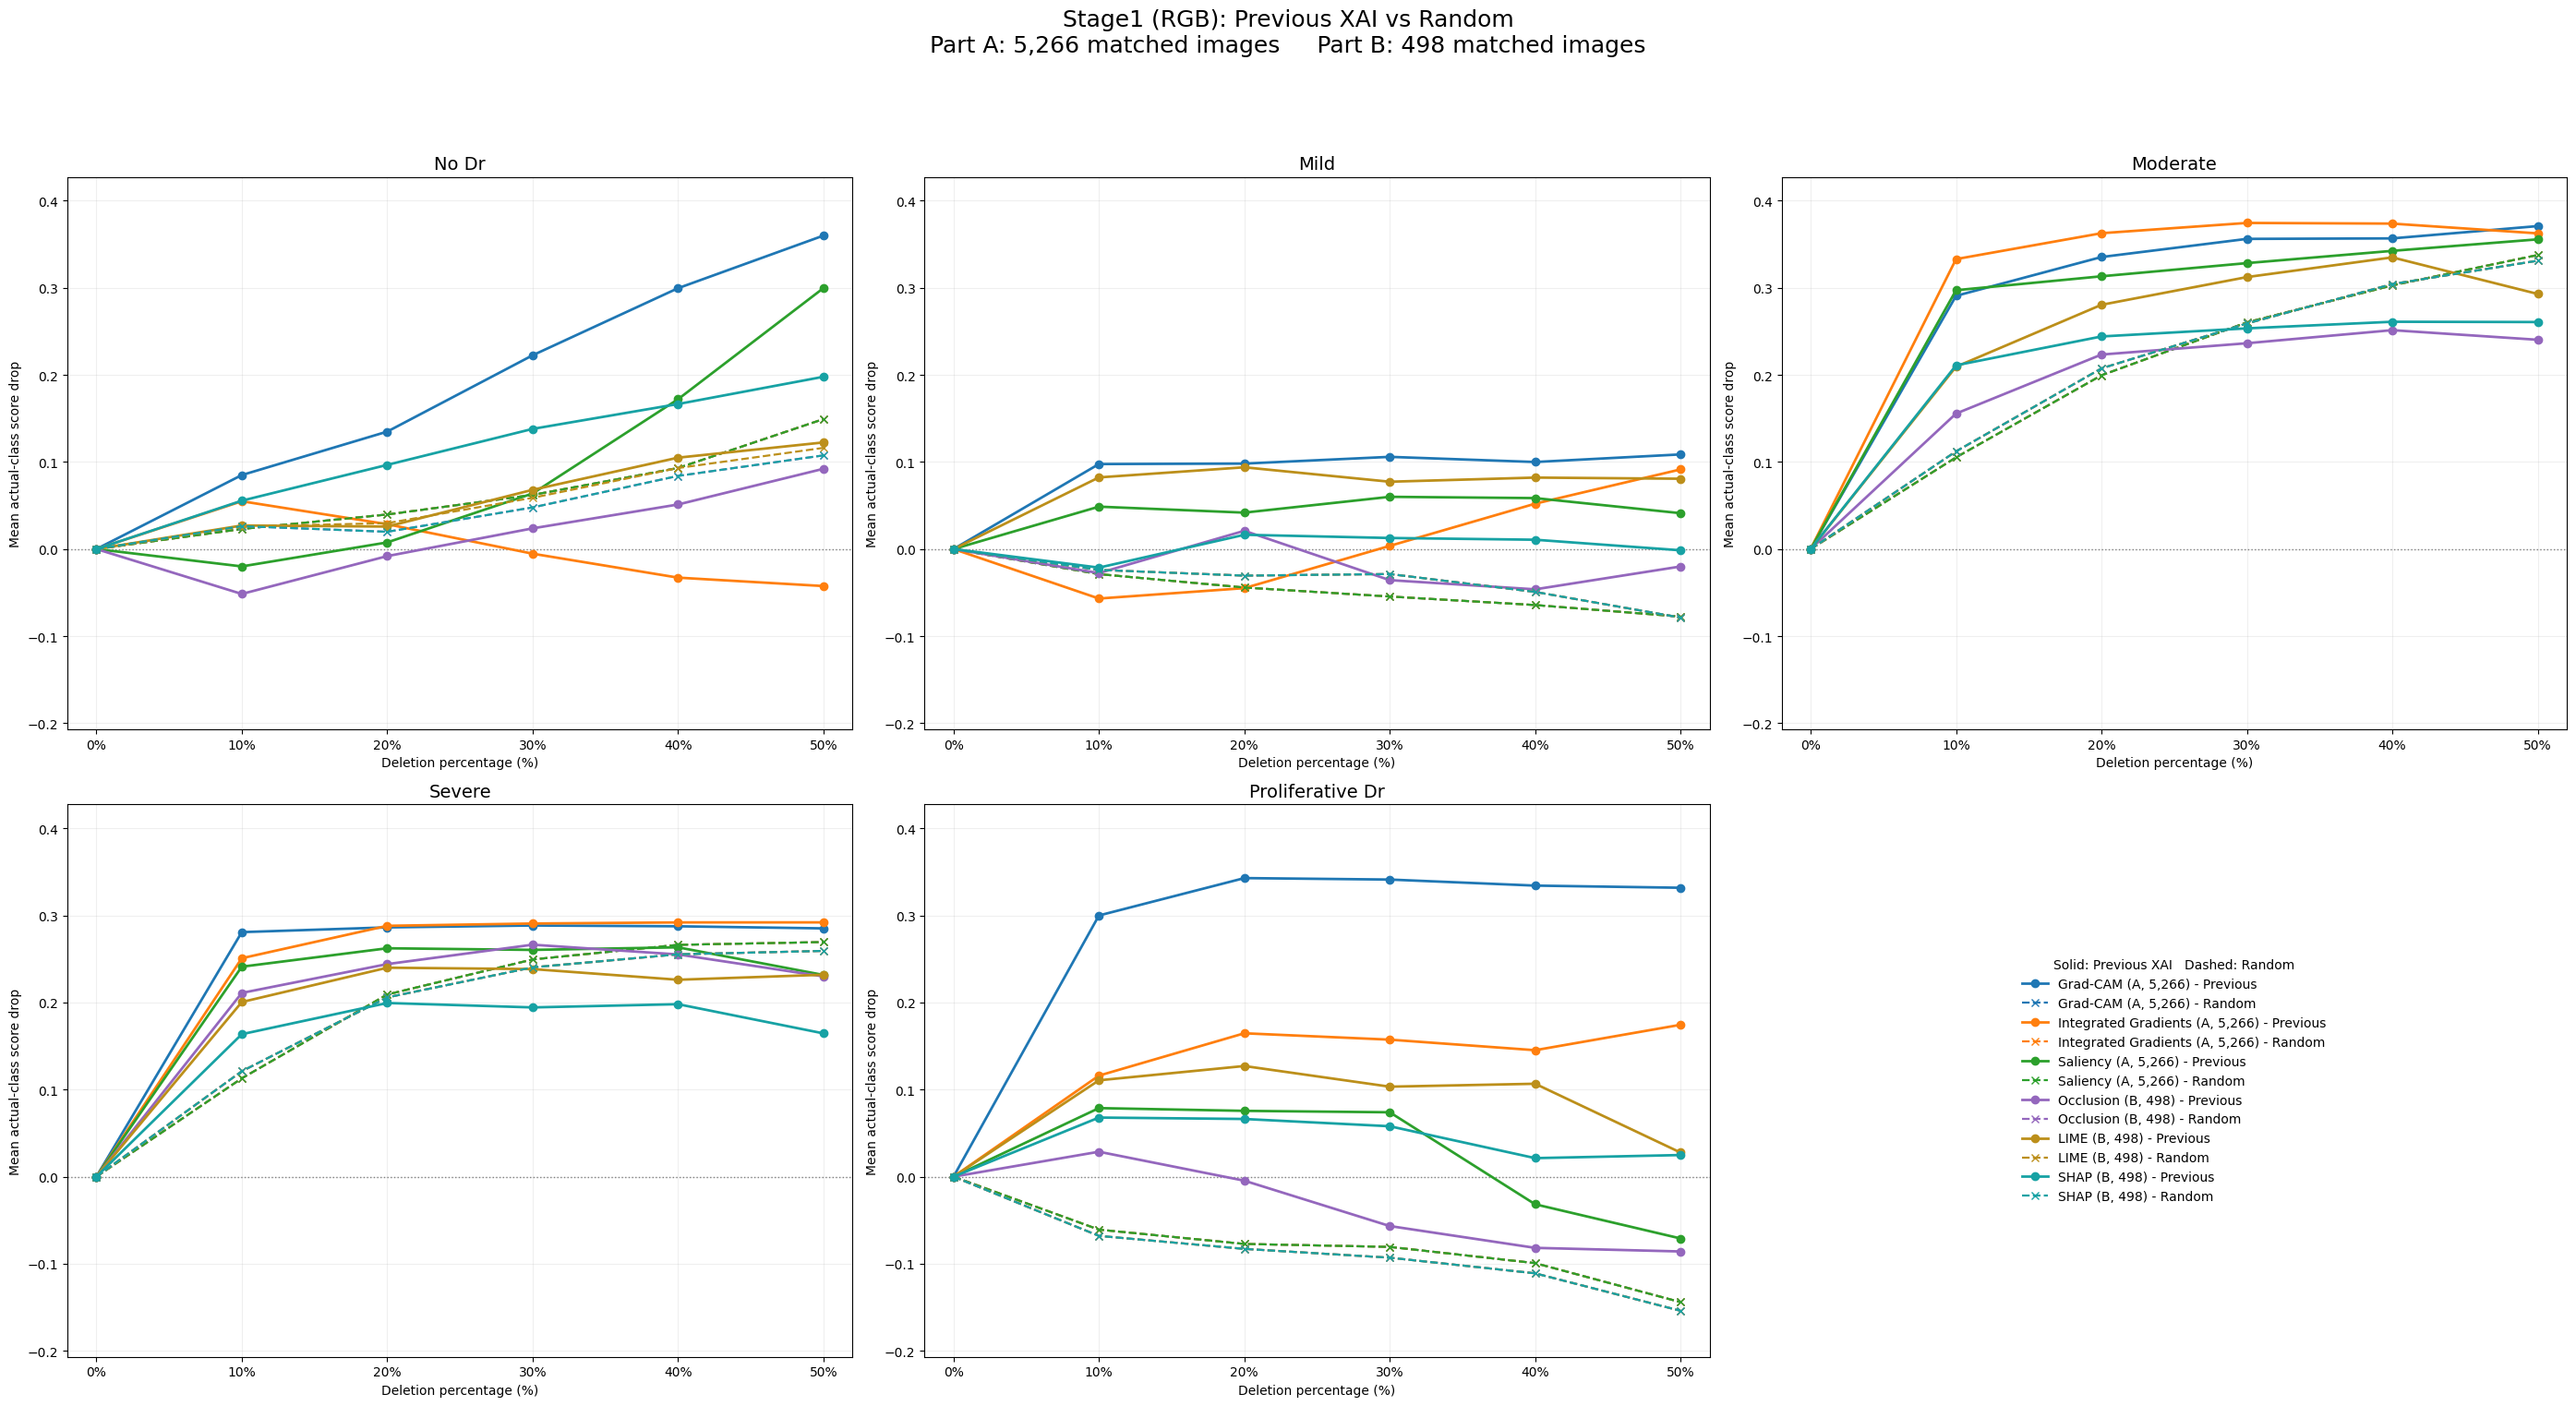

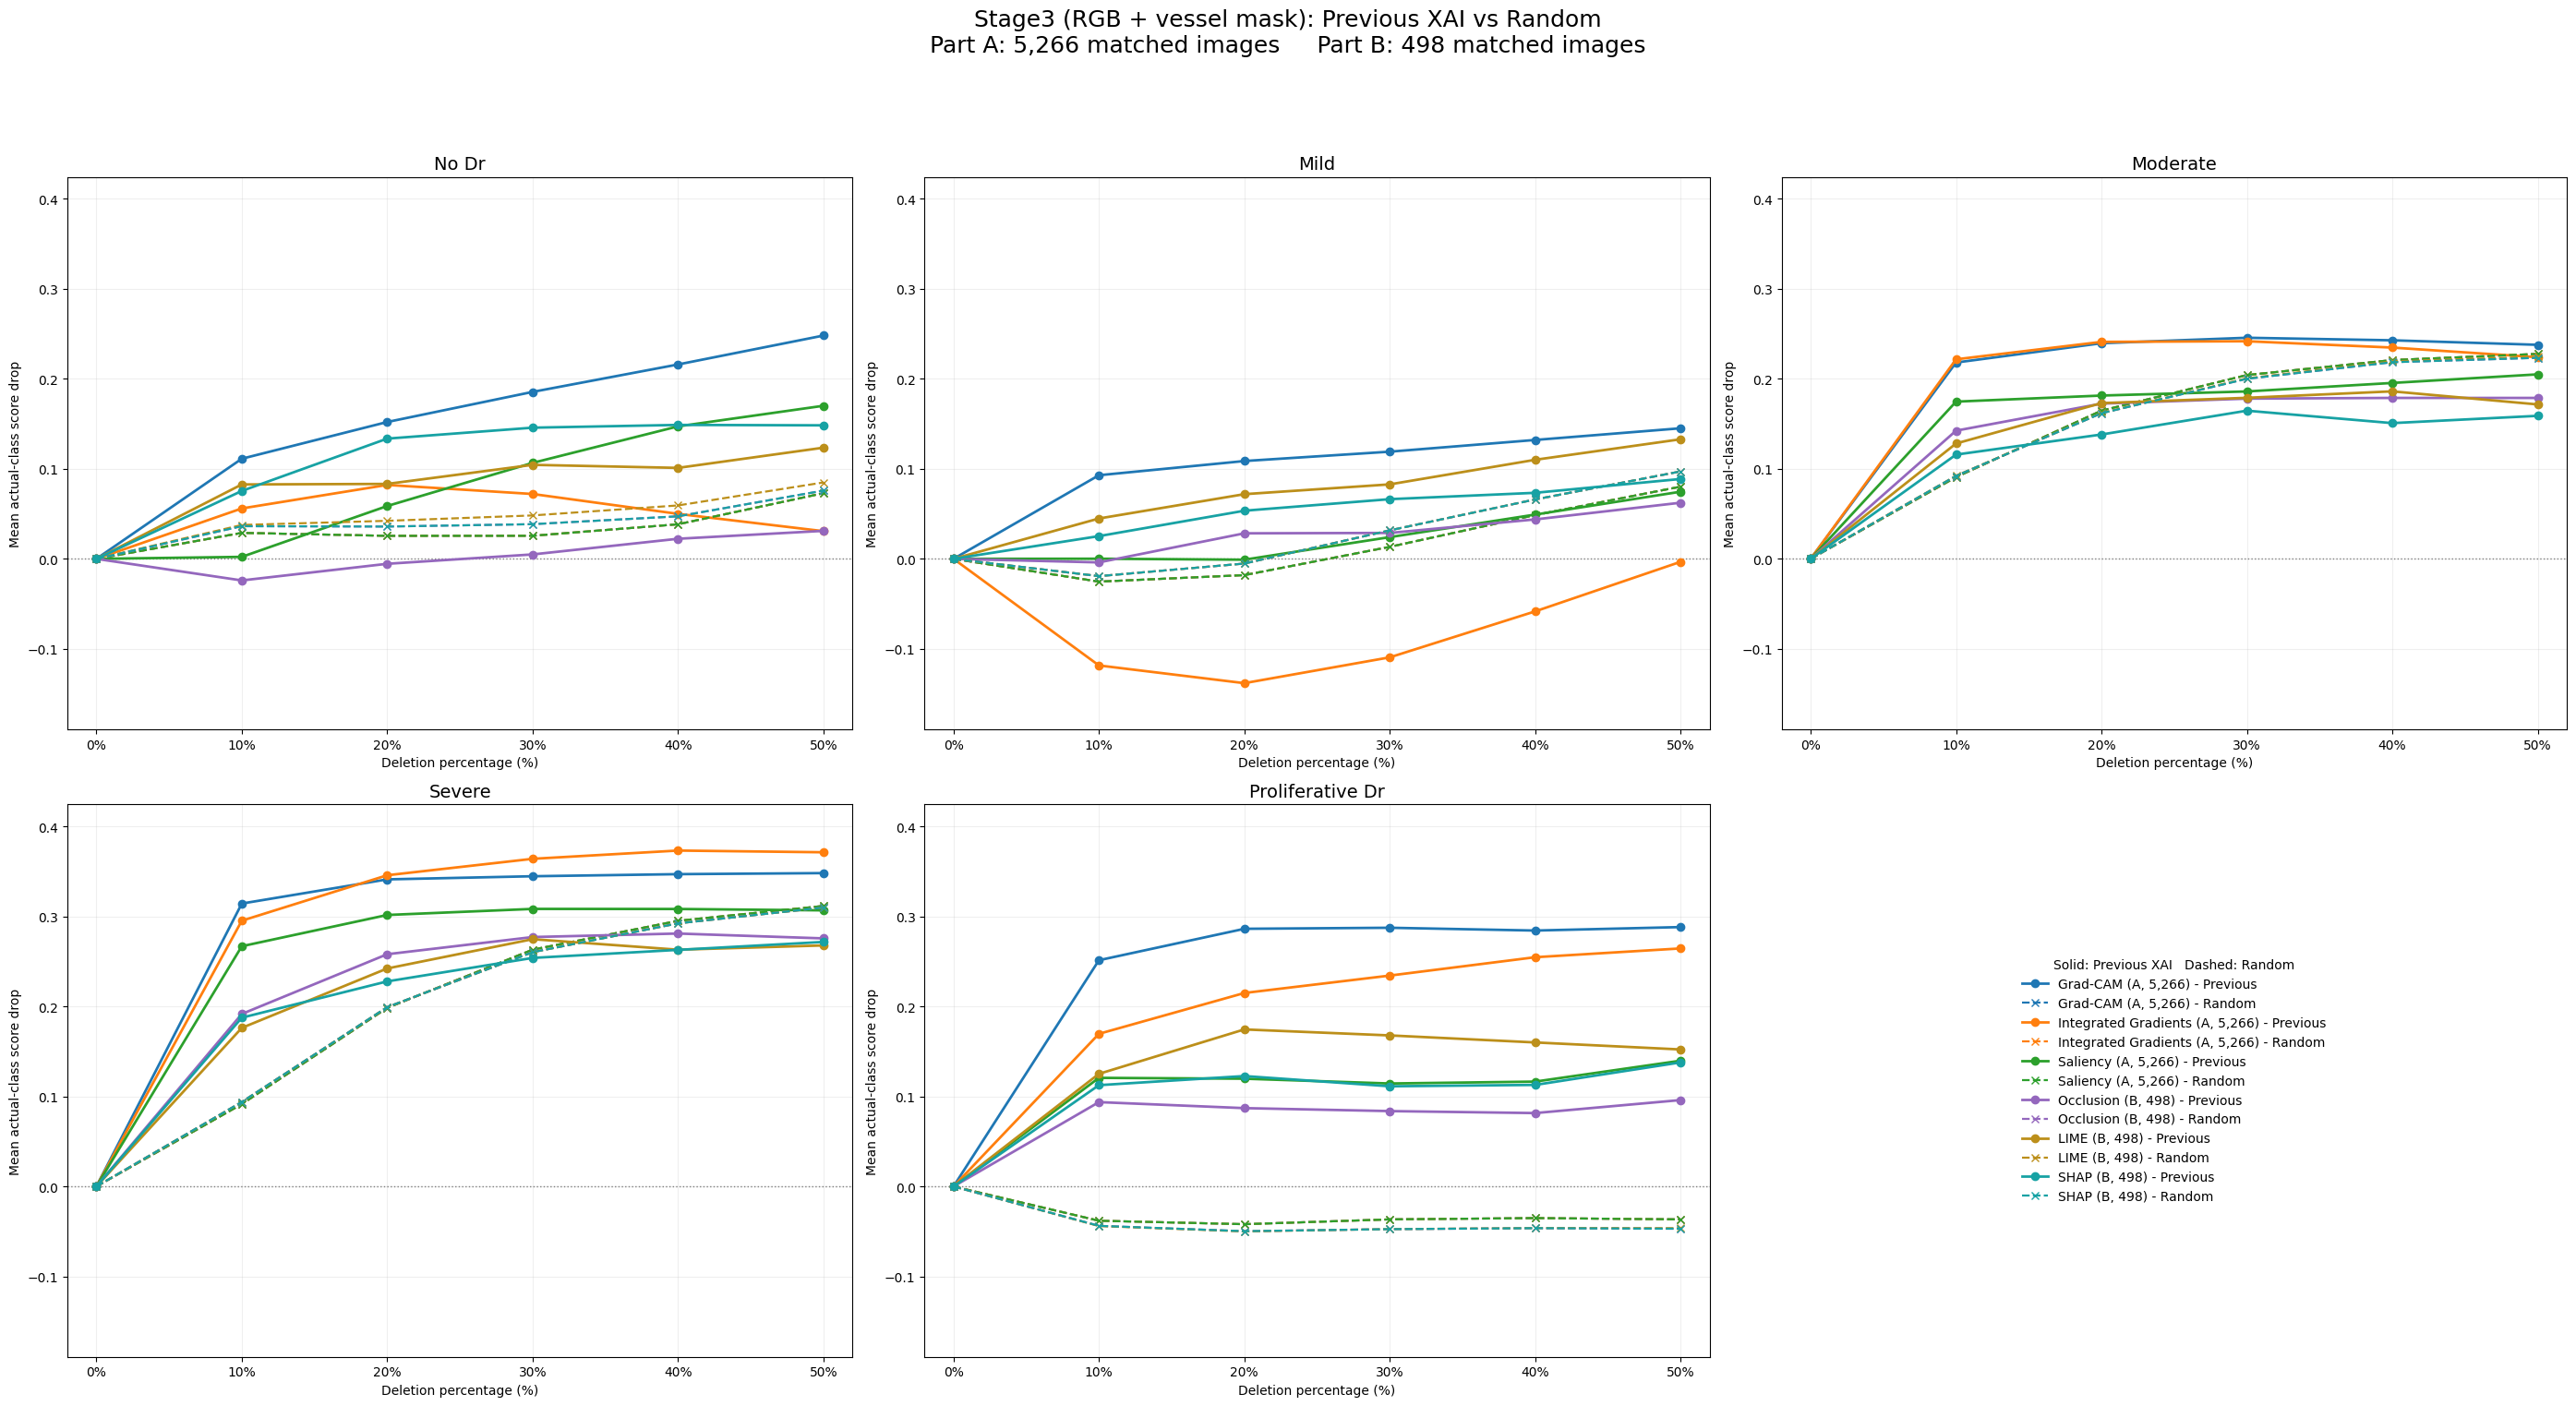

In [50]:
import os
import pandas as pd

required = [
    "rc_rows_path", "rc_expected_keys", "rc_keys", "rc_by_image",
    "rc_all_df", "rc_fail_path", "rc_repeats", "rc_columns_out",
]
missing_variables = [name for name in required if name not in globals()]
if missing_variables:
    raise RuntimeError(
        "Run the Random setup and functions cells first: " + ", ".join(missing_variables)
    )


rc_excluded_ids = set(rc_excluded_ids) | {"11697_right"}
rc_expected_keys = {key for key in rc_expected_keys if key[1] not in rc_excluded_ids}
rc_expected_counts = {
    image_id: count for image_id, count in rc_expected_counts.items()
    if image_id not in rc_excluded_ids
}
rc_expected_n = {
    "PartA": rc_old_a.loc[~rc_old_a["image_id"].isin(rc_excluded_ids), "image_id"].nunique(),
    "PartB": rc_old_b.loc[~rc_old_b["image_id"].isin(rc_excluded_ids), "image_id"].nunique(),
}

if not os.path.isfile(rc_rows_path):
    raise FileNotFoundError("Saved random results not found: " + rc_rows_path)

saved_random = pd.read_csv(rc_rows_path)
saved_random["image_id"] = saved_random["image_id"].astype(str)
saved_random = saved_random.drop_duplicates(rc_keys, keep="last")
stored_keys = set(map(tuple, saved_random[rc_keys].itertuples(index=False, name=None)))
unexpected_keys = stored_keys - rc_expected_keys
if unexpected_keys:
    raise RuntimeError(
        f"Unexpected saved rows: {len(unexpected_keys)}. Do not change the saved CSV."
    )

missing_keys = rc_expected_keys - stored_keys
missing_image_ids = sorted({key[1] for key in missing_keys})
print(f"Saved matching rows: {len(stored_keys)}/{len(rc_expected_keys)}")
print(f"Missing image IDs ({len(missing_image_ids)}): {missing_image_ids}")

if os.path.isfile(rc_fail_path):
    recorded_failures = pd.read_csv(rc_fail_path)
    #print("\nRecorded failure details:")
    #print(recorded_failures.to_string(index=False))
else:
    recorded_failures = pd.DataFrame(columns=["image_id", "reason"])
    print("\nNo previous failure file was found.")

if missing_keys:
    missing_table = pd.DataFrame(sorted(missing_keys), columns=rc_keys)
    #print("\nMissing rows by image and experiment:")
    #print(missing_table.groupby(["image_id", "scope", "stage"], sort=True).size().to_string())
else:
    print("\nThere are no missing rows. ")




import numpy as np
import matplotlib.pyplot as plt
if missing_keys:
    raise RuntimeError("Saved random results remain incomplete after exclusions; no repair will be attempted.")


rc_result = pd.read_csv(rc_rows_path).drop_duplicates(rc_keys, keep="last")
rc_result["image_id"] = rc_result["image_id"].astype(str)
rc_result = rc_result.loc[~rc_result["image_id"].isin(rc_excluded_ids)].copy()
rc_result_keys = set(map(tuple, rc_result[rc_keys].itertuples(index=False, name=None)))
if rc_result_keys != rc_expected_keys:
    remaining = rc_expected_keys - rc_result_keys
    raise RuntimeError(
        f"Random comparison is still incomplete: {len(remaining)} rows missing "
        f"for {sorted({key[1] for key in remaining})}."
    )


check_cols = [
    "base_prediction_score", "original_xai_drop", "random_mean_drop",
    "xai_minus_random", "rgb_deleted_pixels", "mask_deleted_pixels"
]
if not np.isfinite(rc_result[check_cols].to_numpy(dtype=float)).all():
    raise RuntimeError("A saved random comparison contains NaN or infinity.")



rc_result["previous_larger"] = (rc_result["xai_minus_random"] > 0).astype(float)
rc_class_summary = rc_result.groupby(
    ["scope", "stage", "method", "actual_label", "actual_class", "deletion_percent"],
    as_index=False
).agg(
    n_images=("image_id", "nunique"),
    xai_mean_drop=("original_xai_drop", "mean"),
    random_mean_drop=("random_mean_drop", "mean"),
    xai_minus_random=("xai_minus_random", "mean"),
    fraction_images_xai_larger=("previous_larger", "mean"),
)
rc_overall_summary = rc_result.groupby(
    ["scope", "stage", "method", "deletion_percent"], as_index=False
).agg(
    n_images=("image_id", "nunique"),
    xai_mean_drop=("original_xai_drop", "mean"),
    random_mean_drop=("random_mean_drop", "mean"),
    xai_minus_random=("xai_minus_random", "mean"),
    fraction_images_xai_larger=("previous_larger", "mean"),
)
rc_class_summary.to_csv(rc_class_path, index=False)
rc_overall_summary.to_csv(rc_overall_path, index=False)


print(f"Random control uses {len(rc_result_keys)}/{len(rc_expected_keys)} existing saved rows.")
print("Part A images:", rc_result.loc[rc_result["scope"] == "PartA", "image_id"].nunique())
print("Part B images:", rc_result.loc[rc_result["scope"] == "PartB", "image_id"].nunique())
print("Saved summary files:", rc_class_path, rc_overall_path, sep="\n")


if not os.path.isfile(rc_class_path) or not os.path.isfile(rc_overall_path):
    raise FileNotFoundError("the random deletion comparisons.")
rc_class_table = pd.read_csv(rc_class_path)
rc_overall_table = pd.read_csv(rc_overall_path)

rc_methods = (
    ("GradCAM", "Grad-CAM", "PartA"),
    ("IntegratedGradients", "Integrated Gradients", "PartA"),
    ("Saliency", "Saliency", "PartA"),
    ("Occlusion", "Occlusion", "PartB"),
    ("LIME", "LIME", "PartB"),
    ("SHAP", "SHAP", "PartB"),
)
rc_colors = {
    "GradCAM": "#1f77b4", "IntegratedGradients": "#ff7f0e",
    "Saliency": "#2ca02c", "Occlusion": "#9467bd",
    "LIME": "#bc8f1a", "SHAP": "#17a2a4"
}
rc_plot_dir = os.path.join(rc_out, "ALL_SIX_previous_vs_random_plots")
os.makedirs(rc_plot_dir, exist_ok=True)


for stage in ("Stage1", "Stage3"):
    for method, name, scope in rc_methods:
        overall_rows = rc_overall_table[
            (rc_overall_table["stage"] == stage) &
            (rc_overall_table["method"] == method) &
            (rc_overall_table["scope"] == scope)
        ].sort_values("deletion_percent")
        if overall_rows["deletion_percent"].tolist() != list(rc_levels):
            raise RuntimeError(f"Missing previous/random scores for {stage} and {name}.")
        count = int(rc_expected_n[scope])
        if not (overall_rows["n_images"].astype(int) == count).all():
            raise RuntimeError(f"Wrong image count for {stage} and {name}.")
        for severity in range(5):
            class_rows = rc_class_table[
                (rc_class_table["stage"] == stage) &
                (rc_class_table["method"] == method) &
                (rc_class_table["scope"] == scope) &
                (rc_class_table["actual_label"].astype(int) == severity)
            ].sort_values("deletion_percent")
            if class_rows["deletion_percent"].tolist() != list(rc_levels):
                raise RuntimeError(f"Missing {name} results for severity {severity}.")
            original_ids = rc_old_a if scope == "PartA" else rc_old_b
            expected_class_n = original_ids.loc[
                (original_ids["actual_label"].astype(int) == severity)
                & (~original_ids["image_id"].isin(rc_excluded_ids)), "image_id"
            ].nunique()
            if not (class_rows["n_images"].astype(int) == expected_class_n).all():
                raise RuntimeError(f"Incorrect number of matched images for {name}, severity {severity}.")

for frame in (rc_class_table, rc_overall_table):
    values = frame[["xai_mean_drop", "random_mean_drop", "xai_minus_random"]].to_numpy(float)
    if not np.isfinite(values).all() or not np.allclose(values[:, 0] - values[:, 1], values[:, 2], atol=1e-6):
        raise RuntimeError("The comparison scores are invalid or do not agree.")

# Only these final comparison tables are shown; earlier XAI tables stay saved in Drive.
for stage in ("Stage1", "Stage3"):
    table_rows = []
    for method, name, scope in rc_methods:
        matching = rc_overall_table[
            (rc_overall_table["stage"] == stage) &
            (rc_overall_table["method"] == method) &
            (rc_overall_table["scope"] == scope)
        ].sort_values("deletion_percent")
        for r in matching.itertuples(index=False):
            table_rows.append({
                "Part": scope, "XAI Method": name, "Images": int(r.n_images),
                "Deletion (%)": int(r.deletion_percent),
                "Previous XAI Drop": float(r.xai_mean_drop),
                "Random Drop": float(r.random_mean_drop),
                "Previous - Random": float(r.xai_minus_random),
            })
    final_table = pd.DataFrame(table_rows)
    final_table.to_csv(os.path.join(rc_plot_dir, f"{stage}_previous_vs_random.csv"), index=False)
    print(f"\n{stage}: Previous XAI vs Random")
    display(final_table.round(4))


# A solid line means the earlier XAI deletion; a dashed line means random deletion.
for stage in ("Stage1", "Stage3"):
    stage_rows = rc_class_table[rc_class_table["stage"] == stage]
    plotted = np.r_[0.0, stage_rows["xai_mean_drop"].to_numpy(float),
                    stage_rows["random_mean_drop"].to_numpy(float)]
    low, high = float(plotted.min()), float(plotted.max())
    space = max(0.02, (high - low) * 0.10)

    fig, axes = plt.subplots(2, 3, figsize=(28, 15.5))
    axes = axes.ravel()
    legend_handles, legend_labels = [], []

    for severity in range(5):
        ax = axes[severity]
        ax.axhline(0, color="gray", linestyle=":", linewidth=1)
        for method, name, scope in rc_methods:
            matching = rc_class_table[
                (rc_class_table["stage"] == stage) &
                (rc_class_table["method"] == method) &
                (rc_class_table["scope"] == scope) &
                (rc_class_table["actual_label"].astype(int) == severity)
            ].sort_values("deletion_percent")
            x = np.array([0, *rc_levels], dtype=float)
            original_y = np.r_[0.0, matching["xai_mean_drop"].to_numpy(float)]
            random_y = np.r_[0.0, matching["random_mean_drop"].to_numpy(float)]
            color = rc_colors[method]
            solid, = ax.plot(x, original_y, color=color, linestyle="-", marker="o", linewidth=2)
            dashed, = ax.plot(x, random_y, color=color, linestyle="--", marker="x", linewidth=1.6)
            if severity == 0:
                group_name = f"A, {rc_expected_n['PartA']:,}" if scope == "PartA" else f"B, {rc_expected_n['PartB']:,}"
                legend_handles.extend((solid, dashed))
                legend_labels.extend((f"{name} ({group_name}) - Previous", f"{name} ({group_name}) - Random"))

        ax.set_title(str(CLASS_NAMES[severity]).replace("_", " ").title(), fontsize=14)
        ax.set_xticks([0, *rc_levels])
        ax.set_xticklabels(["0%", "10%", "20%", "30%", "40%", "50%"])
        ax.set_xlim(-2, 52)
        ax.set_ylim(low - space, high + space)
        ax.set_xlabel("Deletion percentage (%)")
        ax.set_ylabel("Mean actual-class score drop")
        ax.grid(True, alpha=0.2)

    axes[5].axis("off")
    axes[5].legend(legend_handles, legend_labels, loc="center", frameon=False,
                   fontsize=10, title="Solid: Previous XAI   Dashed: Random")
    input_name = "RGB" if stage == "Stage1" else "RGB + vessel mask"
    fig.suptitle(f"{stage} ({input_name}): Previous XAI vs Random\n"
                 f"Part A: {rc_expected_n['PartA']:,} matched images     "
                 f"Part B: {rc_expected_n['PartB']:,} matched images", fontsize=18)
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    fig.savefig(os.path.join(rc_plot_dir, f"{stage}_previous_vs_random.png"),
                dpi=230, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


Stage1: Previous XAI vs Random


,Part,XAI Method,Images,Deletion (%),Previous XAI Drop,Random Drop,Previous - Random
0,PartA,Grad-CAM,5266,10,0.1260,0.0324,0.0936
1,PartA,Grad-CAM,5266,20,0.1704,0.0598,0.1106
2,PartA,Grad-CAM,5266,30,0.2386,0.0857,0.1529
3,PartA,Grad-CAM,5266,40,0.2947,0.1142,0.1805
4,PartA,Grad-CAM,5266,50,0.3417,0.1590,0.1828
5,PartA,Integrated Gradients,5266,10,0.0951,0.0324,0.0627
6,PartA,Integrated Gradients,5266,20,0.0829,0.0598,0.0232
7,PartA,Integrated Gradients,5266,30,0.0631,0.0857,-0.0226
8,PartA,Integrated Gradients,5266,40,0.0459,0.1142,-0.0682
9,PartA,Integrated Gradients,5266,50,0.0405,0.1590,-0.1185



Stage3: Previous XAI vs Random


,Part,XAI Method,Images,Deletion (%),Previous XAI Drop,Random Drop,Previous - Random
0,PartA,Grad-CAM,5266,10,0.1339,0.0346,0.0992
1,PartA,Grad-CAM,5266,20,0.1695,0.0464,0.1231
2,PartA,Grad-CAM,5266,30,0.1959,0.0563,0.1396
3,PartA,Grad-CAM,5266,40,0.2187,0.0715,0.1473
4,PartA,Grad-CAM,5266,50,0.2426,0.1005,0.1421
5,PartA,Integrated Gradients,5266,10,0.0771,0.0346,0.0424
6,PartA,Integrated Gradients,5266,20,0.1000,0.0464,0.0536
7,PartA,Integrated Gradients,5266,30,0.0955,0.0563,0.0392
8,PartA,Integrated Gradients,5266,40,0.0824,0.0715,0.0109
9,PartA,Integrated Gradients,5266,50,0.0706,0.1005,-0.0298


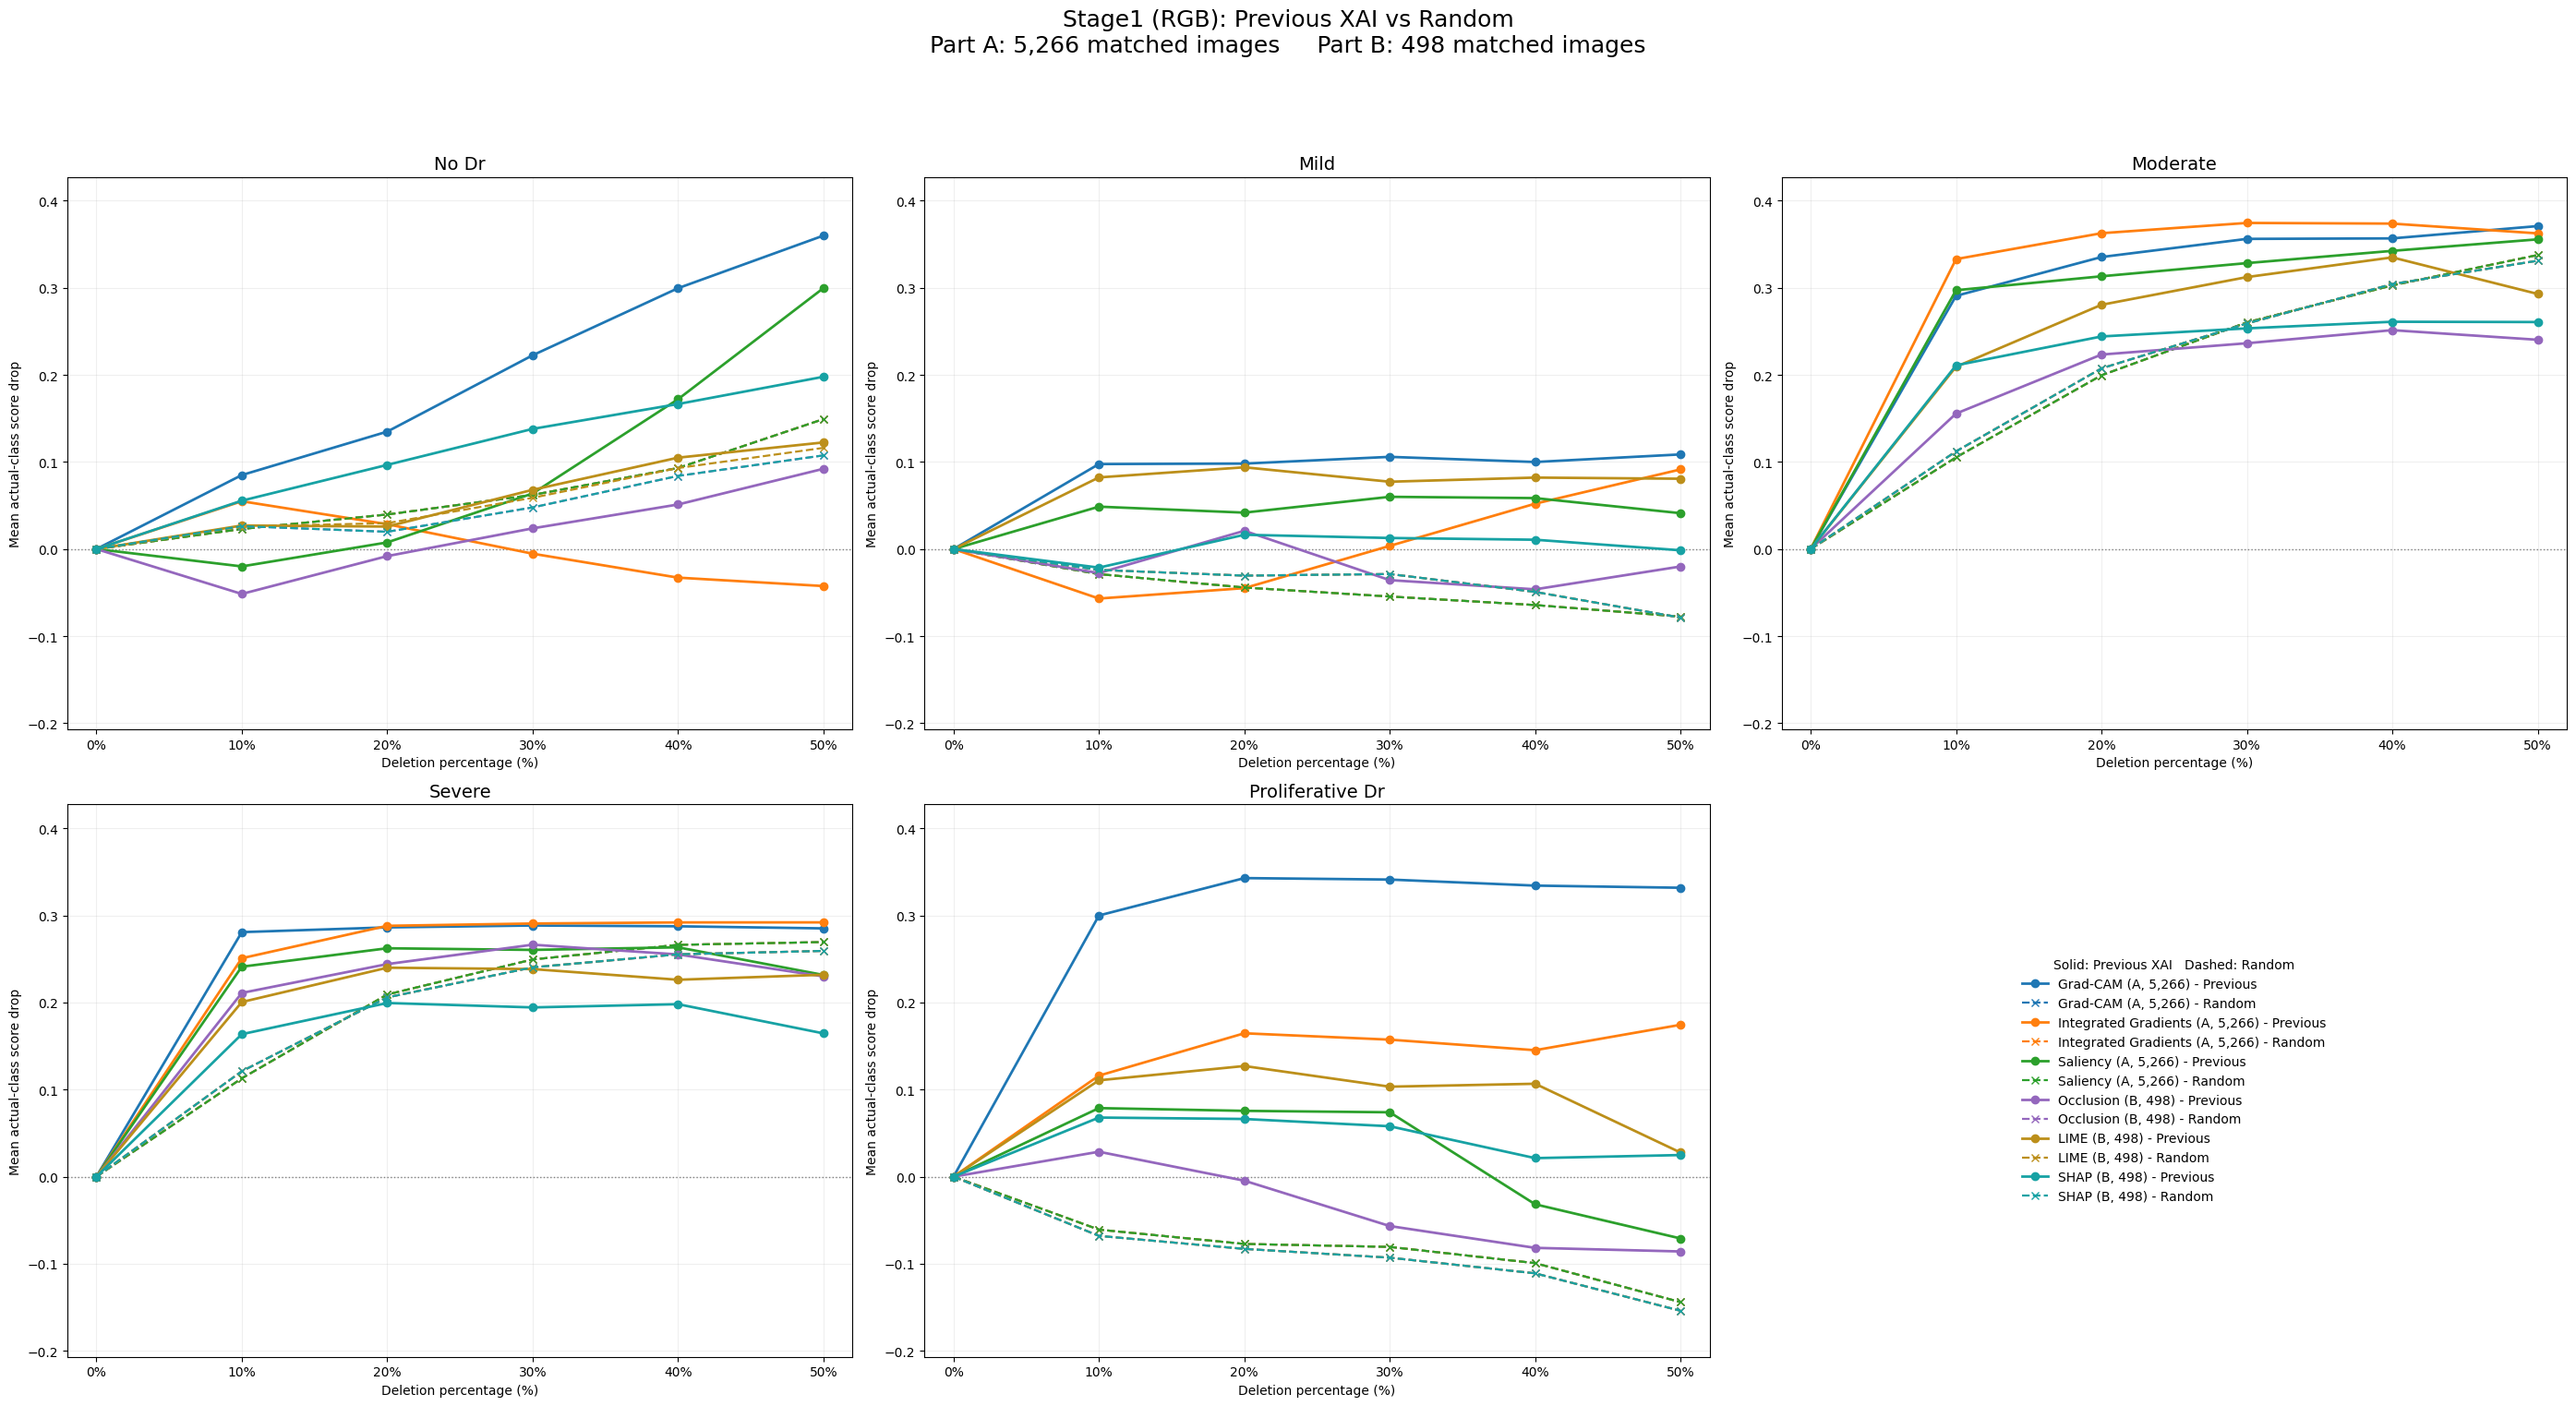

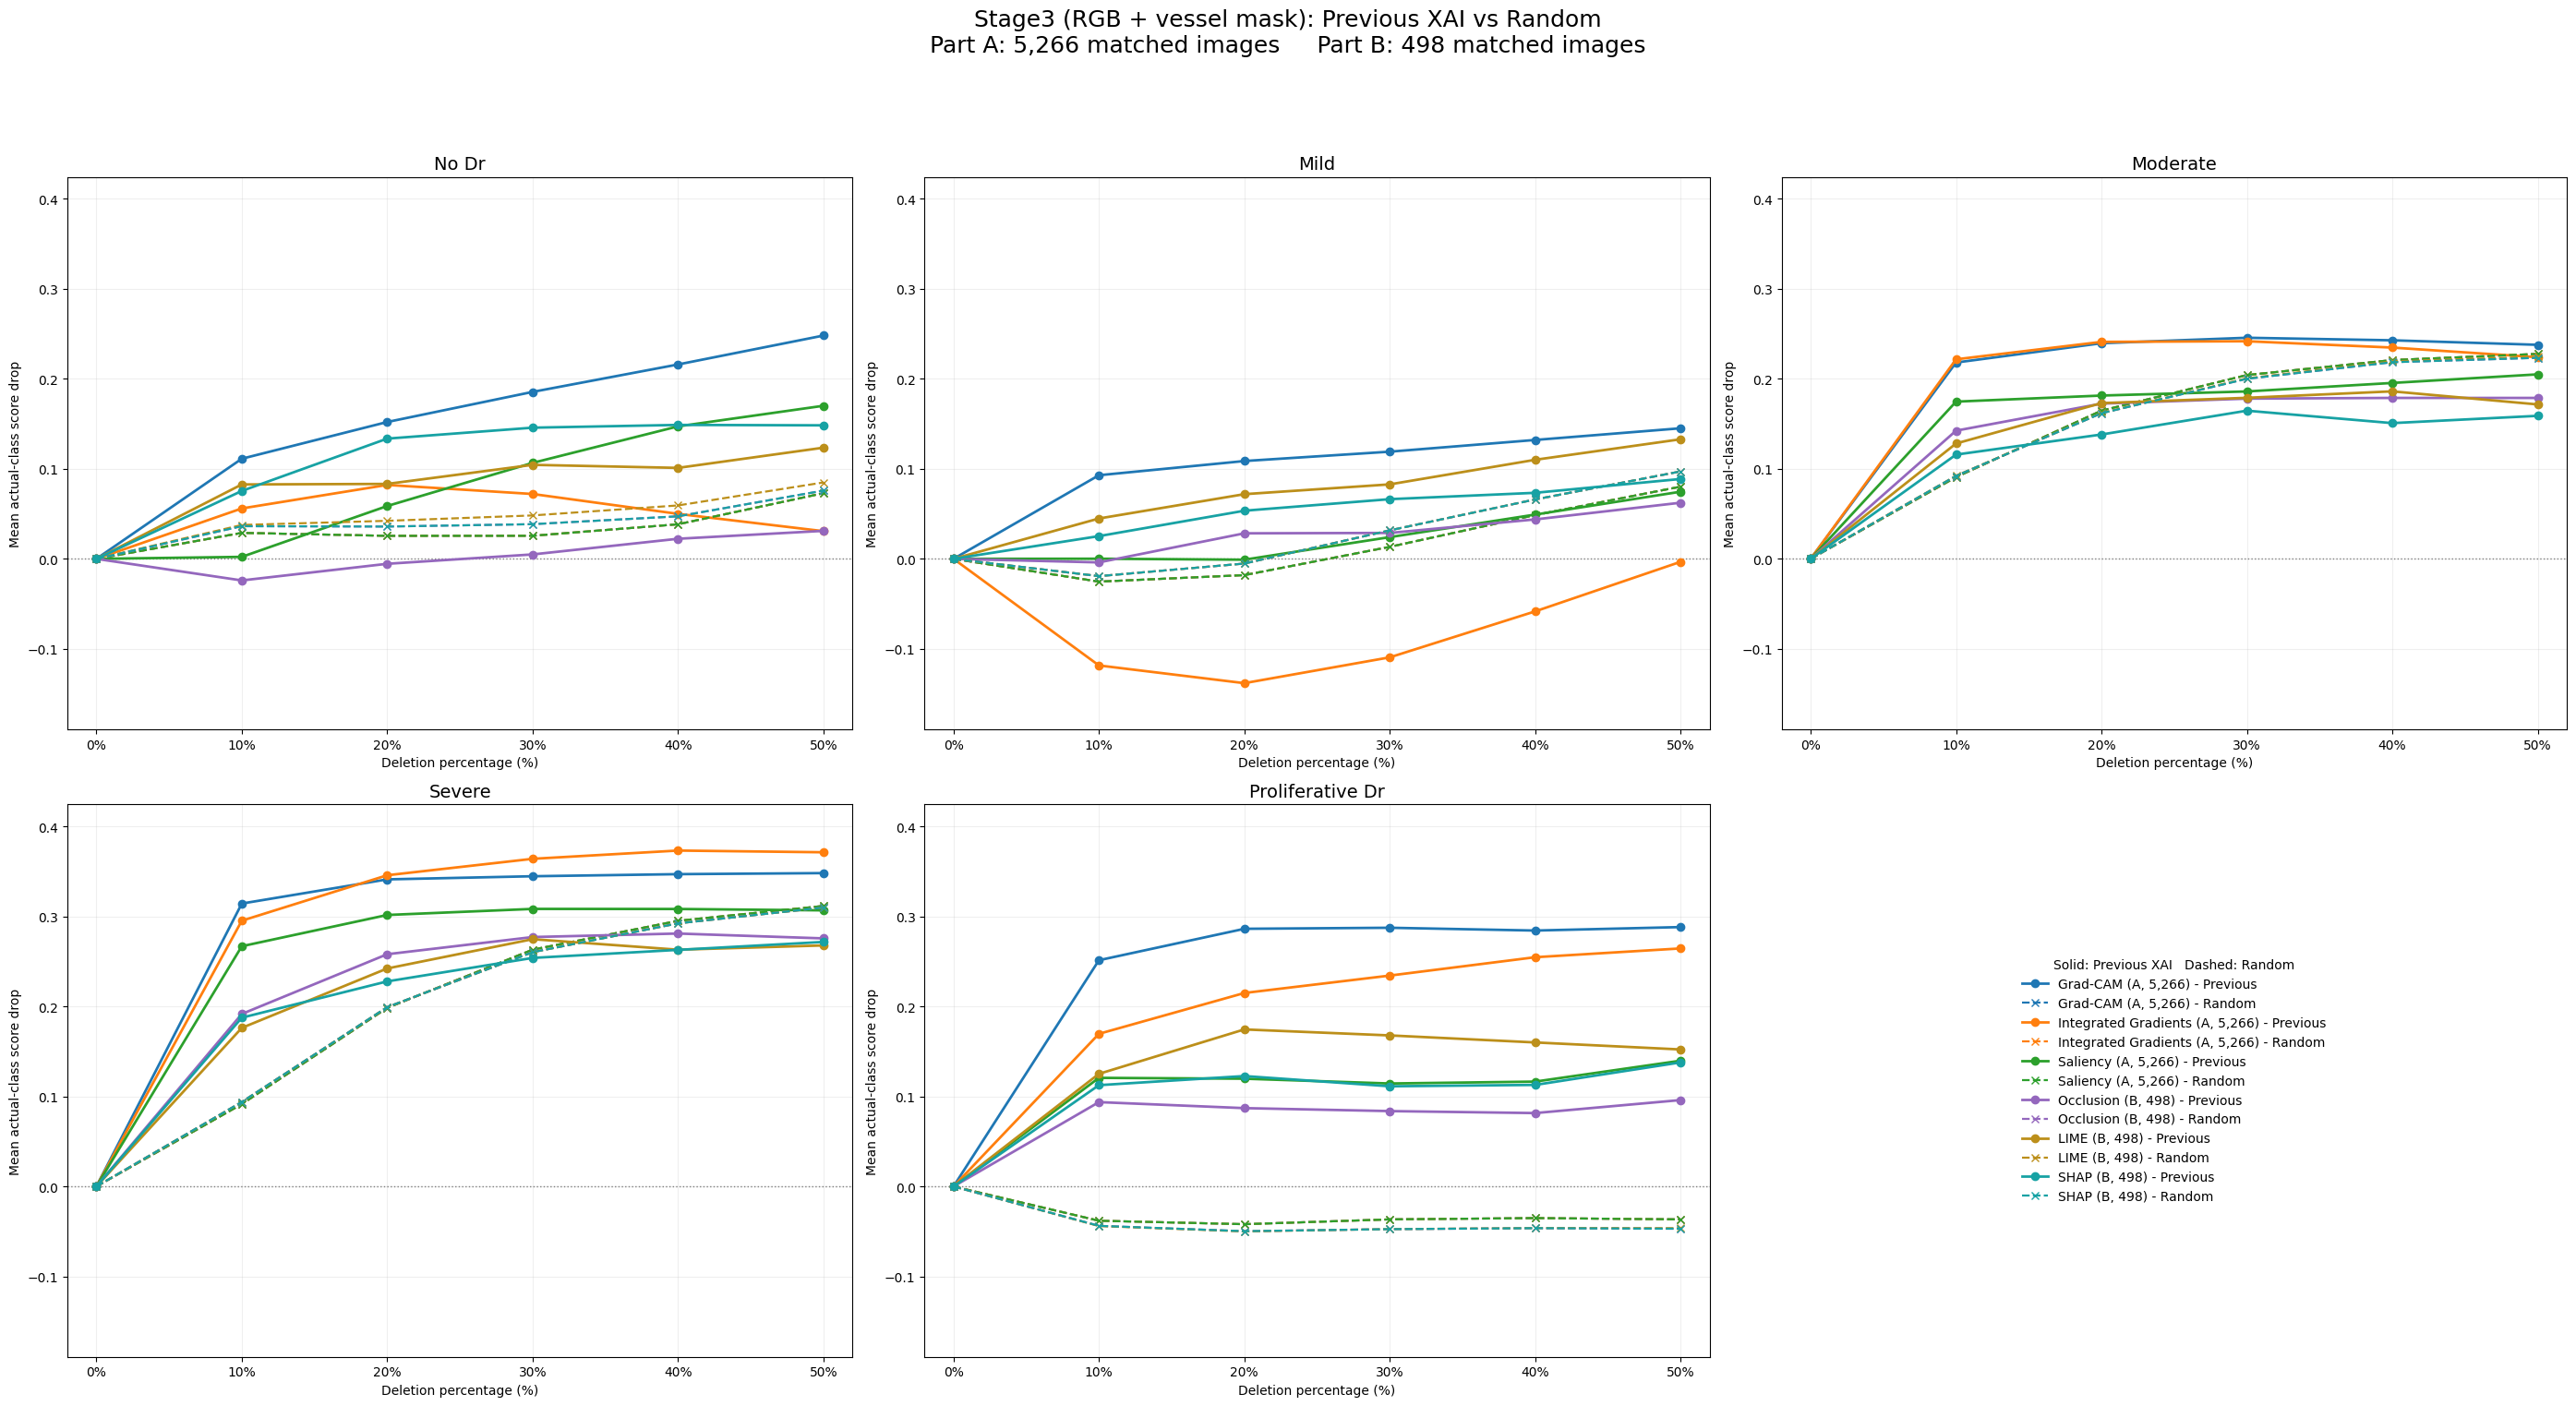

In [51]:
if not os.path.isfile(rc_class_path) or not os.path.isfile(rc_overall_path):
    raise FileNotFoundError("Finish the random deletion cell before comparisons.")
rc_class_table = pd.read_csv(rc_class_path)
rc_overall_table = pd.read_csv(rc_overall_path)

rc_methods = (
    ("GradCAM", "Grad-CAM", "PartA"),
    ("IntegratedGradients", "Integrated Gradients", "PartA"),
    ("Saliency", "Saliency", "PartA"),
    ("Occlusion", "Occlusion", "PartB"),
    ("LIME", "LIME", "PartB"),
    ("SHAP", "SHAP", "PartB"),
)
rc_colors = {
    "GradCAM": "#1f77b4", "IntegratedGradients": "#ff7f0e",
    "Saliency": "#2ca02c", "Occlusion": "#9467bd",
    "LIME": "#bc8f1a", "SHAP": "#17a2a4"
}
rc_plot_dir = os.path.join(rc_out, "ALL_SIX_previous_vs_random_plots")
os.makedirs(rc_plot_dir, exist_ok=True)


for stage in ("Stage1", "Stage3"):
    for method, name, scope in rc_methods:
        overall_rows = rc_overall_table[
            (rc_overall_table["stage"] == stage) &
            (rc_overall_table["method"] == method) &
            (rc_overall_table["scope"] == scope)
        ].sort_values("deletion_percent")
        if overall_rows["deletion_percent"].tolist() != list(rc_levels):
            raise RuntimeError(f"Missing previous/random scores for {stage} and {name}.")
        count = int(rc_expected_n[scope])
        if not (overall_rows["n_images"].astype(int) == count).all():
            raise RuntimeError(f"Wrong image count for {stage} and {name}.")
        for severity in range(5):
            class_rows = rc_class_table[
                (rc_class_table["stage"] == stage) &
                (rc_class_table["method"] == method) &
                (rc_class_table["scope"] == scope) &
                (rc_class_table["actual_label"].astype(int) == severity)
            ].sort_values("deletion_percent")
            if class_rows["deletion_percent"].tolist() != list(rc_levels):
                raise RuntimeError(f"Missing {name} results for severity {severity}.")
            original_ids = rc_old_a if scope == "PartA" else rc_old_b
            expected_class_n = original_ids.loc[
                (original_ids["actual_label"].astype(int) == severity)
                & (~original_ids["image_id"].isin(rc_excluded_ids)), "image_id"
            ].nunique()
            if not (class_rows["n_images"].astype(int) == expected_class_n).all():
                raise RuntimeError(f"Incorrect number of matched images for {name}, severity {severity}.")

for frame in (rc_class_table, rc_overall_table):
    values = frame[["xai_mean_drop", "random_mean_drop", "xai_minus_random"]].to_numpy(float)
    if not np.isfinite(values).all() or not np.allclose(values[:, 0] - values[:, 1], values[:, 2], atol=1e-6):
        raise RuntimeError("The comparison scores are invalid or do not agree.")

# Only these final comparison tables are shown; earlier XAI tables stay saved in Drive.
for stage in ("Stage1", "Stage3"):
    table_rows = []
    for method, name, scope in rc_methods:
        matching = rc_overall_table[
            (rc_overall_table["stage"] == stage) &
            (rc_overall_table["method"] == method) &
            (rc_overall_table["scope"] == scope)
        ].sort_values("deletion_percent")
        for r in matching.itertuples(index=False):
            table_rows.append({
                "Part": scope, "XAI Method": name, "Images": int(r.n_images),
                "Deletion (%)": int(r.deletion_percent),
                "Previous XAI Drop": float(r.xai_mean_drop),
                "Random Drop": float(r.random_mean_drop),
                "Previous - Random": float(r.xai_minus_random),
            })
    final_table = pd.DataFrame(table_rows)
    final_table.to_csv(os.path.join(rc_plot_dir, f"{stage}_previous_vs_random.csv"), index=False)
    print(f"\n{stage}: Previous XAI vs Random")
    display(final_table.round(4))


# A solid line means the earlier XAI deletion; a dashed line means random deletion.
for stage in ("Stage1", "Stage3"):
    stage_rows = rc_class_table[rc_class_table["stage"] == stage]
    plotted = np.r_[0.0, stage_rows["xai_mean_drop"].to_numpy(float),
                    stage_rows["random_mean_drop"].to_numpy(float)]
    low, high = float(plotted.min()), float(plotted.max())
    space = max(0.02, (high - low) * 0.10)

    fig, axes = plt.subplots(2, 3, figsize=(28, 15.5))
    axes = axes.ravel()
    legend_handles, legend_labels = [], []

    for severity in range(5):
        ax = axes[severity]
        ax.axhline(0, color="gray", linestyle=":", linewidth=1)
        for method, name, scope in rc_methods:
            matching = rc_class_table[
                (rc_class_table["stage"] == stage) &
                (rc_class_table["method"] == method) &
                (rc_class_table["scope"] == scope) &
                (rc_class_table["actual_label"].astype(int) == severity)
            ].sort_values("deletion_percent")
            x = np.array([0, *rc_levels], dtype=float)
            original_y = np.r_[0.0, matching["xai_mean_drop"].to_numpy(float)]
            random_y = np.r_[0.0, matching["random_mean_drop"].to_numpy(float)]
            color = rc_colors[method]
            solid, = ax.plot(x, original_y, color=color, linestyle="-", marker="o", linewidth=2)
            dashed, = ax.plot(x, random_y, color=color, linestyle="--", marker="x", linewidth=1.6)
            if severity == 0:
                group_name = f"A, {rc_expected_n['PartA']:,}" if scope == "PartA" else f"B, {rc_expected_n['PartB']:,}"
                legend_handles.extend((solid, dashed))
                legend_labels.extend((f"{name} ({group_name}) - Previous", f"{name} ({group_name}) - Random"))

        ax.set_title(str(CLASS_NAMES[severity]).replace("_", " ").title(), fontsize=14)
        ax.set_xticks([0, *rc_levels])
        ax.set_xticklabels(["0%", "10%", "20%", "30%", "40%", "50%"])
        ax.set_xlim(-2, 52)
        ax.set_ylim(low - space, high + space)
        ax.set_xlabel("Deletion percentage (%)")
        ax.set_ylabel("Mean actual-class score drop")
        ax.grid(True, alpha=0.2)

    axes[5].axis("off")
    axes[5].legend(legend_handles, legend_labels, loc="center", frameon=False,
                   fontsize=10, title="Solid: Previous XAI   Dashed: Random")
    input_name = "RGB" if stage == "Stage1" else "RGB + vessel mask"
    fig.suptitle(f"{stage} ({input_name}): Previous XAI vs Random\n"
                 f"Part A: {rc_expected_n['PartA']:,} matched images     "
                 f"Part B: {rc_expected_n['PartB']:,} matched images", fontsize=18)
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    fig.savefig(os.path.join(rc_plot_dir, f"{stage}_previous_vs_random.png"),
                dpi=230, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


In [54]:
import os
import numpy as np
import pandas as pd
from IPython.display import display



if "rc_result" not in globals():
    raise RuntimeError(
        "Run the saved-results validation/summary cell first."
    )

one_data = rc_result.loc[
    ~rc_result["image_id"].astype(str).isin(rc_excluded_ids)
].copy()



expected_pairs = {
    (scope, stage, method, float(pct))
    for scope, methods in (
        ("PartA", rc_methods_a),
        ("PartB", rc_methods_b)
    )
    for stage in ("Stage1", "Stage3")
    for method in methods
    for pct in rc_levels
}

choices = []

for image_id, group in one_data.groupby("image_id", sort=True):

    found = set(zip(
        group["scope"],
        group["stage"],
        group["method"],
        group["deletion_percent"].astype(float)
    ))

    if not expected_pairs.issubset(found):
        continue

    severity = int(group["actual_label"].iloc[0])


    stage1_before = float(
        group.loc[
            group["stage"] == "Stage1",
            "base_prediction_score"
        ].mean()
    )

    stage3_before = float(
        group.loc[
            group["stage"] == "Stage3",
            "base_prediction_score"
        ].mean()
    )


    if stage3_before <= stage1_before:
        continue


    choices.append((
        0 if severity == 3 else 1,
        str(image_id),
        group
    ))

if not choices:
    raise RuntimeError(
        "No complete saved image was found where "
        "Stage 3 Before is higher than Stage 1 Before."
    )



_, selected_id, selected_group = min(
    choices,
    key=lambda v: (v[0], v[1])
)

severity = str(selected_group["actual_class"].iloc[0])

# Calculate scores specifically for the selected image.
selected_stage1_before = float(
    selected_group.loc[
        selected_group["stage"] == "Stage1",
        "base_prediction_score"
    ].mean()
)

selected_stage3_before = float(
    selected_group.loc[
        selected_group["stage"] == "Stage3",
        "base_prediction_score"
    ].mean()
)



method_labels = {
    "GradCAM": "Grad-CAM",
    "IntegratedGradients": "Integrated Gradients",
    "Saliency": "Saliency",
    "Occlusion": "Occlusion",
    "LIME": "LIME",
    "SHAP": "SHAP"
}



records = []

for stage in ("Stage1", "Stage3"):

    for method in (*rc_methods_a, *rc_methods_b):

        group = selected_group.loc[
            (selected_group["stage"] == stage) &
            (selected_group["method"] == method)
        ].sort_values("deletion_percent")

        for r in group.itertuples(index=False):

            before = float(r.base_prediction_score)
            xai_drop = float(r.original_xai_drop)
            random_drop = float(r.random_mean_drop)

            records.append({
                "Method": method_labels[method],
                "DR Severity": severity,
                "Image ID": selected_id,
                "Deletion (%)": int(r.deletion_percent),
                "Stage": stage,
                "Before": before,
                "After XAI": before - xai_drop,
                "XAI Drop": xai_drop,
                "After Random": before - random_drop,
                "Random Drop": random_drop,
                "XAI - Random": xai_drop - random_drop
            })

one_image_scores = pd.DataFrame(records)



output_path = os.path.join(
    rc_out,
    "one_image_stage1_stage3_xai_vs_random_scores.csv"
)

one_image_scores.to_csv(output_path, index=False)



print("=" * 90)
print("SELECTED IMAGE INFORMATION")
print("=" * 90)

print(f"Image ID: {selected_id}")
print(f"DR Severity: {severity}")
print(f"Stage 1 Before: {selected_stage1_before:.4f}")
print(f"Stage 3 Before: {selected_stage3_before:.4f}")
print(
    f"Stage 3 - Stage 1: "
    f"{selected_stage3_before - selected_stage1_before:.4f}"
)



for stage in ("Stage1", "Stage3"):

    print("\n" + "=" * 110)
    print(f"{stage.upper()} - XAI VS RANDOM DELETION")
    print("=" * 110)

    stage_table = one_image_scores.loc[
        one_image_scores["Stage"] == stage,
        [
            "Method",
            "DR Severity",
            "Image ID",
            "Deletion (%)",
            "Before",
            "After XAI",
            "XAI Drop",
            "After Random",
            "Random Drop",
            "XAI - Random"
        ]
    ].copy()

    display(
        stage_table.round(4).reset_index(drop=True)
    )



print("\nSaved single-image table:", output_path)

SELECTED IMAGE INFORMATION
Image ID: 11035_right
DR Severity: severe
Stage 1 Before: 0.8480
Stage 3 Before: 0.8827
Stage 3 - Stage 1: 0.0347

STAGE1 - XAI VS RANDOM DELETION


,Method,DR Severity,Image ID,Deletion (%),Before,After XAI,XAI Drop,After Random,Random Drop,XAI - Random
0,Grad-CAM,severe,11035_right,10,0.8484,0.0000,0.8484,0.5051,0.3433,0.5050
1,Grad-CAM,severe,11035_right,20,0.8484,0.0009,0.8475,0.2110,0.6374,0.2101
2,Grad-CAM,severe,11035_right,30,0.8484,0.0020,0.8464,0.0512,0.7972,0.0491
3,Grad-CAM,severe,11035_right,40,0.8484,0.0063,0.8421,0.0433,0.8051,0.0370
4,Grad-CAM,severe,11035_right,50,0.8484,0.0027,0.8457,0.0179,0.8304,0.0152
5,Integrated Gradients,severe,11035_right,10,0.8484,0.0000,0.8484,0.5051,0.3433,0.5051
6,Integrated Gradients,severe,11035_right,20,0.8484,0.0000,0.8484,0.2110,0.6374,0.2110
7,Integrated Gradients,severe,11035_right,30,0.8484,0.0000,0.8484,0.0512,0.7972,0.0511
8,Integrated Gradients,severe,11035_right,40,0.8484,0.0012,0.8472,0.0433,0.8051,0.0421
9,Integrated Gradients,severe,11035_right,50,0.8484,0.0000,0.8484,0.0179,0.8304,0.0179



STAGE3 - XAI VS RANDOM DELETION


,Method,DR Severity,Image ID,Deletion (%),Before,After XAI,XAI Drop,After Random,Random Drop,XAI - Random
0,Grad-CAM,severe,11035_right,10,0.8826,0.4232,0.4594,0.7437,0.1389,0.3205
1,Grad-CAM,severe,11035_right,20,0.8826,0.4566,0.4260,0.3529,0.5297,-0.1037
2,Grad-CAM,severe,11035_right,30,0.8826,0.4891,0.3935,0.2224,0.6602,-0.2667
3,Grad-CAM,severe,11035_right,40,0.8826,0.3735,0.5092,0.1583,0.7243,-0.2152
4,Grad-CAM,severe,11035_right,50,0.8826,0.3050,0.5776,0.1194,0.7633,-0.1857
5,Integrated Gradients,severe,11035_right,10,0.8826,0.1212,0.7614,0.7437,0.1389,0.6225
6,Integrated Gradients,severe,11035_right,20,0.8826,0.0879,0.7948,0.3529,0.5297,0.2650
7,Integrated Gradients,severe,11035_right,30,0.8826,0.0351,0.8476,0.2224,0.6602,0.1874
8,Integrated Gradients,severe,11035_right,40,0.8826,0.0244,0.8582,0.1583,0.7243,0.1339
9,Integrated Gradients,severe,11035_right,50,0.8826,0.0422,0.8404,0.1194,0.7633,0.0771



Saved single-image table: /content/drive/MyDrive/DR_Project/stage3_final_selected_B4_with_val_loss_xai/XAI_random_control_minimal_A_B_seed20261108_r3_block16/one_image_stage1_stage3_xai_vs_random_scores.csv
